# 04 · Metodi "deep": CEBRA (e poi LFADS) · FALCON H1

**Obiettivo.** Nei notebook 02 e 03 ogni metodo seguiva una ricetta fissa per passare dai dati
alle coordinate: proiezioni lineari (PCA, FA, GPFA) o costruzioni sul grafo dei vicini (Isomap,
UMAP). Qui la ricetta la impara una **rete neurale**, cioè una funzione non lineare con molti
parametri regolati sui dati (review, §4.2).

- **Parte A, CEBRA** (Schneider, Lee & Mathis 2023), questo notebook.
- **Parte B, LFADS**: da fare, più avanti.

**CEBRA in una frase.** Una rete impara a mettere **vicini** nella mappa gli istanti che "vanno
insieme" e **lontani** quelli presi a caso. Che cosa vuol dire "vanno insieme" lo decidiamo noi:

- **CEBRA-Time**: istanti vicini nel tempo. Non usa nessuna etichetta;
- **CEBRA-Behavior**: istanti con un comportamento simile. Usa le etichette.

Due precisazioni da tenere presenti in tutto il notebook:

- **CEBRA non è un modello generativo.** Ha solo la metà che va dai dati alla mappa (l'*encoder*),
  non quella che dalla mappa ricostruisce i dati. Per questo lo chiamiamo "deep" o "contrastivo",
  mai "generativo".
- **CEBRA-Time avvicina istanti vicini nel tempo**: è proprio la "catena del tempo" che nel 03
  (§2) abbiamo dovuto evitare. Dovremo dimostrare che la mappa contiene più di quella.

Le domande:

1. Con 2-3 coordinate, CEBRA-Time riconosce le fasi del task meglio di PCA, Isomap e UMAP? E
   rispetto a un "tetto" costruito alla pari, con lo stesso input e la stessa finestra di tempo?
2. Che cosa impara: la struttura del task o solo la catena del tempo?
3. Con le etichette (CEBRA-Behavior), quanto si guadagna rispetto a un metodo lineare che usa le
   stesse etichette?

La pipeline:

```
spike_times ──(come nel 02/03: bin 20 ms, 160 canali attivi, σ = 50 ms, z-score)──► Z    12233 × 160

Z ──(§1: PCA a 25 stimata sui soli trial di training, applicata a tutta la sessione)──► input di CEBRA

input ──(CEBRA: rete che legge una finestra di tempo)──► mappa a poche dimensioni

valutazione: gli stessi 1106 punti del 03 (fasi di movimento, un bin ogni 100 ms), su trial mai visti
```

Il notebook si costruisce **un passo alla volta**: §1 dati e metro comune · §2 l'idea su un
esempio sintetico · §3 CEBRA-Time, un allenamento · §4 valutazione con il metro comune ·
§5 controlli · §6 CEBRA-Behavior · §7 sensibilità e alternative · §8 riepilogo.
**Stato attuale: parte A (CEBRA) completa, §0-§8.**

Stessa sessione di tutti i notebook (`held-in-calib`, `19250108T110520`).

**Tempo di esecuzione:** circa 6-7 minuti se gli allenamenti sono già salvati su disco (§3.1);
circa 2 ore la prima volta (molto di più con il computer sotto carico: il §7 da solo ha richiesto
quasi 2 ore). Con il computer sotto carico può volerci molto di più (un'esecuzione è
durata 39 minuti).

## 0 · Setup

In [1]:
import os                                         # per impostare variabili d'ambiente prima degli altri import
os.environ.setdefault("KMP_WARNINGS", "off")      # nasconde un messaggio innocuo di OpenMP che comparirebbe con UMAP
os.environ.setdefault("NUMBA_THREADING_LAYER", "workqueue")  # numba (usato da UMAP) non carica una seconda copia di OpenMP: insieme a quella di scikit-learn il kernel a volte si blocca (come nel 03)
import sys                                        # per aggiungere src/ ai percorsi in cui Python cerca i moduli
import warnings                                   # per nascondere avvisi innocui
warnings.filterwarnings("ignore")                 # scikit-learn e UMAP stampano avvisi innocui (anche all'import di UMAP)
from pathlib import Path                          # percorsi dei file, indipendenti dal sistema operativo

import numpy as np                                # array e algebra lineare
import pandas as pd                               # tabelle per i riepiloghi
import matplotlib.pyplot as plt                   # figure
from joblib import Parallel, delayed              # per far girare in parallelo le ripetizioni con semi diversi
from sklearn.decomposition import PCA             # PCA (input dei metodi e metodo di confronto)
from sklearn.preprocessing import StandardScaler  # z-score colonna per colonna
from sklearn.manifold import Isomap               # Isomap, metodo di confronto (notebook 03)
from sklearn.neighbors import KNeighborsClassifier  # il classificatore "a vicini" del metro comune
from sklearn.model_selection import GroupKFold    # cross-validation che tiene insieme i bin dello stesso trial
from sklearn.metrics import balanced_accuracy_score  # accuratezza che pesa allo stesso modo tutte le fasi
from umap import UMAP                             # UMAP, metodo di confronto (notebook 03, §9)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # radice del progetto, da qualunque cartella parta il notebook
sys.path.insert(0, str(ROOT / "src"))             # rende importabile il pacchetto del progetto
from tesi_h1 import io                            # caricamento dei dati, fasi, colori (verificati passo per passo nel 02_new)

FIGS = ROOT / "figures"                           # cartella delle figure in PNG
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})  # stesso stile grafico degli altri notebook

SESS = ROOT / "data/raw/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250108T110520.nwb"  # sessione analizzata

## 1 · I dati e il metro comune

Prima di introdurre CEBRA rifacciamo il punto di partenza del 03: stessi dati, stessi punti di
valutazione, stessa cross-validation, stessi numeri. Poi prendiamo le tre decisioni sui dati che
riguardano solo CEBRA (§1.3-§1.5).

### 1.1 · Gli stessi dati del notebook 03

Bin da 20 ms, 160 canali attivi (≥ 0.5 Hz), smoothing gaussiano con σ = 50 ms, z-score per
canale: è la pipeline ricostruita a mano nel 02_new e usata nel 03 (§1). A ogni bin associamo due
etichette che **non** entrano in CEBRA-Time ma servono a valutarlo: la **fase del task** e il
**trial**.

I **punti di valutazione** sono quelli del 03 (§2): i bin delle 8 fasi di movimento, uno ogni 5
(uno ogni 100 ms), per non misurare la catena del tempo. La **cross-validation** è la stessa:
5 blocchi da 3 trial (`GroupKFold`), così ogni trial finisce nel test una volta sola.

In [2]:
s = io.load_session(SESS)                                   # conteggi a 20 ms, cinematica, fasi del task
ACTIVE = io.active_units(s, min_hz=0.5)                     # i 160 canali attivi
Z = StandardScaler().fit_transform(                         # z-score per canale...
    io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE].astype(float))  # ...dei firing rate smussati con σ = 50 ms
n_bins = s.n_bins                                           # numero di bin della sessione

def base_tag(tag):                                          # "Presentation3" -> "Presentation": un'etichetta per tutte le presentazioni
    return "Presentation" if tag.startswith("Presentation") else tag

phase = np.array([base_tag(p) for p in io.phase_per_bin(s)], dtype=object)  # fase di ogni bin ("" se nessuna fase lo copre)
trial = s.trial_num                                         # trial di ogni bin (da 1 a 15)
MOV = np.isin(phase, io.MOVEMENT_PHASES)                    # vero per i bin che cadono in una fase di movimento

STEP = 5                                                    # un bin ogni 5 = uno ogni 100 ms (03, §2)
K_PCA = 25                                                  # dimensioni della PCA iniziale (03, §2: il numero di fattori scelto per la GPFA)
K_NN = 10                                                   # vicini del classificatore e di Isomap/UMAP (03)
bins_all = np.flatnonzero(MOV)                              # tutti i bin delle fasi di movimento
bins = bins_all[bins_all % STEP == 0]                       # i punti di valutazione: uno ogni 100 ms
FOLDS = list(GroupKFold(n_splits=5).split(bins, groups=trial[bins]))  # i 5 blocchi del 03: (indici di training, indici di test) tra i punti
TEST_TRIALS = [np.unique(trial[bins[tst]]) for _, tst in FOLDS]       # i 3 trial di test di ogni blocco

print(f"Z: {Z.shape[0]} bin × {Z.shape[1]} canali, {len(np.unique(trial))} trial, {n_bins * io.BIN_S / 60:.1f} minuti")
print(f"Punti di valutazione: {len(bins)} (bin di movimento: {len(bins_all)})")
print("Trial di test per blocco:", {k: t.tolist() for k, t in enumerate(TEST_TRIALS)})

Z: 12233 bin × 160 canali, 15 trial, 4.1 minuti
Punti di valutazione: 1106 (bin di movimento: 5507)
Trial di test per blocco: {0: [3, 8, 14], 1: [4, 10, 11], 2: [6, 7, 13], 3: [9, 12, 15], 4: [1, 2, 5]}


**La cinematica.** Al §6 (CEBRA-Behavior) potremo usare la cinematica come etichetta. Il file ne
contiene due versioni, entrambe a 7 gradi di libertà (traslazione x, y, z, orientamento, tre
gradi della presa): la **posizione** (`s.kin`) e la **velocità** (`s.vel`, il bersaglio ufficiale
del benchmark FALCON). Controlliamo che la seconda sia davvero la variazione della prima.

In [3]:
dkin = np.diff(s.kin, axis=0) / io.BIN_S                    # variazione della posizione da un bin al successivo, per secondo
r_vel = [np.corrcoef(dkin[:, j], s.vel[1:, j])[0, 1] for j in range(7)]  # correlazione con la velocità del file, grado per grado
print(f"Posizione {s.kin.shape}, velocità {s.vel.shape}")
print("Correlazione tra variazione della posizione e velocità:", dict(zip(io.KIN_LABELS, np.round(r_vel, 2))))

Posizione (12233, 7), velocità (12233, 7)
Correlazione tra variazione della posizione e velocità: {'tx': np.float64(0.91), 'ty': np.float64(0.88), 'tz': np.float64(0.88), 'rx': np.float64(0.91), 'g1': np.float64(0.73), 'g2': np.float64(0.81), 'g3': np.float64(0.87)}


**Lettura.** La correlazione è alta per tutti e 7 i gradi di libertà (da 0.73 a 0.91): `s.vel` è
la velocità della posizione `s.kin`. Non vale 1, probabilmente perché il file calcola la velocità
con un filtro o uno sfasamento diverso dalla semplice differenza tra bin consecutivi; non l'abbiamo
verificato, e per il §6 non cambia nulla.

### 1.2 · Il metro comune: rifacciamo i numeri del 03

Per confrontare CEBRA con tutto il resto usiamo **una sola misura**, quella del 03 (§6 e §9.1):

- **riconoscimento della fase**: un classificatore a 10 vicini guarda le coordinate di un punto e
  dice in che fase del task si trova. **Accuratezza bilanciata**: la media, sulle 8 fasi, della
  frazione di punti riconosciuti; a caso vale 1/8 = 12.5%;
- **stima pulita**: in ogni blocco il metodo (PCA iniziale compresa) si stima **solo sui trial di
  training**; i punti dei trial di test si proiettano dopo, con `transform`. La "scorciatoia" del
  03 (§7), cioè stimare il metodo su tutti i trial e fare la cross-validation solo sul
  classificatore, gonfia il risultato ed è vietata;
- il **tetto**: lo stesso classificatore senza nessuna mappa, sulle 25 dimensioni.

Le funzioni sono riscritte dal 03 (§9.1). Le facciamo girare con 2 e 3 dimensioni: al §4 servono
entrambe, perché "3 dimensioni" di CEBRA non equivalgono a 3 componenti della PCA (lo vedremo).
I numeri devono coincidere con quelli del 03.

In [4]:
PCA_F = [PCA(K_PCA).fit(Z[bins_all[~np.isin(trial[bins_all], tt)]])  # in ogni blocco, la PCA a 25 vede solo i bin di movimento dei trial di training (03, §9.1)
         for tt in TEST_TRIALS]
X25 = [p.transform(Z) for p in PCA_F]                       # per ogni blocco, tutta la sessione proiettata sulle sue 25 direzioni (12233 × 25)
INP_PC = (bins, [(X25[k][bins[trn]], X25[k][bins[tst]], trn, tst)  # l'input del metro comune: punti, e per ogni blocco (training, test, indici)
                 for k, (trn, tst) in enumerate(FOLDS)])

def decode_map(inp, embed):                                 # accuratezza bilanciata (%) con una mappa qualsiasi, stima pulita (03, §9.1)
    b, folds = inp
    pred = np.empty(len(b), dtype=object)                   # la fase prevista per ogni punto, quando è nel test
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)                          # la mappa si stima sul training; i punti di test si proiettano
        pred[tst] = KNeighborsClassifier(n_neighbors=K_NN).fit(Etr, phase[b[trn]]).predict(Ete)
    return balanced_accuracy_score(phase[b], pred) * 100

def emb_pca(d):                                             # PCA a d dimensioni sui 25 PC di training (03, §9.1)
    def f(Xtr, Xte):
        p_ = PCA(d).fit(Xtr)
        return p_.transform(Xtr), p_.transform(Xte)
    return f

def emb_isomap(d):                                          # Isomap con k = 10 (03, §6)
    def f(Xtr, Xte):
        i_ = Isomap(n_neighbors=K_NN, n_components=d).fit(Xtr)
        return i_.embedding_, i_.transform(Xte)
    return f

def emb_umap(d, seed=0):                                    # UMAP con n_neighbors = 10, min_dist = 0.1 (03, §9.1)
    def f(Xtr, Xte):
        u = UMAP(n_neighbors=K_NN, n_components=d, min_dist=0.1, random_state=seed, n_jobs=1).fit(Xtr)
        return u.embedding_, u.transform(Xte)
    return f

def emb_none(Xtr, Xte):                                     # nessuna mappa: il classificatore lavora sulle 25 dimensioni (il tetto)
    return Xtr, Xte

SEEDS = range(5)                                            # i 5 semi delle misure che dipendono dal caso

def mean_range(a):                                          # "media (minimo-massimo)" di una serie di ripetizioni
    return f"{np.mean(a):.1f} ({np.min(a):.1f}-{np.max(a):.1f})"

REF_03 = {"PCA, d = 2": "26.0", "PCA, d = 3": "32.4", "Isomap, d = 2": "31.8", "Isomap, d = 3": "36.0",  # i numeri del 03 (§6 e §9.1), da riprodurre
          "UMAP, d = 2": "41.2 (40.4-42.3)", "UMAP, d = 3": "42.6 (41.9-43.2)", "tetto, 25 dimensioni": "42.2"}

ACC = {}                                                    # le accuratezze di questo notebook: nome -> valore (o lista di 5 valori)
for d in (2, 3):
    ACC[f"PCA, d = {d}"] = decode_map(INP_PC, emb_pca(d))
    ACC[f"Isomap, d = {d}"] = decode_map(INP_PC, emb_isomap(d))
    ACC[f"UMAP, d = {d}"] = Parallel(n_jobs=5)(delayed(decode_map)(INP_PC, emb_umap(d, sd)) for sd in SEEDS)  # 5 semi in parallelo
ACC["tetto, 25 dimensioni"] = decode_map(INP_PC, emb_none)

tab_ref = pd.DataFrame({"qui": {k: mean_range(v) if isinstance(v, list) else f"{v:.1f}" for k, v in ACC.items()},
                        "notebook 03": REF_03})
display(tab_ref)

,qui,notebook 03
"PCA, d = 2",26.0,26.0
"Isomap, d = 2",31.8,31.8
"UMAP, d = 2",41.2 (40.4-42.3),41.2 (40.4-42.3)
"PCA, d = 3",32.4,32.4
"Isomap, d = 3",36.0,36.0
"UMAP, d = 3",42.6 (41.9-43.2),42.6 (41.9-43.2)
"tetto, 25 dimensioni",42.2,42.2


**Lettura.** Tutti i numeri coincidono con quelli del 03 al decimale, compresi minimo e massimo dei
5 semi di UMAP: il metro comune è lo stesso. Il punto di partenza per CEBRA è quindi: con 3
dimensioni, PCA 32.4%, Isomap 36.0%, UMAP 42.6%; senza mappa, sulle 25 dimensioni, 42.2%.

### 1.3 · Scelta A: che cosa riceve CEBRA

Tre possibilità:

| input | pro | contro |
|---|---|---|
| **25 PC dei firing rate smussati** (PCA stimata sui trial di training) | è l'input di PCA, Isomap e UMAP nella tabella del 03: cambia solo il metodo | la PCA potrebbe togliere informazione che una rete saprebbe usare |
| 160 canali smussati | nessuna pre-riduzione: la rete sceglie da sola quali combinazioni usare | input diverso da quello della tabella del 03 |
| 160 canali, conteggi grezzi | è l'input più "grezzo", spesso usato con CEBRA: la finestra di tempo della rete può fare da smoothing | nel 03 i conteggi grezzi davano il 17% (§9.1) |

**Scegliamo i 25 PC**: è l'unico modo per attribuire a CEBRA, e non all'input, una differenza
rispetto alla tabella del 03. Le altre due possibilità sono tra le alternative del §7.

Una differenza rispetto al 03: lì i metodi ricevevano solo i punti di valutazione, qui CEBRA
legge una **sequenza continua** nel tempo (§1.4). La PCA di ogni blocco resta stimata sui soli
bin di movimento dei trial di training, come al §1.2, ma la applichiamo a **tutta la sessione**.
Sono quindi esattamente gli stessi 25 PC del metro comune.

In [5]:
same = all(np.array_equal(X25[k][bins[trn]], Xtr) and np.array_equal(X25[k][bins[tst]], Xte)  # i punti di valutazione presi dalla sequenza continua...
           for k, (Xtr, Xte, trn, tst) in enumerate(INP_PC[1]))                               # ...coincidono con quelli del metro comune?
print(f"Input di CEBRA: 5 sequenze (una per blocco) da {X25[0].shape[0]} bin × {X25[0].shape[1]} PC; "
      f"punti di valutazione identici a quelli del §1.2: {same}")
print("Varianza dei bin di movimento tenuta dalle 25 componenti, per blocco (%):",
      np.round([p.explained_variance_ratio_.sum() * 100 for p in PCA_F], 1))

Input di CEBRA: 5 sequenze (una per blocco) da 12233 bin × 25 PC; punti di valutazione identici a quelli del §1.2: True
Varianza dei bin di movimento tenuta dalle 25 componenti, per blocco (%): [39.8 39.7 39.6 39.6 39.5]


**Lettura.** I punti di valutazione presi dalla sequenza continua sono identici, al bit, a quelli
usati dal metro comune: CEBRA e gli altri metodi vengono giudicati sugli stessi numeri. In ogni
blocco le 25 componenti tengono circa il 40% della varianza dei bin di movimento.

### 1.4 · Scelta B: su quali bin impara CEBRA

CEBRA-Time impara da coppie di istanti vicini nel tempo, quindi ha bisogno di un "film" continuo.
Due possibilità:

- **tutti i bin dei trial di training**, comprese le pause (`Presentation`, `Intertrial`): il film
  è intero;
- solo i bin di movimento: il film sarebbe tagliato a pezzi, con un salto a ogni cambio di fase.

**Scegliamo tutti i bin dei trial di training.** I bin di movimento da soli sono l'alternativa del
§7. In entrambi i casi la valutazione resta sugli stessi punti di movimento del §1.2, e il
classificatore impara solo dai punti dei trial di training.

In [6]:
TRAIN_BINS = [np.flatnonzero(~np.isin(trial, tt)) for tt in TEST_TRIALS]  # per ogni blocco, tutti i bin dei 12 trial di training, in ordine di tempo
tab_bins = pd.DataFrame([{"trial di test": ", ".join(map(str, tt)),
                          "bin di training (tutti)": len(tb),
                          "di cui di movimento": int(MOV[tb].sum()),
                          "di cui di pausa": int((~MOV[tb]).sum()),
                          "punti di valutazione, training": len(trn),
                          "punti di valutazione, test": len(tst)}
                         for tt, tb, (trn, tst) in zip(TEST_TRIALS, TRAIN_BINS, FOLDS)],
                        index=pd.Index(range(5), name="blocco"))
display(tab_bins)

,trial di test,bin di training (tutti),di cui di movimento,di cui di pausa,"punti di valutazione, training","punti di valutazione, test"
blocco,,,,,,
0,"3, 8, 14",9785,4436,5349,892,214
1,"4, 10, 11",9869,4450,5419,892,214
2,"6, 7, 13",9793,4372,5421,881,225
3,"9, 12, 15",9687,4379,5308,879,227
4,"1, 2, 5",9798,4391,5407,880,226


**Lettura.** In ogni blocco CEBRA impara da circa 9700-9900 bin (poco più di 3 minuti), e **solo
il 45% è movimento**: più di metà del film sono pause, soprattutto `Presentation`, quando il
partecipante guarda il cue con il braccio fermo. È da tenere a mente: una parte di quello che
CEBRA impara servirà a descrivere le pause, che non valutiamo. Il classificatore impara da 879-892
punti e viene giudicato su 214-227 punti per blocco.

### 1.5 · Scelta C: il tempo continuo e le "giunte"

Togliendo i 3 trial di test e incollando i 12 di training, dove c'era un trial di test due pezzi
di sessione lontani nel tempo finiscono uno dopo l'altro: è una **giunta**, come in una pellicola
tagliata e rincollata. CEBRA può "guardare attraverso" una giunta in due modi:

- la **coppia positiva** di CEBRA-Time (un istante e quello Δ bin dopo): se tra i due c'è una
  giunta, la rete crede vicini nel tempo due istanti che non lo sono;
- la **finestra di tempo** della rete: per ogni punto la rete legge alcuni bin prima e dopo, e
  vicino a una giunta la finestra mescola due pezzi di sessione.

Le possibilità sono due: accettare le giunte, oppure tagliare la sequenza a ogni trial e vietare
coppie e finestre a cavallo. La seconda non è prevista dall'interfaccia semplice di CEBRA (servirebbe
quella di basso livello). Prima di scegliere misuriamo quanto pesano le giunte, con i valori
standard che useremo al §3 (Δ = 10 bin, finestra di 10 bin) e che varieremo al §7.

**I trial di test** non hanno questo problema: li proiettiamo **uno alla volta**, così la finestra
della rete non vede mai bin di altri trial. Ai bordi del trial la libreria ripete il primo e
l'ultimo bin (`pad_before_transform`).

In [7]:
DELTA, WIN = 10, 10                                         # coppia positiva a 10 bin (200 ms) e finestra di 10 bin: i valori standard del §3

def seam_stats(tb):                                         # giunte di una sequenza di training e quanto pesano
    seams = np.flatnonzero(np.diff(tb) > 1) + 1             # posizioni nella sequenza in cui il bin precedente non è quello di 20 ms prima
    i = np.arange(len(tb) - DELTA)                          # i possibili primi elementi di una coppia (istante, istante + Δ)
    pair_cross = np.isin(i[:, None] + np.arange(1, DELTA + 1)[None, :], seams).any(1)  # la coppia scavalca una giunta?
    j = np.arange(WIN // 2, len(tb) - WIN // 2)             # i punti la cui finestra (5 bin prima, 5 dopo) sta tutta nella sequenza
    win_cross = np.isin(j[:, None] + np.arange(-WIN // 2 + 1, WIN // 2)[None, :], seams).any(1)  # la finestra contiene una giunta?
    return {"giunte": len(seams), "coppie a cavallo (%)": pair_cross.mean() * 100,
            "finestre a cavallo (%)": win_cross.mean() * 100}

tab_seams = pd.DataFrame([seam_stats(tb) for tb in TRAIN_BINS], index=pd.Index(range(5), name="blocco"))
display(tab_seams.round(2))
sides = [(phase[tb[sp - 1]], phase[tb[sp]]) for tb in TRAIN_BINS for sp in np.flatnonzero(np.diff(tb) > 1) + 1]  # fase subito prima e subito dopo ogni giunta
print("Fase ai due lati delle giunte (prima, dopo):", pd.Series(sides).value_counts().to_dict())

,giunte,coppie a cavallo (%),finestre a cavallo (%)
blocco,,,
0,3,0.31,0.28
1,2,0.20,0.18
2,2,0.20,0.18
3,2,0.21,0.19
4,1,0.10,0.09


Fase ai due lati delle giunte (prima, dopo): {('Release', 'Release'): 10}


**Lettura.** Le giunte sono da 1 a 3 per blocco (nel blocco 4 una sola: i trial 1 e 2 sono
all'inizio della sessione, e toglierli non crea giunte) e toccano **al massimo lo 0.3%** delle
coppie e delle finestre: circa 3 su 1000. Cadono tutte dentro `Release` (per il motivo che vediamo qui
sotto): una coppia a cavallo unisce la fine di un `Release` alla fine di un altro `Release`, due
momenti simili del task ma lontani nel tempo. **Accettiamo le giunte** e lo dichiariamo: l'effetto
è troppo piccolo per giustificare l'interfaccia di basso livello.

**Il confine tra due trial.** Guardando dove cambia il numero del trial abbiamo trovato una cosa
che nei notebook precedenti non era emersa: il confine **cade dentro la fase `Release`** del trial
precedente, pochi bin prima della sua fine. Gli ultimi bin di ogni `Release` portano quindi il
numero del trial successivo. Misuriamo quanti dei punti di valutazione ne sono toccati, e quanti
sono così vicini a un confine che lo smoothing (σ = 50 ms, che arriva a circa 150 ms) mescola i
conteggi dei due trial.

In [8]:
starts = np.flatnonzero(np.diff(trial) != 0) + 1            # primo bin di ogni trial (dal secondo in poi)
tail = [int(np.argmax(phase[a:] != "Release")) for a in starts]  # quanti bin di Release ci sono dopo il confine, nel trial nuovo
print(f"Il confine cade in Release in {np.mean(phase[starts] == 'Release') * 100:.0f}% dei casi; "
      f"bin di Release dopo il confine: da {min(tail)} a {max(tail)} (da {min(tail) * 20} a {max(tail) * 20} ms)")

run_start = np.r_[0, np.flatnonzero(phase[1:] != phase[:-1]) + 1]  # inizio di ogni tratto di fase costante
first_of_run = run_start[np.searchsorted(run_start, np.arange(n_bins), side="right") - 1]  # per ogni bin, il primo bin del suo tratto di fase
split_pts = trial[bins] != trial[first_of_run[bins]]        # punti la cui fase è iniziata nel trial precedente
near = np.min(np.abs(bins[:, None] - starts[None, :]), axis=1) <= 7  # punti a non più di 7 bin (140 ms) da un confine
print(f"Punti di valutazione in una Release 'spezzata' dal confine: {split_pts.sum()} su {len(bins)}")
print(f"Punti di valutazione a meno di 150 ms da un confine di trial: {near.sum()} su {len(bins)} "
      f"({pd.Series(phase[bins][near]).value_counts().to_dict()})")

Il confine cade in Release in 100% dei casi; bin di Release dopo il confine: da 1 a 4 (da 20 a 80 ms)
Punti di valutazione in una Release 'spezzata' dal confine: 6 su 1106
Punti di valutazione a meno di 150 ms da un confine di trial: 27 su 1106 ({'Release': 27})


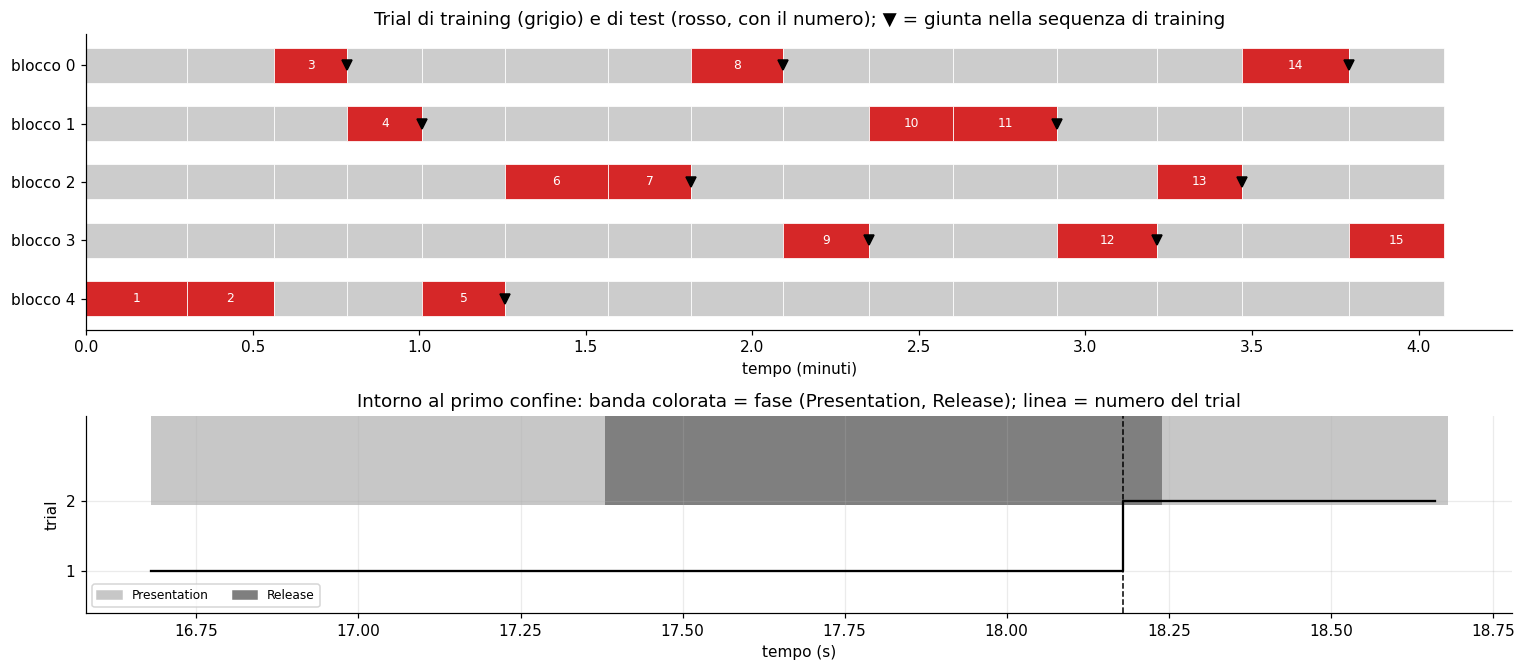

In [9]:
fig = plt.figure(figsize=(14, 6.2))
gs = fig.add_gridspec(2, 1, height_ratios=(1.5, 1))
ax = fig.add_subplot(gs[0])                                 # in alto: i 5 blocchi, trial per trial
t_min = np.arange(n_bins) * io.BIN_S / 60                   # tempo di ogni bin, in minuti
for k, tt in enumerate(TEST_TRIALS):
    for t_ in np.unique(trial):                             # un rettangolo per trial: grigio = training, rosso = test
        m = trial == t_
        ax.barh(k, t_min[m][-1] - t_min[m][0] + io.BIN_S / 60, left=t_min[m][0], height=0.6,
                color="C3" if t_ in tt else "0.8", edgecolor="white", lw=0.5)
        if t_ in tt:
            ax.text(t_min[m].mean(), k, str(t_), ha="center", va="center", fontsize=8, color="white")
    tb = TRAIN_BINS[k]
    for sp in np.flatnonzero(np.diff(tb) > 1) + 1:          # le giunte: dove la sequenza di training salta un trial di test
        ax.plot(t_min[tb[sp]], k, marker="v", color="k", ms=7)
ax.set(yticks=range(5), yticklabels=[f"blocco {k}" for k in range(5)], xlabel="tempo (minuti)",
       title="Trial di training (grigio) e di test (rosso, con il numero); ▼ = giunta nella sequenza di training")
ax.invert_yaxis(); ax.grid(False)

ax2 = fig.add_subplot(gs[1])                                # in basso: ingrandimento intorno al primo confine
a0 = starts[0]
win_b = np.arange(a0 - 75, a0 + 25)                         # 1.5 s prima e 0.5 s dopo il confine
for b_ in win_b:
    ax2.axvspan(b_ * io.BIN_S, (b_ + 1) * io.BIN_S, ymin=0.55, ymax=1, color=io.PHASE_COLORS.get(phase[b_], "white"), lw=0)
ax2.step(win_b * io.BIN_S, trial[win_b], where="post", color="k", lw=1.5)  # il numero del trial
ax2.axvline(a0 * io.BIN_S, color="k", ls="--", lw=1)
ax2.set(ylim=(trial[a0] - 1.6, trial[a0] + 1.2), yticks=[trial[a0] - 1, trial[a0]], xlabel="tempo (s)", ylabel="trial",
        title=f"Intorno al primo confine: banda colorata = fase ({', '.join(sorted(set(phase[win_b]) - {''}))}); linea = numero del trial")
handles = [plt.Rectangle((0, 0), 1, 1, color=io.PHASE_COLORS[p]) for p in sorted(set(phase[win_b]) - {""})]
ax2.legend(handles, sorted(set(phase[win_b]) - {""}), loc="lower left", fontsize=8, ncol=3)
fig.tight_layout(); fig.savefig(FIGS / "04_folds.png", bbox_inches="tight"); plt.show()

**Lettura.**

- Il confine tra due trial cade **sempre** dentro `Release`, da 1 a 4 bin (20-80 ms) prima della
  sua fine: nel file, ogni trial comincia con la coda del `Release` precedente (figura in basso).
- **6 punti su 1106** appartengono a un `Release` cominciato nel trial precedente. Se uno dei due
  trial è nel test e l'altro nel training, quella ripetizione di `Release` è divisa tra training e
  test. **27 punti** (tutti di `Release`) sono abbastanza vicini a un confine perché lo smoothing
  mescoli i conteggi dei due trial.
- È poco (al massimo il 2.4% dei punti) e valeva identico nel 03, che usava gli stessi blocchi:
  non cambia il confronto. Lo lasciamo così per non cambiare il metro comune. Una correzione
  possibile sarebbe spostare il confine alla fine di `Release`; non l'abbiamo fatta.
- Per CEBRA non si aggiunge niente: i trial di test si proiettano da soli, quindi la finestra della
  rete non li collega mai ai trial di training.

## 2 · L'idea di CEBRA su un esempio sintetico

### Che cosa fa CEBRA

CEBRA (Schneider, Lee & Mathis 2023) è fatto di due pezzi:

1. **Una rete** (l'*encoder*) che legge una breve **finestra di tempo** intorno a ogni istante,
   qui 10 bin (200 ms: 100 ms prima e 100 ms dopo), e restituisce un punto in poche dimensioni.
   Con la distanza **coseno**, la scelta standard, il punto viene "normalizzato": sta sempre su
   una **sfera** di raggio 1. Una sfera in 3 dimensioni ha solo 2 coordinate libere, come un
   mappamondo (latitudine e longitudine).
2. **Un gioco** con cui la rete si allena. A ogni passo si prendono:
   - un istante di **riferimento**;
   - un istante **positivo**, che "va insieme" al riferimento: in CEBRA-Time è l'istante
     **Δ bin dopo** (qui Δ = 10, cioè 200 ms);
   - molti istanti **negativi**, presi a caso nella sessione.

   La rete vince se, nella mappa, il riferimento è **più vicino al positivo che ai negativi**. È
   come riconoscere un amico in una folla da una foto di 200 ms fa: si impara a guardare quello
   che resta uguale (il viso), non quello che cambia a ogni istante (l'espressione).

**Perché funziona su dati neurali rumorosi.** Il segnale cambia lentamente, quindi è quasi uguale
in t e in t + 200 ms; il rumore cambia a ogni bin, quindi non aiuta a riconoscere il positivo. Per
vincere la rete impara a tenere ciò che è lento e a scartare il resto (l'idea del *time-contrastive
learning*, Hyvärinen & Morioka 2016). **Attenzione**: "ciò che è lento" non è per forza il task.
Anche "in che punto del trial siamo" cambia lentamente: è la catena del tempo, che controlleremo al
§5.

### La funzione di costo: InfoNCE

Per un riferimento x, il suo positivo y⁺ e N negativi y₁…y_N, la **somiglianza** tra due punti
della mappa è il coseno dell'angolo tra loro, s ∈ [−1, 1], diviso per una **temperatura** τ.
CEBRA minimizza, in media sul gruppo (*batch*) di riferimenti:

$$L = -\frac{s(x, y^+)}{\tau} + \log \sum_{i=1}^{N} e^{\,s(x, y_i)/\tau}$$

- il primo termine premia la vicinanza al positivo (la libreria lo chiama *align*);
- il secondo punisce la vicinanza ai negativi e spinge i punti a **spargersi su tutta la sfera**
  (*uniform*; i due nomi vengono da Wang & Isola 2020).

È la funzione **InfoNCE** (van den Oord et al. 2018), con una differenza che verificheremo nel
codice della libreria: nella versione originale la somma del secondo termine comprende anche il
positivo, in CEBRA solo i negativi.

Due numeri utili, che ricaviamo dalla formula:

- se la mappa "collassa" (tutti i punti nello stesso posto), tutte le somiglianze sono uguali e
  L = log N: è il **livello del caso**. CEBRA riporta la **goodness of fit** in bit, cioè quanto si
  scende sotto questo livello: (log N − L) · log₂ e;
- con la distanza coseno e τ = 1 c'è anche un **minimo**: nel caso migliore s = 1 con il positivo e
  s = −1 con tutti i negativi, quindi L ≥ log N − 2, cioè al massimo 2/ln 2 ≈ 2.9 bit.

### Perché un esempio sintetico

Come il foglio arrotolato del 03 (§3): prima dei dati veri proviamo CEBRA su dati di cui
**conosciamo la risposta**.

### 2.1 · I dati sintetici: un punto che passeggia sul foglio arrotolato

- Un punto si muove **lentamente** su un foglio quadrato: due coordinate, u (la lunghezza del
  foglio) e v (la larghezza), tra 0 e 1. La velocità cambia direzione in modo graduale, e ai bordi
  il punto rimbalza.
- Il foglio è **arrotolato** nello spazio 3D, come nel 03.
- Lo leggiamo attraverso **30 "canali"**: ogni canale è una combinazione a caso delle 3 coordinate
  del rotolo più un **rumore** diverso a ogni bin, più forte del segnale (ampiezza doppia).
- 10 000 bin da 20 ms (200 s): più o meno la lunghezza del film di training dei dati veri (§1.4).
  CEBRA si allena sul primo 80% del tempo; l'ultimo 20% è il test.

In [10]:
from scipy.ndimage import gaussian_filter1d, uniform_filter1d  # smoothing gaussiano e media mobile lungo il tempo

T_SYN, N_CH, NOISE = 10_000, 30, 2.0                        # bin, canali, ampiezza del rumore (il segnale di ogni canale ha ampiezza circa 1)
rng_syn = np.random.default_rng(0)                          # seme fisso: stessi dati sintetici a ogni esecuzione
vel = gaussian_filter1d(rng_syn.normal(size=(T_SYN, 2)), sigma=25, axis=0)  # velocità che cambia direzione in modo graduale (su circa 0.5 s)
vel = vel / vel.std(0) * 0.004                              # passo tipico: 0.4% del foglio ogni 20 ms
free = 0.5 + np.cumsum(vel, axis=0)                         # il percorso che il punto farebbe su un foglio senza bordi, partendo dal centro
UV = 1 - np.abs((free % 2) - 1)                             # "piegato" in [0, 1]: è il percorso che rimbalza sui bordi (coordinate u, v)
t_roll = 1.5 * np.pi * (1 + 2 * UV[:, 0])                   # da u all'angolo del rotolo, come in make_swiss_roll (03, §3)
ROLL = np.c_[t_roll * np.cos(t_roll), 21 * UV[:, 1], t_roll * np.sin(t_roll)]  # il punto sul rotolo, in 3D
ROLL = (ROLL - ROLL.mean(0)) / ROLL.std(0)                  # ogni coordinate con varianza 1
W_syn = rng_syn.normal(size=(3, N_CH)) / np.sqrt(3)         # come ogni canale combina le 3 coordinate (a caso)
SIG = ROLL @ W_syn                                          # il segnale di ogni canale, senza rumore
X_raw = SIG + NOISE * rng_syn.normal(size=(T_SYN, N_CH))    # più un rumore indipendente a ogni bin e in ogni canale
MU_SYN, SD_SYN = X_raw.mean(0), X_raw.std(0)                # media e deviazione standard di ogni canale
X_syn = ((X_raw - MU_SYN) / SD_SYN).astype(np.float32)      # z-score; float32 è il formato che usano le reti
N_TR = int(0.8 * T_SYN)                                     # il primo 80% del tempo è il training, il resto il test
print(f"Dati sintetici: {T_SYN} bin × {N_CH} canali; training {N_TR} bin, test {T_SYN - N_TR} bin")
print(f"Rapporto segnale/rumore per canale (varianze): {SIG.var(0).mean() / NOISE ** 2:.2f}")
print(f"Il punto copre tutto il foglio anche nel test? u da {UV[N_TR:, 0].min():.2f} a {UV[N_TR:, 0].max():.2f}, "
      f"v da {UV[N_TR:, 1].min():.2f} a {UV[N_TR:, 1].max():.2f}")

Dati sintetici: 10000 bin × 30 canali; training 8000 bin, test 2000 bin
Rapporto segnale/rumore per canale (varianze): 0.26
Il punto copre tutto il foglio anche nel test? u da 0.00 a 1.00, v da 0.00 a 1.00


Il rumore ha circa 4 volte la varianza del segnale in ogni canale: un singolo bin è quasi tutto
rumore, come nei dati veri. Anche l'ultimo 20% del tempo, il test, passa per tutto il foglio:
l'R² del §2.4 non è falsato da un test che resta chiuso in un angolo.

### 2.2 · Il gioco delle coppie, su un esempio

A sinistra, un canale nel tempo: la curva nera è il segnale senza rumore, quella grigia quello che
vede CEBRA. A destra, il percorso sul foglio: un istante di riferimento, il suo positivo 200 ms
dopo e alcuni negativi presi a caso. Il positivo è vicino sul foglio, i negativi no: è questa la
differenza che la rete deve imparare a vedere attraverso il rumore.

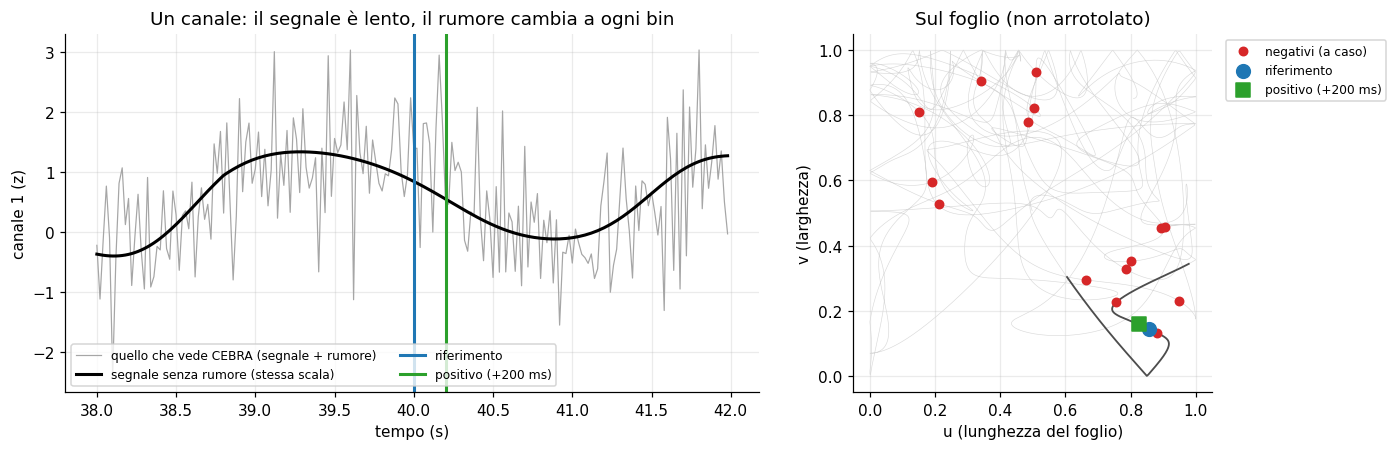

In [11]:
DELTA_SYN = 10                                              # il positivo di CEBRA-Time: 10 bin (200 ms) dopo il riferimento
rng_pair = np.random.default_rng(1)                         # seme fisso per l'esempio
ref0 = 2_000                                                # un istante di riferimento qualunque
negs0 = rng_pair.integers(0, N_TR - DELTA_SYN, 15)          # 15 negativi, presi a caso come fa CEBRA (in tutto il training)
t_ax = np.arange(T_SYN) * io.BIN_S                          # tempo di ogni bin, in s

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": (1.6, 1)})
w_ = slice(ref0 - 100, ref0 + 100)                          # 4 s intorno al riferimento
ax[0].plot(t_ax[w_], X_syn[w_, 0], color="0.65", lw=0.8, label="quello che vede CEBRA (segnale + rumore)")
ax[0].plot(t_ax[w_], (SIG[w_, 0] - MU_SYN[0]) / SD_SYN[0],  # il segnale senza rumore, con lo stesso z-score del canale
           color="k", lw=2, label="segnale senza rumore (stessa scala)")
ax[0].axvline(t_ax[ref0], color="C0", lw=2, label="riferimento")
ax[0].axvline(t_ax[ref0 + DELTA_SYN], color="C2", lw=2, label="positivo (+200 ms)")
ax[0].set(xlabel="tempo (s)", ylabel="canale 1 (z)", title="Un canale: il segnale è lento, il rumore cambia a ogni bin")
ax[0].legend(fontsize=8, loc="lower left", ncol=2)
ax[1].plot(UV[:N_TR, 0], UV[:N_TR, 1], color="0.85", lw=0.4)  # tutto il percorso di training sul foglio
ax[1].plot(UV[ref0 - 100:ref0 + 100, 0], UV[ref0 - 100:ref0 + 100, 1], color="0.3", lw=1.2)  # i 4 s del pannello di sinistra
ax[1].scatter(*UV[negs0].T, color="C3", s=30, zorder=3, label="negativi (a caso)")
ax[1].scatter(*UV[ref0], color="C0", s=80, zorder=4, label="riferimento")
ax[1].scatter(*UV[ref0 + DELTA_SYN], color="C2", s=80, marker="s", zorder=4, label="positivo (+200 ms)")
ax[1].set(xlabel="u (lunghezza del foglio)", ylabel="v (larghezza)", title="Sul foglio (non arrotolato)", aspect="equal")
ax[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout(); fig.savefig(FIGS / "04_contrastive_pairs.png", bbox_inches="tight"); plt.show()

### 2.3 · Come alleniamo CEBRA in questo notebook

Tre accorgimenti, uguali per tutti gli allenamenti del notebook:

- **Un processo separato.** Le reti di CEBRA usano la libreria `torch`, che porta con sé una sua
  copia di OpenMP, il sistema che divide i calcoli tra i core; scikit-learn ne ha un'altra. Due
  copie nello stesso processo possono bloccarlo, come era successo con UMAP nel 03. Per questo
  ogni allenamento gira in un **processo a parte** (`ProcessPoolExecutor`), e il notebook non
  importa mai `torch`. Il codice dell'allenamento resta scritto qui sotto: viene solo eseguito
  altrove. (Il processo separato contiene comunque tutte e due le copie, perché CEBRA importa a sua
  volta scikit-learn; ma lì lavora solo `torch`.)
- **Due allenamenti alla volta, sulla GPU del Mac** (MPS). Misurato prima di cominciare, su dati finti della stessa
  forma: circa 10 volte più veloce della CPU; due allenamenti insieme vanno ciascuno alla stessa velocità di uno solo.
- **Il seme fissato davvero.** CEBRA 0.6.0 ignora il seme che gli diamo: lo vediamo, e lo
  correggiamo, al §2.7.

**I parametri** sono quelli degli esempi ufficiali di CEBRA per i dati di ippocampo: rete
`offset10-model` (finestra di 10 bin), gruppi da 512 riferimenti, passo di apprendimento 3·10⁻⁴,
τ = 1, Δ = 10 bin, distanza coseno, mappa a 3 dimensioni. Al §3 li confrontiamo con quelli
riportati nell'articolo. Qui facciamo 5000 iterazioni.

In [12]:
from joblib.externals.loky import ProcessPoolExecutor      # un gruppo di processi separati, solo per CEBRA (diverso da quello usato da joblib per UMAP)

POOL = ProcessPoolExecutor(max_workers=2)                   # due allenamenti alla volta
CEBRA_STD = dict(model_architecture="offset10-model",       # rete convoluzionale con una finestra di 10 bin (5 prima, 5 dopo)
                 batch_size=512,                            # riferimenti per ogni passo (e altrettanti negativi)
                 learning_rate=3e-4,                        # quanto si correggono i pesi della rete a ogni passo
                 temperature=1.0,                           # τ della funzione di costo
                 time_offsets=10,                           # Δ: il positivo è 10 bin (200 ms) dopo il riferimento
                 distance="cosine",                         # somiglianza = coseno; i punti stanno su una sfera
                 output_dimension=3,                        # dimensioni della mappa
                 max_iterations=5000)                       # passi di allenamento (per i dati veri si decide al §3)

def cebra_fit(X_train, X_apply, cfg, seed, fix_seed=True, monitor=None, every=None, model_path=None):
    """Allena CEBRA-Time su X_train; restituisce la mappa di ogni array in X_apply, la funzione di costo
    a ogni passo e la durata. Gira in un processo separato (vedi sopra).
    Dal §3: monitor(passo, solver) viene chiamato ogni `every` passi; model_path = dove salvare il modello."""
    import time                                             # per misurare la durata
    import numpy as np                                      # array
    import torch                                            # la libreria delle reti neurali usata da CEBRA
    import cebra                                            # CEBRA
    import cebra.distributions.base as cdb                  # la classe che crea i generatori di numeri casuali di CEBRA (§2.7)
    torch.set_num_threads(1)                                # i calcoli pesanti sono sulla GPU: un solo thread di CPU, meno OpenMP in azione
    if not hasattr(cdb.HasGenerator, "orig_init"):          # la correzione del seme (§2.7), installata una volta per processo
        cdb.HasGenerator.orig_init = cdb.HasGenerator.__init__  # il metodo originale, che sceglie un seme a caso
        def seeded_init(self, device, seed):                # il metodo corretto
            cdb.HasGenerator.orig_init(self, device=device, seed=seed)  # fa tutto quello che faceva prima...
            if cdb.HasGenerator.fixed_seed is not None:     # ...poi, se abbiamo fissato un seme, sostituisce il generatore
                self._seed = cdb.HasGenerator.fixed_seed * 1000 + cdb.HasGenerator.counter  # un seme diverso per ogni generatore, ma sempre lo stesso
                cdb.HasGenerator.counter += 1               # il prossimo generatore avrà il seme successivo
                self._generator = torch.Generator(device=self.device).manual_seed(self._seed)
        cdb.HasGenerator.__init__ = seeded_init
    cdb.HasGenerator.fixed_seed = seed if fix_seed else None  # fix_seed=False: la libreria si comporta come in origine
    cdb.HasGenerator.counter = 0                            # i generatori di questo allenamento si numerano da 0
    torch.manual_seed(seed); np.random.seed(seed)           # semi dei pesi iniziali della rete e di numpy
    device = "mps" if torch.backends.mps.is_available() else "cpu"  # la GPU del Mac, se c'è
    model = cebra.CEBRA(**cfg, device=device, verbose=False)  # il modello con i parametri scelti
    t0 = time.time()
    if monitor is None:
        model.fit(X_train)                                  # l'allenamento: senza etichette, quindi CEBRA-Time
    else:
        model.fit(X_train, callback=monitor, callback_frequency=every)  # lo stesso, chiamando monitor(passo, solver) ogni `every` passi (§3)
        monitor(cfg["max_iterations"], model.solver_)       # e un'ultima volta alla fine
    seconds = time.time() - t0
    if model_path is not None:
        model.save(str(model_path))                         # il modello allenato, su disco (§3.1)
    out = {"maps": [model.transform(x) for x in X_apply],   # ogni sequenza proiettata da sola (bordi: si ripete il primo/ultimo bin)
           "loss": np.asarray(model.state_dict_["loss"]),   # la funzione di costo a ogni passo dell'allenamento
           "seconds": seconds, "device": device}
    if monitor is not None:
        out["monitor"] = monitor.history                    # le misure raccolte durante l'allenamento (§3)
    return out

def run_cebra(jobs, fn=None):                               # esegue una lista di allenamenti (dizionari di argomenti), due alla volta
    fn = cebra_fit if fn is None else fn                    # la funzione di allenamento (dal §6 anche quella con le etichette)
    futures = [POOL.submit(fn, **j) for j in jobs]          # li manda tutti in coda...
    return [f.result() for f in futures]                    # ...e aspetta i risultati, nello stesso ordine

### 2.4 · Che cosa impara CEBRA-Time sul foglio

Alleniamo CEBRA-Time sul primo 80% del tempo e proiettiamo a parte l'ultimo 20%. Poi chiediamo:
**dalla mappa si ricava la posizione sul foglio?** Per ogni punto di test un *regressore a 10
vicini* (come il classificatore del metro comune, ma per un numero) stima u e v dalla media dei 10
punti di training più vicini nella mappa. Misuriamo l'R², la frazione della variabilità di u e di v
spiegata (1 = perfetto, 0 = come dire sempre la media).

Termini di confronto:

- **PCA a 3 componenti** sui 30 canali, bin per bin;
- **PCA a 3 componenti dopo una media mobile di 200 ms**: la stessa finestra che legge CEBRA, ma
  senza nessun apprendimento. Separa quanto del risultato di CEBRA viene dal **semplice fatto di
  guardare 200 ms** (è l'idea del "tetto alla pari" del §4);
- **nessuna mappa**: il regressore direttamente sui 30 canali, con e senza media mobile.

E tre versioni di CEBRA, per vedere subito il problema della sfera:

- **coseno, 3 dimensioni** (standard): sfera, 2 coordinate libere;
- **coseno, 4 dimensioni**: sfera in 4D, 3 coordinate libere;
- **euclidea, 3 dimensioni**: nessuna sfera, 3 coordinate libere (rete `offset10-model-mse`, che
  non normalizza).

Tre allenamenti, due alla volta: circa 3 minuti.

In [13]:
from sklearn.neighbors import KNeighborsRegressor           # regressore a vicini: stima un numero dalla media dei vicini
from sklearn.metrics import r2_score                        # R²: frazione della variabilità spiegata

SYN_CFG = {                                                 # le tre versioni di CEBRA-Time (cambiano solo la distanza e le dimensioni)
    "CEBRA-Time, coseno, 3 dimensioni (sfera: 2 coordinate libere)": dict(CEBRA_STD),
    "CEBRA-Time, coseno, 4 dimensioni (sfera: 3 coordinate libere)": dict(CEBRA_STD, output_dimension=4),
    "CEBRA-Time, euclidea, 3 dimensioni (3 coordinate libere)": dict(CEBRA_STD, distance="euclidean",
                                                                    model_architecture="offset10-model-mse"),
}
std_name = next(iter(SYN_CFG))                              # la versione standard (coseno, 3 dimensioni)
res_syn = dict(zip(SYN_CFG, run_cebra([dict(X_train=X_syn[:N_TR], X_apply=[X_syn[:N_TR], X_syn[N_TR:]], cfg=c, seed=0)
                                       for c in SYN_CFG.values()])))  # training e test proiettati separatamente

def r2_uv(E_tr, E_te):                                      # R² di u e v stimati con 10 vicini nella mappa (training -> test)
    pred = KNeighborsRegressor(n_neighbors=10).fit(E_tr, UV[:N_TR]).predict(E_te)
    return {"R² di u (lunghezza)": r2_score(UV[N_TR:, 0], pred[:, 0]), "R² di v (larghezza)": r2_score(UV[N_TR:, 1], pred[:, 1])}

Xs_tr = uniform_filter1d(X_syn[:N_TR], size=10, axis=0, mode="nearest")  # media mobile di 10 bin (200 ms), training...
Xs_te = uniform_filter1d(X_syn[N_TR:], size=10, axis=0, mode="nearest")  # ...e test, separatamente (nessun bin di test entra nel training)
pca_syn, pca_syn_ma = PCA(3).fit(X_syn[:N_TR]), PCA(3).fit(Xs_tr)  # le due PCA, stimate sul training
MAPS_SYN = {                                                # tutte le mappe: (training, test)
    "PCA, 3 componenti (un bin)": (pca_syn.transform(X_syn[:N_TR]), pca_syn.transform(X_syn[N_TR:])),
    "PCA, 3 componenti dopo una media mobile di 200 ms": (pca_syn_ma.transform(Xs_tr), pca_syn_ma.transform(Xs_te)),
    **{name: tuple(r["maps"]) for name, r in res_syn.items()},
    "nessuna mappa: 30 canali (un bin)": (X_syn[:N_TR], X_syn[N_TR:]),
    "nessuna mappa: 30 canali dopo la media mobile": (Xs_tr, Xs_te),
}
tab_syn = pd.DataFrame({name: r2_uv(*E) for name, E in MAPS_SYN.items()}).T
display(tab_syn.round(2))
print("Durata dei tre allenamenti (s, nell'ordine della tabella):", [round(r["seconds"]) for r in res_syn.values()],
      "| dispositivo:", res_syn[std_name]["device"])
radius = np.linalg.norm(res_syn[std_name]["maps"][0], axis=1)  # distanza di ogni punto dal centro, nella mappa standard
print(f"Distanza dal centro dei punti della mappa standard (coseno, 3 dimensioni): da {radius.min():.4f} a {radius.max():.4f}")

,R² di u (lunghezza),R² di v (larghezza)
"PCA, 3 componenti (un bin)",0.18,0.45
"PCA, 3 componenti dopo una media mobile di 200 ms",0.93,0.91
"CEBRA-Time, coseno, 3 dimensioni (sfera: 2 coordinate libere)",-0.21,0.77
"CEBRA-Time, coseno, 4 dimensioni (sfera: 3 coordinate libere)",0.58,0.80
"CEBRA-Time, euclidea, 3 dimensioni (3 coordinate libere)",0.61,0.79
nessuna mappa: 30 canali (un bin),0.08,0.36
nessuna mappa: 30 canali dopo la media mobile,0.89,0.86


Durata dei tre allenamenti (s, nell'ordine della tabella): [53, 53, 62] | dispositivo: mps
Distanza dal centro dei punti della mappa standard (coseno, 3 dimensioni): da 1.0000 a 1.0000


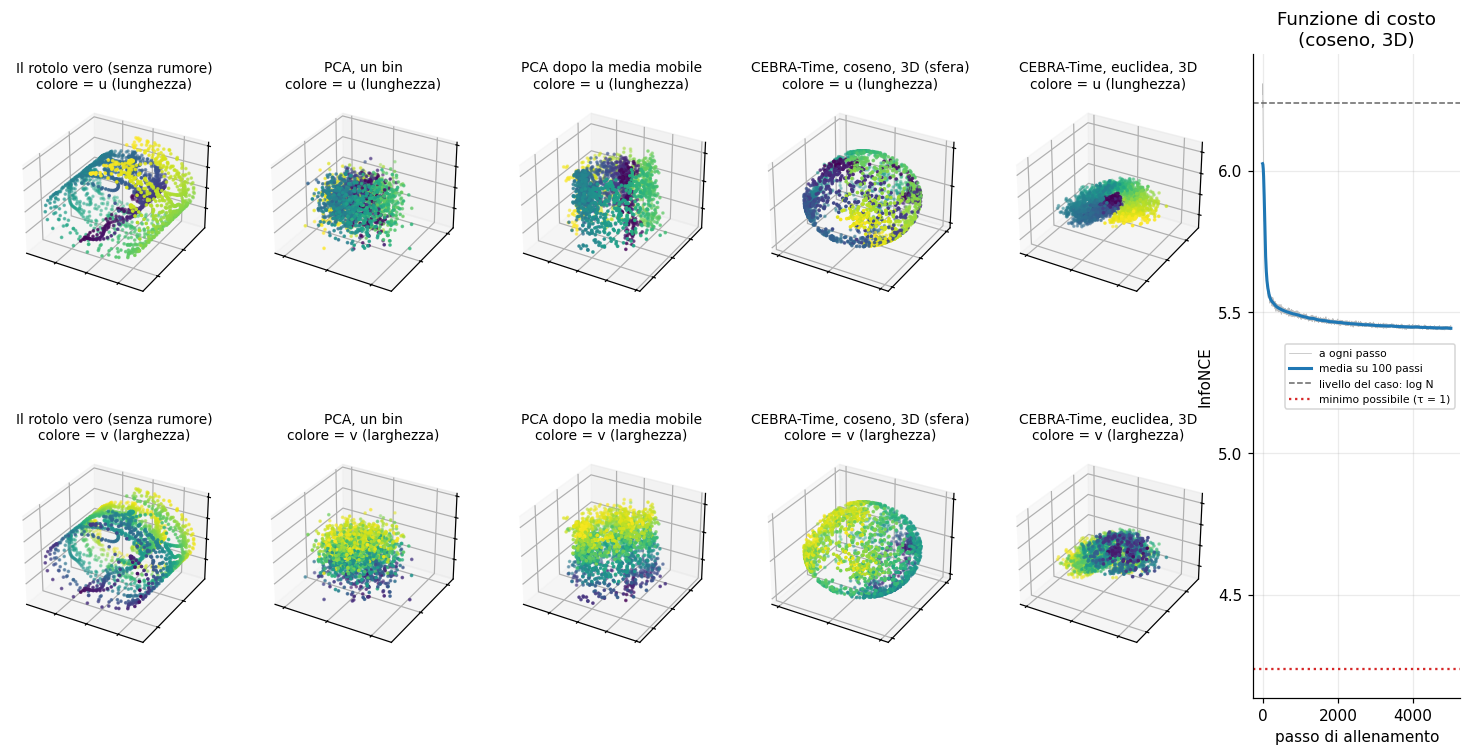

Funzione di costo (coseno, 3D), media su 500 passi: {'passi 1-500': 5.6, 'passi 1001-1500': 5.479, 'passi 2001-2500': 5.46, 'passi 3001-3500': 5.451, 'passi 4501-5000': 5.444}


In [14]:
fig = plt.figure(figsize=(17, 7.6))
panels = [("Il rotolo vero (senza rumore)", ROLL[:N_TR]),
          ("PCA, un bin", MAPS_SYN["PCA, 3 componenti (un bin)"][0]),
          ("PCA dopo la media mobile", MAPS_SYN["PCA, 3 componenti dopo una media mobile di 200 ms"][0]),
          ("CEBRA-Time, coseno, 3D (sfera)", res_syn[std_name]["maps"][0]),
          ("CEBRA-Time, euclidea, 3D", res_syn[list(SYN_CFG)[2]]["maps"][0])]
for row, (j, lab) in enumerate([(0, "u (lunghezza)"), (1, "v (larghezza)")]):
    for k, (ttl, E) in enumerate(panels):
        a_ = fig.add_subplot(2, 6, row * 6 + k + 1, projection="3d")
        a_.scatter(*E[::4, :3].T, c=UV[:N_TR:4, j], cmap="viridis", s=2)  # un punto ogni 4, colorato con la posizione sul foglio
        a_.set_title(f"{ttl}\ncolore = {lab}", fontsize=9)
        a_.set_xticklabels([]); a_.set_yticklabels([]); a_.set_zticklabels([])
a_ = fig.add_subplot(1, 6, 6)                               # a destra: la funzione di costo durante l'allenamento (versione standard)
loss_std = res_syn[std_name]["loss"]
a_.plot(np.arange(1, len(loss_std) + 1), loss_std, color="0.75", lw=0.5, label="a ogni passo")
a_.plot(np.arange(1, len(loss_std) + 1), uniform_filter1d(loss_std, 100), color="C0", lw=2, label="media su 100 passi")
a_.axhline(np.log(512), color="0.4", ls="--", lw=1, label="livello del caso: log N")
a_.axhline(np.log(512) - 2, color="C3", ls=":", lw=1.5, label="minimo possibile (τ = 1)")
a_.set(xlabel="passo di allenamento", ylabel="InfoNCE", title="Funzione di costo\n(coseno, 3D)")
a_.legend(fontsize=7, loc="center right")
fig.tight_layout(); fig.savefig(FIGS / "04_synthetic_maps.png", bbox_inches="tight"); plt.show()
print("Funzione di costo (coseno, 3D), media su 500 passi:",
      {f"passi {a + 1}-{a + 500}": round(float(loss_std[a:a + 500].mean()), 3) for a in (0, 1000, 2000, 3000, 4500)})

**Lettura.**

- **Bin per bin, il rumore vince**: la PCA ricava poco della posizione (R² 0.18 per u, 0.45 per v),
  e il regressore sui 30 canali ancora meno.
- **La media mobile di 200 ms basta a ripulire i dati**: la PCA dopo la media arriva a 0.93 e 0.91,
  il risultato migliore di tutti. Non è un caso: abbiamo costruito noi questi dati come un segnale
  lento mescolato **linearmente** più un rumore **indipendente a ogni bin**, e per dati così
  "media nel tempo + PCA" è la ricetta ideale. CEBRA qui non la batte. È un avvertimento per i dati
  veri: il confronto giusto per CEBRA è con **la stessa finestra di tempo senza apprendimento** (il
  "tetto alla pari" del §4), non con la PCA bin per bin.
- **La sfera conta.** Con la distanza coseno e 3 dimensioni (la versione standard) v si ricava bene
  (0.77), u per niente (−0.21, peggio che dire sempre la media). Nella figura, colorata con u, gli
  estremi del rotolo (viola e giallo) finiscono uno accanto all'altro sulla sfera. La spiegazione
  più probabile: il termine *uniform* spinge i punti a coprire **tutta** la sfera, e un foglio che
  copre una palla deve chiudersi su sé stesso, come la carta intorno a un pallone, e i bordi si
  toccano. La figura lo suggerisce, ma non l'abbiamo misurato direttamente. Con **3 coordinate
  libere** (coseno a 4 dimensioni, oppure distanza euclidea a 3) u torna leggibile: 0.58 e 0.61.
- Da qui la **regola per il §4**: confrontare CEBRA con gli altri metodi a parità di coordinate
  libere (CEBRA coseno a 3 dimensioni con d = 2, a 4 dimensioni con d = 3) e sempre con la stessa
  finestra senza apprendimento.
- **La funzione di costo** (a destra) scende in fretta nei primi 200 passi, poi molto lentamente:
  tra i passi 2001-2500 e 4501-5000 cala ancora di 0.016 (da 5.460 a 5.444). Resta lontana dal minimo possibile:
  lo spieghiamo al §2.5.

### 2.5 · La funzione di costo calcolata a mano

Prendiamo la mappa standard (coseno, 3 dimensioni) dei punti di training e rifacciamo **un passo
del gioco** come lo fa CEBRA-Time: 512 riferimenti a caso, ciascuno con il suo positivo 10 bin
dopo, e 512 negativi a caso, gli stessi per tutti i riferimenti (così fa la libreria). Calcoliamo
InfoNCE in tre modi: a mano con la formula di CEBRA, a mano con la formula originale (positivo
anche nella somma), e con la funzione della libreria (`FixedCosineInfoNCE`, eseguita nel processo
separato perché richiede `torch`).

In [15]:
E_syn = res_syn[std_name]["maps"][0]                        # la mappa standard dei punti di training (8000 × 3), sulla sfera
N_B, TAU = 512, 1.0                                         # riferimenti per gruppo e temperatura, come nell'allenamento
rng_b = np.random.default_rng(2)                            # seme fisso per il gruppo
ref = rng_b.integers(0, N_TR - DELTA_SYN, N_B)              # riferimenti: istanti a caso (CEBRA li prende uniformi in [0, T − Δ))
neg = rng_b.integers(0, N_TR - DELTA_SYN, N_B)              # negativi: altri istanti a caso, dalla stessa distribuzione
pos = ref + DELTA_SYN                                       # positivi: 10 bin dopo ogni riferimento

def logsumexp(a, axis=1):                                   # log Σ exp(a), calcolato senza superare i limiti dei numeri (si toglie il massimo)
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

s_pos = (E_syn[ref] * E_syn[pos]).sum(1) / TAU              # somiglianza (coseno) di ogni riferimento con il suo positivo, divisa per τ
s_neg = E_syn[ref] @ E_syn[neg].T / TAU                     # somiglianza di ogni riferimento con ciascuno dei 512 negativi (512 × 512)
L_cebra = np.mean(-s_pos + logsumexp(s_neg))                # InfoNCE come in CEBRA: nella somma solo i negativi
L_orig = np.mean(-s_pos + logsumexp(np.c_[s_pos, s_neg]))   # InfoNCE originale: nella somma anche il positivo

def infonce_library(ref_e, pos_e, neg_e, tau):              # la funzione della libreria (gira nel processo separato)
    import torch, cebra
    crit = cebra.models.criterions.FixedCosineInfoNCE(temperature=tau)
    loss, align, uniform = crit(torch.from_numpy(ref_e), torch.from_numpy(pos_e), torch.from_numpy(neg_e))
    return float(loss), float(align), float(uniform)

L_lib, align_lib, unif_lib = POOL.submit(infonce_library, E_syn[ref], E_syn[pos], E_syn[neg], TAU).result()

def bits(L, n=N_B):                                         # goodness of fit: quanto si scende sotto il livello del caso, in bit
    return (np.log(n) - L) * np.log2(np.e)

display(pd.DataFrame({"InfoNCE": {"a mano, formula di CEBRA": L_cebra, "libreria (FixedCosineInfoNCE)": L_lib,
                                  "a mano, formula originale (positivo nella somma)": L_orig,
                                  "allenamento: media degli ultimi 500 passi": loss_std[-500:].mean(),
                                  "livello del caso (mappa collassata): log 512": np.log(N_B),
                                  "minimo possibile con τ = 1: log 512 − 2": np.log(N_B) - 2}}).assign(
    **{"goodness of fit (bit)": lambda d: bits(d["InfoNCE"])}).round(4))
print(f"Differenza a mano − libreria: {L_cebra - L_lib:.2e}")
print(f"I due termini della libreria: align = {align_lib:.4f} (a mano {np.mean(-s_pos):.4f}), "
      f"uniform = {unif_lib:.4f} (a mano {np.mean(logsumexp(s_neg)):.4f})")

,InfoNCE,goodness of fit (bit)
"a mano, formula di CEBRA",5.4448,1.1448
libreria (FixedCosineInfoNCE),5.4448,1.1447
"a mano, formula originale (positivo nella somma)",5.4492,1.1385
allenamento: media degli ultimi 500 passi,5.4437,1.1464
livello del caso (mappa collassata): log 512,6.2383,0.0000
minimo possibile con τ = 1: log 512 − 2,4.2383,2.8854


Differenza a mano − libreria: -4.77e-07
I due termini della libreria: align = -0.9597 (a mano -0.9597), uniform = 6.4046 (a mano 6.4046)


**Lettura.**

- **Il calcolo a mano coincide con la libreria**: 5.4448 in entrambi i casi, differenza 5·10⁻⁷
  (l'arrotondamento dei numeri a 32 bit). Coincidono anche i due termini: *align* = −0.96, cioè il
  coseno medio tra riferimento e positivo è 0.96 (sono quasi nello stesso punto della sfera), e
  *uniform* = 6.40.
- **La formula originale**, con il positivo nella somma, dà 5.4492: con 512 negativi aggiungere un
  termine cambia pochissimo (+0.004). La differenza tra le due versioni è quindi un dettaglio.
- Un solo gruppo da 512 basta a rappresentare l'allenamento: 5.4448 contro 5.4437 della media degli
  ultimi 500 passi.
- **Goodness of fit: 1.14 bit, su un massimo di 2.89.** Perché così lontana dal massimo, se il
  positivo è quasi sovrapposto al riferimento? Perché il massimo richiederebbe tutti i negativi
  **dalla parte opposta** della sfera. Ma i negativi sono istanti presi a caso, e la mappa copre
  tutta la sfera: una parte dei negativi cade sempre vicino al riferimento. Il massimo è
  irraggiungibile per costruzione, e la goodness of fit va letta come confronto tra mappe allenate
  nello stesso modo, non come un voto assoluto.

### 2.6 · La temperatura

La temperatura τ decide **quanto è severo il giudice** del gioco. Con le somiglianze di un gruppo
si può calcolare con quale probabilità il giudice "sceglie" il positivo tra i 513 candidati
(positivo + 512 negativi): exp(s⁺/τ) / [exp(s⁺/τ) + Σ exp(sᵢ/τ)].

- **τ piccola**: piccole differenze di somiglianza diventano enormi differenze di probabilità. Il
  giudice guarda quasi solo i negativi **più somiglianti** al riferimento (gli impostori più
  bravi);
- **τ grande**: tutte le somiglianze si appiattiscono, e tutti i candidati pesano quasi uguale.

Sulla stessa mappa (allenata con τ = 1) cambiamo solo τ nel calcolo, e guardiamo due cose: la
probabilità di scegliere il positivo e quanta parte del "peso" dei negativi va ai 10 più
somiglianti su 512. **Non** stiamo allenando con τ diverse: questo mostra come τ giudica, non che
mappa produrrebbe. L'effetto sull'allenamento lo misuriamo sui dati veri al §7.

In [16]:
TAUS = np.array([0.05, 0.1, 0.2, 0.5, 1, 2, 5])            # temperature provate
rows_t = []
for tau in TAUS:
    sp, sn = s_pos * TAU / tau, s_neg * TAU / tau           # le stesse somiglianze, divise per la nuova τ
    p_pos = np.exp(sp - logsumexp(np.c_[sp, sn]))           # probabilità che il giudice scelga il positivo
    w_neg = np.exp(sn - logsumexp(sn)[:, None])             # peso di ogni negativo (per ogni riferimento i pesi sommano a 1)
    top10 = np.sort(w_neg, axis=1)[:, -10:].sum(1)          # peso dei 10 negativi più somiglianti
    rows_t.append({"τ": tau, "probabilità di scegliere il positivo": p_pos.mean(),
                   "peso dei 10 negativi più somiglianti (su 512)": top10.mean(),
                   "goodness of fit massima possibile (bit)": 2 / tau * np.log2(np.e)})
tab_tau = pd.DataFrame(rows_t).set_index("τ")
display(tab_tau.round(3))
print(f"A caso: probabilità 1/513 = {1 / 513:.4f}; peso dei 10 negativi se tutti uguali: 10/512 = {10 / 512:.3f}")

,probabilità di scegliere il positivo,peso dei 10 negativi più somiglianti (su 512),goodness of fit massima possibile (bit)
τ,,,
0.05,0.035,0.459,57.708
0.10,0.024,0.286,28.854
0.20,0.015,0.166,14.427
0.50,0.007,0.076,5.771
1.00,0.004,0.044,2.885
2.00,0.003,0.031,1.443
5.00,0.002,0.024,0.577


A caso: probabilità 1/513 = 0.0019; peso dei 10 negativi se tutti uguali: 10/512 = 0.020


**Lettura.**

- **Con τ = 1 il giudice è poco sicuro**: sceglie il positivo con probabilità 0.4%, appena il doppio
  del caso (0.19%). Con la distanza coseno le somiglianze vanno da −1 a 1, quindi con τ = 1 gli
  esponenziali vanno solo da e⁻¹ a e¹: nessun candidato può pesare molto più degli altri. È lo
  stesso motivo per cui la goodness of fit non può superare 2.9 bit.
- **Abbassando τ il giudice diventa severo**: con τ = 0.05 la probabilità sale al 3.5%, e i 10
  negativi più somiglianti (su 512) prendono il 46% del peso, contro il 4% con τ = 1 e il 2% se
  pesassero tutti uguale.
- **Che cosa vuol dire per l'allenamento**: con τ piccola la rete lavora soprattutto per separare il
  riferimento dagli impostori più vicini (il dettaglio locale); con τ grande tratta tutti i
  negativi allo stesso modo (la disposizione d'insieme). Quale sia meglio per i nostri dati non si
  può dire a priori: è tra le prove del §7.
- **La scala della goodness of fit dipende da τ** (massimo 2/τ · log₂ e): mappe allenate con τ
  diverse non si confrontano con questo numero.

### 2.7 · Il seme: un problema della libreria e la correzione

CEBRA dipende dal caso: i pesi iniziali della rete e i riferimenti, positivi e negativi pescati a
ogni passo. Per poter ripetere un risultato si fissa il **seme** dei numeri casuali. Ma in CEBRA
0.6.0 la classe che pesca gli istanti (`HasGenerator`) si crea un generatore **con un seme scelto a
caso dal sistema** e ignora quello che le diamo. È come chiedere a un amico di mescolare un mazzo
"sempre nello stesso modo" e scoprire che ogni volta prende un mazzo nuovo.

La correzione (in `cebra_fit`, §2.3) sostituisce il generatore con uno che parte da un seme noto.
Ogni generatore riceve un seme **diverso** (seme × 1000 + un contatore): se due generatori
partissero dallo stesso seme pescherebbero gli stessi numeri, e per esempio riferimenti e positivi
non sarebbero indipendenti.

Il controllo: due allenamenti con lo stesso seme senza la correzione, e due con la correzione
(500 passi ciascuno, versione standard).

In [17]:
res_seed = run_cebra([dict(X_train=X_syn[:N_TR], X_apply=[X_syn[:N_TR]], cfg=dict(CEBRA_STD, max_iterations=500),
                           seed=0, fix_seed=fix) for fix in (False, False, True, True)])  # stesso seme (0) per tutti e quattro
diff_off = np.abs(res_seed[0]["maps"][0] - res_seed[1]["maps"][0]).max()  # massima differenza tra le due mappe senza correzione
diff_on = np.abs(res_seed[2]["maps"][0] - res_seed[3]["maps"][0]).max()   # ...e con la correzione
print(f"Stesso seme, senza correzione: differenza massima tra le due mappe {diff_off:.3f} "
      f"(funzione di costo finale {res_seed[0]['loss'][-1]:.4f} e {res_seed[1]['loss'][-1]:.4f})")
print(f"Stesso seme, con la correzione:  differenza massima tra le due mappe {diff_on:.3f} "
      f"(funzione di costo finale {res_seed[2]['loss'][-1]:.4f} e {res_seed[3]['loss'][-1]:.4f})")
print("Con la correzione le due mappe sono identiche bit per bit:", np.array_equal(res_seed[2]["maps"][0], res_seed[3]["maps"][0]),
      "| e anche tutta la funzione di costo:", np.array_equal(res_seed[2]["loss"], res_seed[3]["loss"]))

Stesso seme, senza correzione: differenza massima tra le due mappe 0.264 (funzione di costo finale 5.5000 e 5.5102)
Stesso seme, con la correzione:  differenza massima tra le due mappe 0.000 (funzione di costo finale 5.5070 e 5.5070)
Con la correzione le due mappe sono identiche bit per bit: True | e anche tutta la funzione di costo: True


**Lettura.**

- **Senza la correzione, lo stesso seme dà mappe diverse**: un punto si sposta di qualche decimo,
  su una sfera di raggio 1, e anche la funzione di costo finale è diversa. I numeri esatti cambiano
  a ogni esecuzione del notebook (nelle esecuzioni fatte finora la differenza massima è andata da
  0.13 a 0.74), ed è proprio il problema.
- **Con la correzione i due allenamenti sono identici**, bit per bit: stessa mappa e stessa funzione
  di costo a ogni passo.
- **Verificato anche sul notebook intero**: eseguendolo due volte di seguito, tutti i risultati di
  CEBRA ottenuti con la correzione (R² del §2.4, funzione di costo, InfoNCE del §2.5) sono
  identici; cambia solo l'esempio senza correzione qui sopra.
- Da qui **tutti gli allenamenti usano la correzione**. Un risultato si può quindi rifare identico
  su questo computer con queste versioni (cebra 0.6.0, torch 2.7.1, GPU del Mac). Su un'altra
  macchina o con altre versioni non è garantito: per questo, dal §3, i modelli allenati si salvano
  su disco.
- La correzione **non** toglie la dipendenza dal caso: con semi diversi le mappe restano diverse.
  Quanto contino lo misuriamo con 5 semi.

## 3 · CEBRA-Time sui dati veri: un primo allenamento

Un allenamento principale, più alcuni controlli, per rispondere a due domande prima di misurare
qualunque cosa:

1. **Quante iterazioni servono?** Lo decidiamo con dei trial di **validazione**, mai con quelli di
   test (§3.2).
2. **Che aspetto ha la mappa?** (§3.3)

### I parametri, e da dove vengono

Li abbiamo controllati nell'articolo (Schneider, Lee & Mathis 2023, testo completo su PubMed
Central, PMC10172131):

| parametro | valore qui | che cosa dice l'articolo |
|---|---|---|
| rete | `offset10-model`: finestra di 10 bin (200 ms), **centrata** (100 ms prima e 100 dopo) | Methods, *CEBRA model parameters used*: `offset10-model` per i dati neurali di ippocampo di ratto, S1 di primate e Allen (2 fotoni) |
| Δ (`time_offsets`) | 10 bin (200 ms) | stessa sezione: `time_offsets=10` per gli stessi dati (lì con bin da 25 ms nell'ippocampo, quindi 250 ms) |
| gruppo (`batch_size`) | 512 | stessa sezione: `batch_size=512` |
| temperatura τ | 1 | Extended Data Fig. 3 (ippocampo): τ = 1 per CEBRA-Behaviour, **τ = 2.25 per CEBRA-Time**. Teniamo 1, il valore predefinito della libreria, per usare la stessa τ anche con CEBRA-Behavior al §6; 2.25 è tra le prove del §7 |
| passo di apprendimento | 3·10⁻⁴ | valore predefinito della libreria; nelle parti dell'articolo che abbiamo letto non è riportato per questi dati |
| iterazioni | **da decidere qui** | Extended Data Fig. 3 (ippocampo): 10 000 per CEBRA-Behaviour, 4000 per CEBRA-Time. Nei Methods il numero di passi è l'unico parametro **non** scelto con la validazione |
| dimensioni | 3 | Extended Data Fig. 3: *"latent dimension three (the minimum)"* |
| distanza | coseno | Methods: prodotto scalare tra vettori normalizzati |
| ottimizzatore | Adam | valore predefinito della libreria; l'articolo non lo nomina nelle parti lette |

**La finestra centrata usa 100 ms di futuro.** Per analizzare i dati va bene; un'interfaccia
cervello-computer in tempo reale non potrebbe farlo.

### 3.1 · Salvare i modelli su disco

Dal §4 servono molti allenamenti (5 blocchi × 5 semi per ogni configurazione). Ogni modello
allenato si salva su disco, e la volta successiva si rilegge invece di riallenarlo, come un piatto
già cucinato messo in freezer:

- il **nome del file** è un'impronta (*hash*) di tutto ciò che determina il risultato: il codice di
  `cebra_fit`, i parametri, il seme, e i dati (training, sequenze da proiettare, trial di
  validazione). Se cambia anche un solo numero dei dati, cambia il nome, e il modello si riallena;
- si salvano il modello (`.pt`, per poterlo riusare) e i risultati (`.npz`: mappe, funzione di
  costo, misure di validazione, durata);
- la cartella è **fuori dal Desktop** (`~/tesi_h1_work/cache_04`): il Desktop è sincronizzato con
  iCloud, che può togliere i file dal disco;
- `RETRAIN = True` rifà tutti gli allenamenti da capo. Con la correzione del seme (§2.7) devono
  dare gli stessi risultati, almeno su questo computer e con queste versioni.

In [18]:
import hashlib, inspect, json                               # impronte dei dati, testo del codice, salvataggio delle misure

CACHE = Path.home() / "tesi_h1_work" / "cache_04"           # dove si salvano i modelli: fuori dal Desktop (iCloud)
CACHE.mkdir(parents=True, exist_ok=True)
RETRAIN = False                                             # True = rifà tutti gli allenamenti invece di rileggerli

def job_key(job, fn=None):                                  # impronta di un allenamento: cambia se cambia qualunque cosa che lo determina
    h = hashlib.sha1()
    for f in (cebra_fit, ValMonitor.__init__, ValMonitor.__call__, ValMonitor.infonce):
        h.update(inspect.getsource(f).encode())             # il codice dell'allenamento e delle misure
    if fn is not None and fn is not cebra_fit:
        h.update(inspect.getsource(fn).encode())            # dal §6: anche il codice della funzione con le etichette
    h.update(json.dumps({k: job.get(k) for k in ("cfg", "seed", "fix_seed", "every")},
                        sort_keys=True, default=str).encode())  # parametri, seme, frequenza delle misure
    arrays = [job["X_train"], *job["X_apply"]]              # i dati...
    if job.get("monitor") is not None:
        h.update(job["monitor"].key.encode())               # ...le impostazioni delle misure di validazione...
        arrays += [s_ for seqs in job["monitor"].sets.values() for s_ in seqs]  # ...e i loro trial
    if job.get("y_train") is not None:
        arrays.append(job["y_train"])                       # dal §6: le etichette...
    for name, (Xv, yv) in sorted((job.get("val") or {}).items()):
        h.update(name.encode()); arrays += [Xv, yv]         # ...e i trial di validazione con le loro etichette
    for a in arrays:
        h.update(np.ascontiguousarray(a).tobytes())         # ogni numero dei dati entra nell'impronta
    return h.hexdigest()[:16]

def run_cebra_cached(jobs, fn=None):                        # come run_cebra (§2.3), ma rilegge dal disco gli allenamenti già fatti
    keys = [job_key(j, fn) for j in jobs]
    todo = [i for i, k in enumerate(keys) if RETRAIN or not (CACHE / f"{k}.npz").exists()]  # quelli da fare davvero
    fresh = run_cebra([dict(jobs[i], model_path=CACHE / f"{keys[i]}.pt") for i in todo], fn)  # due alla volta, nel processo separato
    for i, r in zip(todo, fresh):                           # i risultati nuovi si salvano subito
        np.savez(CACHE / f"{keys[i]}.npz", loss=r["loss"], seconds=r["seconds"], device=r["device"],
                 monitor=json.dumps(r.get("monitor")), extra=json.dumps(r.get("extra")),
                 **{f"map_{j}": m for j, m in enumerate(r["maps"])})
    out = []
    for k in keys:                                          # tutti i risultati, nell'ordine dei lavori, letti dal disco
        z = np.load(CACHE / f"{k}.npz")
        out.append({"maps": [z[f"map_{j}"] for j in range(sum(n.startswith("map_") for n in z.files))],
                    "loss": z["loss"], "seconds": float(z["seconds"]), "device": str(z["device"]),
                    "monitor": json.loads(str(z["monitor"])), "key": k,
                    "extra": json.loads(str(z["extra"])) if "extra" in z.files else None})  # misure in più (dal §6)
    print(f"Allenamenti: {len(todo)} eseguiti ora, {len(jobs) - len(todo)} riletti dal disco")
    return out

### 3.2 · Quante iterazioni? La validazione

**Lo schema.** Usiamo il blocco 0 (trial di test 3, 8 e 14, che qui **non** vengono toccati). Dei
suoi 12 trial di training ne mettiamo da parte 2 per la **validazione**, 12 e 15: uno pari e uno
dispari, per le due versioni del task (03, §9.2). CEBRA si allena sugli altri 10.

**Anche la PCA iniziale non deve vedere i trial di validazione.** I 25 PC del blocco 0 (§1.3)
vengono da una PCA stimata sui bin di movimento di tutti i 12 trial di training del blocco, quindi
anche dei 2 di validazione. La PCA non usa etichette, ma "vede" i dati: è la scorciatoia del 03
(§7). Per la validazione stimiamo quindi una PCA sui soli 10 trial su cui si allena CEBRA. Quanto
conta? Misuriamo quanta varianza dei trial di validazione tengono le due PCA.

In [19]:
K0 = 0                                                      # il blocco usato in questa sezione
VAL_TRIALS, VAL_TRIALS_B, CHECK_TRIALS = (12, 15), (6, 7), (4, 5)  # due coppie di trial di validazione e una di training su cui si misura (uno pari e uno dispari)
TRIALS = np.unique(trial)                                   # i 15 trial
fit_trials = [t for t in TRIALS if t not in TEST_TRIALS[K0] and t not in VAL_TRIALS]      # i 10 trial su cui CEBRA si allena (validazione 12, 15)
fit_trials_b = [t for t in TRIALS if t not in TEST_TRIALS[K0] and t not in VAL_TRIALS_B]  # i 10 trial su cui CEBRA si allena (validazione 6, 7)

def pca_seqs(fit_tr):                                       # PCA a 25 stimata sui bin di movimento dei soli trial fit_tr
    p_ = PCA(K_PCA).fit(Z[bins_all[np.isin(trial[bins_all], fit_tr)]])
    X_ = p_.transform(Z)                                    # tutta la sessione sulle sue 25 direzioni
    return p_, X_, {t: X_[trial == t].astype(np.float32) for t in TRIALS}  # e ogni trial separato, nel formato delle reti

def var_kept(p_, Xv):                                       # frazione (%) della varianza di Xv che sta nelle 25 direzioni della PCA p_
    Xc = Xv - p_.mean_
    return ((Xc @ p_.components_.T) ** 2).sum() / (Xc ** 2).sum() * 100

PCA_A, XA, SEQ_A = pca_seqs(fit_trials)                     # la PCA per la validazione con i trial 12 e 15
PCA_B, XB, SEQ_B = pca_seqs(fit_trials_b)                   # la PCA per la validazione con i trial 6 e 7

def mov(trs):                                               # i bin di movimento di alcuni trial
    return Z[bins_all[np.isin(trial[bins_all], trs)]]

display(pd.DataFrame({str(vt): {"PCA del §1.3 (12 trial: li ha visti)": var_kept(PCA_F[K0], mov(vt)),
                                "PCA sui soli 10 trial di allenamento": var_kept(p_, mov(vt))}
                      for vt, p_ in ((VAL_TRIALS, PCA_A), (VAL_TRIALS_B, PCA_B))}).T.rename_axis("trial di validazione").round(1))
print(f"Per confronto: sui 10 trial su cui è stimata, la PCA tiene il {var_kept(PCA_A, mov(fit_trials)):.1f}% della varianza; "
      f"sui trial di test del blocco 0, la PCA del §1.3 ne tiene il {var_kept(PCA_F[K0], mov(TEST_TRIALS[K0])):.1f}%")

,PCA del §1.3 (12 trial: li ha visti),PCA sui soli 10 trial di allenamento
trial di validazione,,
"(12, 15)",41.7,29.1
"(6, 7)",40.1,28.7


Per confronto: sui 10 trial su cui è stimata, la PCA tiene il 40.7% della varianza; sui trial di test del blocco 0, la PCA del §1.3 ne tiene il 27.7%


**Lettura.** È una differenza grande, e l'abbiamo trovata per caso, controllando una prima
versione di questa sezione.

- La PCA a 25 tiene il **40-42%** della varianza dei trial di validazione se li ha visti, solo il
  **29%** se non li ha visti. Sui trial su cui è stimata ne tiene il 40.7%; sui trial di test del
  blocco 0, che non vede mai, il 27.7%. I trial di validazione "puliti" si comportano quindi come
  quelli di test, ed è quello che vogliamo.
- Circa **un terzo** (28-30%) di quello che le 25 direzioni catturano nei trial di training non si
  ritrova nei trial nuovi: una parte delle 25 direzioni descrive fluttuazioni specifiche dei trial
  su cui la PCA è stimata. Una spiegazione possibile: i dati smussati cambiano lentamente, quindi
  i circa 3700 bin di movimento valgono molti meno punti indipendenti, e 25 direzioni bastano ad
  adattarsi anche al rumore di quei trial. Non l'abbiamo verificato.
- Per la validazione usiamo quindi la **PCA stimata sui soli 10 trial** su cui si allena CEBRA.
  Nel metro comune (§1.2), come nel 03, la PCA non vede mai i trial di test: quei numeri sono
  puliti.

**Che cosa misuriamo durante l'allenamento.** Ogni 500 passi rifacciamo la misura del §2.5,
InfoNCE con la stessa formula della libreria, su gruppi di istanti fissati in anticipo (20 gruppi
da 512 riferimenti, con i loro positivi 10 bin dopo nello stesso trial e 512 negativi), in due
insiemi di trial proiettati uno alla volta:

- **2 trial di validazione** (12 e 15): CEBRA non li ha mai visti, e nemmeno la PCA;
- **2 trial di training** (4 e 5): stessa misura, ma su trial che CEBRA ha visto.

I due insiemi hanno la stessa forma (2 trial, uno pari e uno dispari), quindi i due numeri si
confrontano. Se la curva di training continua a scendere mentre quella di validazione risale, la
rete sta imparando a memoria i trial che vede (*overfitting*).

**La regola, fissata prima di guardare**: il numero di passi è il più piccolo, arrotondato per
eccesso alle migliaia, a cui la funzione di costo di validazione ha fatto **il 98% della sua
discesa** (dal valore iniziale al minimo). Alleniamo fino a 10 000 passi, il massimo usato
nell'articolo. Circa 2 minuti.

In [20]:
class ValMonitor:
    """Durante l'allenamento misura InfoNCE (come al §2.5) su gruppi di istanti fissati in anticipo, in
    alcuni insiemi di trial proiettati uno alla volta. Viene eseguito nel processo separato."""

    def __init__(self, sets, delta=10, tau=1.0, n_batches=20, batch=512, seed=0):
        rng_m = np.random.default_rng(seed)                 # seme fisso: gli stessi gruppi a ogni misura
        self.sets, self.delta, self.tau, self.history = sets, delta, tau, []
        self.idx = {}                                       # per ogni insieme: 20 coppie (riferimenti, negativi)
        for name, seqs in sets.items():
            lens = [len(s_) for s_ in seqs]                 # lunghezza di ogni trial
            starts = np.cumsum([0] + lens[:-1])             # dove comincia ogni trial, una volta messi in fila
            refs = np.concatenate([a + np.arange(n - delta) for a, n in zip(starts, lens)])  # riferimenti con il positivo nello stesso trial
            self.idx[name] = [(rng_m.choice(refs, batch), rng_m.integers(0, sum(lens), batch)) for _ in range(n_batches)]
        self.key = f"ValMonitor({ {k: [len(s_) for s_ in v] for k, v in sets.items()} }, {delta}, {tau}, {n_batches}, {batch}, {seed})"

    def __call__(self, num_steps, solver):                  # chiamato da CEBRA ogni `every` passi
        import torch                                        # (siamo nel processo separato)
        was_training = solver.model.training                # proiettare mette la rete in modalità "uso": dopo la rimettiamo com'era
        row = {"passo": int(num_steps)}
        for name, seqs in self.sets.items():
            E = np.concatenate([solver.transform(torch.from_numpy(s_)).cpu().numpy() for s_ in seqs])  # ogni trial proiettato da solo
            row[name] = float(np.mean([self.infonce(E[r], E[r + self.delta], E[n]) for r, n in self.idx[name]]))
        solver.model.train(was_training)
        self.history.append(row)

    def infonce(self, ref, pos, neg):                       # la formula del §2.5 (coseno: i punti sono già sulla sfera)
        s_pos = (ref * pos).sum(1) / self.tau
        s_neg = ref @ neg.T / self.tau
        m = s_neg.max(1, keepdims=True)                     # si toglie il massimo per non far "esplodere" gli esponenziali
        return float(np.mean(-s_pos + m[:, 0] + np.log(np.exp(s_neg - m).sum(1))))

def rule98(v):                                              # la regola: primo passo con il 98% della discesa, arrotondato alle migliaia
    reached = v.values <= v.min() + 0.02 * (v.iloc[0] - v.min())  # dove la curva ha già fatto il 98% della discesa fino al minimo
    return int(np.ceil(v.index[np.argmax(reached)] / 1000) * 1000)

STEPS_SHOW = [0, 500, 1000, 1500, 2000, 3000, 4000, 6000, 8000, 10_000]  # le righe mostrate nelle tabelle

monitor0 = ValMonitor({"2 trial di training (4, 5)": [SEQ_A[t] for t in CHECK_TRIALS],
                       "2 trial di validazione (12, 15)": [SEQ_A[t] for t in VAL_TRIALS]})
res3 = run_cebra_cached([dict(X_train=np.concatenate([SEQ_A[t] for t in fit_trials]),  # i 10 trial in fila: il film di training
                              X_apply=[SEQ_A[t] for t in TRIALS],                       # poi tutti i 15 trial, proiettati uno alla volta
                              cfg=dict(CEBRA_STD, max_iterations=10_000), seed=0,
                              monitor=monitor0, every=500)])[0]
hist3 = pd.DataFrame(res3["monitor"]).set_index("passo")    # le misure durante l'allenamento: una riga ogni 500 passi
print(f"Trial di training: {[int(t) for t in fit_trials]} ({sum(len(SEQ_A[t]) for t in fit_trials)} bin); "
      f"validazione: {VAL_TRIALS}; test (non usati): {TEST_TRIALS[K0].tolist()}")
print(f"Durata: {res3['seconds']:.0f} s per {len(res3['loss'])} passi ({res3['seconds'] / len(res3['loss']) * 1000:.1f} ms a passo, "
      f"misure comprese), dispositivo {res3['device']}")
v3 = hist3["2 trial di validazione (12, 15)"]               # la curva di validazione
N_ITER_A = rule98(v3)
display(hist3.loc[STEPS_SHOW].assign(
    **{"goodness of fit, validazione (bit)": lambda d: bits(d["2 trial di validazione (12, 15)"])}).round(3))
print(f"Minimo della validazione: {v3.min():.4f} al passo {v3.idxmin()}; regola del 98% -> {N_ITER_A} passi")

Allenamenti: 0 eseguiti ora, 1 riletti dal disco
Trial di training: [1, 2, 4, 5, 6, 7, 9, 10, 11, 13] (8018 bin); validazione: (12, 15); test (non usati): [3, 8, 14]
Durata: 109 s per 10000 passi (10.9 ms a passo, misure comprese), dispositivo mps


,"2 trial di training (4, 5)","2 trial di validazione (12, 15)","goodness of fit, validazione (bit)"
passo,,,
0,6.216,6.223,0.022
500,5.582,5.812,0.615
1000,5.515,5.802,0.629
1500,5.493,5.819,0.605
2000,5.491,5.818,0.607
3000,5.471,5.827,0.593
4000,5.462,5.844,0.569
6000,5.469,5.840,0.574
8000,5.463,5.845,0.568


Minimo della validazione: 5.8023 al passo 1000; regola del 98% -> 1000 passi


**Un secondo controllo, aggiunto dopo aver visto il primo risultato.** In una prima versione di
questa sezione (con la PCA del §1.3, che aveva visto i trial di validazione) la curva di
validazione toccava il minimo molto presto e poi risaliva, mentre quella dei trial di training
restava bassa: il segno dell'overfitting. Ma i trial 12 e 15 sono alla fine della sessione, e se i
segnali cambiano lentamente nel corso della sessione (per esempio perché gli elettrodi si spostano
un poco) anche questo potrebbe far sembrare "diversi" i trial di validazione. Ripetiamo quindi la
stessa misura con altri due trial di validazione, **6 e 7** (a metà sessione, uno pari e uno
dispari), con la loro PCA pulita e con un altro seme. Applichiamo la stessa regola e, tra i due
valori, **teniamo il più grande** (più iterazioni: la scelta prudente). Circa 2 minuti.

In [21]:
monitor_b = ValMonitor({"2 trial di training (4, 5)": [SEQ_B[t] for t in CHECK_TRIALS],
                        "2 trial di validazione (6, 7)": [SEQ_B[t] for t in VAL_TRIALS_B]})
res3b = run_cebra_cached([dict(X_train=np.concatenate([SEQ_B[t] for t in fit_trials_b]), X_apply=[SEQ_B[t] for t in TRIALS],
                               cfg=dict(CEBRA_STD, max_iterations=10_000), seed=1, monitor=monitor_b, every=500)])[0]
hist3b = pd.DataFrame(res3b["monitor"]).set_index("passo")
v3b = hist3b["2 trial di validazione (6, 7)"]
N_ITER_B = rule98(v3b)
N_ITER = max(N_ITER_A, N_ITER_B)                            # il numero di passi usato da qui in poi
display(hist3b.loc[STEPS_SHOW].assign(
    **{"goodness of fit, validazione (bit)": lambda d: bits(d["2 trial di validazione (6, 7)"])}).round(3))
print(f"Minimo della validazione: {v3b.min():.4f} al passo {v3b.idxmin()}; regola del 98% -> {N_ITER_B} passi")
print(f"Numero di passi scelto (il più grande dei due): N_ITER = {N_ITER}")

Allenamenti: 0 eseguiti ora, 1 riletti dal disco


,"2 trial di training (4, 5)","2 trial di validazione (6, 7)","goodness of fit, validazione (bit)"
passo,,,
0,6.144,6.159,0.115
500,5.573,5.789,0.648
1000,5.530,5.769,0.677
1500,5.509,5.785,0.654
2000,5.510,5.805,0.625
3000,5.499,5.808,0.621
4000,5.495,5.831,0.587
6000,5.501,5.854,0.554
8000,5.511,5.874,0.526


Minimo della validazione: 5.7690 al passo 1000; regola del 98% -> 1000 passi
Numero di passi scelto (il più grande dei due): N_ITER = 1000


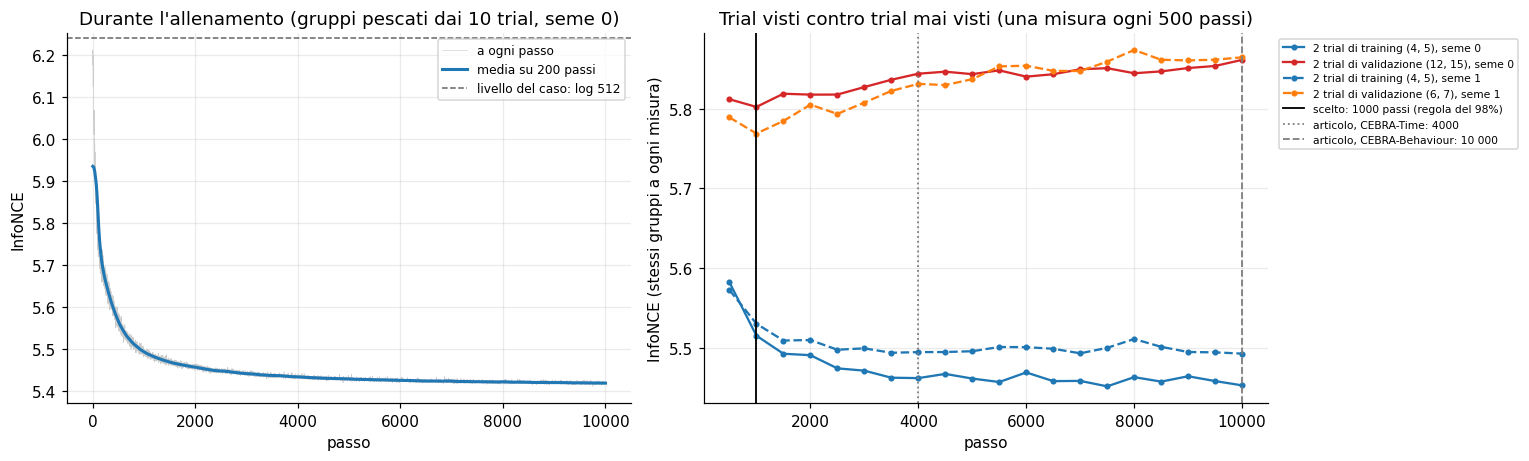

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
loss3 = res3["loss"]                                        # la funzione di costo su ogni gruppo di training, passo per passo
ax[0].plot(np.arange(1, len(loss3) + 1), loss3, color="0.8", lw=0.4, label="a ogni passo")
ax[0].plot(np.arange(1, len(loss3) + 1), uniform_filter1d(loss3, 200), color="C0", lw=2, label="media su 200 passi")
ax[0].axhline(np.log(512), color="0.4", ls="--", lw=1, label="livello del caso: log 512")
ax[0].set(xlabel="passo", ylabel="InfoNCE", title="Durante l'allenamento (gruppi pescati dai 10 trial, seme 0)")
ax[0].legend(fontsize=8)
for h_, run, ls in ((hist3, "seme 0", "-"), (hist3b, "seme 1", "--")):  # le curve misurate ogni 500 passi, nei due allenamenti
    for col in h_.columns:
        c = "C0" if "training" in col else ("C3" if "12" in col else "C1")
        ax[1].plot(h_.index[1:], h_[col].iloc[1:], ls, marker="o", color=c, ms=3, lw=1.5, label=f"{col}, {run}")
ax[1].axvline(N_ITER, color="k", lw=1.2, label=f"scelto: {N_ITER} passi (regola del 98%)")
ax[1].axvline(4000, color="0.5", ls=":", lw=1.2, label="articolo, CEBRA-Time: 4000")
ax[1].axvline(10_000, color="0.5", ls="--", lw=1.2, label="articolo, CEBRA-Behaviour: 10 000")
ax[1].set(xlabel="passo", ylabel="InfoNCE (stessi gruppi a ogni misura)",
          title="Trial visti contro trial mai visti (una misura ogni 500 passi)")
ax[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig(FIGS / "04_convergence.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Durante l'allenamento** (a sinistra) la funzione di costo sui gruppi di training scende per
  tutti i 10 000 passi, sempre più lentamente (da 5.83 nei primi 200 passi a 5.42 negli ultimi
  200).
- **Sui trial mai visti no.** Con entrambe le coppie di validazione il minimo arriva a **1000
  passi** (5.802 per i trial 12-15, 5.769 per i trial 6-7); poi la curva risale lentamente fino a
  10 000 (5.861 e 5.865). Sui trial di training 4-5, nello stesso tempo, resta bassa o continua a
  scendere. È l'**overfitting**: dopo circa 1000 passi la rete impara cose dei trial che vede che
  non valgono per quelli nuovi. Succede in entrambe le coppie, a fine sessione (12-15) e a metà
  (6-7), quindi non dipende da un cambiamento lento nel corso della sessione.
- **Anche nel punto migliore la distanza è grande**: a 1000 passi la goodness of fit è circa 1.0
  bit sui trial di training e 0.63-0.68 bit su quelli di validazione. Una parte importante di
  quello che CEBRA impara è specifica dei trial che vede, come per la PCA qui sopra.
- **La regola dà 1000 passi per entrambe le validazioni: N_ITER = 1000.** È molto meno dei 4000
  (CEBRA-Time) e 10 000 (CEBRA-Behaviour) dell'articolo, che però riguardano altri dati. Una
  conseguenza pratica: un allenamento dura circa 11 secondi.
- Nella prima versione di questa sezione, con la PCA che aveva visto i trial di validazione, le
  curve avevano la stessa forma (minimo a 500-1000 passi, poi risalita) e la regola dava lo stesso
  numero di passi; la risalita era più ripida.
- **Limiti**: un solo blocco, due coppie di trial di validazione, un seme per coppia; la misura è
  su gruppi fissi di istanti, quindi ha un po' di rumore (le oscillazioni da un punto all'altro).

### Il riconoscimento della fase sui trial di validazione

La regola sceglie con la funzione di costo di CEBRA, che non sa nulla delle fasi. Ma quello che
misureremo al §4 è il riconoscimento della fase. Controlliamo quindi che le due cose vadano
d'accordo, **sempre e solo sui trial di validazione** (12 e 15): alleniamo CEBRA sui soliti 10
trial con 500, 1000, 2000 e 5000 passi (più quello da 10 000 appena fatto), e per ognuno misuriamo
il riconoscimento della fase con il metro comune (classificatore a 10 vicini allenato sui punti
dei 10 trial di training, giudicato sui punti dei 2 trial di validazione). Sono solo 2 trial,
quindi i numeri sono rumorosi: guardiamo l'andamento, non il singolo valore. Non serve a
scegliere, ma a controllare la scelta. Per riferimento, con lo stesso schema e la stessa PCA
pulita: PCA con d = 2 (le coordinate libere di CEBRA a 3 dimensioni) e con d = 3, e il
classificatore sulle 25 dimensioni. Circa 1-2 minuti.

In [23]:
ITER_LIST = sorted({500, 1000, 2000, 5000, N_ITER} - {10_000})  # i numeri di passi provati (10 000 è già fatto)
res_it = dict(zip(ITER_LIST, run_cebra_cached([dict(X_train=np.concatenate([SEQ_A[t] for t in fit_trials]),
                                                     X_apply=[SEQ_A[t] for t in TRIALS],
                                                     cfg=dict(CEBRA_STD, max_iterations=n_it), seed=0) for n_it in ITER_LIST])))
res_it[10_000] = res3                                       # l'allenamento da 10 000 passi qui sopra (stesso seme, stessi trial)
ev_fit = bins[np.isin(trial[bins], fit_trials)]             # punti di valutazione dei 10 trial di training
ev_val = bins[np.isin(trial[bins], VAL_TRIALS)]             # punti di valutazione dei 2 trial di validazione

def val_acc(E):                                             # metro comune, ma training = 10 trial, giudizio = 2 trial di validazione
    clf = KNeighborsClassifier(n_neighbors=K_NN).fit(E[ev_fit], phase[ev_fit])
    return balanced_accuracy_score(phase[ev_val], clf.predict(E[ev_val])) * 100

acc_it = {n_it: val_acc(np.concatenate(r["maps"])) for n_it, r in sorted(res_it.items())}
acc_ref = {f"PCA, d = {d}": val_acc(PCA(d).fit(XA[ev_fit]).transform(XA)) for d in (2, 3)}
acc_ref["nessuna mappa, 25 dimensioni"] = val_acc(XA)
print(f"Punti: {len(ev_fit)} di training, {len(ev_val)} di validazione")
display(pd.Series({f"CEBRA-Time, {n_it} passi": a for n_it, a in acc_it.items()} | acc_ref,
                  name="fase riconosciuta sui trial 12 e 15 (%)").round(1).to_frame())

Allenamenti: 0 eseguiti ora, 4 riletti dal disco
Punti: 739 di training, 153 di validazione


,fase riconosciuta sui trial 12 e 15 (%)
"CEBRA-Time, 500 passi",44.0
"CEBRA-Time, 1000 passi",41.4
"CEBRA-Time, 2000 passi",35.0
"CEBRA-Time, 5000 passi",36.0
"CEBRA-Time, 10000 passi",37.2
"PCA, d = 2",27.4
"PCA, d = 3",31.0
"nessuna mappa, 25 dimensioni",47.0


**Lettura.**

- **Il riconoscimento della fase va d'accordo con la regola**: sui trial di validazione è massimo
  con 500-1000 passi (44.0% e 41.4%) e scende a 35-37% da 2000 passi in poi. Allenare di più fa
  peggio anche per quello che misureremo.
- Con lo stesso schema la PCA arriva al 27.4% con d = 2 e al 31.0% con d = 3; il classificatore
  sulle 25 dimensioni al 47.0%. Con 1000 passi CEBRA (2 coordinate libere) sta molto sopra la PCA
  e un po' sotto il classificatore sulle 25 dimensioni.
- **Attenzione**: sono solo 2 trial (153 punti), e differenze di qualche punto sono rumore (per
  esempio 500 contro 1000 passi). Questa tabella non è servita a scegliere: se l'avessimo usata
  avremmo forse preso 500 passi. Teniamo i 1000 della regola. La misura vera, su 5 blocchi, 5 semi
  e i trial di test, è al §4.

### 3.3 · Che aspetto ha la mappa

La mappa è una sfera. Per vederla tutta in una volta la apriamo come un **planisfero** (proiezione
di Mollweide, quella dei mappamondi appesi in classe): longitudine e latitudine di ogni punto.
L'orientamento della sfera è arbitrario, quindi i bordi del planisfero la tagliano in un punto
qualunque: due punti ai bordi opposti possono essere vicini sulla sfera.

Due modelli, entrambi allenati sui 10 trial: quello con il numero di passi scelto (in alto) e quello
da 10 000 passi (in basso). Per ciascuno, tre pannelli:

- i punti di movimento dei **trial di training** (uno ogni 100 ms, come nel metro comune);
- i punti di movimento dei **trial mai visti**: validazione (12, 15) e test del blocco 0 (3, 8, 14).
  Li guardiamo solo dopo aver scelto il numero di passi;
- **tutti i bin** di tutti i trial, con le pause (`Presentation`, `Intertrial`) in grigio: più di
  metà del film di training sono pause (§1.4).

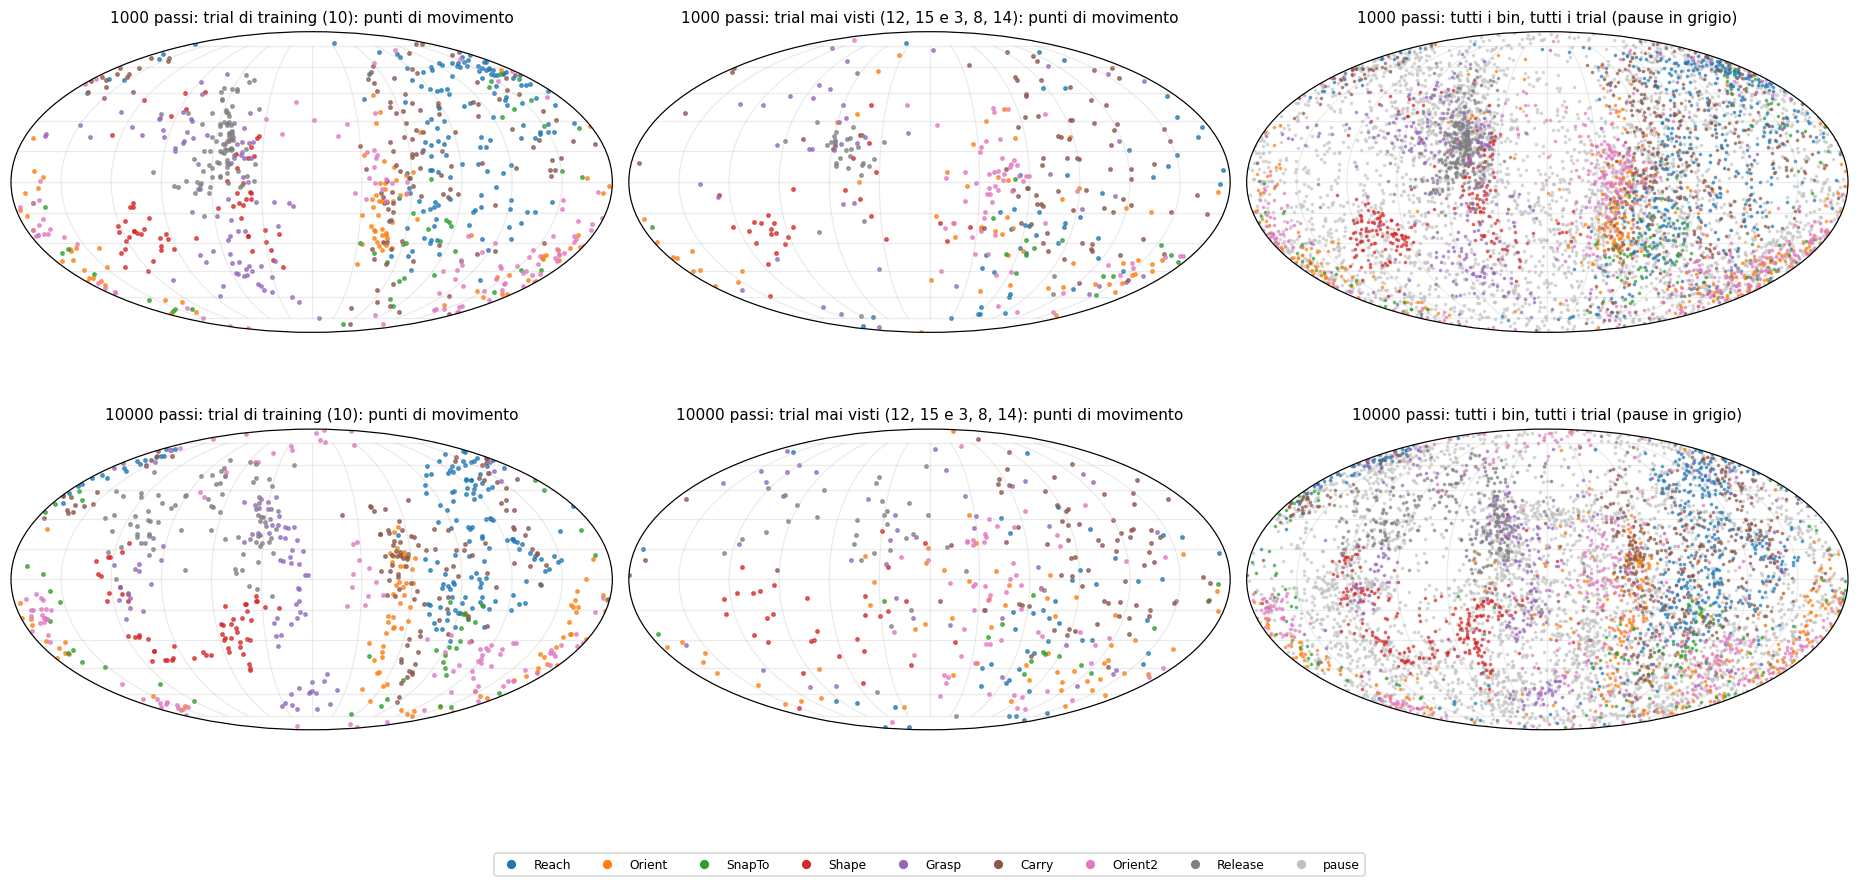

In [24]:
seen = np.isin(trial, fit_trials)                           # bin dei trial su cui CEBRA si è allenato
every2 = np.arange(0, n_bins, 2)                            # un bin ogni 2, per non coprire tutto
pause = every2[~MOV[every2]]

def to_lonlat(E):                                           # longitudine e latitudine di ogni punto della sfera
    return np.arctan2(E[:, 1], E[:, 0]), np.arcsin(np.clip(E[:, 2], -1, 1))

fig = plt.figure(figsize=(17, 8.6))
for row, n_it in enumerate((N_ITER, 10_000)):
    lon, lat = to_lonlat(np.concatenate(res_it[n_it]["maps"]))  # la mappa di tutti i 12233 bin (i trial sono in ordine di tempo)
    for k, (ttl, b_) in enumerate([("trial di training (10): punti di movimento", bins[seen[bins]]),
                                   ("trial mai visti (12, 15 e 3, 8, 14): punti di movimento", bins[~seen[bins]])]):
        a_ = fig.add_subplot(2, 3, row * 3 + k + 1, projection="mollweide")
        for p in io.MOVEMENT_PHASES:                        # un colore per fase
            m = phase[b_] == p
            a_.scatter(lon[b_][m], lat[b_][m], s=5, alpha=0.7, color=io.PHASE_COLORS[p])
        a_.set_title(f"{n_it} passi: {ttl}", fontsize=10); a_.set_xticklabels([]); a_.set_yticklabels([])
    a_ = fig.add_subplot(2, 3, row * 3 + 3, projection="mollweide")
    a_.scatter(lon[pause], lat[pause], s=2, color="0.75", alpha=0.5)  # pause in grigio
    for p in io.MOVEMENT_PHASES:
        m = every2[phase[every2] == p]
        a_.scatter(lon[m], lat[m], s=2, alpha=0.6, color=io.PHASE_COLORS[p])
    a_.set_title(f"{n_it} passi: tutti i bin, tutti i trial (pause in grigio)", fontsize=10)
    a_.set_xticklabels([]); a_.set_yticklabels([])
handles = [plt.Line2D([], [], color=io.PHASE_COLORS[p], marker="o", ls="", ms=5, label=p) for p in io.MOVEMENT_PHASES]
handles.append(plt.Line2D([], [], color="0.75", marker="o", ls="", ms=5, label="pause"))
fig.legend(handles=handles, ncol=9, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(FIGS / "04_cebra_time_map.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Con 1000 passi** (in alto), nei trial di training le fasi occupano zone diverse della sfera: da
  una parte le fasi della mano (`Release` in grigio scuro, `Shape` in rosso, `Grasp` in viola),
  dall'altra quelle del braccio (`Reach`, `Orient`, `SnapTo`, `Carry`, `Orient2`), più mescolate
  tra loro. È la stessa divisione vista nel 03 (§4 e §9.2). Nei trial mai visti le stesse zone si
  riconoscono, più disperse: `Release` e `Shape` restano raggruppate.
- **Con 10 000 passi** (in basso) i gruppi dei trial di training sono più fitti e dettagliati, ma i
  trial mai visti si sparpagliano. È l'overfitting delle curve, reso visibile: se avessimo guardato
  solo i trial di training (o stimato la mappa su tutti i trial, la scorciatoia del 03), il modello
  allenato più a lungo sarebbe sembrato migliore.
- **Le pause** (grigio chiaro, a destra) occupano gran parte della sfera: CEBRA usa una parte del
  suo "spazio" per descrivere momenti che non valutiamo. È la conseguenza della scelta B (§1.4);
  l'alternativa, solo i bin di movimento, è tra le prove del §7.
- **Che cosa la figura non dice**: l'orientamento della sfera è arbitrario e il planisfero deforma
  le zone vicino ai bordi; è una descrizione, non una misura. Le misure sono al §4.

## 4 · CEBRA-Time con il metro comune

Ora la misura vera, la stessa per tutti i metodi (§1.2): riconoscimento della fase con il
classificatore a 10 vicini, accuratezza bilanciata, gli stessi 1106 punti e gli stessi 5 blocchi
del 03. In ogni blocco **CEBRA si allena solo sui 12 trial di training** (il film del §1.4, con le
sue giunte) e i trial di test si proiettano uno alla volta. Parametri del §3, con **N_ITER = 1000**
passi. **5 semi** per ogni misura: media e minimo-massimo.

Tre questioni da risolvere prima di confrontare i numeri.

**1. La sfera: confronto a parità di coordinate libere.** Con la distanza coseno i punti di CEBRA
stanno su una sfera: 3 dimensioni sono 2 coordinate libere, come latitudine e longitudine. Il §2.4
ha mostrato che non è un dettaglio: sul foglio sintetico la sfera a 3 dimensioni perdeva una delle
due direzioni del foglio. La regola: **CEBRA a 3 dimensioni si confronta con PCA, Isomap e UMAP a
d = 2; CEBRA a 4 dimensioni (3 coordinate libere) con d = 3.** Alleniamo entrambe le versioni.

**2. Il classificatore sulla sfera.** L'articolo di CEBRA decodifica con un classificatore a vicini
che usa la distanza coseno (Methods, *Decoding analysis*); il nostro metro comune usa la distanza
in linea d'aria. Per punti sulla sfera è la stessa cosa: la distanza in linea d'aria al quadrato
vale 2 − 2 · coseno, quindi l'ordine dei vicini è identico. Lo verifichiamo.

**3. Un tetto alla pari.** Il tetto del 03 (il classificatore sulle 25 dimensioni di un solo bin)
vale per metodi che vedono un istante alla volta. CEBRA vede una **finestra di 200 ms** (5 bin
prima e 5 dopo, dal bin b − 5 al bin b + 4): può superare quel tetto in modo legittimo, solo perché
guarda di più. Costruiamo quindi due tetti con la stessa finestra, senza nessun apprendimento
(l'idea della media mobile del §2.4):

- **finestra in fila**: per ogni punto, i 10 bin della finestra uno accanto all'altro, 10 × 25 =
  250 numeri. Contiene tutto quello che vede CEBRA;
- **media sulla finestra**: la media dei 10 bin, 25 numeri.

Come per CEBRA, la finestra non esce dal trial: ai bordi si ripete il primo o l'ultimo bin. Va
ricordato che lo smoothing (σ = 50 ms) dà già a **tutti** i metodi una finestra di circa ±150 ms:
quella di CEBRA si aggiunge a questa.

### 4.1 · Il riconoscimento della fase

50 allenamenti (2 versioni × 5 semi × 5 blocchi) da 1000 passi, due alla volta: circa 5 minuti la
prima volta, poi si rileggono dal disco.

In [25]:
from itertools import product                               # tutte le combinazioni di più elenchi

CEBRA_T = dict(CEBRA_STD, max_iterations=N_ITER)            # CEBRA-Time con i parametri del §3
OUT_DIMS = (3, 4)                                           # 3 dimensioni = 2 coordinate libere; 4 dimensioni = 3 coordinate libere
COMBOS = list(product(OUT_DIMS, SEEDS, range(5)))           # (dimensioni, seme, blocco): 50 allenamenti
res4 = run_cebra_cached([dict(X_train=X25[k][TRAIN_BINS[k]].astype(np.float32),  # il film di training del blocco k (§1.4)
                              X_apply=[X25[k][trial == t].astype(np.float32) for t in TRIALS],  # tutti i 15 trial, uno alla volta
                              cfg=dict(CEBRA_T, output_dimension=od), seed=sd)
                         for od, sd, k in COMBOS])
MAPS4 = {c: np.concatenate(r["maps"]) for c, r in zip(COMBOS, res4)}  # per ogni combinazione, la mappa di tutti i 12233 bin
print(f"Durata media di un allenamento: {np.mean([r['seconds'] for r in res4]):.0f} s")

def decode_cebra(od, sd):                                   # metro comune: in ogni blocco, punti di training e di test dalla mappa di quel blocco
    inp = (bins, [(MAPS4[(od, sd, k)][bins[trn]], MAPS4[(od, sd, k)][bins[tst]], trn, tst)
                  for k, (trn, tst) in enumerate(FOLDS)])
    return decode_map(inp, emb_none)                        # la mappa è già fatta: il classificatore lavora direttamente sulle sue coordinate

for od in OUT_DIMS:
    ACC[f"CEBRA-Time, {od} dimensioni"] = [decode_cebra(od, sd) for sd in SEEDS]  # 5 semi

E0 = MAPS4[(3, 0, 0)]; trn0, tst0 = FOLDS[0]                # controllo della questione 2, sulla mappa a 3 dimensioni (seme 0, blocco 0)
pred_euc = KNeighborsClassifier(n_neighbors=K_NN).fit(E0[bins[trn0]], phase[bins[trn0]]).predict(E0[bins[tst0]])
pred_cos = KNeighborsClassifier(n_neighbors=K_NN, metric="cosine").fit(E0[bins[trn0]], phase[bins[trn0]]).predict(E0[bins[tst0]])
print(f"Distanza in linea d'aria contro coseno: previsioni uguali per il {np.mean(pred_euc == pred_cos) * 100:.1f}% dei punti di test")

Allenamenti: 0 eseguiti ora, 50 riletti dal disco
Durata media di un allenamento: 13 s
Distanza in linea d'aria contro coseno: previsioni uguali per il 100.0% dei punti di test


In [26]:
HALF = 5                                                    # la finestra di offset10-model: dal bin b − 5 al bin b + 4
first_last = {t: np.flatnonzero(trial == t)[[0, -1]] for t in TRIALS}  # primo e ultimo bin di ogni trial

def window_idx(b):                                          # per ogni punto, i 10 bin della sua finestra, senza uscire dal trial
    lo = np.array([first_last[trial[x]][0] for x in b])     # primo bin del trial di ogni punto
    hi = np.array([first_last[trial[x]][1] for x in b])     # ultimo bin
    return np.clip(b[:, None] + np.arange(-HALF, HALF)[None, :], lo[:, None], hi[:, None])  # ai bordi si ripete il bin del bordo

W_IDX = window_idx(bins)                                    # (1106 punti, 10 bin)
INP_STACK = (bins, [(X25[k][W_IDX[trn]].reshape(len(trn), -1), X25[k][W_IDX[tst]].reshape(len(tst), -1), trn, tst)
                    for k, (trn, tst) in enumerate(FOLDS)])  # i 10 bin in fila: 250 numeri per punto
INP_MEAN = (bins, [(X25[k][W_IDX[trn]].mean(1), X25[k][W_IDX[tst]].mean(1), trn, tst)
                   for k, (trn, tst) in enumerate(FOLDS)])   # la media dei 10 bin: 25 numeri per punto
ACC["tetto alla pari: finestra in fila (250 numeri)"] = decode_map(INP_STACK, emb_none)
ACC["tetto alla pari: media sulla finestra (25 numeri)"] = decode_map(INP_MEAN, emb_none)

ROWS_4 = [("PCA, d = 2", 2), ("Isomap, d = 2", 2), ("UMAP, d = 2", 2), ("CEBRA-Time, 3 dimensioni", 2),
          ("PCA, d = 3", 3), ("Isomap, d = 3", 3), ("UMAP, d = 3", 3), ("CEBRA-Time, 4 dimensioni", 3),
          ("tetto, 25 dimensioni", 25), ("tetto alla pari: media sulla finestra (25 numeri)", 25),
          ("tetto alla pari: finestra in fila (250 numeri)", 250)]
tab_4 = pd.DataFrame([{"metodo": name, "coordinate libere": free,
                       "fase riconosciuta (%)": mean_range(ACC[name]) if isinstance(ACC[name], list) else f"{ACC[name]:.1f}"}
                      for name, free in ROWS_4]).set_index("metodo")
display(tab_4)

,coordinate libere,fase riconosciuta (%)
metodo,,
"PCA, d = 2",2,26.0
"Isomap, d = 2",2,31.8
"UMAP, d = 2",2,41.2 (40.4-42.3)
"CEBRA-Time, 3 dimensioni",2,37.7 (35.3-40.6)
"PCA, d = 3",3,32.4
"Isomap, d = 3",3,36.0
"UMAP, d = 3",3,42.6 (41.9-43.2)
"CEBRA-Time, 4 dimensioni",3,40.4 (38.5-42.7)
"tetto, 25 dimensioni",25,42.2


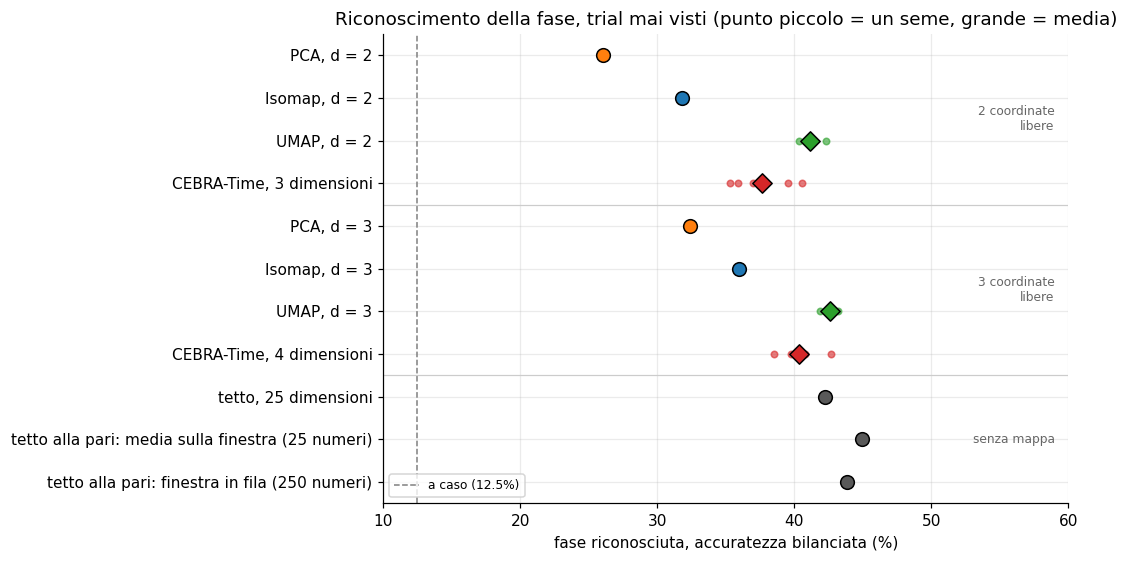

In [27]:
fig, ax = plt.subplots(figsize=(10, 5.2))
names_plot = [n for n, _ in ROWS_4][::-1]                   # dall'alto in basso nell'ordine della tabella
for yi, name in enumerate(names_plot):
    v = np.atleast_1d(ACC[name])                            # 1 valore, o 5 (uno per seme)
    col = "C3" if name.startswith("CEBRA") else ("C2" if name.startswith("UMAP") else
                                                 ("0.35" if name.startswith("tetto") else "C0" if name.startswith("Isomap") else "C1"))
    ax.scatter(v, np.full(len(v), yi), color=col, s=18, alpha=0.6, zorder=2)  # i semi, uno per punto
    ax.scatter(v.mean(), yi, color=col, s=80, marker="D" if len(v) > 1 else "o", edgecolor="k", zorder=3)  # la media
ax.axvline(12.5, color="0.5", ls="--", lw=1, label="a caso (12.5%)")
ax.axhline(2.5, color="0.8", lw=0.8); ax.axhline(6.5, color="0.8", lw=0.8)  # separa i tre gruppi
ax.set(yticks=range(len(names_plot)), yticklabels=names_plot, xlim=(10, 60), xlabel="fase riconosciuta, accuratezza bilanciata (%)",
       title="Riconoscimento della fase, trial mai visti (punto piccolo = un seme, grande = media)")
ax.text(59, 8.5, "2 coordinate\nlibere", ha="right", va="center", fontsize=8, color="0.4")
ax.text(59, 4.5, "3 coordinate\nlibere", ha="right", va="center", fontsize=8, color="0.4")
ax.text(59, 1, "senza mappa", ha="right", va="center", fontsize=8, color="0.4")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "04_phase_decoding.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Il classificatore sulla sfera** (questione 2): con la distanza coseno e con quella in linea
  d'aria le previsioni sono uguali per il 100% dei punti, come previsto.
- **Con 2 coordinate libere CEBRA-Time arriva al 37.7%** (35.3-40.6 tra i semi): molto meglio della
  PCA (26.0%) e di Isomap (31.8%), **peggio di UMAP** (41.2%, 40.4-42.3). Il seme migliore di CEBRA
  arriva appena al peggiore di UMAP.
- **Con 3 coordinate libere: 40.4%** (38.5-42.7), contro 42.6% di UMAP (41.9-43.2), 36.0% di
  Isomap e 32.4% della PCA. Ancora sotto UMAP in media; qui gli intervalli si sovrappongono.
- **La sfera costa**: passare da 3 a 4 dimensioni (da 2 a 3 coordinate libere) fa guadagnare 2.7
  punti, come nel foglio sintetico del §2.4.
- **CEBRA dipende dal seme più di UMAP**: 5 punti tra il seme migliore e il peggiore, contro 1-2.
- **I tetti alla pari.** Guardare 200 ms invece di un bin alza il tetto da 42.2% a **44.9%** (media
  sulla finestra) e a 43.9% (finestra in fila). La finestra quindi aggiunge un po' di
  informazione, 2-3 punti, ma CEBRA non la sfrutta: resta 4.5 punti sotto il suo tetto alla pari
  con 3 coordinate libere. La finestra in fila, che contiene più informazione, fa un po' peggio
  della media: con 250 numeri per punto il classificatore a vicini fatica a trovare i vicini giusti.

**In sintesi: su questa sessione, con il metro comune, CEBRA-Time non batte UMAP.** Fa meglio di
PCA e Isomap, ma non conserva in 2-3 coordinate tutta l'informazione sulle fasi che UMAP conserva,
e non usa quella in più della sua finestra di tempo. È un risultato valido, con due avvertenze:
i parametri di CEBRA sono quelli standard (solo il numero di passi è stato scelto sui nostri
dati), e al §7 ne proveremo altri; e non sappiamo ancora che cosa contenga la mappa oltre alla
catena del tempo (§5).

### 4.2 · Le traiettorie single-trial

La misura del 03 (§6.1 e §9.4), sulle 119 finestre da 1 s dall'inizio di ogni fase: **seghettatura**
(quanto la traiettoria salta da un bin all'altro: più bassa = meglio) e **consistenza** (quanto si
somigliano le ripetizioni della stessa fase: più alta = meglio).

- **Modelli stimati su tutti i 15 trial**, come Isomap e UMAP nel 03: le 5 mappe dei blocchi non si
  possono mescolare, perché ognuna ha il suo orientamento sulla sfera, e la consistenza
  confronterebbe ripetizioni proiettate in mappe diverse. Questa misura quindi **descrive** le
  mappe, non dice quanto generalizzano a trial nuovi (per quello c'è il §4.1). Input: i 25 PC
  stimati su tutti i trial, come nel 03. 5 semi per ogni versione, 1000 passi: circa 1 minuto.
- **Tutte le coordinate della mappa**: 3 per CEBRA a 3 dimensioni, 4 per CEBRA a 4 dimensioni; le
  prime 3 per PCA, Isomap e UMAP (03). Le due misure sono medie sulle dimensioni, quindi il numero
  di dimensioni non le avvantaggia.
- **Le due versioni del task.** Nel 03 (§9.2) abbiamo scoperto che il task alterna due versioni
  tra trial dispari e pari: le 15 ripetizioni di una fase non sono repliche. Calcoliamo quindi la
  consistenza anche **dentro** ciascuna versione (solo le ripetizioni dei trial dispari, solo
  quelle dei pari) e ne facciamo la media. È una correzione che nel 03 mancava; la applichiamo qui
  anche a PCA, Isomap e UMAP, ricalcolati con lo stesso codice del 03. La GPFA (02_new, §10.5) la
  citiamo dal 03 senza ricalcolarla: richiederebbe di ristimarla, e per lei la consistenza per
  versione non c'è.

In [28]:
windows = io.phase_windows(s, win_s=1.0, align="start")     # le 119 finestre da 1 s del 02 e del 03
WIN_TAG = np.array([w["tag"] for w in windows])             # la fase di ogni finestra
WIN_ODD = np.array([w["trial"] % 2 == 1 for w in windows])  # vero per le finestre dei trial dispari (una delle due versioni)

def roughness(trajs):                                       # seghettatura media (03, §6.1)
    return float(np.mean([(np.diff((T_ - T_.mean(0)) / (T_.std(0) + 1e-9), n=2, axis=0) ** 2).mean()
                          for T_ in trajs]))                # z-score di ogni dimensione, poi differenza seconda al quadrato

def consistency(trajs, keep=None):                          # correlazione media tra ripetizioni della stessa fase (03, §6.1); keep = quali finestre usare
    keep = np.ones(len(windows), bool) if keep is None else keep
    out = []
    for p in io.MOVEMENT_PHASES:
        R = np.stack([trajs[i] for i in np.flatnonzero((WIN_TAG == p) & keep)])  # (ripetizioni, 50 bin, dimensioni)
        out.append(np.mean([np.corrcoef(R[:, :, j])[np.triu_indices(len(R), 1)].mean() for j in range(R.shape[2])]))
    return float(np.mean(out))

def traj_stats(trajs):                                      # le misure di una lista di traiettorie
    odd, even = consistency(trajs, WIN_ODD), consistency(trajs, ~WIN_ODD)
    return {"seghettatura": roughness(trajs), "consistenza, tutte le ripetizioni": consistency(trajs),
            "consistenza, solo trial dispari": odd, "consistenza, solo trial pari": even,
            "consistenza per versione (media delle due)": (odd + even) / 2}

def cut(E):                                                 # dalla mappa di tutta la sessione, le 119 finestre
    return [E[w["start"]:w["stop"]] for w in windows]

pca_all = PCA(n_components=K_PCA).fit(Z[bins_all])          # la PCA a 25 su tutti i trial (03, §2)
Z25 = pca_all.transform(Z)                                  # tutta la sessione sulle 25 direzioni
X_all = Z25[bins]                                           # i 1106 punti (03, §2)
win_X = cut(Z25)                                            # le finestre nello spazio a 25 dimensioni
iso_all = Isomap(n_neighbors=K_NN, n_components=15).fit(X_all)  # Isomap come nel 03 (§4: 15 coordinate, ne usiamo 3)
TRAJ = {"PCA": [traj_stats([w_[:, :3] for w_ in cut(PCA(3).fit(X_all).transform(Z25))])],
        "Isomap": [traj_stats([iso_all.transform(x_)[:, :3] for x_ in win_X])],
        "UMAP": [traj_stats(np.split(UMAP(n_neighbors=K_NN, n_components=3, random_state=sd, n_jobs=1).fit(X_all)
                                     .transform(np.concatenate(win_X)), len(win_X))) for sd in SEEDS]}
res4t = run_cebra_cached([dict(X_train=Z25.astype(np.float32), X_apply=[Z25.astype(np.float32)],  # tutta la sessione, una sola sequenza
                               cfg=dict(CEBRA_T, output_dimension=od), seed=sd) for od in OUT_DIMS for sd in SEEDS])
MAPS4T = dict(zip(product(OUT_DIMS, SEEDS), [r["maps"][0] for r in res4t]))  # (dimensioni, seme) -> mappa di tutta la sessione
for od in OUT_DIMS:
    TRAJ[f"CEBRA-Time, {od} dimensioni"] = [traj_stats(cut(MAPS4T[(od, sd)])) for sd in SEEDS]

rows_t = {}
for name, runs in TRAJ.items():
    d_ = pd.DataFrame(runs)                                 # una riga per seme (una sola per PCA e Isomap)
    rows_t[name] = {c: (f"{d_[c].mean():.3f} ({d_[c].min():.3f}-{d_[c].max():.3f})" if len(d_) > 1 else f"{d_[c].iloc[0]:.3f}")
                    for c in d_.columns}
rows_t["GPFA (dal 03, §6.1, e dal 02_new, §10.5)"] = {"seghettatura": "0.011", "consistenza, tutte le ripetizioni": "0.11"}
tab_traj4 = pd.DataFrame(rows_t).T.fillna("non calcolata")
display(tab_traj4)
print("Nel 03, con un solo seme di UMAP: seghettatura PCA 0.013, Isomap 0.27, UMAP 0.59; consistenza 0.088, 0.095, 0.13")

Allenamenti: 0 eseguiti ora, 10 riletti dal disco


,seghettatura,"consistenza, tutte le ripetizioni","consistenza, solo trial dispari","consistenza, solo trial pari",consistenza per versione (media delle due)
PCA,0.013,0.088,0.085,0.134,0.109
Isomap,0.275,0.095,0.081,0.162,0.122
UMAP,0.596 (0.571-0.628),0.125 (0.110-0.134),0.102 (0.095-0.123),0.187 (0.164-0.209),0.144 (0.137-0.152)
"CEBRA-Time, 3 dimensioni",0.080 (0.068-0.099),0.089 (0.069-0.105),0.088 (0.069-0.100),0.124 (0.109-0.134),0.106 (0.089-0.113)
"CEBRA-Time, 4 dimensioni",0.074 (0.066-0.080),0.106 (0.086-0.127),0.110 (0.080-0.134),0.134 (0.095-0.166),0.122 (0.091-0.141)
"GPFA (dal 03, §6.1, e dal 02_new, §10.5)",0.011,0.11,non calcolata,non calcolata,non calcolata


Nel 03, con un solo seme di UMAP: seghettatura PCA 0.013, Isomap 0.27, UMAP 0.59; consistenza 0.088, 0.095, 0.13


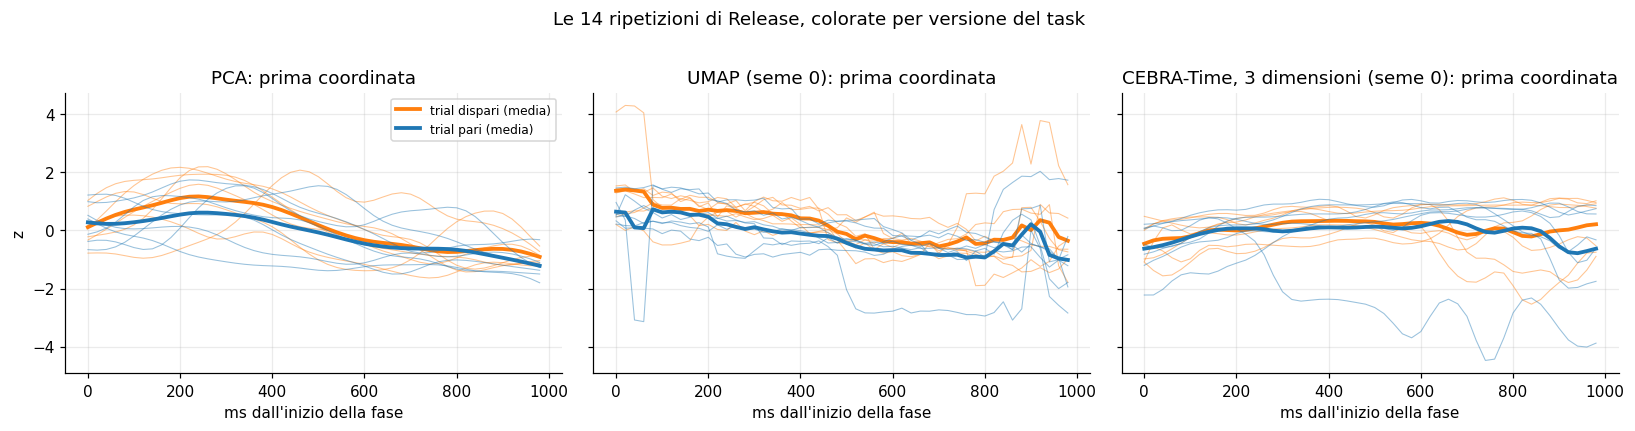

In [29]:
PH_SHOW = "Release"                                         # la fase più riproducibile nel 02 e nel 03
idx_ph = np.flatnonzero(WIN_TAG == PH_SHOW)                 # le sue ripetizioni
t_win = np.arange(50) * 20                                  # ms dall'inizio della fase
show = {"PCA": cut(PCA(3).fit(X_all).transform(Z25)),
        "UMAP (seme 0)": np.split(UMAP(n_neighbors=K_NN, n_components=3, random_state=0, n_jobs=1).fit(X_all)
                                  .transform(np.concatenate(win_X)), len(win_X)),
        "CEBRA-Time, 3 dimensioni (seme 0)": cut(MAPS4T[(3, 0)])}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a_, (name, tr_) in zip(ax, show.items()):
    R = np.stack([tr_[i][:, 0] for i in idx_ph])            # la prima coordinata di ogni ripetizione
    R = (R - R.mean()) / R.std()                            # stessa scala per tutti i metodi
    for odd, c, lab in ((True, "C1", "trial dispari"), (False, "C0", "trial pari")):
        sel = WIN_ODD[idx_ph] == odd
        for r_ in R[sel]:
            a_.plot(t_win, r_, color=c, lw=0.7, alpha=0.45)
        a_.plot(t_win, R[sel].mean(0), color=c, lw=2.5, label=f"{lab} (media)")  # media di ciascuna versione
    a_.set(title=f"{name}: prima coordinata", xlabel="ms dall'inizio della fase")
ax[0].set_ylabel("z"); ax[0].legend(fontsize=8)
fig.suptitle(f"Le {len(idx_ph)} ripetizioni di {PH_SHOW}, colorate per versione del task", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "04_trajectories.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **I numeri del 03 si ritrovano**: PCA 0.013 e 0.088, Isomap 0.275 e 0.095; UMAP con 5 semi 0.596
  (0.571-0.628) e 0.125 (0.110-0.134), in linea con il seme unico del 03 (0.59 e 0.13).
- **Le traiettorie di CEBRA sono lisce, ma non quanto quelle dei metodi lineari.** Seghettatura
  0.080 (3 dimensioni) e 0.074 (4 dimensioni): 7-8 volte meno di UMAP e 3-4 volte meno di Isomap,
  ma 6 volte più della PCA (0.013) e della GPFA (0.011). Il motivo è nel modo in cui sono fatte:
  CEBRA applica la stessa rete a finestre che si sovrappongono (due bin vicini condividono 9 dei 10
  bin di ingresso), mentre Isomap e UMAP collocano ogni punto guardando i suoi vicini, e saltano
  quando i vicini cambiano. La PCA è una semplice proiezione dei dati smussati.
- **Consistenza**: 0.089 per CEBRA a 3 dimensioni (come la PCA, 0.088) e 0.106 a 4 dimensioni
  (come la GPFA, 0.11), sotto UMAP (0.125). Tra i semi cambia molto (per esempio da 0.086 a 0.127
  a 4 dimensioni).
- **Le due versioni del task.** Per tutti i metodi la consistenza dentro una sola versione è più
  alta che mescolandole: PCA da 0.088 a 0.109, UMAP da 0.125 a 0.144, CEBRA a 4 dimensioni da
  0.106 a 0.122. Mescolare le versioni abbassava quindi la consistenza nel 02 e nel 03, come
  sospettato (03, §9.2). L'ordine dei metodi però non cambia. I trial pari sono più consistenti dei
  dispari con tutti i metodi (per esempio UMAP 0.187 contro 0.102): non sappiamo perché, e non
  l'abbiamo indagato.
- Nella figura, le ripetizioni di `Release` lungo la prima coordinata: lisce con la PCA, a salti con
  UMAP, lisce ma più piatte con CEBRA. La prima coordinata di CEBRA non è "la più importante" come
  nella PCA: sulla sfera l'orientamento è arbitrario, quindi la figura serve a vedere la
  seghettatura, non la forma.
- **Limiti**: queste mappe sono stimate su tutti i trial, quindi descrivono e non misurano la
  generalizzazione; con circa 7 ripetizioni per versione la consistenza per versione è rumorosa;
  per la GPFA non l'abbiamo calcolata.

## 5 · Controlli: che cosa c'è nella mappa di CEBRA-Time

Tre domande:

1. **Senza struttura legata al task, CEBRA trova comunque qualcosa?** Lo proviamo sul gemello a
   fasi casuali del 03 (§5.1).
2. **Quanto dipende dal seme?** Con la misura di consistenza tra allenamenti usata nell'articolo di
   CEBRA (§5.2).
3. **CEBRA-Time impara solo la catena del tempo?** È la domanda più importante, perché il suo gioco
   avvicina proprio istanti vicini nel tempo dello stesso trial (§5.3).

Tutti i controlli usano CEBRA a **3 dimensioni** (la sfera con 2 coordinate libere): è la
versione standard, e l'unica che si può disegnare. Al §4 le due versioni si comportavano in modo
simile (37.7% e 40.4%). Parametri del §3 (Δ = 10 bin, 1000 passi), salvo dove li cambiamo
apposta.

### 5.1 · Il gemello a fasi casuali

Il gemello del 03 (§5.2): stesse ampiezze di Fourier dei dati, fasi mescolate a caso (le stesse per
tutte le 25 dimensioni). Ha la stessa covarianza e la stessa velocità di variazione nel tempo,
quindi **la stessa catena del tempo**, ma nessun legame con le fasi del task. Lo costruiamo, per
ogni blocco, sui 25 PC di tutta la sessione (§1.3), e su di lui alleniamo CEBRA esattamente come al
§4. Le etichette di fase sono quelle vere, ma sul gemello non c'entrano nulla: **il riconoscimento
deve scendere al caso** (12.5%). Se non scendesse, vorrebbe dire che qualcosa passa dal training al
test per altre vie. Per confronto, lo stesso controllo con il classificatore sulle 25 dimensioni
del gemello.

5 gemelli (semi 0-4) × 5 blocchi, un seme di CEBRA per gemello: 25 allenamenti, circa 3 minuti.

In [30]:
def phase_randomize(Xt, seed):                              # gemello: stesse ampiezze di Fourier, fasi casuali uguali per tutte le colonne (03, §5.2)
    rng_ = np.random.default_rng(seed)
    F = np.fft.rfft(Xt - Xt.mean(0), axis=0)                # spettro di ogni colonna
    phases = np.exp(2j * np.pi * rng_.uniform(size=F.shape[0]))  # una fase casuale per ogni frequenza
    phases[0] = 1                                           # la componente costante non si tocca
    if len(Xt) % 2 == 0:
        phases[-1] = 1                                      # nemmeno quella alla frequenza massima
    return np.fft.irfft(F * phases[:, None], n=len(Xt), axis=0) + Xt.mean(0)

TWINS = {(k, sd): phase_randomize(X25[k], sd) for k in range(5) for sd in SEEDS}  # (blocco, seme del gemello) -> gemello di tutta la sessione
res_tw = run_cebra_cached([dict(X_train=TWINS[(k, sd)][TRAIN_BINS[k]].astype(np.float32),
                                X_apply=[TWINS[(k, sd)][trial == t].astype(np.float32) for t in TRIALS],
                                cfg=CEBRA_T, seed=sd) for sd in SEEDS for k in range(5)])
MAPS_TW = {(sd, k): np.concatenate(r["maps"]) for (sd, k), r in zip(product(SEEDS, range(5)), res_tw)}

def fold_inp(get):                                          # input del metro comune da una funzione blocco -> dati di tutti i bin
    return (bins, [(get(k)[bins[trn]], get(k)[bins[tst]], trn, tst) for k, (trn, tst) in enumerate(FOLDS)])

acc_tw = [decode_map(fold_inp(lambda k: MAPS_TW[(sd, k)]), emb_none) for sd in SEEDS]       # CEBRA sul gemello
acc_tw_raw = [decode_map(fold_inp(lambda k: TWINS[(k, sd)]), emb_none) for sd in SEEDS]     # classificatore sulle 25 dimensioni del gemello
display(pd.Series({"CEBRA-Time, 3 dimensioni, dati veri (§4)": mean_range(ACC["CEBRA-Time, 3 dimensioni"]),
                   "CEBRA-Time, 3 dimensioni, gemelli (5)": mean_range(acc_tw),
                   "nessuna mappa, 25 dimensioni, dati veri (§1.2)": f"{ACC['tetto, 25 dimensioni']:.1f}",
                   "nessuna mappa, 25 dimensioni, gemelli (5)": mean_range(acc_tw_raw),
                   "a caso": "12.5"}, name="fase riconosciuta (%)").to_frame())

Allenamenti: 0 eseguiti ora, 25 riletti dal disco


,fase riconosciuta (%)
"CEBRA-Time, 3 dimensioni, dati veri (§4)",37.7 (35.3-40.6)
"CEBRA-Time, 3 dimensioni, gemelli (5)",12.5 (10.7-13.9)
"nessuna mappa, 25 dimensioni, dati veri (§1.2)",42.2
"nessuna mappa, 25 dimensioni, gemelli (5)",12.8 (10.7-16.0)
a caso,12.5


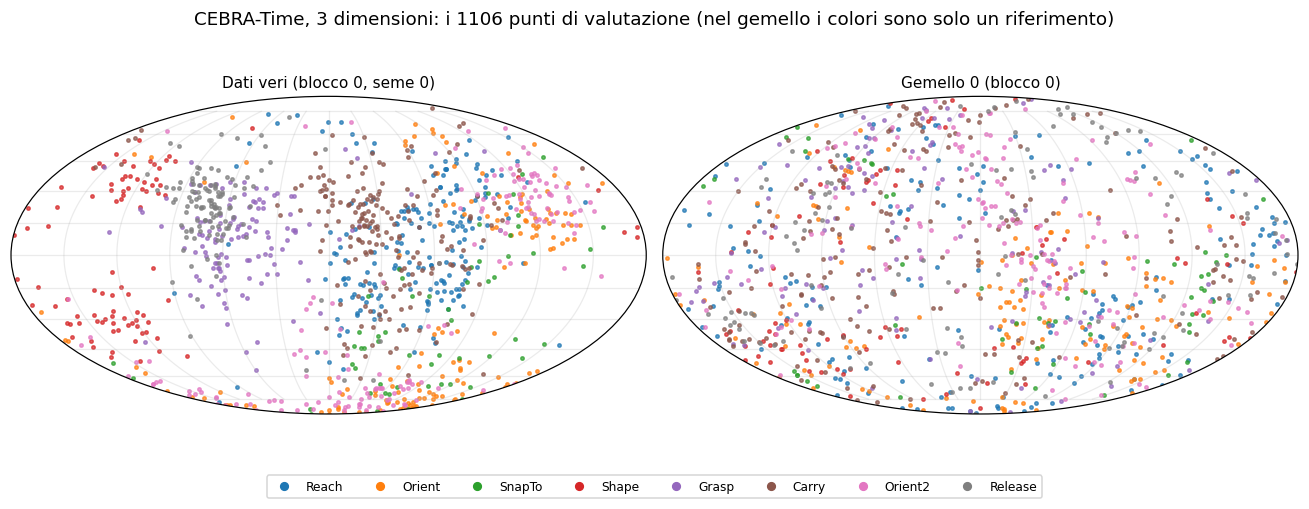

In [31]:
fig = plt.figure(figsize=(12, 4.4))
for j, (ttl, E) in enumerate([("Dati veri (blocco 0, seme 0)", MAPS4[(3, 0, 0)]), ("Gemello 0 (blocco 0)", MAPS_TW[(0, 0)])]):
    lon_, lat_ = to_lonlat(E)
    a_ = fig.add_subplot(1, 2, j + 1, projection="mollweide")
    for p in io.MOVEMENT_PHASES:                            # i punti di valutazione di tutti i trial, un colore per fase
        m = bins[phase[bins] == p]
        a_.scatter(lon_[m], lat_[m], s=5, alpha=0.7, color=io.PHASE_COLORS[p])
    a_.set_title(ttl, fontsize=10); a_.set_xticklabels([]); a_.set_yticklabels([])
handles = [plt.Line2D([], [], color=io.PHASE_COLORS[p], marker="o", ls="", ms=5, label=p) for p in io.MOVEMENT_PHASES]
fig.legend(handles=handles, ncol=8, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.suptitle("CEBRA-Time, 3 dimensioni: i 1106 punti di valutazione (nel gemello i colori sono solo un riferimento)", y=1.0)
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIGS / "04_twin_maps.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Sui gemelli CEBRA-Time scende esattamente al caso**: 12.5% (10.7-13.9 tra i 5 gemelli), come
  il classificatore sulle 25 dimensioni del gemello (12.8%). Niente passa dal training al test per
  altre vie: né attraverso le giunte (§1.5), né attraverso lo smoothing ai confini dei trial, né
  attraverso la catena del tempo, che il gemello conserva. Il 37.7% dei dati veri viene dal legame
  tra attività e task.
- **Le mappe**: sui dati veri le fasi occupano zone diverse della sfera (quelle della mano da una
  parte, quelle del braccio dall'altra, come al §3.3); sul gemello i punti coprono tutta la sfera
  e i colori sono mescolati. Covarianza e catena del tempo da sole non bastano a produrre la
  struttura, come per UMAP nel 03 (§9.2).
- **Limite**: il gemello è gaussiano (03, §5.2), quindi il controllo esclude una nuvola lineare e
  gaussiana con la stessa catena del tempo, non ogni possibile artefatto.

### 5.2 · Quanto conta il seme: la consistenza tra allenamenti

Al §4 i 5 semi di CEBRA davano accuratezze lontane fino a 5 punti. Ma danno anche **mappe
diverse**? L'articolo di CEBRA misura la *consistenza* tra due mappe degli stessi punti così: si
cerca la trasformazione lineare (rotazione, allungamento, spostamento) che porta la prima mappa
il più vicino possibile alla seconda, e si misura l'R², cioè quanta parte della seconda viene
spiegata. R² = 1 vuol dire che le due mappe sono la stessa a meno di una trasformazione lineare;
l'orientamento arbitrario della sfera quindi non conta. Si fa per ogni coppia ordinata di
allenamenti (con 5 semi, 20 coppie).

La rifacciamo a mano (`LinearRegression` di scikit-learn, come nella libreria) e la confrontiamo
con `cebra.sklearn.metrics.consistency_score`, sui 1106 punti di valutazione:

- le mappe dei **modelli stimati su tutti i trial** del §4.2 (5 semi), CEBRA a 3 e 4 dimensioni;
- **UMAP** con 2 e 3 dimensioni, stimato sugli stessi punti con 5 semi;
- le mappe dei **modelli di ciascun blocco** del §4.1 (stimati su 12 trial), media sui blocchi.

PCA e Isomap non dipendono dal caso: la loro consistenza tra allenamenti vale 1 per costruzione.

In [32]:
from sklearn.linear_model import LinearRegression           # regressione lineare, come nella funzione della libreria

def umap_fit(Xp, d, seed=0):                                # UMAP stimato su tutti i punti dati (03, §9.2)
    return UMAP(n_neighbors=K_NN, n_components=d, random_state=seed, n_jobs=1).fit_transform(Xp)

def run_consistency(maps):                                  # R² della regressione lineare da ogni mappa a ogni altra (coppie ordinate)
    return np.array([LinearRegression().fit(A, B).score(A, B) for i, A in enumerate(maps)
                     for j, B in enumerate(maps) if i != j])

def consistency_library(maps):                              # la funzione della libreria (nel processo separato, perché importa torch)
    import cebra
    scores, pairs, ids = cebra.sklearn.metrics.consistency_score(maps, between="runs")
    return np.asarray(scores)

cons_maps = {f"CEBRA-Time, {od} dimensioni (stimato su tutti i trial)": [MAPS4T[(od, sd)][bins] for sd in SEEDS]
             for od in OUT_DIMS}
for d in (2, 3):                                            # UMAP sugli stessi 1106 punti, 5 semi
    cons_maps[f"UMAP, d = {d}"] = Parallel(n_jobs=5)(delayed(umap_fit)(X_all, d, sd) for sd in SEEDS)
cons = {name: run_consistency(m_) for name, m_ in cons_maps.items()}
cons["CEBRA-Time, 3 dimensioni (modelli dei blocchi, media sui 5 blocchi)"] = np.array(
    [run_consistency([MAPS4[(3, sd, k)][bins] for sd in SEEDS]).mean() for k in range(5)])  # una media per blocco
lib = POOL.submit(consistency_library, [m_.astype(np.float32) for m_ in cons_maps["CEBRA-Time, 3 dimensioni (stimato su tutti i trial)"]]).result()
mine = run_consistency([m_.astype(np.float32) for m_ in cons_maps["CEBRA-Time, 3 dimensioni (stimato su tutti i trial)"]])
print(f"A mano contro libreria (CEBRA a 3 dimensioni, 20 coppie): differenza massima {np.abs(np.sort(lib) - np.sort(mine)).max():.1e}")
display(pd.Series({name: mean_range(v * 100) for name, v in cons.items()} | {"PCA, Isomap": "100 (per costruzione)"},
                  name="consistenza tra allenamenti: R² (%), media (min-max)").to_frame())

A mano contro libreria (CEBRA a 3 dimensioni, 20 coppie): differenza massima 0.0e+00


,"consistenza tra allenamenti: R² (%), media (min-max)"
"CEBRA-Time, 3 dimensioni (stimato su tutti i trial)",63.4 (46.9-83.1)
"CEBRA-Time, 4 dimensioni (stimato su tutti i trial)",75.1 (66.8-83.9)
"UMAP, d = 2",87.2 (72.0-97.3)
"UMAP, d = 3",93.3 (87.5-99.2)
"CEBRA-Time, 3 dimensioni (modelli dei blocchi, media sui 5 blocchi)",66.0 (62.9-70.3)
"PCA, Isomap",100 (per costruzione)


**Lettura.**

- **Il calcolo a mano coincide con la libreria** (differenza 0 sulle 20 coppie).
- **Le mappe di CEBRA cambiano molto più di quelle di UMAP da un seme all'altro**: R² 63% con 3
  dimensioni e 75% con 4, contro 87% e 93% di UMAP. Alcune coppie di semi di CEBRA sono lontane
  (minimo 47% a 3 dimensioni): stessi dati, stessi parametri, e due mappe che non sono l'una una
  trasformazione lineare dell'altra. Con i modelli dei singoli blocchi (12 trial) è lo stesso: 66%.
- È coerente con il §4, dove tra i semi c'erano 5 punti di differenza nel riconoscimento della
  fase. Il motivo non l'abbiamo verificato; un'ipotesi è che con pochi dati e 1000 passi la rete si
  fermi in soluzioni diverse a seconda del punto di partenza.
- **Conseguenza per la tesi**: una singola mappa di CEBRA non va interpretata da sola; vanno
  riportati più semi, e la forma che si vede in una mappa va controllata nelle altre.

### 5.3 · CEBRA-Time impara solo la catena del tempo?

Nel 03 (§2) la "catena del tempo" era questa: sui dati smussati il vicino di un istante è quasi
sempre "sé stesso un attimo prima o dopo", nello stesso trial. CEBRA-Time fa proprio questo, per
costruzione: avvicina ogni istante a quello 200 ms dopo. Una mappa fatta **solo** di catena
metterebbe ogni trial su un suo binario, separato dagli altri, e non servirebbe a riconoscere le
fasi in trial nuovi. Che il riconoscimento del §4 sia molto sopra il caso dice già che la mappa
contiene di più. Ma resta un'altra possibilità, più sottile: **l'orologio**. Le fasi vengono
sempre nello stesso ordine, quindi "da quanto è cominciato il trial" dice già molto sulla fase. Una
mappa che codificasse solo il tempo trascorso, allineato tra i trial, riconoscerebbe le fasi senza
guardare l'attività legata al movimento.

Quattro prove:

- **(a) Chi sono i vicini nella mappa?** La misura del 03 (§2): dei 10 vicini di ogni punto, quanti
  sono catena del tempo (stesso trial, entro 200 ms), quanti "stessa fase, altro trial", quanti
  altro. Sui modelli stimati su tutti i trial, confrontati con l'input, la PCA e UMAP.
- **(b) L'orologio da solo**: il metro comune con un solo numero per punto, il tempo trascorso
  dall'inizio del trial.
- **(c) Quanto orologio c'è in ogni mappa**: con lo stesso schema (trial mai visti), quanto bene un
  regressore a 10 vicini ricava dalla mappa il tempo trascorso (R²).
- **(d) Cambiare Δ**: coppie positive a 20 ms (Δ = 1) e a 1 s (Δ = 50) invece che a 200 ms. Con
  Δ = 1 il gioco è banale (il fotogramma successivo del film, quasi identico per lo smoothing):
  dovrebbe restare solo la catena. Con Δ = 50 i due istanti stanno spesso in fasi diverse.
  Attenzione: i 1000 passi sono stati scelti per Δ = 10; per gli altri Δ non li abbiamo
  ricontrollati. 2 semi per ogni Δ, sia per blocco (20 allenamenti) sia su tutti i trial (4).
  Circa 3 minuti.

In [33]:
from scipy.spatial.distance import pdist, squareform        # distanze tra tutte le coppie di punti

K_MIX, CHAIN_BINS = 10, 10                                  # vicini contati e catena del tempo (stesso trial, entro 10 bin = 200 ms), come nel 03

def knn_index(Xp, k=K_MIX):                                 # indici dei k vicini di ogni punto, escluso il punto stesso (03, §2)
    D = squareform(pdist(Xp)); np.fill_diagonal(D, np.inf)
    return np.argpartition(D, k, axis=1)[:, :k]

def neighbor_mix(Y, b=bins):                                # composizione dei vicini di ogni punto in una mappa Y (03, §2)
    nb = knn_index(Y)
    tr_, ph_ = trial[b], phase[b]
    chain = (tr_[nb] == tr_[:, None]) & (np.abs(b[nb] - b[:, None]) <= CHAIN_BINS)  # stesso trial, entro 200 ms
    good = ~chain & (ph_[nb] == ph_[:, None]) & (tr_[nb] != tr_[:, None])           # stessa fase, altro trial
    return {"catena del tempo (%)": chain.mean() * 100, "stessa fase, altro trial (%)": good.mean() * 100,
            "altro (%)": (1 - chain.mean() - good.mean()) * 100}

DELTAS = (1, 50)                                            # Δ provati oltre a 10
res_dall = run_cebra_cached([dict(X_train=Z25.astype(np.float32), X_apply=[Z25.astype(np.float32)],  # su tutti i trial, come al §4.2
                                  cfg=dict(CEBRA_T, time_offsets=dl), seed=sd) for dl in DELTAS for sd in (0, 1)])
MAPS_DALL = dict(zip(product(DELTAS, (0, 1)), [r["maps"][0] for r in res_dall]))

mix_rows = {"input: 25 PC": [neighbor_mix(X_all)],
            "PCA, d = 2": [neighbor_mix(PCA(2).fit_transform(X_all))],
            "UMAP, d = 2 (5 semi)": [neighbor_mix(Y_) for Y_ in cons_maps["UMAP, d = 2"]],
            "CEBRA-Time, Δ = 10 (5 semi)": [neighbor_mix(MAPS4T[(3, sd)][bins]) for sd in SEEDS],
            **{f"CEBRA-Time, Δ = {dl} (2 semi)": [neighbor_mix(MAPS_DALL[(dl, sd)][bins]) for sd in (0, 1)] for dl in DELTAS}}
tab_mix = pd.DataFrame({name: pd.DataFrame(r_).mean() for name, r_ in mix_rows.items()}).T
ph_b, tr_b = phase[bins], trial[bins]
tab_mix.loc["a caso", "stessa fase, altro trial (%)"] = np.mean([np.mean((ph_b == ph_b[i]) & (tr_b != tr_b[i])) for i in range(len(bins))]) * 100
display(tab_mix.round(1))

Allenamenti: 0 eseguiti ora, 4 riletti dal disco


,catena del tempo (%),"stessa fase, altro trial (%)",altro (%)
input: 25 PC,20.4,27.1,52.5
"PCA, d = 2",2.8,21.4,75.8
"UMAP, d = 2 (5 semi)",16.1,33.9,50.0
"CEBRA-Time, Δ = 10 (5 semi)",7.9,33.1,59.0
"CEBRA-Time, Δ = 1 (2 semi)",3.7,20.1,76.1
"CEBRA-Time, Δ = 50 (2 semi)",3.6,20.8,75.6
a caso,NaN,12.7,NaN


In [34]:
clock = np.zeros(n_bins)                                    # l'orologio: secondi trascorsi dall'inizio del trial, per ogni bin
for t in TRIALS:
    clock[trial == t] = (np.arange((trial == t).sum())) * io.BIN_S
ACC["l'orologio da solo (1 numero)"] = decode_map(fold_inp(lambda k: clock[:, None]), emb_none)

def regress_map(inp, embed, target):                        # R² con cui un regressore a 10 vicini ricava `target` dalla mappa (stima pulita, come decode_map)
    b, folds = inp
    pred = np.empty(len(b))
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)
        pred[tst] = KNeighborsRegressor(n_neighbors=K_NN).fit(Etr, target[b[trn]]).predict(Ete)
    return r2_score(target[b], pred)

clock_r2 = {"PCA, d = 2": [regress_map(INP_PC, emb_pca(2), clock)],
            "Isomap, d = 2": [regress_map(INP_PC, emb_isomap(2), clock)],
            "UMAP, d = 2": Parallel(n_jobs=5)(delayed(regress_map)(INP_PC, emb_umap(2, sd), clock) for sd in SEEDS),
            "CEBRA-Time, 3 dimensioni": [regress_map(fold_inp(lambda k: MAPS4[(3, sd, k)]), emb_none, clock) for sd in SEEDS],
            "nessuna mappa, 25 dimensioni": [regress_map(INP_PC, emb_none, clock)]}
ACC_OF = {"nessuna mappa, 25 dimensioni": "tetto, 25 dimensioni"}  # dove trovare in ACC l'accuratezza di ogni riga

def fmt(v, scale=1):                                        # "media (min-max)" se ci sono più semi, altrimenti il numero
    v = np.atleast_1d(v) * scale
    return mean_range(v) if len(v) > 1 else f"{v[0]:.1f}"

display(pd.DataFrame({name: {"orologio ricavato dalla mappa (R², %)": fmt(v, 100),
                             "fase riconosciuta (%)": fmt(ACC[ACC_OF.get(name, name)])}
                      for name, v in clock_r2.items()}).T)
acc_clock = ACC["l'orologio da solo (1 numero)"]
print(f"L'orologio da solo riconosce la fase al {acc_clock:.1f}% (a caso 12.5%)")

,"orologio ricavato dalla mappa (R², %)",fase riconosciuta (%)
"PCA, d = 2",-5.1,26.0
"Isomap, d = 2",1.2,31.8
"UMAP, d = 2",-9.0 (-10.4--6.6),41.2 (40.4-42.3)
"CEBRA-Time, 3 dimensioni",-10.6 (-13.6--6.4),37.7 (35.3-40.6)
"nessuna mappa, 25 dimensioni",1.7,42.2


L'orologio da solo riconosce la fase al 48.5% (a caso 12.5%)


**Mappa e orologio indovinano le stesse cose?** L'R² dell'orologio ricavato dalle mappe è vicino a
zero o negativo, ma da solo non basta a dire che le mappe non contengano niente dell'orologio:
scambiare `Reach` (all'inizio del trial) con `Orient2` (verso la fine) costa molti secondi di
errore, e l'R² punisce molto gli errori grandi. Un controllo più diretto, punto per punto: per ogni
punto di test guardiamo se ha indovinato la mappa, l'orologio, entrambi o nessuno (frazioni dei
1106 punti, senza bilanciare le fasi). Se la mappa indovinasse quasi solo dove indovina anche
l'orologio, sarebbe sospetta. E fase per fase: quale fase riconosce ciascuno (la frazione dei punti
di quella fase riconosciuti).

In [35]:
def predict_map(inp, embed):                                # le previsioni di fase di ogni punto, con la stima pulita di decode_map
    b, folds = inp
    pred = np.empty(len(b), dtype=object)
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)
        pred[tst] = KNeighborsClassifier(n_neighbors=K_NN).fit(Etr, phase[b[trn]]).predict(Ete)
    return pred

ph_true = phase[bins]                                       # la fase vera di ogni punto
pred_clock = predict_map(fold_inp(lambda k: clock[:, None]), emb_none)  # le previsioni dell'orologio
PREDS = {"CEBRA-Time, 3 dimensioni (5 semi)": [predict_map(fold_inp(lambda k: MAPS4[(3, sd, k)]), emb_none) for sd in SEEDS],
         "UMAP, d = 2 (5 semi)": Parallel(n_jobs=5)(delayed(predict_map)(INP_PC, emb_umap(2, sd)) for sd in SEEDS),
         "nessuna mappa, 25 dimensioni": [predict_map(INP_PC, emb_none)]}
ok_clock = pred_clock == ph_true                            # dove indovina l'orologio
tab_cc = pd.DataFrame({name: pd.DataFrame([{"giusti per entrambi": np.mean(ok & ok_clock) * 100,
                                            "solo la mappa": np.mean(ok & ~ok_clock) * 100,
                                            "solo l'orologio": np.mean(~ok & ok_clock) * 100,
                                            "sbagliati per entrambi": np.mean(~ok & ~ok_clock) * 100}
                                           for ok in [p_ == ph_true for p_ in preds]]).mean()
                       for name, preds in PREDS.items()}).T
display(tab_cc.round(1))

recall = {"l'orologio": {p: np.mean(pred_clock[ph_true == p] == p) * 100 for p in io.MOVEMENT_PHASES}}
for name, preds in PREDS.items():                           # fase per fase, media sui semi
    recall[name] = {p: np.mean([np.mean(p_[ph_true == p] == p) for p_ in preds]) * 100 for p in io.MOVEMENT_PHASES}
display(pd.DataFrame(recall).T.round(0))

,giusti per entrambi,solo la mappa,solo l'orologio,sbagliati per entrambi
"CEBRA-Time, 3 dimensioni (5 semi)",20.5,17.5,37.0,25.1
"UMAP, d = 2 (5 semi)",22.0,19.5,35.5,23.1
"nessuna mappa, 25 dimensioni",21.8,20.1,35.6,22.5


,Reach,Orient,SnapTo,Shape,Grasp,Carry,Orient2,Release
l'orologio,99.0,81.0,12.0,4.0,33.0,73.0,44.0,42.0
"CEBRA-Time, 3 dimensioni (5 semi)",28.0,28.0,2.0,66.0,45.0,42.0,30.0,60.0
"UMAP, d = 2 (5 semi)",26.0,37.0,1.0,71.0,53.0,50.0,24.0,66.0
"nessuna mappa, 25 dimensioni",22.0,41.0,2.0,75.0,59.0,47.0,24.0,68.0


In [36]:
res_dfold = run_cebra_cached([dict(X_train=X25[k][TRAIN_BINS[k]].astype(np.float32),  # come al §4.1, cambiando solo Δ
                                   X_apply=[X25[k][trial == t].astype(np.float32) for t in TRIALS],
                                   cfg=dict(CEBRA_T, time_offsets=dl), seed=sd)
                              for dl in DELTAS for sd in (0, 1) for k in range(5)])
MAPS_DF = {c: np.concatenate(r["maps"]) for c, r in zip(product(DELTAS, (0, 1), range(5)), res_dfold)}
acc_delta = {10: ACC["CEBRA-Time, 3 dimensioni"][:2]}       # Δ = 10: gli stessi due semi (0 e 1) del §4.1
for dl in DELTAS:
    acc_delta[dl] = [decode_map(fold_inp(lambda k: MAPS_DF[(dl, sd, k)]), emb_none) for sd in (0, 1)]
display(pd.DataFrame({f"Δ = {dl} bin ({dl * 20} ms)": {
    "fase riconosciuta (%), semi 0 e 1": " e ".join(f"{a:.1f}" for a in acc_delta[dl]),
    "catena del tempo tra i vicini (%)": f"{tab_mix.loc[f'CEBRA-Time, Δ = {dl} ' + ('(5 semi)' if dl == 10 else '(2 semi)'), 'catena del tempo (%)']:.1f}",
    "stessa fase, altro trial (%)": f"{tab_mix.loc[f'CEBRA-Time, Δ = {dl} ' + ('(5 semi)' if dl == 10 else '(2 semi)'), 'stessa fase, altro trial (%)']:.1f}"}
    for dl in sorted(acc_delta)}).T)

Allenamenti: 0 eseguiti ora, 20 riletti dal disco


,"fase riconosciuta (%), semi 0 e 1",catena del tempo tra i vicini (%),"stessa fase, altro trial (%)"
Δ = 1 bin (20 ms),30.5 e 27.8,3.7,20.1
Δ = 10 bin (200 ms),35.3 e 35.9,7.9,33.1
Δ = 50 bin (1000 ms),21.8 e 23.9,3.6,20.8


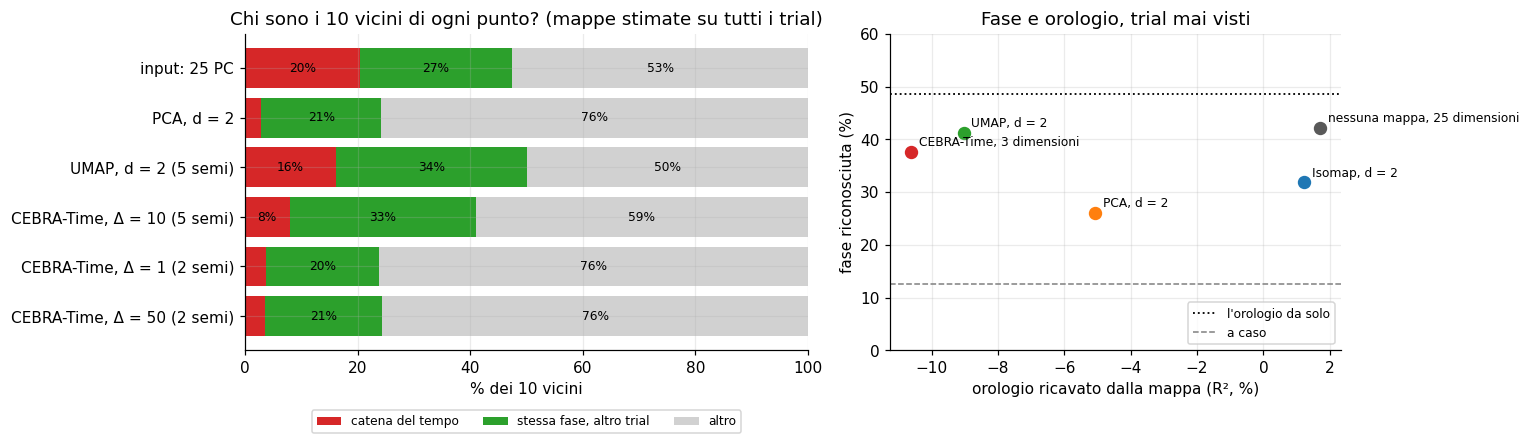

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": (1.25, 1)})
cats, cols = ["catena del tempo (%)", "stessa fase, altro trial (%)", "altro (%)"], ["C3", "C2", "0.82"]
rows_plot = [r_ for r_ in tab_mix.index if r_ != "a caso"]
for i, name in enumerate(rows_plot):                        # una barra per mappa, i tre gruppi uno dopo l'altro
    left = 0
    for c, col in zip(cats, cols):
        v = tab_mix.loc[name, c]
        ax[0].barh(i, v, left=left, color=col, label=c.replace(" (%)", "") if i == 0 else None)
        if v > 5:
            ax[0].text(left + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8)
        left += v
ax[0].set_yticks(range(len(rows_plot))); ax[0].set_yticklabels(rows_plot); ax[0].invert_yaxis()
ax[0].set(xlim=(0, 100), xlabel="% dei 10 vicini", title="Chi sono i 10 vicini di ogni punto? (mappe stimate su tutti i trial)")
ax[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=8)
names_c = list(clock_r2)
xr = [np.mean(clock_r2[n]) * 100 for n in names_c]          # quanto orologio c'è nella mappa
ya = [np.mean(ACC[ACC_OF.get(n, n)]) for n in names_c]    # quanto riconosce la fase
for n, x_, y_ in zip(names_c, xr, ya):
    ax[1].scatter(x_, y_, s=60, color="C3" if n.startswith("CEBRA") else ("C2" if n.startswith("UMAP") else
                                                                         "C0" if n.startswith("Isomap") else "C1" if n.startswith("PCA") else "0.35"))
    ax[1].annotate(n, (x_, y_), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax[1].axhline(ACC["l'orologio da solo (1 numero)"], color="k", ls=":", lw=1.2, label="l'orologio da solo")
ax[1].axhline(12.5, color="0.5", ls="--", lw=1, label="a caso")
ax[1].set(xlabel="orologio ricavato dalla mappa (R², %)", ylabel="fase riconosciuta (%)", ylim=(0, 60),
          title="Fase e orologio, trial mai visti")
ax[1].legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "04_time_chain.png", bbox_inches="tight"); plt.show()

**Lettura.**

**(a) La catena del tempo non domina la mappa.** Nella mappa di CEBRA-Time (Δ = 10) solo il 7.9% dei
vicini è catena del tempo: meno che nell'input (20.4%) e in UMAP (16.1%). I vicini "stessa fase,
altro trial" sono il 33.1%, come in UMAP (33.9%), più che nell'input (27.1%) e molto più del caso
(12.7%). Nonostante il suo gioco avvicini ogni istante a quello 200 ms dopo, alla scala dei punti
di valutazione (uno ogni 100 ms) i vicini di un punto vengono soprattutto da altri trial.

**(b) L'orologio da solo riconosce la fase al 48.5%**: più di tutte le mappe e più dei tetti
(42.2% e 44.9%). Sapere solo da quanto è cominciato il trial basta a indovinare la fase meglio che
con l'attività neurale, con qualunque metodo. Non è un errore dei metodi, che l'orologio non lo
vedono, ma cambia il modo di leggere i numeri assoluti del metro comune, anche quelli del 03: il
confronto tra metodi resta alla pari, ma "40%" va letto accanto a quello che la struttura del task
dà gratis.

**(c) Le mappe non sono un orologio.**

- Dal tempo trascorso le mappe non ricavano quasi nulla: R² tra −11% e +2% per tutte, CEBRA
  compresa (−10.6%).
- Punto per punto, mappa e orologio indovinano **cose diverse**: dei punti che CEBRA riconosce
  (20.5% + 17.5% = 38%), quasi la metà (17.5%) sono sbagliati per l'orologio. Lo stesso vale per
  UMAP e per il classificatore sulle 25 dimensioni.
- Fase per fase la divisione è netta. L'orologio riconosce le fasi del braccio, che si susseguono
  a tempi quasi fissi dopo l'inizio del trial: `Reach` 99%, `Orient` 81%, `Carry` 73%. Fallisce
  `Shape` (4%) e `SnapTo` (12%). Le mappe neurali riconoscono invece le fasi della mano: `Shape`
  66-75%, `Release` 60-68%, `Grasp` 45-59%, coerentemente con la posizione degli array nell'area
  della mano (02 e 03). Le fasi del braccio, nelle mappe, si confondono tra loro (22-50%).

**(d) Δ = 10 è il valore migliore** dei tre: 35.3% e 35.9% (semi 0 e 1), contro 30.5% e 27.8% con
Δ = 1 e 21.8% e 23.9% con Δ = 50. Con Δ = 1 il gioco è troppo facile; con Δ = 50 il positivo cade
spesso in un'altra fase. L'ipotesi "con Δ = 1 resta solo la catena" non si conferma: la catena tra
i vicini scende (3.7%) insieme a tutto il resto ("altro" al 76%). La rete impara semplicemente di
meno. Limite: i 1000 passi sono stati scelti per Δ = 10.

**In sintesi**: CEBRA-Time con Δ = 10 non impara solo la catena del tempo, e nemmeno un orologio.
Impara soprattutto l'attività legata alle fasi della mano, come UMAP per quanto riguarda i vicini,
ma con mappe meno stabili da un seme all'altro (§5.2). E il riconoscimento della fase, la misura
comune di tutti i notebook, ha un termine di confronto "senza neuroni" molto alto: l'orologio.

## 6 · CEBRA-Behavior: la mappa guidata dalla cinematica

CEBRA-Time decideva chi "va insieme" con il tempo. **CEBRA-Behavior** lo decide con un'etichetta
di comportamento: due istanti vanno insieme se il comportamento è simile. È quindi un metodo
**supervisionato** (usa le etichette), e non si confronta alla pari con i metodi senza etichette
dei §1-§5.

**Le etichette: posizione e velocità insieme** (scelta dell'utente). Per ogni bin, i 7 gradi di
libertà della posizione (`s.kin`) e i 7 della velocità (`s.vel`, il bersaglio di FALCON): 14 numeri.
È la cinematica di **riferimento** mostrata dal braccio virtuale, non un movimento eseguito
(il partecipante lo tenta: §1.1).

**Come CEBRA sceglie il positivo** (letto nel codice, `TimedeltaDistribution`): alla cinematica
del riferimento aggiunge una variazione di 200 ms (Δ = 10 bin) osservata in un istante a caso della
sessione, e prende come positivo l'istante, **di qualunque trial**, con la cinematica più vicina a
quella ottenuta. In pratica: "l'istante, anche in un altro trial, in cui il braccio si trova dove
questo starebbe di lì a poco". I negativi restano istanti a caso.

**Le etichette vanno messe sulla stessa scala.** La cinematica più vicina si cerca con la distanza
in linea d'aria; senza correzione peserebbero di più i numeri grandi (le velocità, in unità al
secondo) e quasi nulla le posizioni. La documentazione della libreria lo dice esplicitamente.
Facciamo uno z-score di ciascuno dei 14 numeri, con media e deviazione standard dei soli trial di
training di ogni blocco.

**Che cosa può e non può dire il confronto.**

- La valutazione resta il riconoscimento della **fase**, che non è l'etichetta: il test non è
  circolare. Ma la cinematica di riferimento è quasi la stessa in ogni ripetizione, quindi porta con
  sé molta informazione sulla fase. Contiene anche la **versione del task**: il grado di libertà g3
  della presa va in direzioni opposte nei trial dispari e pari (03, §9.2). Ce lo aspettiamo, e lo
  misuriamo.
- Il termine di confronto giusto è un **metodo lineare con le stesse etichette**: la **PLS**
  (*partial least squares*), che cerca le direzioni dei 25 PC che meglio predicono la cinematica,
  stimata sugli stessi bin di training di CEBRA. Con 2 componenti si confronta con CEBRA-Behavior a
  3 dimensioni, con 3 componenti con quello a 4.
- **Il controllo dell'articolo**: le etichette mescolate. Ne facciamo due versioni (§6.4).

Prima però il numero di passi: con le etichette l'overfitting può cambiare, quindi rifacciamo il
controllo del §3 (§6.2).

In [38]:
from sklearn.cross_decomposition import PLSRegression       # PLS: proiezione lineare guidata dalle etichette

Y_KIN = np.c_[s.kin, s.vel]                                 # le etichette: 7 posizioni + 7 velocità per ogni bin (12233 × 14)
KIN_NAMES = [f"posizione {n}" for n in io.KIN_LABELS] + [f"velocità {n}" for n in io.KIN_LABELS]

def label_z(train_trials):                                  # z-score delle 14 etichette con media e deviazione dei soli trial di training
    m = np.isin(trial, train_trials)
    return ((Y_KIN - Y_KIN[m].mean(0)) / Y_KIN[m].std(0)).astype(np.float32)

def cebra_fit_beh(X_train, y_train, X_apply, cfg, seed, val=None, model_path=None):
    """Come cebra_fit (§2.3), ma con le etichette: CEBRA-Behavior. val = {nome: (X, y)}: insiemi su cui misurare,
    alla fine, la funzione di costo con la stessa scelta dei positivi. Gira nel processo separato."""
    import time                                             # per misurare la durata
    import numpy as np                                      # array
    import torch                                            # la libreria delle reti neurali usata da CEBRA
    import cebra                                            # CEBRA
    import cebra.distributions.base as cdb                  # per la correzione del seme (§2.7)
    torch.set_num_threads(1)                                # i calcoli pesanti sono sulla GPU
    if not hasattr(cdb.HasGenerator, "orig_init"):          # la stessa correzione del seme di cebra_fit (§2.7), codice identico
        cdb.HasGenerator.orig_init = cdb.HasGenerator.__init__
        def seeded_init(self, device, seed):
            cdb.HasGenerator.orig_init(self, device=device, seed=seed)
            if cdb.HasGenerator.fixed_seed is not None:
                self._seed = cdb.HasGenerator.fixed_seed * 1000 + cdb.HasGenerator.counter
                cdb.HasGenerator.counter += 1
                self._generator = torch.Generator(device=self.device).manual_seed(self._seed)
        cdb.HasGenerator.__init__ = seeded_init
    cdb.HasGenerator.fixed_seed = seed                      # sempre con la correzione
    cdb.HasGenerator.counter = 0
    torch.manual_seed(seed); np.random.seed(seed)
    device = "mps" if torch.backends.mps.is_available() else "cpu"
    model = cebra.CEBRA(**cfg, device=device, verbose=False)
    t0 = time.time()
    model.fit(X_train, y_train)                             # con un'etichetta continua: CEBRA-Behavior (positivi scelti con "time_delta")
    seconds = time.time() - t0
    if model_path is not None:
        model.save(str(model_path))
    extra = {name: float(cebra.sklearn.metrics.infonce_loss(model, Xv, yv, num_batches=200))  # funzione di costo su dati dati, 200 gruppi
             for name, (Xv, yv) in (val or {}).items()}
    return {"maps": [model.transform(x) for x in X_apply], "loss": np.asarray(model.state_dict_["loss"]),
            "seconds": seconds, "device": device, "extra": extra}

print(f"Etichette: {Y_KIN.shape[1]} numeri per bin; deviazione standard prima dello z-score: "
      f"posizioni da {Y_KIN[:, :7].std(0).min():.2f} a {Y_KIN[:, :7].std(0).max():.2f}, "
      f"velocità da {Y_KIN[:, 7:].std(0).min():.2f} a {Y_KIN[:, 7:].std(0).max():.2f}")

Etichette: 14 numeri per bin; deviazione standard prima dello z-score: posizioni da 0.08 a 0.55, velocità da 0.00 a 0.01


### 6.2 · Quanti passi con le etichette?

Lo schema del §3.2: blocco 0, due coppie di trial di validazione (12-15 e 6-7), PCA ed etichette
stimate sui soli 10 trial di allenamento. Qui misuriamo la funzione di costo di CEBRA-Behavior (la
stessa scelta dei positivi, con le etichette dei trial misurati) alla **fine** di allenamenti di
1, 500, 1000, 2000, 5000 e 10 000 passi (con 1 passo la rete è praticamente quella iniziale), sui 2
trial di validazione e, per confronto, sui 2 trial di training 4 e 5. Stessa regola del §3.2:
il più piccolo numero di passi con il 98% della discesa, arrotondato alle migliaia; tra le due
coppie, il più grande. Come controllo, il riconoscimento della fase sui trial 12 e 15. Circa 4
minuti.

In [39]:
ITER_BEH = (1, 500, 1000, 2000, 5000, 10_000)               # numeri di passi provati
PAIRS = {"A": (VAL_TRIALS, fit_trials, SEQ_A, 0), "B": (VAL_TRIALS_B, fit_trials_b, SEQ_B, 1)}  # coppia: (validazione, allenamento, input, seme)
jobs_it, keys_it = [], []
for name, (vt, ft, seq, sd) in PAIRS.items():
    Yz = label_z(ft)                                        # etichette z-scorate con i soli 10 trial di allenamento
    ylab = {t: Yz[trial == t] for t in TRIALS}              # le etichette di ogni trial
    val_sets = {f"2 trial di training {CHECK_TRIALS}": (np.concatenate([seq[t] for t in CHECK_TRIALS]), np.concatenate([ylab[t] for t in CHECK_TRIALS])),
                f"2 trial di validazione {vt}": (np.concatenate([seq[t] for t in vt]), np.concatenate([ylab[t] for t in vt]))}
    for n_it in ITER_BEH:
        jobs_it.append(dict(X_train=np.concatenate([seq[t] for t in ft]), y_train=np.concatenate([ylab[t] for t in ft]),
                            X_apply=[seq[t] for t in TRIALS], cfg=dict(CEBRA_STD, max_iterations=n_it), seed=sd, val=val_sets))
        keys_it.append((name, n_it))
res_it_b = dict(zip(keys_it, run_cebra_cached(jobs_it, fn=cebra_fit_beh)))

N_ITER_BEH = 0
for name, (vt, ft, seq, sd) in PAIRS.items():
    h_ = pd.DataFrame({n_it: res_it_b[(name, n_it)]["extra"] for n_it in ITER_BEH}).T.rename_axis("passi")
    v_ = h_[f"2 trial di validazione {vt}"]
    n_ = rule98(v_)                                         # la regola del §3.2
    N_ITER_BEH = max(N_ITER_BEH, n_)
    print(f"Coppia {name} (validazione {vt}, seme {sd}): minimo {v_.min():.4f} a {v_.idxmin()} passi; regola del 98% -> {n_} passi")
    display(h_.assign(**{"goodness of fit, validazione (bit)": bits(v_)}).round(3))
acc_it_b = {n_it: val_acc(np.concatenate(res_it_b[("A", n_it)]["maps"])) for n_it in ITER_BEH}  # fase sui trial 12 e 15 (§3.2)
print("Fase riconosciuta sui trial 12 e 15 (%):", {n_it: round(a, 1) for n_it, a in acc_it_b.items()})
print(f"Numero di passi scelto per CEBRA-Behavior: N_ITER_BEH = {N_ITER_BEH}")

Allenamenti: 0 eseguiti ora, 12 riletti dal disco
Coppia A (validazione (12, 15), seme 0): minimo 5.6980 a 500 passi; regola del 98% -> 1000 passi


,"2 trial di training (4, 5)","2 trial di validazione (12, 15)","goodness of fit, validazione (bit)"
passi,,,
1,6.051,6.102,0.197
500,5.621,5.698,0.779
1000,5.560,5.701,0.775
2000,5.509,5.727,0.738
5000,5.495,5.794,0.641
10000,5.496,5.811,0.616


Coppia B (validazione (6, 7), seme 1): minimo 5.6808 a 500 passi; regola del 98% -> 1000 passi


,"2 trial di training (4, 5)","2 trial di validazione (6, 7)","goodness of fit, validazione (bit)"
passi,,,
1,5.956,5.913,0.469
500,5.591,5.681,0.804
1000,5.551,5.691,0.790
2000,5.515,5.708,0.766
5000,5.481,5.741,0.717
10000,5.465,5.759,0.692


Fase riconosciuta sui trial 12 e 15 (%): {1: 13.0, 500: 31.2, 1000: 31.2, 2000: 26.0, 5000: 20.8, 10000: 23.3}
Numero di passi scelto per CEBRA-Behavior: N_ITER_BEH = 1000


**Lettura.**

- **Come per CEBRA-Time, l'overfitting arriva presto.** Sui trial di validazione la funzione di
  costo è minima già a 500 passi (5.698 per i trial 12-15, 5.681 per i trial 6-7), poi risale fino
  a 10 000 (5.811 e 5.759), mentre sui trial di training 4-5 continua a scendere. La regola dà
  1000 passi per entrambe le coppie: **N_ITER_BEH = 1000**.
- La goodness of fit di validazione arriva a 0.78-0.80 bit, contro 0.63-0.68 di CEBRA-Time: i
  numeri non si confrontano, perché i positivi sono scelti in modo diverso.
- **Primo segnale da tenere a mente**: sui trial 12 e 15 la fase si riconosce al 31.2% con 500-1000
  passi, e meno dopo; CEBRA-Time, allo stesso punto, era al 41-44% (§3.2).

### 6.3 · Il metro comune

CEBRA-Behavior a 3 e 4 dimensioni, 5 semi × 5 blocchi, con le etichette dei soli trial di training
(i trial di test si proiettano senza etichette, come sempre). Accanto: CEBRA-Time (§4), la PLS con
2 e 3 componenti, PCA e UMAP, i tetti e l'orologio (§5.3). Due misure in più, per vedere che cosa
le etichette hanno messo nella mappa:

- **la versione del task**: dalla mappa, con lo stesso classificatore a 10 vicini, si riconosce se
  un punto viene da un trial dispari o pari? (accuratezza bilanciata; a caso 50%);
- **la cinematica**: con un regressore a 10 vicini, quanto si ricavano posizione e velocità (R²
  medio sui 7 gradi di libertà), sempre su trial mai visti.

50 allenamenti: circa 6 minuti.

In [40]:
CEBRA_B = dict(CEBRA_STD, max_iterations=N_ITER_BEH)        # CEBRA-Behavior con il numero di passi del §6.2
YZ_F = [label_z(np.unique(trial[TRAIN_BINS[k]])) for k in range(5)]  # etichette z-scorate per blocco (statistiche dei trial di training)
res6 = run_cebra_cached([dict(X_train=X25[k][TRAIN_BINS[k]].astype(np.float32), y_train=YZ_F[k][TRAIN_BINS[k]],
                              X_apply=[X25[k][trial == t].astype(np.float32) for t in TRIALS],
                              cfg=dict(CEBRA_B, output_dimension=od), seed=sd) for od, sd, k in COMBOS], fn=cebra_fit_beh)
MAPS6 = {c: np.concatenate(r["maps"]) for c, r in zip(COMBOS, res6)}
for od in OUT_DIMS:
    ACC[f"CEBRA-Behavior, {od} dimensioni"] = [decode_map(fold_inp(lambda k: MAPS6[(od, sd, k)]), emb_none) for sd in SEEDS]

PLS_F = {nc: [PLSRegression(n_components=nc).fit(X25[k][TRAIN_BINS[k]], YZ_F[k][TRAIN_BINS[k]]) for k in range(5)]
         for nc in (2, 3)}                                  # PLS sugli stessi bin di training e con le stesse etichette di CEBRA
for nc in (2, 3):
    ACC[f"PLS, {nc} componenti"] = decode_map(fold_inp(lambda k: PLS_F[nc][k].transform(X25[k])), emb_none)

VERSION = np.where(trial % 2 == 1, "dispari", "pari")       # la versione del task di ogni bin

def decode_label(inp, embed, lab):                          # come decode_map, ma con un'altra etichetta da riconoscere
    b, folds = inp
    pred = np.empty(len(b), dtype=object)
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)
        pred[tst] = KNeighborsClassifier(n_neighbors=K_NN).fit(Etr, lab[b[trn]]).predict(Ete)
    return balanced_accuracy_score(lab[b], pred) * 100

def kin_r2(inp, embed, cols):                               # R² medio con cui un regressore a 10 vicini ricava alcune colonne della cinematica
    b, folds = inp
    pred = np.empty((len(b), len(cols)))
    for Xtr, Xte, trn, tst in folds:
        Etr, Ete = embed(Xtr, Xte)
        pred[tst] = KNeighborsRegressor(n_neighbors=K_NN).fit(Etr, Y_KIN[b[trn]][:, cols]).predict(Ete)
    return r2_score(Y_KIN[b][:, cols], pred) * 100          # media dei 7 R²

POS, VEL = list(range(7)), list(range(7, 14))

def umap_fold(d, sd, k):                                    # UMAP del blocco k come in emb_umap (§1.2): (punti di training, punti di test)
    Xtr, Xte, trn, tst = INP_PC[1][k]
    u = UMAP(n_neighbors=K_NN, n_components=d, min_dist=0.1, random_state=sd, n_jobs=1).fit(Xtr)
    return u.embedding_, u.transform(Xte)

UMAP_F = dict(zip(product((2, 3), SEEDS, range(5)),         # stimati una volta sola e riusati per le tre misure
                  Parallel(n_jobs=5)(delayed(umap_fold)(d, sd, k) for d, sd, k in product((2, 3), SEEDS, range(5)))))

def umap_inp(d, sd):                                        # l'input del metro comune con le mappe UMAP già stimate
    return (bins, [(*UMAP_F[(d, sd, k)], trn, tst) for k, (trn, tst) in enumerate(FOLDS)])

EXTRA_MAPS = {                                              # le mappe su cui misurare versione e cinematica: [(input, funzione)], una per seme
    "PCA, d = 2": [(INP_PC, emb_pca(2))], "PCA, d = 3": [(INP_PC, emb_pca(3))],
    "UMAP, d = 2": [(umap_inp(2, sd), emb_none) for sd in SEEDS], "UMAP, d = 3": [(umap_inp(3, sd), emb_none) for sd in SEEDS],
    **{f"CEBRA-Time, {od} dimensioni": [(fold_inp(lambda k, od=od, sd=sd: MAPS4[(od, sd, k)]), emb_none) for sd in SEEDS] for od in OUT_DIMS},
    **{f"CEBRA-Behavior, {od} dimensioni": [(fold_inp(lambda k, od=od, sd=sd: MAPS6[(od, sd, k)]), emb_none) for sd in SEEDS] for od in OUT_DIMS},
    **{f"PLS, {nc} componenti": [(fold_inp(lambda k, nc=nc: PLS_F[nc][k].transform(X25[k])), emb_none)] for nc in (2, 3)},
    "tetto, 25 dimensioni": [(INP_PC, emb_none)],
}
EXTRA = {name: {"versione riconosciuta (%)": [decode_label(i_, e_, VERSION) for i_, e_ in lst],
                "posizione ricavata (R², %)": [kin_r2(i_, e_, POS) for i_, e_ in lst],
                "velocità ricavata (R², %)": [kin_r2(i_, e_, VEL) for i_, e_ in lst]} for name, lst in EXTRA_MAPS.items()}

ROWS_6 = [("PCA, d = 2", 2, "no"), ("UMAP, d = 2", 2, "no"), ("CEBRA-Time, 3 dimensioni", 2, "no"),
          ("PLS, 2 componenti", 2, "sì"), ("CEBRA-Behavior, 3 dimensioni", 2, "sì"),
          ("PCA, d = 3", 3, "no"), ("UMAP, d = 3", 3, "no"), ("CEBRA-Time, 4 dimensioni", 3, "no"),
          ("PLS, 3 componenti", 3, "sì"), ("CEBRA-Behavior, 4 dimensioni", 3, "sì"),
          ("tetto, 25 dimensioni", 25, "no"), ("tetto alla pari: media sulla finestra (25 numeri)", 25, "no"),
          ("l'orologio da solo (1 numero)", 1, "(il tempo)")]
tab_6 = pd.DataFrame([{"metodo": name, "coordinate libere": free, "usa la cinematica": lab,
                       "fase riconosciuta (%)": fmt(ACC[name]),
                       **{c: fmt(v) for c, v in EXTRA.get(name, {}).items()}} for name, free, lab in ROWS_6]).set_index("metodo").fillna("")
display(tab_6)

Allenamenti: 0 eseguiti ora, 50 riletti dal disco


,coordinate libere,usa la cinematica,fase riconosciuta (%),versione riconosciuta (%),"posizione ricavata (R², %)","velocità ricavata (R², %)"
metodo,,,,,,
"PCA, d = 2",2,no,26.0,49.9,-17.2,-4.0
"UMAP, d = 2",2,no,41.2 (40.4-42.3),52.8 (51.9-53.7),-28.9 (-30.4--26.7),5.7 (3.8-7.3)
"CEBRA-Time, 3 dimensioni",2,no,37.7 (35.3-40.6),53.6 (49.8-58.3),-25.2 (-25.8--23.4),-1.7 (-8.3-2.9)
"PLS, 2 componenti",2,sì,27.3,51.1,-19.4,4.0
"CEBRA-Behavior, 3 dimensioni",2,sì,25.6 (22.4-27.9),49.9 (48.4-51.7),-20.8 (-21.7--20.2),-5.9 (-6.8--4.5)
"PCA, d = 3",3,no,32.4,46.5,-18.7,2.4
"UMAP, d = 3",3,no,42.6 (41.9-43.2),53.0 (51.9-55.2),-28.8 (-29.5--27.6),7.3 (5.8-8.8)
"CEBRA-Time, 4 dimensioni",3,no,40.4 (38.5-42.7),55.4 (53.4-57.3),-27.8 (-29.3--26.4),1.5 (-1.1-3.8)
"PLS, 3 componenti",3,sì,28.3,46.8,-19.3,4.6


**Lettura.** Il risultato è negativo, e netto.

- **CEBRA-Behavior riconosce le fasi peggio di CEBRA-Time**: 25.6% (22.4-27.9) con 2 coordinate
  libere, contro 37.7%; 28.7% (27.3-30.1) con 3, contro 40.4%. È sotto la PCA con d = 3 (32.4%) e
  più o meno alla pari con la PCA con d = 2 (26.0%). Le etichette, qui, peggiorano la mappa.
- **La PLS, con le stesse etichette, fa lo stesso**: 27.3% e 28.3%. Non è quindi un problema del
  metodo non lineare: le direzioni dell'attività che seguono queste etichette non sono quelle che
  distinguono le fasi. CEBRA-Behavior non fa meglio del suo termine di confronto lineare.
- **La versione del task non si riconosce** da nessuna mappa: 47-55%, con il caso al 50%. Neppure
  da CEBRA-Behavior (49.2-49.9%), che pure aveva g3 tra le etichette. Le due isole di `Shape` del 03
  riguardavano una sola fase.
- **La cinematica, sui trial mai visti, non si ricava dalle mappe**: per la posizione l'R² è
  negativo con tutti i metodi, anche con il classificatore sulle 25 dimensioni (−16%); per la
  velocità le mappe stanno tra −6% e +7%, le 25 dimensioni al 19%. Le etichette sono entrate in
  CEBRA-Behavior durante l'allenamento, ma non escono nei trial nuovi. Il perché è al §6.5.

### 6.4 · Il controllo con le etichette mescolate

L'articolo di CEBRA allena il modello anche con le etichette mescolate "permutando tutti i campioni
nel tempo" (Extended Data Fig. 5): se la mappa resta buona, non viene dal legame tra attività ed
etichette. Ne facciamo due versioni, sui trial di training di ogni blocco:

- **mescolate nel tempo** (come l'articolo): ogni bin riceve la cinematica di un bin a caso. Le
  etichette non hanno più né forma né continuità: ci aspettiamo il caso, o quasi;
- **scambiate tra trial**: ogni trial di training riceve la cinematica di un **altro** trial di
  training, allineata all'inizio (se l'altro è più corto, si ripete il suo ultimo valore). È un
  controllo più severo: le etichette restano movimenti realistici, nello stesso ordine di fasi, ma
  non sono più allineate con l'attività di quel trial. Visto l'orologio del §5.3, una parte
  dell'informazione potrebbe restare anche così.

CEBRA-Behavior a 3 dimensioni, 5 semi × 5 blocchi per ciascun controllo; per confronto, la PLS con
2 componenti con le stesse etichette mescolate. 50 allenamenti: circa 6 minuti.

In [41]:
def shuffled_labels(k, how, seed):                          # le etichette dei trial di training del blocco k, mescolate
    rng_s = np.random.default_rng(seed)
    tb = TRAIN_BINS[k]
    y_ = YZ_F[k][tb]
    if how == "tempo":                                      # ogni bin riceve l'etichetta di un bin a caso
        return y_[rng_s.permutation(len(tb))]
    trs = list(np.unique(trial[tb]))                        # i trial di training
    while True:                                             # un rimescolamento in cui nessun trial tiene la propria cinematica
        perm = rng_s.permutation(trs)
        if not np.any(perm == np.array(trs)):
            break
    out = []
    for t, t_other in zip(trs, perm):                       # ogni trial riceve la cinematica di un altro, allineata all'inizio
        n_t, y_o = (trial == t).sum(), YZ_F[k][trial == t_other]
        out.append(y_o[:n_t] if len(y_o) >= n_t else np.r_[y_o, np.repeat(y_o[-1:], n_t - len(y_o), axis=0)])
    return np.concatenate(out).astype(np.float32)

CONTROLS = ("tempo", "trial")
res_sh = run_cebra_cached([dict(X_train=X25[k][TRAIN_BINS[k]].astype(np.float32), y_train=shuffled_labels(k, how, sd),
                                X_apply=[X25[k][trial == t].astype(np.float32) for t in TRIALS],
                                cfg=dict(CEBRA_B, output_dimension=3), seed=sd)
                           for how in CONTROLS for sd in SEEDS for k in range(5)], fn=cebra_fit_beh)
MAPS_SH = {c: np.concatenate(r["maps"]) for c, r in zip(product(CONTROLS, SEEDS, range(5)), res_sh)}
rows_sh = {"etichette vere": {"CEBRA, 3 dimensioni": fmt(ACC["CEBRA-Behavior, 3 dimensioni"]),
                              "PLS, 2 componenti": fmt(ACC["PLS, 2 componenti"])}}
for how, lab in (("tempo", "mescolate nel tempo (come l'articolo)"), ("trial", "scambiate tra trial")):
    pls_sh = [decode_map(fold_inp(lambda k, sd=sd: PLSRegression(n_components=2).fit(
                  X25[k][TRAIN_BINS[k]], shuffled_labels(k, how, sd)).transform(X25[k])), emb_none) for sd in SEEDS]
    rows_sh[lab] = {"CEBRA, 3 dimensioni": fmt([decode_map(fold_inp(lambda k, sd=sd: MAPS_SH[(how, sd, k)]), emb_none)
                                                          for sd in SEEDS]),
                    "PLS, 2 componenti": fmt(pls_sh)}
rows_sh["nessuna etichetta (CEBRA-Time, §4)"] = {"CEBRA, 3 dimensioni": fmt(ACC["CEBRA-Time, 3 dimensioni"])}
display(pd.DataFrame(rows_sh).T.fillna("").rename_axis("etichette").rename(columns=lambda c: f"fase riconosciuta (%): {c}"))

Allenamenti: 0 eseguiti ora, 50 riletti dal disco


,"fase riconosciuta (%): CEBRA, 3 dimensioni","fase riconosciuta (%): PLS, 2 componenti"
etichette,,
etichette vere,25.6 (22.4-27.9),27.3
mescolate nel tempo (come l'articolo),15.1 (12.9-17.3),14.8 (13.7-15.9)
scambiate tra trial,29.8 (28.1-31.3),16.4 (15.1-17.9)
"nessuna etichetta (CEBRA-Time, §4)",37.7 (35.3-40.6),


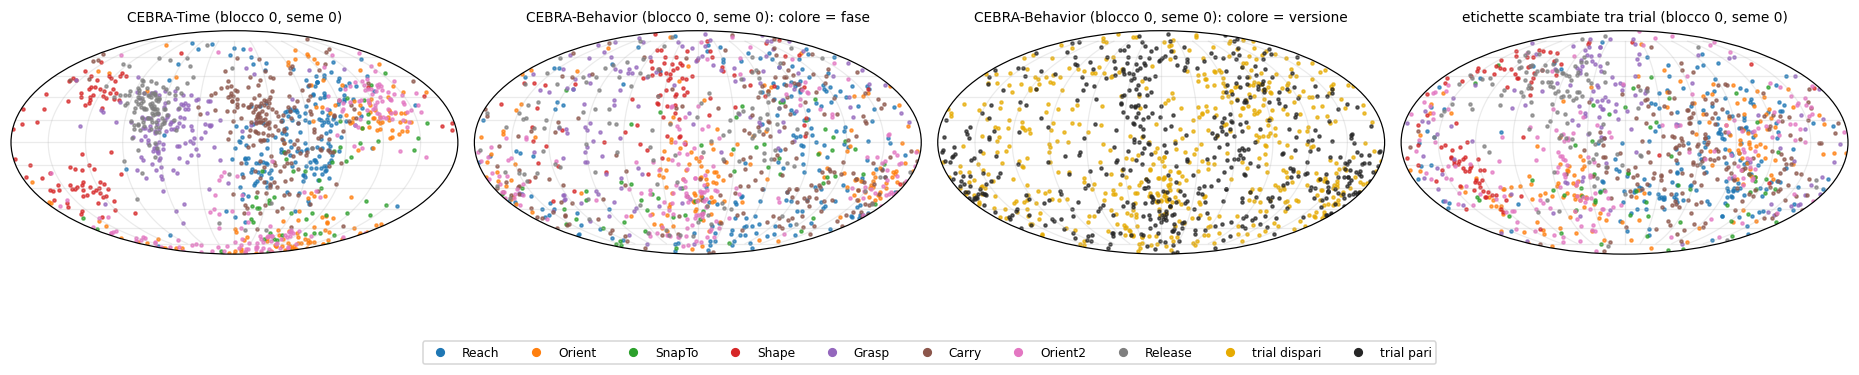

In [42]:
fig = plt.figure(figsize=(17, 3.6))
panels6 = [("CEBRA-Time (blocco 0, seme 0)", MAPS4[(3, 0, 0)], phase, io.PHASE_COLORS),
           ("CEBRA-Behavior (blocco 0, seme 0): colore = fase", MAPS6[(3, 0, 0)], phase, io.PHASE_COLORS),
           ("CEBRA-Behavior (blocco 0, seme 0): colore = versione", MAPS6[(3, 0, 0)], VERSION, {"dispari": "#e6ab02", "pari": "0.15"}),
           ("etichette scambiate tra trial (blocco 0, seme 0)", MAPS_SH[("trial", 0, 0)], phase, io.PHASE_COLORS)]
for j, (ttl, E, lab, colors) in enumerate(panels6):
    lon_, lat_ = to_lonlat(E)
    a_ = fig.add_subplot(1, 4, j + 1, projection="mollweide")
    for v_, c_ in colors.items():
        m = bins[lab[bins] == v_]
        a_.scatter(lon_[m], lat_[m], s=4, alpha=0.7, color=c_)
    a_.set_title(ttl, fontsize=9); a_.set_xticklabels([]); a_.set_yticklabels([])
handles = [plt.Line2D([], [], color=io.PHASE_COLORS[p], marker="o", ls="", ms=5, label=p) for p in io.MOVEMENT_PHASES]
handles += [plt.Line2D([], [], color=c_, marker="o", ls="", ms=5, label=f"trial {v_}") for v_, c_ in (("dispari", "#e6ab02"), ("pari", "0.15"))]
fig.legend(handles=handles, ncol=10, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIGS / "04_behavior_maps.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Etichette mescolate nel tempo** (il controllo dell'articolo): 15.1% (12.9-17.3), quasi il caso;
  la PLS 14.8%. Con etichette senza struttura CEBRA-Behavior non impara quasi nulla, come
  nell'articolo. Quindi le etichette contano.
- **Etichette scambiate tra trial**: CEBRA arriva al **29.8%** (28.1-31.3), **più che con le
  etichette vere** (25.6%), mentre la PLS scende al caso (16.4%). È il campanello d'allarme che
  cercavamo. Una spiegazione coerente con il §6.5, che però non abbiamo verificato direttamente:
  le etichette scambiate sono lisce nel tempo ma non c'entrano con quel trial, quindi la
  cinematica più vicina è di solito quella di un istante vicino **dello stesso trial**, e
  CEBRA-Behavior finisce per comportarsi come CEBRA-Time (positivi vicini nel tempo), avvicinandosi
  al suo risultato (37.7%). Con le etichette vere, invece, una parte dei positivi viene presa in
  altri trial, in momenti con una cinematica simile ma in una fase diversa, e le fasi si mescolano.
  Si potrebbe verificare contando quanti positivi cadono nello stesso trial; non l'abbiamo fatto.
- **Nelle mappe** (figura): con CEBRA-Time le fasi occupano zone distinte; con CEBRA-Behavior sono
  mescolate, e anche le due versioni lo sono; con le etichette scambiate ricompare qualche zona
  (per esempio `Shape`, in rosso).
- Il controllo dell'articolo dice che "le etichette contano"; qui contano, ma nella direzione
  sbagliata per il riconoscimento delle fasi.

### 6.5 · Perché queste etichette non aiutano a riconoscere le fasi

Due domande sulla cinematica, indipendenti da CEBRA:

1. **La cinematica si ripete da un trial all'altro?** Per ogni grado di libertà della posizione
   confrontiamo la variabilità totale (sui 1106 punti) con la variabilità tra le ripetizioni della
   stessa fase (la posizione media di ogni ripetizione, poi la deviazione standard tra le
   ripetizioni, mediata sulle fasi). Se la seconda è piccola rispetto alla prima, ogni fase ha la
   sua posizione; se è uguale, la posizione cambia da un trial all'altro più che da una fase
   all'altra.
2. **Quanto della cinematica si ricava dall'attività**, grado per grado, su trial mai visti: con
   il regressore a 10 vicini del metro comune e con una regressione lineare (*ridge*), entrambi sui
   25 PC di un solo bin. Non è il benchmark di FALCON (che usa tutti i bin e una storia di bin
   precedenti): è un controllo con gli stessi punti e gli stessi blocchi di tutto il notebook.

In [43]:
from sklearn.linear_model import Ridge                      # regressione lineare con una piccola penalità

rows_k = {}
for j, n in enumerate(io.KIN_LABELS):                       # i 7 gradi di libertà della posizione
    y_ = pd.Series(Y_KIN[bins, j])
    per_rep = y_.groupby([phase[bins], trial[bins]]).mean() # posizione media di ogni ripetizione di ogni fase
    rows_k[f"posizione {n}"] = {"variabilità totale (dev. std)": y_.std(),
                                "variabilità tra ripetizioni della stessa fase": per_rep.groupby(level=0).std().mean()}
display(pd.DataFrame(rows_k).T.round(3))

def kin_pred_r2(make_model):                                # R² di ogni grado di libertà, con un modello stimato sui punti di training di ogni blocco
    pred = np.empty((len(bins), Y_KIN.shape[1]))
    for Xtr, Xte, trn, tst in INP_PC[1]:
        pred[tst] = make_model().fit(Xtr, Y_KIN[bins[trn]]).predict(Xte)
    return r2_score(Y_KIN[bins], pred, multioutput="raw_values")

display(pd.DataFrame({"10 vicini, 25 PC": kin_pred_r2(lambda: KNeighborsRegressor(n_neighbors=K_NN)),
                      "lineare (ridge), 25 PC": kin_pred_r2(lambda: Ridge(alpha=1.0))}, index=KIN_NAMES).T.round(2))

,variabilità totale (dev. std),variabilità tra ripetizioni della stessa fase
posizione tx,0.075,0.077
posizione ty,0.111,0.114
posizione tz,0.142,0.145
posizione rx,0.525,0.514
posizione g1,0.374,0.151
posizione g2,0.393,0.145
posizione g3,0.398,0.387


,posizione tx,posizione ty,posizione tz,posizione rx,posizione g1,posizione g2,posizione g3,velocità tx,velocità ty,velocità tz,velocità rx,velocità g1,velocità g2,velocità g3
"10 vicini, 25 PC",-0.15,-0.16,-0.31,-0.25,-0.07,-0.09,-0.09,-0.14,-0.08,0.03,0.38,0.39,0.25,0.54
"lineare (ridge), 25 PC",-0.14,-0.09,-0.32,-0.16,-0.10,-0.07,-0.12,-0.07,-0.01,0.02,0.39,0.20,0.15,0.22


**Lettura.**

- **La posizione cambia da un trial all'altro più che da una fase all'altra.** Per la traslazione
  (tx, ty, tz), l'orientamento (rx) e g3 la variabilità tra ripetizioni della stessa fase è grande
  quanto quella totale (per esempio 0.514 contro 0.525 per rx). Il braccio di riferimento, cioè,
  non va nello stesso posto a ogni ripetizione, e g3 cambia con la versione. Solo g1 e g2, due
  gradi della presa, si ripetono fase per fase (0.15 contro 0.37-0.39). Non abbiamo controllato nel
  paper del dataset perché le posizioni cambino (oggetti o bersagli diversi da un trial
  all'altro?).
- **Dall'attività, la posizione non si ricava** sui trial nuovi: R² negativo per tutti i 7 gradi,
  anche con la regressione lineare. **Si ricavano invece le velocità della mano e del polso**: rx
  0.38-0.39, g1 0.20-0.39, g2 0.15-0.25, g3 0.22-0.54. Quelle della traslazione no (tra −0.14 e 0.03). È
  coerente con la posizione degli array, nell'area della mano.
- Quindi le etichette scelte mescolano ciò che l'attività codifica (le velocità di mano e polso)
  con ciò che non codifica e che non segue le fasi (le posizioni, le velocità della traslazione).
  CEBRA-Behavior viene spinto ad avvicinare momenti con una cinematica simile, che per l'attività
  e per le fasi non hanno niente in comune: la mappa peggiora.
- **La lezione**: con CEBRA-Behavior la scelta delle etichette decide quasi tutto, e un'etichetta
  "naturale" per una BCI (posizione e velocità) può essere quella sbagliata per descrivere il
  manifold. Etichette più adatte (solo la velocità, solo mano e polso, oppure le fasi) sono tra le
  prove del §7.

## 7 · Analisi di sensibilità e alternative

Cambiamo **una scelta alla volta** rispetto alla configurazione principale di CEBRA-Time (§4): 3
dimensioni sulla sfera, distanza coseno, τ = 1, rete `offset10-model` (finestra di 200 ms), Δ = 10,
1000 passi, 25 PC dei firing rate smussati, tutti i bin dei trial di training. Per ogni variante:
riconoscimento della fase con il metro comune, 5 blocchi.

**Quanti semi.** Al §4 i semi di CEBRA davano risultati lontani fino a 5 punti: con 1 o 2 semi molte
differenze tra varianti sarebbero solo rumore. Usiamo quindi **3 semi** (0, 1, 2), e come termine di
confronto la configurazione principale **con gli stessi 3 semi** (non con la media dei 5 del §4).
Differenze di 2-3 punti restano dentro il rumore.

Tre gruppi:

- **7a · il modello**: dimensioni, temperatura, finestra della rete, numero di passi, distanza;
- **7b · l'input**: 160 canali senza PCA, conteggi grezzi, fattori GPFA, solo bin di movimento;
- **7c · le etichette di CEBRA-Behavior**: solo velocità, solo velocità di mano e polso, fasi.

### 7a · Il modello

| variante | che cosa cambia | perché provarla |
|---|---|---|
| 8 e 16 dimensioni | più coordinate sulla sfera (il classificatore le usa tutte) | 3 dimensioni sono il minimo dell'articolo; con più spazio la sfera pesa meno (§2.4) |
| τ = 0.1, τ = 2.25, τ imparata | la temperatura | 2.25 è il valore dell'articolo per CEBRA-Time (Extended Data Fig. 3); 0.1 il giudice severo del §2.6; "imparata" lascia decidere alla rete (`temperature_mode="auto"`, minimo 0.1) |
| `offset1-model`, `offset5-model`, `offset36-model` | la finestra della rete: 1 bin (nessuna finestra), 5 bin (100 ms), 36 bin (720 ms, rete più profonda) | quanto conta guardare il tempo |
| 500, 2000, 5000 passi | gli allenamenti | la scelta del §3 sui trial di test (2000-5000 è il campo dell'articolo) |
| distanza euclidea | niente sfera (`offset10-model-mse`) | 3 coordinate libere invece di 2 (§2.4) |

12 varianti × 3 semi × 5 blocchi = 180 allenamenti: circa 25-30 minuti la prima volta.

In [44]:
SEEDS3 = (0, 1, 2)                                          # i semi delle analisi di sensibilità

def variant_jobs(cfg, X_full=None, train_bins=None, labels=None):  # gli allenamenti di una variante: 3 semi × 5 blocchi
    jobs = []
    for sd in SEEDS3:
        for k in range(5):
            Xk = (X25[k] if X_full is None else X_full[k]).astype(np.float32)  # input di tutta la sessione per il blocco k
            tb = TRAIN_BINS[k] if train_bins is None else train_bins[k]       # i bin su cui si allena
            j = dict(X_train=Xk[tb], X_apply=[Xk[trial == t] for t in TRIALS], cfg=cfg, seed=sd)
            if labels is not None:
                j["y_train"] = labels[k][tb]                # le etichette (solo per CEBRA-Behavior, §7c)
            jobs.append(j)
    return jobs

def run_variants(variants, fn=None):                        # tutte le varianti in un'unica coda; restituisce le 3 accuratezze di ognuna
    names, jobs = [], []
    for name, v in variants.items():
        js = variant_jobs(**v)
        jobs += js; names += [name] * len(js)
    res = run_cebra_cached(jobs, fn=fn)
    out, maps_out = {}, {}
    for name in variants:
        rs = [r for n_, r in zip(names, res) if n_ == name] # i 15 risultati della variante: seme esterno, blocco interno
        maps = {(sd, k): np.concatenate(rs[i * 5 + k]["maps"]) for i, sd in enumerate(SEEDS3) for k in range(5)}
        out[name] = [decode_map(fold_inp(lambda k, sd=sd: maps[(sd, k)]), emb_none) for sd in SEEDS3]
        maps_out[name] = maps
    return out, maps_out

MAIN = "principale (3 dimensioni, τ = 1, offset10, 1000 passi, coseno)"
VAR_A = {MAIN: dict(cfg=CEBRA_T),                           # gli stessi allenamenti del §4 (semi 0-2): si rileggono dal disco
         "8 dimensioni": dict(cfg=dict(CEBRA_T, output_dimension=8)),
         "16 dimensioni": dict(cfg=dict(CEBRA_T, output_dimension=16)),
         "τ = 0.1": dict(cfg=dict(CEBRA_T, temperature=0.1)),
         "τ = 2.25 (articolo, CEBRA-Time)": dict(cfg=dict(CEBRA_T, temperature=2.25)),
         "τ imparata (partenza 1, minimo 0.1)": dict(cfg=dict(CEBRA_T, temperature_mode="auto", min_temperature=0.1)),
         "rete senza finestra (offset1-model)": dict(cfg=dict(CEBRA_T, model_architecture="offset1-model")),
         "finestra di 100 ms (offset5-model)": dict(cfg=dict(CEBRA_T, model_architecture="offset5-model")),
         "finestra di 720 ms (offset36-model)": dict(cfg=dict(CEBRA_T, model_architecture="offset36-model")),
         "500 passi": dict(cfg=dict(CEBRA_T, max_iterations=500)),
         "2000 passi": dict(cfg=dict(CEBRA_T, max_iterations=2000)),
         "5000 passi": dict(cfg=dict(CEBRA_T, max_iterations=5000)),
         "distanza euclidea (offset10-model-mse)": dict(cfg=dict(CEBRA_T, distance="euclidean", model_architecture="offset10-model-mse"))}
ACC_A, MAPS_A = run_variants(VAR_A)
print("Controllo: la principale con i semi 0-2 coincide con il §4:",
      np.allclose(ACC_A[MAIN], ACC["CEBRA-Time, 3 dimensioni"][:3]))

def sens_table(acc, ref_name):                              # tabella: media (min-max) e differenza dalla principale, seme per seme
    ref = np.array(acc[ref_name])
    return pd.DataFrame({name: {"fase riconosciuta (%), 3 semi": mean_range(v),
                                "differenza dalla principale (punti), media": f"{np.mean(np.array(v) - ref):+.1f}",
                                "differenza, seme per seme": " ".join(f"{d_:+.1f}" for d_ in np.array(v) - ref)}
                         for name, v in acc.items()}).T

display(sens_table(ACC_A, MAIN))

Allenamenti: 0 eseguiti ora, 195 riletti dal disco


Controllo: la principale con i semi 0-2 coincide con il §4: True


,"fase riconosciuta (%), 3 semi","differenza dalla principale (punti), media","differenza, seme per seme"
"principale (3 dimensioni, τ = 1, offset10, 1000 passi, coseno)",36.1 (35.3-37.0),+0.0,+0.0 +0.0 +0.0
8 dimensioni,43.9 (42.4-45.6),+7.8,+10.3 +7.8 +5.4
16 dimensioni,42.6 (41.8-43.9),+6.5,+6.5 +8.0 +5.0
τ = 0.1,37.6 (35.2-40.5),+1.5,-0.1 +4.6 -0.0
"τ = 2.25 (articolo, CEBRA-Time)",36.2 (34.6-37.4),+0.1,+1.3 -1.3 +0.4
"τ imparata (partenza 1, minimo 0.1)",36.8 (35.7-38.1),+0.7,+0.4 +0.6 +1.1
rete senza finestra (offset1-model),35.1 (34.2-36.7),-1.0,-0.8 +0.8 -2.8
finestra di 100 ms (offset5-model),37.2 (36.2-37.9),+1.2,+2.3 +2.0 -0.8
finestra di 720 ms (offset36-model),38.6 (36.7-39.6),+2.5,+1.4 +3.5 +2.6
500 passi,36.8 (35.8-37.6),+0.7,+2.3 -0.1 -0.0


**Un confronto a parità di coordinate libere anche per le dimensioni più alte.** Una sfera in 8
dimensioni ha 7 coordinate libere, una in 16 ne ha 15: la regola del §4 chiede di confrontarle con
PCA e UMAP a d = 7 e d = 15, che finora non avevamo. Con gli stessi blocchi del metro comune e,
per UMAP, gli stessi 3 semi.

In [45]:
HI_ACC = {}                                                 # (metodo, coordinate libere) -> accuratezza (o lista di 3, una per seme)
for d, od in ((7, 8), (15, 16)):
    HI_ACC[("PCA", d)] = decode_map(INP_PC, emb_pca(d))
    HI_ACC[("UMAP", d)] = Parallel(n_jobs=3)(delayed(decode_map)(INP_PC, emb_umap(d, sd)) for sd in SEEDS3)
    HI_ACC[("CEBRA-Time", d)] = ACC_A[f"{od} dimensioni"]
display(pd.DataFrame({f"{d} coordinate libere": {m: fmt(HI_ACC[(m, d)]) for m in ("PCA", "UMAP", "CEBRA-Time")}
                      for d in (7, 15)}).T.rename(columns={"UMAP": "UMAP (3 semi)", "CEBRA-Time": "CEBRA-Time (3 semi)"}))

,PCA,UMAP (3 semi),CEBRA-Time (3 semi)
7 coordinate libere,39.0,43.3 (42.6-44.0),43.9 (42.4-45.6)
15 coordinate libere,40.7,43.6 (42.3-44.4),42.6 (41.8-43.9)


**Lettura.** La configurazione principale, con i semi 0-2, vale 36.1% (35.3-37.0): meno della media
dei 5 semi del §4 (37.7%), perché questi tre sono i semi più bassi. Per questo confrontiamo le
varianti seme per seme.

- **Il numero di dimensioni è la scelta che conta di più.** Con 8 dimensioni 43.9% (+7.8; da +5.4 a
  +10.3 a seconda del seme), con 16 42.6% (+6.5). A parità di coordinate libere CEBRA-Time vale
  UMAP (43.9% contro 43.3% con 7 coordinate; 42.6% contro 43.6% con 15) e supera la PCA (39.0% e
  40.7%). Lo svantaggio rispetto a UMAP del §4 viene quindi dalle **poche dimensioni**: con 2-3
  coordinate libere la sfera di CEBRA, che spinge i punti a coprirla tutta, comprime peggio di
  UMAP. Con più spazio i due metodi si equivalgono e arrivano entrambi al tetto delle 25 dimensioni
  (42.2%), vicino al tetto alla pari (44.9%).
- **Distanza euclidea: 40.4%** (+4.3; da +3.9 a +5.0): 3 coordinate libere invece di 2, e infatti
  lo stesso valore di CEBRA a 4 dimensioni con il coseno (40.4%, §4). La regola delle coordinate
  libere regge.
- **La temperatura non conta**, entro il rumore: τ = 0.1 +1.5 (un seme +4.6, gli altri 0), τ = 2.25
  +0.1, τ imparata +0.7. Il valore dell'articolo per CEBRA-Time (2.25) qui non cambia nulla.
- **La finestra della rete conta poco.** Senza finestra (un solo bin) −1.0; 100 ms +1.2; 720 ms
  +2.5, positivo con tutti e tre i semi. CEBRA senza finestra è quasi buono come con la finestra:
  il suo vantaggio sulla PCA (26-32% con 2-3 coordinate) non viene dal guardare 200 ms, coerente con
  il §4 (CEBRA non sfrutta l'informazione in più della finestra).
- **I passi**: 500 +0.7, 2000 +0.3, 5000 −2.0 (negativo con tutti e tre i semi). Sui trial di test si
  ritrova la scelta del §3: allenare di più peggiora.

### 7b · L'input

| variante | che cosa riceve CEBRA | perché provarla |
|---|---|---|
| 160 canali smussati | i firing rate smussati e z-scorati, **senza PCA** ("tutto in ingresso") | la rete può scegliere da sola le combinazioni di canali; la PCA potrebbe togliere informazione utile |
| 160 canali, conteggi grezzi | i conteggi a 20 ms, z-scorati, senza smoothing né PCA | l'input più grezzo: la finestra della rete può fare da smoothing |
| 25 fattori GPFA | i fattori della GPFA (02_new, §10), stimata per blocco sui soli trial di training | nel 03 era l'input migliore per Isomap e UMAP (§7.2 e §9.1) |
| solo bin di movimento | i 25 PC, ma CEBRA si allena solo sui bin di movimento dei trial di training | la scelta B del §1.4: le pause occupavano metà del film |

Per ogni input cambia anche il termine di confronto: accanto a CEBRA mettiamo il classificatore
senza mappa e UMAP con d = 2 (semi 0-2) **sullo stesso input** e sugli stessi 1106 punti.

**I fattori GPFA su tutta la sessione.** Nel 03 i fattori esistevano solo nelle finestre da 1 s
dall'inizio delle fasi (872 punti su 1106). CEBRA ha bisogno di un segnale continuo. Stimiamo la
GPFA come nel 03 (radice dei conteggi, 25 fattori, 500 iterazioni, sulle finestre da 1 s dei soli
trial di training di ogni blocco), poi calcoliamo i fattori su **tutta la sessione**, trial per
trial, a pezzi da 2 s che si sovrappongono: di ogni pezzo teniamo il secondo centrale, così ogni
bin viene da un pezzo in cui è lontano dai bordi. I fattori sono ruotati e ordinati come nel 02_new
(`orthonormalize`). Così si valutano sugli stessi 1106 punti di tutto il notebook.

4 varianti × 15 allenamenti, più 5 stime della GPFA in parallelo: circa 12-15 minuti la prima volta.

In [46]:
import contextlib, logging                                  # per silenziare i messaggi di avanzamento di elephant
from elephant.gpfa import gpfa_core                         # le funzioni di calcolo della GPFA (02_new, §10)
import elephant.utils
elephant.utils.logger.setLevel(logging.ERROR)

Zc = StandardScaler().fit_transform(s.spikes[:, ACTIVE].astype(float))  # conteggi grezzi z-scorati, 160 canali (03, §2)
Y_SQRT = np.sqrt(s.spikes[:, ACTIVE].astype(float))         # la radice dei conteggi: l'input della GPFA (02_new, §10)

def make_seqs(segs):                                        # i dati nel formato di elephant: un pezzo (inizio, fine) per riga
    return np.array([(b_ - a_, Y_SQRT[a_:b_].T) for a_, b_ in segs], dtype=[("T", int), ("y", "O")])

def fit_gpfa_fold(k):                                       # GPFA a 25 fattori sulle finestre da 1 s dei trial di training del blocco k (03, §7.2)
    train_tr = np.unique(trial[TRAIN_BINS[k]])
    np.random.seed(0)                                       # punto di partenza fisso
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        params, _ = gpfa_core.fit(make_seqs([(w["start"], w["stop"]) for w in windows if w["trial"] in train_tr]),
                                  x_dim=K_PCA, bin_width=20.0, em_max_iters=500, tau_init=100.0)
    return params

SEG, KEEP = 100, 50                                         # pezzi da 2 s (100 bin), ogni 1 s (50 bin)

def gpfa_continuous(params):                                # i 25 fattori ordinati di ogni bin della sessione, a pezzi sovrapposti dentro ogni trial
    segs, owner = [], []
    for t in TRIALS:
        a0, a1 = first_last[t][0], first_last[t][1] + 1     # inizio e fine del trial
        starts = list(range(a0, a1 - SEG + 1, KEEP))
        if starts[-1] != a1 - SEG:
            starts.append(a1 - SEG)                         # l'ultimo pezzo finisce esattamente alla fine del trial
        centers = np.array(starts) + SEG / 2
        for x in range(a0, a1):                             # ogni bin viene dal pezzo in cui è più centrale
            owner.append((x, len(segs) + int(np.argmin(np.abs(centers - x)))))
        segs += [(a_, a_ + SEG) for a_ in starts]
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(make_seqs(segs), params, get_ll=False)
        _, orth = gpfa_core.orthonormalize(params, lat)     # fattori ruotati e ordinati per importanza
    out = np.empty((n_bins, K_PCA))
    for x, i in owner:
        out[x] = orth["latent_variable_orth"][i][:, x - segs[i][0]]
    return out

GP_PARAMS = Parallel(n_jobs=5)(delayed(fit_gpfa_fold)(k) for k in range(5))  # le 5 GPFA in parallelo
X_GP = [gpfa_continuous(p_) for p_ in GP_PARAMS]            # per ogni blocco, i fattori di tutta la sessione (12233 × 25)
print(f"Fattori GPFA: {X_GP[0].shape}; bin senza valore: {int(np.isnan(np.stack(X_GP)).sum())}")

TRAIN_MOV = [tb[MOV[tb]] for tb in TRAIN_BINS]              # solo i bin di movimento dei trial di training
VAR_B = {"160 canali smussati (nessuna PCA)": dict(cfg=CEBRA_T, X_full=[Z] * 5),
         "160 canali, conteggi grezzi": dict(cfg=CEBRA_T, X_full=[Zc] * 5),
         "25 fattori GPFA": dict(cfg=CEBRA_T, X_full=X_GP),
         "solo bin di movimento (25 PC)": dict(cfg=CEBRA_T, train_bins=TRAIN_MOV)}
ACC_B, MAPS_B = run_variants(VAR_B)

REF_B = {"25 PC (principale)": INP_PC,                      # gli stessi input per il classificatore senza mappa e per UMAP
         "160 canali smussati (nessuna PCA)": fold_inp(lambda k: Z),
         "160 canali, conteggi grezzi": fold_inp(lambda k: Zc),
         "25 fattori GPFA": fold_inp(lambda k: X_GP[k])}
rows_b = {}
for name, inp in REF_B.items():
    cebra_v = ACC_A[MAIN] if name.startswith("25 PC") else ACC_B[name]
    rows_b[name] = {"CEBRA-Time, 3 dimensioni (3 semi)": mean_range(cebra_v),
                    "UMAP, d = 2 (3 semi)": mean_range([decode_map(inp, emb_umap(2, sd)) for sd in SEEDS3]),
                    "nessuna mappa (tutte le dimensioni)": f"{decode_map(inp, emb_none):.1f}"}
rows_b["solo bin di movimento (25 PC)"] = {"CEBRA-Time, 3 dimensioni (3 semi)": mean_range(ACC_B["solo bin di movimento (25 PC)"])}
display(pd.DataFrame(rows_b).T.fillna("come la riga dei 25 PC").rename_axis("input"))
display(sens_table({MAIN: ACC_A[MAIN], **ACC_B}, MAIN))

Fattori GPFA: (12233, 25); bin senza valore: 0


Allenamenti: 0 eseguiti ora, 60 riletti dal disco


,"CEBRA-Time, 3 dimensioni (3 semi)","UMAP, d = 2 (3 semi)",nessuna mappa (tutte le dimensioni)
input,,,
25 PC (principale),36.1 (35.3-37.0),41.0 (40.4-41.4),42.2
160 canali smussati (nessuna PCA),34.7 (32.9-36.0),38.0 (37.5-38.3),40.7
"160 canali, conteggi grezzi",34.0 (32.2-35.5),15.4 (14.3-16.8),16.8
25 fattori GPFA,43.1 (39.8-45.6),51.0 (50.5-51.6),50.7
solo bin di movimento (25 PC),29.4 (28.2-30.3),come la riga dei 25 PC,come la riga dei 25 PC


,"fase riconosciuta (%), 3 semi","differenza dalla principale (punti), media","differenza, seme per seme"
"principale (3 dimensioni, τ = 1, offset10, 1000 passi, coseno)",36.1 (35.3-37.0),+0.0,+0.0 +0.0 +0.0
160 canali smussati (nessuna PCA),34.7 (32.9-36.0),-1.3,+0.7 -0.6 -4.1
"160 canali, conteggi grezzi",34.0 (32.2-35.5),-2.1,+0.2 -3.7 -2.7
25 fattori GPFA,43.1 (39.8-45.6),+7.0,+4.5 +8.0 +8.6
solo bin di movimento (25 PC),29.4 (28.2-30.3),-6.7,-5.0 -7.7 -7.2


**Lettura.**

- **160 canali senza PCA** ("tutto in ingresso"): 34.7% (−1.3, entro il rumore). La PCA a 25 non
  toglie a CEBRA informazione utile; UMAP e il classificatore scendono un poco anche loro (38.0% e
  40.7%).
- **Conteggi grezzi**: CEBRA arriva al 34.0% (−2.1), quasi come con i dati smussati, mentre UMAP
  (15.4%) e il classificatore (16.8%) scendono al livello del caso. È il vero punto di forza di
  CEBRA su questi dati: la sua finestra e il gioco del tempo fanno da soli lo smoothing che a UMAP
  va dato fatto, come nel foglio sintetico del §2.4. Attenzione: il classificatore sui conteggi
  grezzi guarda un bin solo; un tetto alla pari con la finestra non l'abbiamo calcolato.
- **Fattori GPFA**: 43.1% (+7.0; da +4.5 a +8.6), l'input migliore anche per CEBRA. Ma sullo stesso
  input UMAP arriva al 51.0% e il classificatore senza mappa al 50.7%: CEBRA resta 8 punti sotto
  quello che i fattori GPFA già contengono. La GPFA calcolata su tutta la sessione ritrova i numeri
  del 03 (UMAP 50.5% e tetto 50.8% sugli 872 punti delle finestre), ora su tutti i 1106 punti.
- **Solo i bin di movimento**: 29.4% (−6.7; da −5.0 a −7.7). Le pause aiutano. Togliendole il film
  ha un salto a ogni cambio di fase, e i bin di training sono meno della metà (circa 4400 invece di
  circa 9800): non abbiamo separato le due cause.

### 7c · Le etichette di CEBRA-Behavior

Il §6.5 ha mostrato che dall'attività si ricavano le velocità di mano e polso, non le posizioni.
Proviamo quindi tre etichette diverse da "posizione + velocità" (§6), ognuna con il suo termine di
confronto lineare. Stessi parametri del §6 (1000 passi), 3 dimensioni, 3 semi.

| etichette | numeri per bin | confronto lineare |
|---|---|---|
| solo velocità | 7 | PLS con 2 componenti |
| solo velocità di mano e polso (rx, g1, g2, g3) | 4 | PLS con 2 componenti |
| fasi del task | 1 (una classe per bin: le 8 fasi di movimento, più una classe "pausa" per `Presentation` e `Intertrial`) | LDA con 2 componenti |

**Con le fasi come etichetta il test diventa quasi circolare**: la rete impara proprio a separare
le fasi, e il riconoscimento della fase sui trial di test dice solo quanto questa separazione
vale per trial mai visti. È il caso più favorevole possibile, e il suo confronto giusto è la LDA
(*linear discriminant analysis*), la proiezione lineare che separa meglio le classi.

3 varianti × 15 allenamenti: circa 5 minuti.

In [47]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis  # la proiezione lineare che separa meglio le classi

HAND = [10, 11, 12, 13]                                     # nelle 14 etichette: le velocità di rx, g1, g2, g3
PH_LAB = np.where(MOV, phase, "pausa")                      # le 8 fasi di movimento; Presentation, Intertrial (e l'unico bin senza fase) diventano "pausa"
CLASSES = sorted(set(PH_LAB))                               # 9 classi, presenti nei trial di training di ogni blocco
PH_INT = np.array([CLASSES.index(p) for p in PH_LAB], dtype=np.int64)  # la classe di ogni bin come numero intero: l'etichetta discreta di CEBRA
VAR_C = {"solo velocità (7)": dict(cfg=CEBRA_B, labels=[YZ_F[k][:, VEL] for k in range(5)]),
         "solo velocità di mano e polso (4)": dict(cfg=CEBRA_B, labels=[YZ_F[k][:, HAND] for k in range(5)]),
         "fasi del task (classi)": dict(cfg=CEBRA_B, labels=[PH_INT] * 5)}
ACC_C, MAPS_C = run_variants(VAR_C, fn=cebra_fit_beh)

lin_c = {"solo velocità (7)": [decode_map(fold_inp(lambda k: PLSRegression(n_components=2).fit(
             X25[k][TRAIN_BINS[k]], YZ_F[k][TRAIN_BINS[k]][:, VEL]).transform(X25[k])), emb_none)],
         "solo velocità di mano e polso (4)": [decode_map(fold_inp(lambda k: PLSRegression(n_components=2).fit(
             X25[k][TRAIN_BINS[k]], YZ_F[k][TRAIN_BINS[k]][:, HAND]).transform(X25[k])), emb_none)],
         "fasi del task (classi)": [decode_map(fold_inp(lambda k: LinearDiscriminantAnalysis(n_components=2).fit(
             X25[k][TRAIN_BINS[k]], PH_INT[TRAIN_BINS[k]]).transform(X25[k])), emb_none)]}
rows_c = {"posizione + velocità (14), §6": {"CEBRA-Behavior, 3 dimensioni (3 semi)": mean_range(ACC["CEBRA-Behavior, 3 dimensioni"][:3]),
                                            "confronto lineare, 2 componenti": f"{ACC['PLS, 2 componenti']:.1f} (PLS)"}}
for name in VAR_C:
    rows_c[name] = {"CEBRA-Behavior, 3 dimensioni (3 semi)": mean_range(ACC_C[name]),
                    "confronto lineare, 2 componenti": f"{lin_c[name][0]:.1f} ({'LDA' if 'fasi' in name else 'PLS'})"}
rows_c["nessuna etichetta: CEBRA-Time (principale, §7a)"] = {"CEBRA-Behavior, 3 dimensioni (3 semi)": mean_range(ACC_A[MAIN]),
                                                            "confronto lineare, 2 componenti": f"{ACC['PCA, d = 2']:.1f} (PCA)"}
display(pd.DataFrame(rows_c).T.rename_axis("etichette"))

Allenamenti: 0 eseguiti ora, 45 riletti dal disco


,"CEBRA-Behavior, 3 dimensioni (3 semi)","confronto lineare, 2 componenti"
etichette,,
"posizione + velocità (14), §6",25.3 (22.4-27.9),27.3 (PLS)
solo velocità (7),31.5 (30.3-33.0),25.4 (PLS)
solo velocità di mano e polso (4),30.2 (29.3-31.6),26.0 (PLS)
fasi del task (classi),32.7 (31.3-33.5),43.2 (LDA)
"nessuna etichetta: CEBRA-Time (principale, §7a)",36.1 (35.3-37.0),26.0 (PCA)


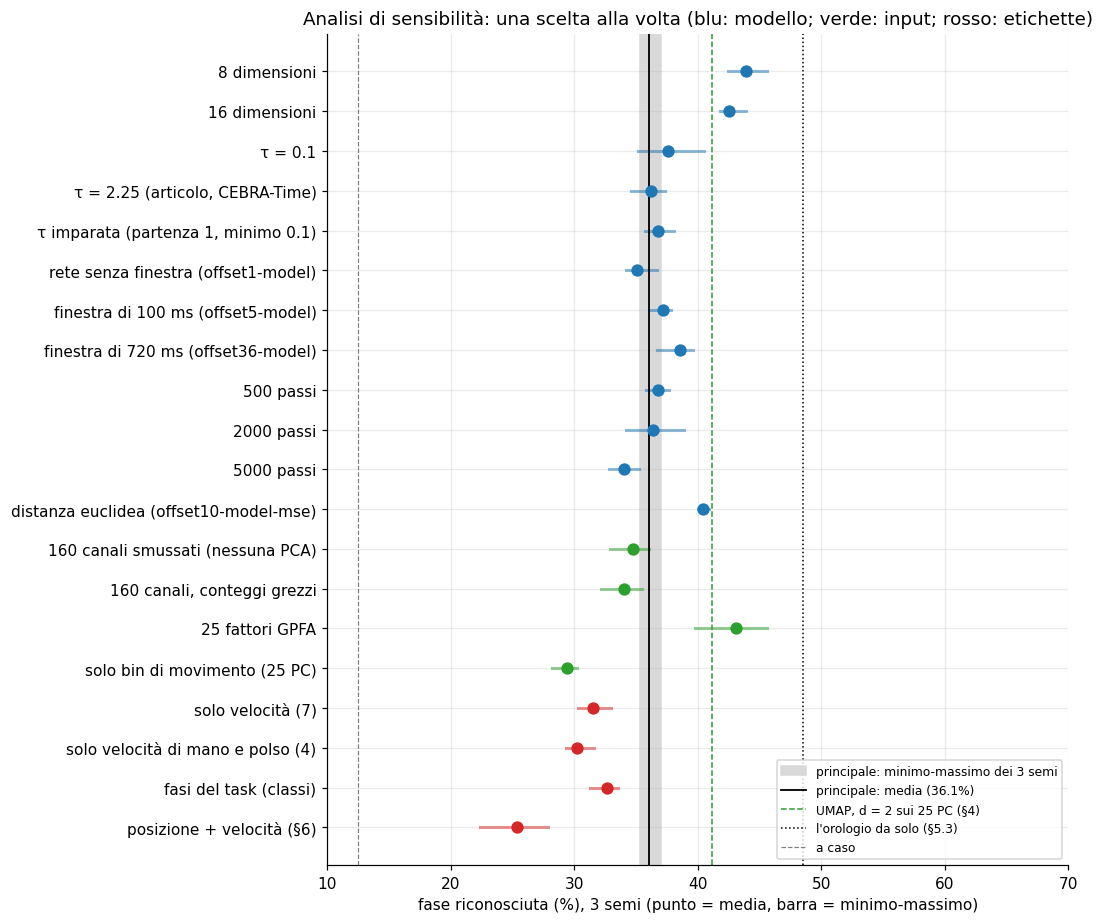

In [48]:
ALL_SENS = [("7a · modello", n_, v_) for n_, v_ in ACC_A.items() if n_ != MAIN] + \
           [("7b · input", n_, v_) for n_, v_ in ACC_B.items()] + \
           [("7c · etichette (CEBRA-Behavior)", n_, v_) for n_, v_ in ACC_C.items()] + \
           [("7c · etichette (CEBRA-Behavior)", "posizione + velocità (§6)", ACC["CEBRA-Behavior, 3 dimensioni"][:3])]
ref = np.array(ACC_A[MAIN])
fig, ax = plt.subplots(figsize=(10, 8.5))
for yi, (grp, name, v) in enumerate(ALL_SENS[::-1]):
    v = np.array(v)
    col = {"7a · modello": "C0", "7b · input": "C2", "7c · etichette (CEBRA-Behavior)": "C3"}[grp]
    ax.plot([v.min(), v.max()], [yi, yi], color=col, lw=2, alpha=0.5)  # minimo-massimo tra i 3 semi
    ax.scatter(v.mean(), yi, color=col, s=50, zorder=3)
ax.axvspan(ref.min(), ref.max(), color="0.85", zorder=0, label="principale: minimo-massimo dei 3 semi")
ax.axvline(ref.mean(), color="k", lw=1.2, label=f"principale: media ({ref.mean():.1f}%)")
ax.axvline(np.mean(ACC["UMAP, d = 2"]), color="C2", ls="--", lw=1,
           label="UMAP, d = 2 sui 25 PC (§4)")
ax.axvline(ACC["l'orologio da solo (1 numero)"], color="k", ls=":", lw=1, label="l'orologio da solo (§5.3)")
ax.axvline(12.5, color="0.5", ls="--", lw=0.8, label="a caso")
ax.set(yticks=range(len(ALL_SENS)), yticklabels=[f"{n_}" for _, n_, _ in ALL_SENS[::-1]], xlim=(10, 70),
       xlabel="fase riconosciuta (%), 3 semi (punto = media, barra = minimo-massimo)",
       title="Analisi di sensibilità: una scelta alla volta (blu: modello; verde: input; rosso: etichette)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "04_sensitivity.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Nessuna delle etichette provate fa meglio di CEBRA-Time senza etichette** (36.1%):
  CEBRA-Behavior con posizione + velocità 25.3%, con le sole velocità 31.5%, con le velocità di
  mano e polso 30.2%, con le fasi 32.7%.
- **Togliere le posizioni fa guadagnare 6 punti** (da 25.3% a 31.5%), come ci si aspettava dal
  §6.5: per le fasi le posizioni sono rumore. Tenere solo mano e polso non aggiunge altro (30.2%).
  Le velocità da sole non bastano a distinguere le fasi: diverse fasi hanno velocità simili (per
  esempio quelle in cui la mano è ferma).
- **Con le fasi come etichetta, CEBRA-Behavior arriva solo al 32.7%**: meno che senza etichette,
  anche se l'etichetta è proprio quella da riconoscere. La LDA, con le stesse etichette e una
  semplice proiezione lineare, arriva al **43.2%**: 10 punti di più, e più di UMAP con 2 coordinate
  (41.2%). Una spiegazione probabile, non verificata: con le classi CEBRA avvicina tutti gli istanti
  della stessa fase nei trial di training e impara anche ciò che è specifico di quei trial
  (l'overfitting del §3 e del §6.2), mentre la LDA, con pochi parametri, generalizza meglio. I 1000
  passi, inoltre, erano stati scelti con le etichette continue: per le classi non li abbiamo
  ricontrollati.
- La PLS con le velocità (25.4% e 26.0%) vale quanto la PCA con 2 componenti (26.0%).

**Nella figura** le tre famiglie di prove in un colpo d'occhio: tra le scelte del modello solo le
dimensioni (e la distanza euclidea, che è un modo di avere più coordinate libere) spostano davvero
il risultato; tra gli input, i fattori GPFA in su e il solo movimento in giù; tutte le etichette in
giù. Nessuna variante supera l'orologio (48.5%).

## 8 · Riepilogo di CEBRA

### Le scelte

| passo | scelta | perché | alternative (dove) |
|---|---|---|---|
| dati e valutazione | gli stessi del 03: 1106 punti (fasi di movimento, uno ogni 100 ms), 5 blocchi da 3 trial, classificatore a 10 vicini, accuratezza bilanciata | confrontare CEBRA con tutto il resto con la stessa misura; i numeri del 03 si riproducono al decimale | — (§1.2) |
| input | 25 PC dei firing rate smussati (σ = 50 ms), PCA stimata sui soli trial di training | lo stesso input di PCA, Isomap e UMAP nel 03 | 160 canali, conteggi grezzi, fattori GPFA (§7b) |
| bin di allenamento | tutti i bin dei trial di training, pause comprese | CEBRA-Time ha bisogno di un "film" continuo | solo bin di movimento (§7b) |
| giunte tra trial non consecutivi | accettate | toccano al massimo lo 0.3% delle coppie | — (§1.5) |
| rete | `offset10-model`: finestra di 200 ms centrata | articolo (ippocampo, S1, Allen 2P) | nessuna finestra, 100 ms, 720 ms (§7a) |
| Δ (coppie positive) | 10 bin, 200 ms | articolo | 20 ms, 1 s (§5.3) |
| temperatura | τ = 1 | valore predefinito; la stessa per CEBRA-Time e CEBRA-Behavior | 0.1, 2.25 (articolo, CEBRA-Time), imparata (§7a) |
| passi | 1000 | validazione su due coppie di trial (12-15 e 6-7), regola fissata prima di guardare | 500-20 000 (§3.2, §6.2, §7a) |
| dimensioni | 3 e 4 sulla sfera, cioè 2 e 3 coordinate libere | confronto a parità di coordinate libere con il 03 | 8 e 16 (§7a) |
| distanza | coseno | articolo | euclidea (§2.4, §7a) |
| seme | corretto nella libreria (`HasGenerator`) | CEBRA 0.6.0 ignora il seme che gli si dà | — (§2.7) |
| ripetizioni | 5 semi (3 nelle analisi di sensibilità) | le mappe cambiano molto da un seme all'altro | — (§5.2) |
| etichette di CEBRA-Behavior | posizione + velocità, 14 numeri z-scorati (scelta dell'utente) | la variabile che una BCI deve ricavare | solo velocità, mano e polso, fasi (§7c) |
| confronto lineare con le etichette | PLS (cinematica), LDA (fasi) | stesso input e stesse etichette di CEBRA-Behavior | — (§6.3, §7c) |

### Alternative provate in questo notebook

| che cosa | valori provati | effetto | dove |
|---|---|---|---|
| funzione di costo a mano | InfoNCE con la formula di CEBRA e con quella originale, contro la libreria | identica alla libreria (differenza 5·10⁻⁷); la formula originale cambia di 0.004 | §2.5 |
| sfera, sul foglio sintetico | coseno a 3 e 4 dimensioni, euclidea a 3 | a 3 dimensioni la sfera richiude il foglio (R² della lunghezza −0.21); con 3 coordinate libere 0.58-0.61; media mobile + PCA 0.93 | §2.4 |
| seme | con e senza correzione | senza: mappe diverse a ogni esecuzione; con: identiche bit per bit | §2.7 |
| PCA nella validazione | vista o non vista dai trial di validazione | 40-42% contro 28-29% della varianza dei trial di validazione: la scorciatoia c'era, corretta | §3.2 |
| passi (validazione) | 1-20 000, due coppie di trial, due semi | minimo a 500-1000 passi, poi overfitting | §3.2, §6.2 |
| classificatore sulla sfera | distanza in linea d'aria contro coseno | previsioni identiche | §4.1 |
| tetto alla pari | finestra di 200 ms in fila (250 numeri), media sulla finestra (25) | 43.9% e 44.9%, contro 42.2% senza finestra | §4.1 |
| consistenza per versione del task | dispari e pari separati | più alta per tutti i metodi; l'ordine non cambia | §4.2 |
| gemello a fasi casuali | 5 gemelli × 5 blocchi | CEBRA al caso (12.5%) | §5.1 |
| consistenza tra semi | R² dopo allineamento lineare | CEBRA 63-75%, UMAP 87-93% | §5.2 |
| catena del tempo | composizione dei vicini; Δ = 1, 10, 50 | catena 8% (input 20%); Δ = 10 il migliore | §5.3 |
| orologio | tempo dall'inizio del trial, da solo e dentro le mappe | da solo 48.5%; le mappe non lo contengono; riconosce le fasi del braccio, le mappe quelle della mano | §5.3 |
| CEBRA-Behavior, controlli | etichette mescolate nel tempo, scambiate tra trial | 15.1% e 29.8% (vere: 25.6%) | §6.4 |
| cinematica | ripetibilità delle posizioni; cinematica ricavata dall'attività | posizioni diverse da trial a trial; si ricavano solo le velocità di mano e polso | §6.5 |
| dimensioni | 8, 16 | +7.8 e +6.5 punti; a parità di coordinate libere CEBRA = UMAP | §7a |
| temperatura, finestra, passi | τ 0.1, 2.25, imparata; 1, 5, 36 bin; 500, 2000, 5000 passi | entro il rumore, tranne 5000 passi (−2.0) e 36 bin (+2.5) | §7a |
| distanza euclidea | `offset10-model-mse` | +4.3 (3 coordinate libere invece di 2) | §7a |
| input | 160 canali, conteggi grezzi, fattori GPFA, solo movimento | −1.3, −2.1 (UMAP al caso), +7.0 (UMAP 51.0%), −6.7 | §7b |
| etichette di CEBRA-Behavior | solo velocità, mano e polso, fasi | 31.5%, 30.2%, 32.7%: tutte sotto CEBRA-Time; LDA con le fasi 43.2% | §7c |

### La tabella finale: tutti i metodi, la stessa misura

Costruita dal codice con i numeri calcolati in questo notebook. Per la GPFA usiamo i suoi primi
fattori (ordinati per importanza, come le componenti della PCA), stimati per blocco sui soli trial
di training e calcolati su tutta la sessione (§7b); le misure delle sue traiettorie vengono dal 03
(§6.1) e dal 02_new (§10.5). Dove c'è un intervallo: media (minimo-massimo) tra i semi.

In [49]:
GP_ACC = {d: decode_map(fold_inp(lambda k, d=d: X_GP[k][:, :d]), emb_none) for d in (2, 3, 7)}  # la GPFA con i suoi primi d fattori
LDA3 = decode_map(fold_inp(lambda k: LinearDiscriminantAnalysis(n_components=3).fit(
    X25[k][TRAIN_BINS[k]], PH_INT[TRAIN_BINS[k]]).transform(X25[k])), emb_none)  # la LDA con 3 componenti

def row(name, lab, a2=None, a3=None, a7=None):              # una riga della tabella finale
    return {"metodo": name, "etichette": lab, "2 coordinate libere": fmt(a2) if a2 is not None else "",
            "3 coordinate libere": fmt(a3) if a3 is not None else "", "7 coordinate libere": fmt(a7) if a7 is not None else ""}

final_dec = pd.DataFrame([
    row("PCA", "no", ACC["PCA, d = 2"], ACC["PCA, d = 3"], HI_ACC[("PCA", 7)]),
    row("Isomap", "no", ACC["Isomap, d = 2"], ACC["Isomap, d = 3"]),
    row("UMAP", "no", ACC["UMAP, d = 2"], ACC["UMAP, d = 3"], HI_ACC[("UMAP", 7)]),
    row("GPFA (primi fattori)", "no", GP_ACC[2], GP_ACC[3], GP_ACC[7]),
    row("CEBRA-Time (3, 4 e 8 dimensioni)", "no", ACC["CEBRA-Time, 3 dimensioni"], ACC["CEBRA-Time, 4 dimensioni"], HI_ACC[("CEBRA-Time", 7)]),
    row("CEBRA-Behavior, posizione + velocità", "sì", ACC["CEBRA-Behavior, 3 dimensioni"], ACC["CEBRA-Behavior, 4 dimensioni"]),
    row("PLS, posizione + velocità", "sì", ACC["PLS, 2 componenti"], ACC["PLS, 3 componenti"]),
    row("CEBRA-Behavior, fasi (3 semi)", "sì (le fasi)", ACC_C["fasi del task (classi)"]),
    row("LDA, fasi", "sì (le fasi)", lin_c["fasi del task (classi)"][0], LDA3),
]).set_index("metodo")
display(final_dec)

refs = pd.Series({"a caso": "12.5",
                  "nessuna mappa: 25 PC di un bin (il tetto del 03)": f"{ACC['tetto, 25 dimensioni']:.1f}",
                  "nessuna mappa: 25 PC, media su 200 ms (tetto alla pari)": f"{ACC['tetto alla pari: media sulla finestra (25 numeri)']:.1f}",
                  "nessuna mappa: 25 fattori GPFA": rows_b["25 fattori GPFA"]["nessuna mappa (tutte le dimensioni)"],
                  "UMAP, d = 2, sui fattori GPFA (3 semi)": rows_b["25 fattori GPFA"]["UMAP, d = 2 (3 semi)"],
                  "CEBRA-Time, 3 dimensioni, sui fattori GPFA (3 semi)": mean_range(ACC_B["25 fattori GPFA"]),
                  "l'orologio da solo (nessun dato neurale)": f"{acc_clock:.1f}"},
                 name="fase riconosciuta (%)")
display(refs.to_frame())

def tstat(name, col):                                       # una misura delle traiettorie (§4.2): media (min-max) tra i semi
    v = np.array([r_[col] for r_ in TRAJ[name]])
    return f"{v.mean():.3f}" if len(v) == 1 else f"{v.mean():.3f} ({v.min():.3f}-{v.max():.3f})"

final_traj = pd.DataFrame({
    name: {"seghettatura": tstat(name, "seghettatura"), "consistenza": tstat(name, "consistenza, tutte le ripetizioni"),
           "consistenza per versione": tstat(name, "consistenza per versione (media delle due)"),
           "consistenza tra semi (R², %)": c_}
    for name, c_ in (("PCA", "100 (per costruzione)"), ("Isomap", "100 (per costruzione)"),
                     ("UMAP", mean_range(cons["UMAP, d = 3"] * 100) + " (d = 3)"),
                     ("CEBRA-Time, 3 dimensioni", mean_range(cons["CEBRA-Time, 3 dimensioni (stimato su tutti i trial)"] * 100)),
                     ("CEBRA-Time, 4 dimensioni", mean_range(cons["CEBRA-Time, 4 dimensioni (stimato su tutti i trial)"] * 100)))}).T
final_traj.loc["GPFA (dal 03 e dal 02_new)"] = ["0.011", "0.11", "non calcolata", "non calcolata"]
display(final_traj)

,etichette,2 coordinate libere,3 coordinate libere,7 coordinate libere
metodo,,,,
PCA,no,26.0,32.4,39.0
Isomap,no,31.8,36.0,
UMAP,no,41.2 (40.4-42.3),42.6 (41.9-43.2),43.3 (42.6-44.0)
GPFA (primi fattori),no,31.1,33.8,45.3
"CEBRA-Time (3, 4 e 8 dimensioni)",no,37.7 (35.3-40.6),40.4 (38.5-42.7),43.9 (42.4-45.6)
"CEBRA-Behavior, posizione + velocità",sì,25.6 (22.4-27.9),28.7 (27.3-30.1),
"PLS, posizione + velocità",sì,27.3,28.3,
"CEBRA-Behavior, fasi (3 semi)",sì (le fasi),32.7 (31.3-33.5),,
"LDA, fasi",sì (le fasi),43.2,45.8,


,fase riconosciuta (%)
a caso,12.5
nessuna mappa: 25 PC di un bin (il tetto del 03),42.2
"nessuna mappa: 25 PC, media su 200 ms (tetto alla pari)",44.9
nessuna mappa: 25 fattori GPFA,50.7
"UMAP, d = 2, sui fattori GPFA (3 semi)",51.0 (50.5-51.6)
"CEBRA-Time, 3 dimensioni, sui fattori GPFA (3 semi)",43.1 (39.8-45.6)
l'orologio da solo (nessun dato neurale),48.5


,seghettatura,consistenza,consistenza per versione,"consistenza tra semi (R², %)"
PCA,0.013,0.088,0.109,100 (per costruzione)
Isomap,0.275,0.095,0.122,100 (per costruzione)
UMAP,0.596 (0.571-0.628),0.125 (0.110-0.134),0.144 (0.137-0.152),93.3 (87.5-99.2) (d = 3)
"CEBRA-Time, 3 dimensioni",0.080 (0.068-0.099),0.089 (0.069-0.105),0.106 (0.089-0.113),63.4 (46.9-83.1)
"CEBRA-Time, 4 dimensioni",0.074 (0.066-0.080),0.106 (0.086-0.127),0.122 (0.091-0.141),75.1 (66.8-83.9)
GPFA (dal 03 e dal 02_new),0.011,0.11,non calcolata,non calcolata


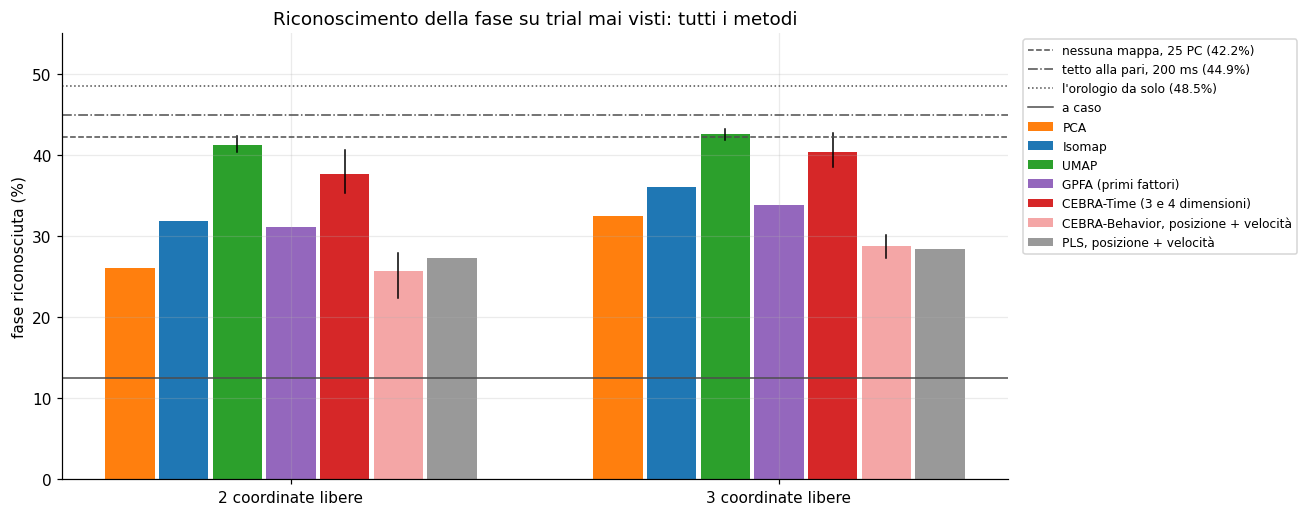

In [50]:
METH = ["PCA", "Isomap", "UMAP", "GPFA (primi fattori)", "CEBRA-Time (3, 4 e 8 dimensioni)",
        "CEBRA-Behavior, posizione + velocità", "PLS, posizione + velocità"]
VALS = {"PCA": [ACC["PCA, d = 2"], ACC["PCA, d = 3"]], "Isomap": [ACC["Isomap, d = 2"], ACC["Isomap, d = 3"]],
        "UMAP": [ACC["UMAP, d = 2"], ACC["UMAP, d = 3"]], "GPFA (primi fattori)": [GP_ACC[2], GP_ACC[3]],
        "CEBRA-Time (3, 4 e 8 dimensioni)": [ACC["CEBRA-Time, 3 dimensioni"], ACC["CEBRA-Time, 4 dimensioni"]],
        "CEBRA-Behavior, posizione + velocità": [ACC["CEBRA-Behavior, 3 dimensioni"], ACC["CEBRA-Behavior, 4 dimensioni"]],
        "PLS, posizione + velocità": [ACC["PLS, 2 componenti"], ACC["PLS, 3 componenti"]]}
COLS8 = {"PCA": "C1", "Isomap": "C0", "UMAP": "C2", "GPFA (primi fattori)": "C4", "CEBRA-Time (3, 4 e 8 dimensioni)": "C3",
         "CEBRA-Behavior, posizione + velocità": "#f4a6a6", "PLS, posizione + velocità": "0.6"}
fig, ax = plt.subplots(figsize=(12, 4.8))
w = 0.11
for i, m in enumerate(METH):
    for j, v in enumerate(VALS[m]):                         # j = 0: 2 coordinate libere; j = 1: 3 coordinate libere
        v = np.atleast_1d(v)
        x = j + (i - (len(METH) - 1) / 2) * w
        ax.bar(x, v.mean(), width=w * 0.92, color=COLS8[m], label=(m.replace(" (3, 4 e 8 dimensioni)", " (3 e 4 dimensioni)")
                                                                  if j == 0 else None))
        if len(v) > 1:
            ax.plot([x, x], [v.min(), v.max()], color="k", lw=1)  # minimo-massimo tra i semi
for yv, lab, ls in ((ACC["tetto, 25 dimensioni"], "nessuna mappa, 25 PC (42.2%)", "--"),
                    (ACC["tetto alla pari: media sulla finestra (25 numeri)"], "tetto alla pari, 200 ms (44.9%)", "-."),
                    (ACC["l'orologio da solo (1 numero)"], "l'orologio da solo (48.5%)", ":"), (12.5, "a caso", "-")):
    ax.axhline(yv, color="0.3", ls=ls, lw=1, label=lab)
ax.set(xticks=[0, 1], xticklabels=["2 coordinate libere", "3 coordinate libere"], ylim=(0, 55),
       ylabel="fase riconosciuta (%)", title="Riconoscimento della fase su trial mai visti: tutti i metodi")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig(FIGS / "04_summary.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **A parità di coordinate libere, tra i metodi senza etichette** UMAP è il migliore con 2-3
  coordinate (41.2% e 42.6%), CEBRA-Time il secondo (37.7% e 40.4%), poi Isomap (31.8% e 36.0%), i
  primi fattori della GPFA (31.1% e 33.8%) e la PCA (26.0% e 32.4%). Con 7 coordinate la GPFA sale
  al 45.3%, sopra UMAP (43.3%) e CEBRA (43.9%): i fattori della GPFA distribuiscono l'informazione
  sulle fasi su più dimensioni. PCA, Isomap, UMAP e CEBRA ricevono i 25 PC; la GPFA parte dalla
  radice dei conteggi.
- **Con le etichette**: con la cinematica, CEBRA-Behavior e la PLS (25.6-28.7%) stanno sotto tutti i
  metodi senza etichette, tranne la PCA con 2 componenti. Con le fasi la **LDA** è la migliore della
  tabella: 43.2% con 2 componenti e 45.8% con 3, al livello del tetto alla pari (44.9%);
  CEBRA-Behavior, con le stesse etichette, 32.7%.
- **I termini di confronto**: sui 25 PC nessun metodo senza etichette supera il tetto alla pari
  (44.9%). L'input migliore resta quello dei fattori GPFA (classificatore 50.7%, UMAP 51.0%).
  L'orologio, senza nessun dato neurale, sta a 48.5%, sopra ogni metodo sui 25 PC.
- **Traiettorie e stabilità**: PCA e GPFA sono le più lisce (0.01), CEBRA è nel mezzo (0.07-0.08),
  Isomap e UMAP saltano (0.3-0.6). La consistenza tra ripetizioni è più alta per UMAP (0.125; 0.144
  per versione); CEBRA a 4 dimensioni, GPFA e Isomap stanno tra 0.095 e 0.11, PCA e CEBRA a 3
  dimensioni intorno a 0.09. CEBRA è il meno stabile da un seme all'altro (63-75%, contro 87-93%
  di UMAP).
- **In una frase**: su questa sessione CEBRA-Time è un buon metodo senza etichette, tra Isomap e
  UMAP con poche dimensioni e pari a UMAP con più dimensioni, con traiettorie più lisce di UMAP ma
  mappe meno stabili; CEBRA-Behavior, con le etichette provate, non batte i suoi termini di
  confronto lineari.

### Che cosa abbiamo imparato su CEBRA

1. **Con 2-3 coordinate libere CEBRA-Time sta tra Isomap e UMAP**: 37.7% e 40.4% contro 41.2% e
   42.6% di UMAP (§4). Lo svantaggio viene dalla sfera e dalle poche dimensioni: con 7 coordinate
   libere CEBRA-Time vale UMAP (43.9% contro 43.3%) e arriva al tetto delle 25 dimensioni (§7a).
   Non aggiunge informazione: non usa nemmeno quella in più della sua finestra di 200 ms (tetto
   alla pari 44.9%, §4.1; senza finestra quasi lo stesso risultato, §7a).
2. **Impara davvero l'attività legata al task**: sul gemello a fasi casuali scende al caso (§5.1),
   tra i vicini della sua mappa la catena del tempo pesa meno che nei dati (8% contro 20%), e la
   mappa non contiene l'orologio (§5.3). Come gli altri metodi, riconosce soprattutto le fasi della
   mano.
3. **Con pochi dati va in overfitting subito**: 1000 passi, contro i 4000-10 000 dell'articolo, e
   allenare di più peggiora anche sui trial di test (§3.2, §6.2, §7a). La validazione va fatta su
   trial a parte e con un input che non li abbia visti: anche la PCA a 25 si adatta ai trial su cui
   è stimata (§3.2).
4. **È instabile**: tra un seme e l'altro l'accuratezza cambia fino a 5 punti e le mappe si
   somigliano molto meno di quelle di UMAP (R² 63-75% contro 87-93%, §5.2). Una mappa di CEBRA non
   si interpreta da sola.
5. **Le traiettorie sono lisce, ma non quanto quelle dei metodi lineari** (seghettatura 0.07-0.08
   contro 0.01 di PCA e GPFA, 0.6 di UMAP); la consistenza è come quella di PCA e GPFA, sotto UMAP
   (§4.2).
6. **Il suo punto di forza su questi dati sono i conteggi grezzi**: senza smoothing CEBRA perde 2
   punti, UMAP crolla al caso (§7b). Il punto debole: sull'input migliore, i fattori GPFA, resta 8
   punti sotto il semplice classificatore su quei fattori (43.1% contro 50.7%).
7. **CEBRA-Behavior dipende tutto dalle etichette, e qui nessuna aiuta.** Con posizione + velocità
   peggiora (25.6%): le posizioni di riferimento cambiano da un trial all'altro e l'attività non le
   codifica (§6.5). Con le sole velocità, con mano e polso o con le fasi resta sotto CEBRA-Time; con
   le fasi la LDA, lineare, fa 10 punti meglio (§7c). Il confronto giusto per CEBRA-Behavior è il
   metodo lineare con le stesse etichette, e su questa sessione CEBRA-Behavior non lo batte.
8. **Il riconoscimento della fase ha un termine di confronto "senza neuroni" molto alto**: sapere
   da quanto è cominciato il trial basta per il 48.5% (§5.3), più di qualunque mappa. Le mappe
   riconoscono le fasi della mano, l'orologio quelle del braccio.

### Che cosa non abbiamo verificato

- **Una sola sessione**, e i parametri cambiati uno alla volta, mai in combinazione (per esempio
  fattori GPFA + 8 dimensioni).
- I parametri dell'articolo letti nelle parti accessibili del testo completo: passo di
  apprendimento e ottimizzatore non vi compaiono per questi dati.
- La riproducibilità esatta vale su questo computer, con queste versioni (cebra 0.6.0, torch
  2.7.1, GPU del Mac); su altre macchine fanno fede i modelli salvati.
- Perché le mappe di CEBRA cambino tanto tra semi (§5.2), perché CEBRA-Behavior con le fasi
  generalizzi male (§7c; i 1000 passi non sono stati ricontrollati per le classi), perché le
  etichette scambiate tra trial diano un risultato migliore di quelle vere (§6.4; i positivi non
  sono stati contati), perché le posizioni cambino da un trial all'altro (§6.5).
- Il gemello è gaussiano (§5.1); il tetto alla pari sui conteggi grezzi non è stato calcolato
  (§7b); il benchmark di FALCON (decodifica della velocità) non è stato rifatto.

> **Regola per la tesi.** Un risultato di CEBRA va riportato con: la versione (Time o Behavior, e
> con quali etichette), il numero di dimensioni **e di coordinate libere**, come è stato scelto il
> numero di passi, i semi (media e minimo-massimo) e la consistenza tra semi, il confronto a parità
> di coordinate libere (PCA, UMAP) e, per CEBRA-Behavior, il metodo lineare con le stesse
> etichette. Per il riconoscimento della fase, anche l'orologio. Per esempio: *"CEBRA-Time
> (offset10-model, Δ = 200 ms, τ = 1, 1000 passi scelti su trial di validazione, distanza coseno)
> su 25 PC dei firing rate smussati (σ = 50 ms): fase riconosciuta su trial mai visti 37.7% con 3
> dimensioni, cioè 2 coordinate libere (35.3-40.6 su 5 semi), contro 41.2% di UMAP con d = 2;
> consistenza tra semi R² = 63%; sul gemello a fasi casuali 12.5%; l'orologio da solo 48.5%"*.

### Riferimenti

- Schneider, S., Lee, J. H., Mathis, M. W. (2023). Learnable latent embeddings for joint
  behavioural and neural analysis. *Nature*, 617, 360–368. (Testo completo: PubMed Central,
  PMC10172131.)
- van den Oord, A., Li, Y., Vinyals, O. (2018). Representation learning with contrastive
  predictive coding. *arXiv*:1807.03748.
- Hyvärinen, A., Morioka, H. (2016). Unsupervised feature extraction by time-contrastive learning
  and nonlinear ICA. *Advances in Neural Information Processing Systems*, 29.
- Wang, T., Isola, P. (2020). Understanding contrastive representation learning through alignment
  and uniformity on the hypersphere. *Proceedings of the 37th International Conference on Machine
  Learning* (PMLR 119).
- McInnes, L., Healy, J., Melville, J. (2018). UMAP: Uniform Manifold Approximation and Projection
  for dimension reduction. *arXiv*:1802.03426.
- Tenenbaum, J. B., de Silva, V., Langford, J. C. (2000). A global geometric framework for
  nonlinear dimensionality reduction. *Science*, 290(5500), 2319–2323.
- Yu, B. M., et al. (2009). Gaussian-process factor analysis for low-dimensional single-trial
  analysis of neural population activity. *Journal of Neurophysiology*, 102, 614–635.
- Theiler, J., Eubank, S., Longtin, A., Galdrikian, B., Farmer, J. D. (1992). Testing for
  nonlinearity in time series: the method of surrogate data. *Physica D*, 58, 77–94.
- Prichard, D., Theiler, J. (1994). Generating surrogate data for time series with several
  simultaneously measured variables. *Physical Review Letters*, 73(7), 951–954.
- Wold, S., Sjöström, M., Eriksson, L. (2001). PLS-regression: a basic tool of chemometrics.
  *Chemometrics and Intelligent Laboratory Systems*, 58, 109–130.
- Fisher, R. A. (1936). The use of multiple measurements in taxonomic problems. *Annals of
  Eugenics*, 7, 179–188.

---
# Parte B · LFADS

**LFADS in una frase.** *Latent Factor Analysis via Dynamical Systems* (Pandarinath et al. 2018) è
un modello che, come la GPFA (02_new, §10), parte dai **conteggi** di ogni trial e restituisce
**traiettorie lisce** di pochi fattori. La differenza: la GPFA sa solo che i fattori "non fanno
salti" (una regola generica, uguale per tutti i momenti), LFADS **impara le regole del moto**: da
dove si trova lo stato adesso, dove andrà dopo. È la differenza tra sapere che un'auto non si
teletrasporta e conoscere la strada che sta percorrendo. Nella review è il modello dinamico del §2.6
(equazione 3) reso concreto con una rete ricorrente (§4.2); al §5.5 è citato per la decodifica nelle
interfacce cervello-computer.

LFADS è la **"GPFA non lineare"**: le regole del moto sono una rete neurale (non lineare), e il
legame tra fattori e frequenze di sparo passa per un esponenziale. Allo stesso modo, una rete che
guarda un bin alla volta, senza regole del moto, sarebbe la "FA non lineare": la proviamo al §14.

**A differenza di CEBRA, LFADS è un modello generativo vero.** Ha tutte e due le metà: dai dati ai
fattori (l'*encoder*) e dai fattori ai dati (il *generatore* con la sua uscita), e assegna una
probabilità a ogni possibile sequenza di conteggi. Per questo può produrre trial finti (§11) e si
può giudicare su quanto bene **predice dati mai visti** (§12), cosa che per CEBRA non ha senso.

**La domanda della parte B.** Su questi dati, la non linearità e la dinamica imparata migliorano le
traiettorie single-trial rispetto alla GPFA? Il confronto principale è **LFADS contro GPFA alla
pari**: stessi conteggi, stessi pezzi di registrazione, stesso numero di fattori (25).

**Le scelte concordate prima di cominciare:**

| scelta | decisione | alternativa (dove) |
|---|---|---|
| codice | un LFADS piccolo scritto a mano per capire (§10), la libreria `lfads-torch` (Sedler & Pandarinath 2023) per gli allenamenti veri, con un ciclo di allenamento scritto qui | il `Trainer` di Lightning della libreria (richiede una correzione, §10) |
| dati | la sola sessione di riferimento, come in tutti i notebook | le altre due sessioni dello stesso giorno (§14) |
| taglio | pezzi da 600 ms sovrapposti di 200 ms, dentro ogni trial, ricuciti con pesi graduali (§9.2) | 400 ms e 1 s (§14) |
| ingressi esterni (*controller*) | no | sì (§14) |

**Due limiti da dichiarare subito.**

- **Pochi dati.** Una rete ricorrente ha molti parametri, e il rischio è che impari a memoria
  invece di capire. Con gli spike c'è una forma particolare di questo rischio: la rete può imparare a
  **copiare** l'ingresso, e la validazione abituale non se ne accorge (Keshtkaran & Pandarinath
  2019). Con parametri fissi le prestazioni di LFADS peggiorano molto quando i trial diminuiscono
  (stesso articolo; Keshtkaran et al. 2022). Le difese: un modello piccolo, il *coordinated
  dropout* (§10), la validazione su trial mai visti.
- **Niente AutoLFADS.** AutoLFADS (Keshtkaran et al. 2022) sceglie i parametri da solo, allenando
  decine di modelli in parallelo che si scambiano i parametri migliori (40 per i dati del
  labirinto). Su un portatile non è fattibile: **i parametri li scegliamo a mano, con una piccola
  griglia valutata sui trial di validazione** (§11).

La pipeline:

```
spike_times ──(bin 20 ms, 160 canali attivi, NESSUNO smoothing)──► conteggi   12233 × 160

conteggi ──(§9: pezzi da 600 ms dentro ogni trial, sovrapposti di 200 ms)──► sequenze   30 bin × 160

sequenze dei trial di training ──(LFADS)──► modello allenato

ogni trial ──(modello già allenato, senza riallenarlo)──► fattori di ogni pezzo ──(ricucitura)──► 25 fattori per bin

valutazione: metro comune (1106 punti, 5 blocchi), traiettorie, canali nascosti
```

I passi: §9 i dati · §10 l'idea su un esempio sintetico · §11 un primo allenamento · §12 metro comune
e confronto con la GPFA · §13 controlli · §14 sensibilità e alternative · §15 riepilogo e tabella
finale. **Stato attuale: §9, §10, §11, §12 e §13.**

**Come eseguire il notebook.** La sera del 27 ottobre, rieseguendo tutto il notebook, il kernel si è
chiuso da solo tre volte di seguito durante il §7c della parte A, sempre nello stesso punto: memoria
danneggiata dentro numpy, con due copie di OpenMP caricate e decine di thread che chiamavano OpenBLAS (che
lo segnalava con un avviso: *precompiled NUM_THREADS exceeded*). Lanciando Jupyter con
`OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1` l'esecuzione arriva in fondo, con gli stessi risultati: cambiano
solo le ultime cifre binarie di alcuni calcoli. Per questo 15 modelli CEBRA del §7b, il cui ingresso sono i
fattori della GPFA, sono stati riallenati, con le stesse accuratezze. Perché il problema sia comparso solo
quella sera non l'abbiamo capito.

## 9 · I dati per LFADS

Quattro decisioni, prima di qualunque rete:

- **9.1** che cosa riceve LFADS: i **conteggi grezzi**;
- **9.2** come si taglia la registrazione in **pezzi di lunghezza fissa**, e come si ricuciono;
- **9.3** quali trial servono per allenare, quali per **validare** e quali per il **test**;
- **9.4** quali canali **nascondere** per la misura propria dei modelli generativi (§12);

più due avvertenze sul task (§9.5): la fase `SnapTo` e le due versioni del task.

### 9.1 · I conteggi grezzi

Fino a qui (parte A, 03) i metodi ricevevano i firing rate **smussati** (σ = 50 ms). LFADS no: riceve
i **conteggi** di ogni bin da 20 ms, numeri interi piccoli, e ha un suo modello del rumore. Assume
che, data la frequenza "vera" di un canale in un istante, il numero di spike sia **casuale secondo
Poisson**: come il numero di auto che passano sotto casa in un minuto, che oscilla intorno a una
media. Il compito di LFADS è proprio ritrovare quella media, istante per istante. Se smussassimo
prima, faremmo noi, con un filtro scelto a mano, una parte del lavoro che LFADS deve fare, e i dati
non sarebbero più conteggi (Poisson ha senso solo per numeri interi). È la stessa scelta della FA e
della GPFA nel 02_new (§9 e §10), che partivano dai conteggi.

Controlliamo che siano esattamente i conteggi già usati nella parte A: quelli da cui parte la GPFA
(la loro radice, §7b) e quelli dati a CEBRA nell'alternativa "conteggi grezzi" (§7b).

In [51]:
COUNTS = s.spikes[:, ACTIVE].astype(np.float32)             # i conteggi grezzi a 20 ms dei 160 canali attivi: l'ingresso di LFADS (float32, il formato delle reti)
N_CH = COUNTS.shape[1]                                      # numero di canali (160)
print(f"Conteggi: {COUNTS.shape[0]} bin × {N_CH} canali; tutti interi: {np.array_equal(COUNTS, np.round(COUNTS))}; "
      f"massimo in un bin: {int(COUNTS.max())}")
print("Stessi conteggi della GPFA (la loro radice è Y_SQRT, §7b):", np.array_equal(np.sqrt(COUNTS.astype(float)), Y_SQRT))
print("Stessi conteggi dati a CEBRA nel §7b (z-scorati):", np.allclose(StandardScaler().fit_transform(COUNTS.astype(float)), Zc))

vals = pd.Series({"0 spike": np.mean(COUNTS == 0), "1 spike": np.mean(COUNTS == 1), "2 spike": np.mean(COUNTS == 2),
                  "3 spike": np.mean(COUNTS == 3), "4 o più": np.mean(COUNTS >= 4)}) * 100  # quanto spesso un canale vede k spike in un bin
rate_hz = COUNTS.mean(0) / io.BIN_S                         # frequenza media di ogni canale, in Hz
display(vals.round(2).rename("% dei bin (tutti i canali)").to_frame().T)
print(f"Frequenza media per canale: mediana {np.median(rate_hz):.1f} Hz (da {rate_hz.min():.1f} a {rate_hz.max():.1f} Hz); "
      f"spike attesi in un bin con la frequenza mediana: {np.median(rate_hz) * io.BIN_S:.2f}")

Conteggi: 12233 bin × 160 canali; tutti interi: True; massimo in un bin: 8
Stessi conteggi della GPFA (la loro radice è Y_SQRT, §7b): True
Stessi conteggi dati a CEBRA nel §7b (z-scorati): True


,0 spike,1 spike,2 spike,3 spike,4 o più
% dei bin (tutti i canali),77.31,18.02,3.84,0.7,0.12


Frequenza media per canale: mediana 9.9 Hz (da 0.5 a 57.2 Hz); spike attesi in un bin con la frequenza mediana: 0.20


**Lettura.**

- Sono gli stessi conteggi della parte A, bit per bit: quelli da cui parte la GPFA e quelli dati a
  CEBRA nell'alternativa del §7b. LFADS e GPFA partono quindi dagli stessi numeri.
- **In un bin un canale vede quasi sempre 0 o 1 spike**: 0 nel 77% dei casi, 1 nel 18%, 2 nel 4%,
  3 o più in meno dell'1% (al massimo 8). Con la frequenza mediana, circa 10 Hz, in 20 ms ci si
  aspettano 0.2 spike. È il terreno dei numeri piccoli e interi, dove il modello di Poisson è quello
  naturale; la GPFA li tratta invece con la radice e un rumore gaussiano, un'approssimazione.
- Un singolo bin di un singolo canale dice quindi pochissimo: per ritrovare la frequenza "vera"
  LFADS deve mettere insieme molti bin e molti canali, come la GPFA.

### 9.2 · Il taglio in pezzi e la ricucitura

LFADS lavora su **sequenze di lunghezza fissa**: per ognuna l'encoder legge tutta la sequenza, ne
ricava uno **stato iniziale**, e il generatore, partendo da lì, "srotola" la traiettoria bin per bin
(lo vedremo al §10). I nostri trial durano invece 13-19 s, tutti diversi. Le possibilità:

| taglio | pro | contro |
|---|---|---|
| **pezzi da 600 ms, sovrapposti di 200 ms** (scelto) | lo schema di AutoLFADS per una registrazione continua (Keshtkaran et al. 2022) e del Neural Latents Benchmark (Pei et al. 2021), che taglia i 15 minuti continui del dataset MC_RTT in "trial" da 600 ms; senza ingressi esterni il generatore deve indovinare da solo, dallo stato iniziale, tutto quello che succede nel pezzo: più è corto, meno deve indovinare | ogni pezzo vede poco contesto |
| pezzi da 1 s | stessa durata delle finestre del metro comune (§4.2) | il generatore deve srotolare da solo 1 s, spesso a cavallo di due fasi |
| pezzi da 2 s, tenendo il secondo centrale | lo schema usato per la GPFA continua del §7b | ancora più da srotolare senza ingressi; un bin su due si butta |

**Come si taglia.** Dentro **ogni trial** separatamente: un pezzo ogni 20 bin (400 ms), così due
pezzi consecutivi condividono 10 bin (200 ms); l'ultimo pezzo finisce esattamente con il trial,
come per la GPFA continua del §7b. Nessun pezzo attraversa il confine tra due trial: a differenza di
CEBRA (§1.5) non ci sono "giunte".

**Come si ricuce.** Dopo il modello, ogni bin ha un valore in ogni pezzo che lo contiene, e i due
valori non coincidono: ai bordi di un pezzo il modello sa meno che al centro. Facciamo una **media
pesata**: nella zona in comune il pezzo che finisce passa gradualmente la mano a quello che comincia,
come due voci in un coro che si danno il cambio senza stacco. I pesi sono quelli di AutoLFADS (Methods,
dataset RTT): con x che va da 0 a 1 lungo la sovrapposizione, il pezzo che finisce pesa 1 − x², quello
che comincia x². Le due curve sommano sempre a 1. Noi misuriamo x al centro di ogni bin (da 0.05 a
0.95 invece che da 0 a 1), così nessun peso vale esattamente 0. Dove i pezzi in comune sono più di due
o la sovrapposizione è più lunga (l'ultimo pezzo di ogni trial), dividiamo per la somma dei pesi.

**Il controllo a mano.** Se diamo alla ricucitura i pezzi dei **conteggi stessi**, ogni bin riceve
valori identici da tutti i pezzi che lo contengono, e la media pesata deve restituire esattamente i
conteggi originali.

In [52]:
SEG_LEN, SEG_OVL = 30, 10                                   # pezzi da 30 bin (600 ms), sovrapposti di 10 bin (200 ms)
SEG_STEP = SEG_LEN - SEG_OVL                                # un pezzo nuovo ogni 20 bin (400 ms)
TRIAL_SPAN = {t: (int(np.flatnonzero(trial == t)[0]), int(np.flatnonzero(trial == t)[-1]) + 1)  # per ogni trial: primo bin e bin dopo l'ultimo
              for t in TRIALS}

def segment_starts(a0, a1):                                 # dove cominciano i pezzi di un trial che va dal bin a0 al bin a1 (escluso)
    st = list(range(a0, a1 - SEG_LEN + 1, SEG_STEP))        # un pezzo ogni 20 bin...
    if st[-1] != a1 - SEG_LEN:
        st.append(a1 - SEG_LEN)                             # ...più un ultimo pezzo che finisce esattamente con il trial
    return np.array(st)

SEG_START = {t: segment_starts(*TRIAL_SPAN[t]) for t in TRIALS}  # per ogni trial, il primo bin di ciascuno dei suoi pezzi

def cut_segments(X, t):                                     # i pezzi del trial t di un segnale X (bin × colonne): (pezzi, 30 bin, colonne)
    return np.stack([X[a:a + SEG_LEN] for a in SEG_START[t]])

x_ovl = (np.arange(SEG_OVL) + 0.5) / SEG_OVL                # posizione lungo la sovrapposizione, da 0 a 1 (al centro di ogni bin)
RAMP_IN, RAMP_OUT = x_ovl ** 2, 1 - x_ovl ** 2              # peso del pezzo che comincia (sale) e di quello che finisce (scende): AutoLFADS

def segment_weights(n_seg):                                 # i pesi dei 30 bin di ognuno degli n_seg pezzi di un trial
    W = np.ones((n_seg, SEG_LEN))                           # 1 dove il pezzo è da solo
    W[1:, :SEG_OVL] = RAMP_IN                               # tutti i pezzi tranne il primo del trial cominciano con la rampa in salita
    W[:-1, -SEG_OVL:] = RAMP_OUT                            # tutti tranne l'ultimo finiscono con la rampa in discesa
    return W

def stitch(Y_seg, t):                                       # ricuce i pezzi del trial t (pezzi × 30 bin × colonne) in un segnale continuo (bin del trial × colonne)
    a0, a1 = TRIAL_SPAN[t]
    num, den = np.zeros((a1 - a0, Y_seg.shape[2])), np.zeros((a1 - a0, 1))
    for a, y, w in zip(SEG_START[t] - a0, Y_seg, segment_weights(len(Y_seg))):
        num[a:a + SEG_LEN] += w[:, None] * y                # somma dei valori pesati...
        den[a:a + SEG_LEN] += w[:, None]                    # ...e dei pesi
    return num / den                                        # media pesata in ogni bin

SEGS = {t: cut_segments(COUNTS, t) for t in TRIALS}         # i pezzi dei conteggi, trial per trial: le sequenze di LFADS
back = np.concatenate([stitch(SEGS[t], t) for t in TRIALS]) # ricuciti, uno dopo l'altro (i trial sono in ordine di tempo e coprono tutta la sessione)
print(f"Pezzi per trial: da {min(len(v) for v in SEGS.values())} a {max(len(v) for v in SEGS.values())}; "
      f"in tutto {sum(len(v) for v in SEGS.values())} pezzi da {SEG_LEN} bin")
print("Ogni pezzo sta dentro il suo trial:", all(np.all(trial[a:a + SEG_LEN] == t) for t in TRIALS for a in SEG_START[t]))
print(f"Ricucitura dei conteggi stessi: differenza massima dai conteggi originali {np.abs(back - COUNTS).max():.1e}; "
      f"identici dopo l'arrotondamento: {np.array_equal(np.round(back), COUNTS)}")
print("Pesi nelle sovrapposizioni regolari (due pezzi, 10 bin): sommano a 1:", np.allclose(RAMP_IN + RAMP_OUT, 1))
cover = np.zeros(n_bins, int)                               # quanti pezzi contengono ogni bin
for t in TRIALS:
    for a in SEG_START[t]:
        cover[a:a + SEG_LEN] += 1
print("Bin contenuti in 1, 2 o 3 pezzi (%):", {k: round(np.mean(cover == k) * 100, 1) for k in (1, 2, 3)})

Pezzi per trial: da 33 a 48; in tutto 610 pezzi da 30 bin
Ogni pezzo sta dentro il suo trial: True
Ricucitura dei conteggi stessi: differenza massima dai conteggi originali 8.9e-16; identici dopo l'arrotondamento: True
Pesi nelle sovrapposizioni regolari (due pezzi, 10 bin): sommano a 1: True
Bin contenuti in 1, 2 o 3 pezzi (%): {1: np.float64(50.5), 2: np.float64(49.3), 3: np.float64(0.1)}


**Lettura.**

- **610 pezzi** in tutto, da 33 a 48 per trial, e nessuno attraversa il confine tra due trial.
- **Il controllo a mano funziona**: ricucendo i pezzi dei conteggi stessi si ritrovano i conteggi
  originali; la differenza massima, 9·10⁻¹⁶, è l'arrotondamento dei numeri del computer. Nelle
  sovrapposizioni regolari i pesi sommano a 1, come in AutoLFADS.
- **Metà dei bin sta in due pezzi** (49.3%), l'altra metà in uno solo (50.5%): di ogni 20 bin nuovi,
  10 sono in comune con il pezzo precedente. Solo lo 0.1% sta in tre pezzi, alla fine di qualche
  trial, dove l'ultimo pezzo è allineato alla fine.
- **Che cosa il controllo non dice**: con valori identici qualunque media pesata restituisce lo
  stesso numero. Dice che la ricucitura è una media corretta, non che i valori di LFADS ai bordi dei
  pezzi siano buoni. Se le cuciture lasciano dei "gradini" nei fattori lo vedremo sulle uscite vere
  del modello (§11), ed è importante per la seghettatura (§12).

### 9.3 · Training, validazione e test

**Il test** è lo stesso di tutto il notebook: i 5 blocchi del 03, ognuno con 3 trial di test. In
ogni blocco LFADS si allena **solo** sui trial di training; per i trial di test si calcolano i
fattori con il modello già allenato, senza riallenarlo (§12). La "scorciatoia" del 03 (§7), cioè
allenare su tutti i trial, è vietata.

**La validazione** serve durante l'allenamento: a decidere quando fermarsi (prima che la rete cominci
a imparare a memoria) e quale versione del modello tenere. Non può usare i trial di test. In ogni
blocco mettiamo quindi da parte **2 dei 12 trial di training**: LFADS impara i suoi pesi sugli altri
10, e guarda i 2 di validazione solo per decidere quando fermarsi. La regola, fissata prima di
guardare: **l'ultimo trial pari e l'ultimo trial dispari** tra quelli di training del blocco.

- Uno pari e uno dispari: le due versioni del task (03, §9.2) sono rappresentate tutte e due.
- Nel blocco 0 la regola dà proprio la coppia 12 e 15 usata per CEBRA al §3.2; al §11 ripeteremo i
  controlli anche con la seconda coppia del §3.2 (6 e 7), a metà sessione.
- Il classificatore del metro comune impara invece dai punti di **tutti** i 12 trial di training,
  come per ogni altro metodo: i trial di validazione non vengono buttati, sono solo esclusi dai pesi
  della rete.

In [53]:
VAL_LF = []                                                 # per ogni blocco, i 2 trial di validazione di LFADS
for tt in TEST_TRIALS:
    tr_ = [int(t) for t in TRIALS if t not in tt]           # i 12 trial di training del blocco
    VAL_LF.append((max(t for t in tr_ if t % 2 == 0), max(t for t in tr_ if t % 2 == 1)))  # l'ultimo pari e l'ultimo dispari
FIT_LF = [[int(t) for t in TRIALS if t not in tt and t not in vt]  # i 10 trial su cui LFADS impara i pesi
          for tt, vt in zip(TEST_TRIALS, VAL_LF)]

def n_seg(trs):                                             # numero di pezzi di un gruppo di trial
    return sum(len(SEGS[t]) for t in trs)

tab_split = pd.DataFrame([{"test": ", ".join(map(str, tt)), "validazione": ", ".join(map(str, sorted(vt))),
                           "trial su cui impara": len(ft),
                           "pezzi: impara / validazione / test": f"{n_seg(ft)} / {n_seg(vt)} / {n_seg(tt)}",
                           "secondi su cui impara": round(sum(TRIAL_SPAN[t][1] - TRIAL_SPAN[t][0] for t in ft) * io.BIN_S),
                           "di cui movimento (%)": round(np.mean(MOV[np.isin(trial, ft)]) * 100),
                           "test: dispari / pari": f"{sum(t % 2 for t in tt)} / {sum(1 - t % 2 for t in tt)}"}
                          for tt, vt, ft in zip(TEST_TRIALS, VAL_LF, FIT_LF)], index=pd.Index(range(5), name="blocco"))
display(tab_split)
print("Blocco 0: validazione uguale a quella di CEBRA (§3.2, trial 12 e 15):", tuple(sorted(VAL_LF[0])) == tuple(sorted(VAL_TRIALS)))

,test,validazione,trial su cui impara,pezzi: impara / validazione / test,secondi su cui impara,di cui movimento (%),test: dispari / pari
blocco,,,,,,,
0,"3, 8, 14","12, 15",10,400 / 88 / 122,160,46,1 / 2
1,"4, 10, 11","14, 15",10,400 / 91 / 119,161,45,1 / 2
2,"6, 7, 13","14, 15",10,398 / 91 / 121,159,45,2 / 1
3,"9, 12, 15","13, 14",10,397 / 86 / 127,159,45,2 / 1
4,"1, 2, 5","14, 15",10,398 / 91 / 121,159,45,2 / 1


Blocco 0: validazione uguale a quella di CEBRA (§3.2, trial 12 e 15): True


**Lettura.**

- In ogni blocco LFADS impara i pesi su **circa 400 pezzi** (10 trial, circa 160 s, metà dei quali
  di movimento), si ferma guardando circa 90 pezzi di validazione, e si valuta su circa 120 pezzi di
  test. I pezzi si sovrappongono, quindi valgono meno di 400 esempi indipendenti. Per confronto, il
  dataset più piccolo del Neural Latents Benchmark, MC_Maze-S, ha 100 trial di training (Pei et al.
  2021).
- LFADS impara su 10 trial, CEBRA su 12 (§1.4): i 2 di validazione costano un sesto dei dati.
- **La regola mette la validazione sempre alla fine della sessione**: 12 e 15 nel blocco 0 (la coppia
  del §3.2), 14 e 15 nei blocchi 1, 2 e 4, 13 e 14 nel blocco 3. Se i segnali cambiassero lentamente
  durante la sessione, la validazione sarebbe un po' diversa dai trial di test, sparsi su tutta la
  sessione. Per CEBRA non faceva differenza (§3.2, coppie 12-15 e 6-7); per LFADS lo ricontrolliamo
  al §11.
- Nei trial di test di ogni blocco ci sono sempre trial di entrambe le versioni (1 o 2 dispari, 1 o 2
  pari).

### 9.4 · I canali nascosti

Al §12 misureremo una cosa che solo i modelli generativi sanno fare: **predire dati mai visti**. La
misura è quella del Neural Latents Benchmark (Pei et al. 2021), il *co-smoothing*: nei trial di test
si nasconde una parte dei canali, il modello vede solo gli altri, e deve indovinare l'attività di
quelli nascosti. È come capire che cosa sta cantando un corista che non si sente, ascoltando il resto
del coro: ci si riesce solo se si è capita la melodia comune. Il voto è in **bit per spike**: 0 vuol
dire "come dire sempre la frequenza media del canale", di più vuol dire meglio.

Perché non usare semplicemente la verosimiglianza dei trial di test: GPFA e LFADS hanno modelli del
rumore diversi (radice dei conteggi con rumore gaussiano, contro conteggi con rumore di Poisson), e le
loro verosimiglianze non si confrontano; e su un trial di test il modello leggerebbe gli stessi spike
che deve ricostruire, la situazione in cui la "copia" passa inosservata (Keshtkaran & Pandarinath
2019). I canali nascosti evitano entrambi i problemi.

**Quali canali.** Il benchmark nasconde il 25% delle unità, scelte a caso. Noi nascondiamo 40 canali
su 160, una volta sola e per sempre (seme fisso), **10 per ogni fascia di frequenza** (i canali
ordinati per frequenza media e divisi in 4 gruppi da 40): con un'estrazione semplicemente a caso, 40
canali potrebbero finire per essere quasi tutti lenti o quasi tutti veloci.

**Un'avvertenza propria dei nostri dati.** Il benchmark usa neuroni isolati (*sorted units*); noi
abbiamo **canali**, cioè elettrodi, e due elettrodi vicini possono vedere in parte gli stessi neuroni.
Se un canale nascosto avesse un "gemello" quasi identico tra quelli visibili, predirlo sarebbe
banale. Lo controlliamo: per ogni canale nascosto, la correlazione più alta con un canale visibile.

I canali nascosti servono **solo** ai modelli del §12 dedicati a questa misura; tutti gli altri
modelli vedono i 160 canali.

In [54]:
rng_h = np.random.default_rng(0)                            # seme fisso: gli stessi canali nascosti a ogni esecuzione
bands = np.array_split(np.argsort(rate_hz), 4)              # i canali ordinati per frequenza media e divisi in 4 fasce da 40
HIDDEN = np.sort(np.concatenate([rng_h.choice(b_, 10, replace=False) for b_ in bands]))  # 10 canali nascosti per fascia
HELD_IN = np.setdiff1d(np.arange(N_CH), HIDDEN)             # i 120 canali che il modello vede nei trial di test

def describe(ch):                                           # frequenze e quota di spike di un gruppo di canali
    return {"canali": len(ch), "frequenza mediana (Hz)": np.median(rate_hz[ch]),
            "da (Hz)": rate_hz[ch].min(), "a (Hz)": rate_hz[ch].max(),
            "spike sul totale (%)": COUNTS[:, ch].sum() / COUNTS.sum() * 100}

display(pd.DataFrame({"visibili": describe(HELD_IN), "nascosti": describe(HIDDEN)}).T.round(1))

R_ch = np.corrcoef(io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE].T)  # correlazioni tra i firing rate smussati (σ = 50 ms) di tutte le coppie di canali
best_vis = R_ch[np.ix_(HIDDEN, HELD_IN)].max(1)             # per ogni canale nascosto, la correlazione più alta con un canale visibile
R_off = R_ch[np.triu_indices(N_CH, 1)]                      # tutte le coppie di canali diverse
print(f"Canali nascosti: correlazione più alta con un canale visibile, mediana {np.median(best_vis):.2f} "
      f"(da {best_vis.min():.2f} a {best_vis.max():.2f}); tra tutte le coppie di canali: mediana {np.median(R_off):.2f}, "
      f"99° percentile {np.percentile(R_off, 99):.2f}")
print(f"Coppie di canali (tra tutti i 160) con correlazione sopra 0.9: {int((R_off > 0.9).sum())}")

,canali,frequenza mediana (Hz),da (Hz),a (Hz),spike sul totale (%)
visibili,120.0,9.9,0.6,57.2,74.1
nascosti,40.0,8.9,0.5,45.3,25.9


Canali nascosti: correlazione più alta con un canale visibile, mediana 0.18 (da 0.05 a 0.61); tra tutte le coppie di canali: mediana 0.01, 99° percentile 0.20
Coppie di canali (tra tutti i 160) con correlazione sopra 0.9: 0


**Lettura.**

- **I nascosti somigliano ai visibili**: frequenza mediana 8.9 Hz contro 9.9 Hz, quasi lo stesso
  intervallo, e portano il 25.9% degli spike con il 25% dei canali. La divisione per fasce ha fatto il
  suo lavoro.
- **Nessun canale ha un "gemello"**: nessuna coppia, tra tutti i 160 canali, ha una correlazione
  sopra 0.9. Per un canale nascosto tipico il canale visibile più simile ha una correlazione di 0.18;
  il caso più favorevole arriva a 0.61. Predire un canale nascosto non si riduce quindi a copiarne
  uno vicino: bisogna combinare l'informazione di molti canali, cioè usare la struttura comune della
  popolazione. È proprio quello che vogliamo misurare.
- **Limite**: abbiamo guardato le correlazioni dei firing rate smussati (σ = 50 ms), non le
  coincidenze di spike nello stesso bin; e un solo sorteggio di canali nascosti. Al §12 il voto sarà
  valido per questi 40 canali.

### 9.5 · Due avvertenze sul task: `SnapTo` e le due versioni

**`SnapTo`.** È il riposizionamento automatico del braccio virtuale: il partecipante non tenta un
movimento, e il benchmark FALCON la esclude dalla valutazione della decodifica (`eval_mask`). Per
LFADS la teniamo, sia nell'allenamento sia nel metro comune:

- **nell'allenamento**, perché LFADS descrive l'**attività neurale**, non il movimento: durante
  `SnapTo` i neuroni sparano comunque, e togliere quei bin taglierebbe a pezzi le sequenze;
  `eval_mask` riguarda la cinematica, che LFADS non usa;
- **nel metro comune**, perché `SnapTo` è una delle 8 fasi dei 1106 punti fin dal 03: toglierla
  cambierebbe il livello del caso (da 1/8 a 1/7) e i numeri non sarebbero più confrontabili. Al §12
  aggiungeremo il risultato senza `SnapTo`, come controllo.

**Le due versioni del task.** I trial dispari e pari sono due versioni diverse (03, §9.2): le
ripetizioni di una fase non sono repliche. Ne abbiamo tenuto conto nella validazione (un trial per
versione, §9.3); per le traiettorie calcoleremo la consistenza anche dentro ciascuna versione, come
per CEBRA (§4.2).

In [55]:
em = s.eval_mask                                            # vero per i bin valutati dal benchmark FALCON
display(pd.DataFrame({"bin della sessione": pd.Series(phase).value_counts(),
                      "esclusi da eval_mask": pd.Series(phase[~em]).value_counts(),
                      "punti di valutazione (1106)": pd.Series(phase[bins]).value_counts()}).fillna(0).astype(int)
        .reindex(list(io.MOVEMENT_PHASES) + ["Presentation", "Intertrial", ""]).dropna().rename(index={"": "(nessuna fase)"}))
print(f"Bin esclusi da eval_mask: {int((~em).sum())}, di cui in SnapTo {int(((~em) & (phase == 'SnapTo')).sum())} "
      f"(SnapTo ha {int((phase == 'SnapTo').sum())} bin)")

,bin della sessione,esclusi da eval_mask,punti di valutazione (1106)
Reach,958,0,193
Orient,757,0,151
SnapTo,291,290,58
Shape,464,0,92
Grasp,621,0,126
Carry,971,0,198
Orient2,854,0,170
Release,591,0,118
Presentation,6672,2,0
Intertrial,53,15,0


Bin esclusi da eval_mask: 307, di cui in SnapTo 290 (SnapTo ha 291 bin)


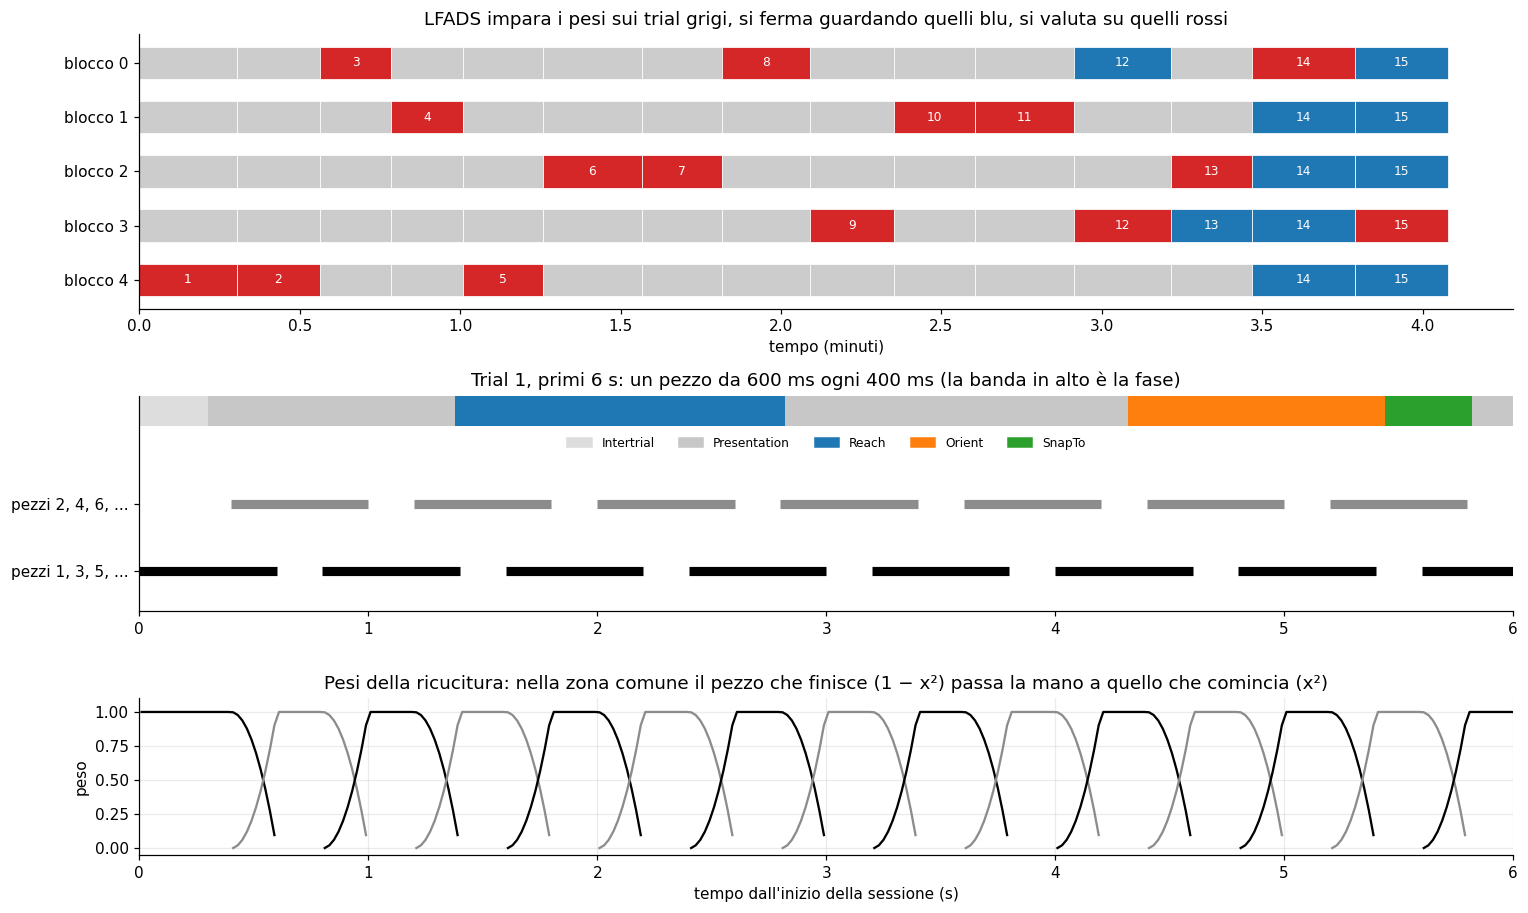

In [56]:
fig = plt.figure(figsize=(14, 8.4))
gs = fig.add_gridspec(3, 1, height_ratios=(1.4, 1.1, 0.8))
ax = fig.add_subplot(gs[0])                                 # in alto: chi fa che cosa in ogni blocco
t_min = np.arange(n_bins) * io.BIN_S / 60                   # tempo di ogni bin, in minuti
for k, (tt, vt) in enumerate(zip(TEST_TRIALS, VAL_LF)):
    for t_ in TRIALS:                                       # un rettangolo per trial: grigio = impara, blu = validazione, rosso = test
        a0, a1 = TRIAL_SPAN[t_]
        col = "C3" if t_ in tt else ("C0" if t_ in vt else "0.8")
        ax.barh(k, (a1 - a0) * io.BIN_S / 60, left=t_min[a0], height=0.6, color=col, edgecolor="white", lw=0.5)
        if t_ in tt or t_ in vt:
            ax.text(t_min[a0] + (a1 - a0) * io.BIN_S / 120, k, str(t_), ha="center", va="center", fontsize=8, color="white")
ax.set(yticks=range(5), yticklabels=[f"blocco {k}" for k in range(5)], xlabel="tempo (minuti)",
       title="LFADS impara i pesi sui trial grigi, si ferma guardando quelli blu, si valuta su quelli rossi")
ax.invert_yaxis(); ax.grid(False)

t0_ = TRIALS[0]; a0_ = TRIAL_SPAN[t0_][0]                   # al centro: i primi 6 s del primo trial, con i suoi pezzi
show_n = 300                                                # 300 bin = 6 s
ax2 = fig.add_subplot(gs[1])
for b_ in range(a0_, a0_ + show_n):                         # la fase di ogni bin, come banda colorata in alto
    ax2.axvspan(b_ * io.BIN_S, (b_ + 1) * io.BIN_S, ymin=0.86, ymax=1, color=io.PHASE_COLORS.get(phase[b_], "white"), lw=0)
SEG_COL = ("k", "0.55")                                     # i pezzi in nero e in grigio, alternati (i colori sono già usati dalle fasi)
for i, a in enumerate(SEG_START[t0_]):                      # un segmento orizzontale per pezzo, su due righe alternate
    if a < a0_ + show_n:
        ax2.plot([a * io.BIN_S, (a + SEG_LEN) * io.BIN_S], [i % 2, i % 2], color=SEG_COL[i % 2], lw=6, solid_capstyle="butt")
ax2.set(ylim=(-0.6, 2.6), yticks=[0, 1], yticklabels=["pezzi 1, 3, 5, ...", "pezzi 2, 4, 6, ..."],
        xlim=(a0_ * io.BIN_S, (a0_ + show_n) * io.BIN_S),
        title=f"Trial {t0_}, primi 6 s: un pezzo da 600 ms ogni 400 ms (la banda in alto è la fase)")
ph_show = [p for p in ["Intertrial", "Presentation", *io.MOVEMENT_PHASES] if p in set(phase[a0_:a0_ + show_n])]  # le fasi presenti, nell'ordine del task
handles = [plt.Rectangle((0, 0), 1, 1, color=io.PHASE_COLORS[p]) for p in ph_show]
ax2.legend(handles, ph_show, loc="upper center", bbox_to_anchor=(0.5, 0.86), fontsize=8, ncol=len(ph_show), frameon=False)
ax2.grid(False)

ax3 = fig.add_subplot(gs[2], sharex=ax2)                    # in basso: il peso di ogni pezzo nella ricucitura
W_ = segment_weights(len(SEG_START[t0_]))
for i, (a, w) in enumerate(zip(SEG_START[t0_], W_)):
    if a < a0_ + show_n:
        ax3.plot((a + np.arange(SEG_LEN) + 0.5) * io.BIN_S, w, color=SEG_COL[i % 2], lw=1.5)
ax3.set(xlabel="tempo dall'inizio della sessione (s)", ylabel="peso", ylim=(-0.05, 1.1),
        title="Pesi della ricucitura: nella zona comune il pezzo che finisce (1 − x²) passa la mano a quello che comincia (x²)")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_data.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **`eval_mask` esclude quasi soltanto `SnapTo`**: 290 dei suoi 291 bin, più 17 bin di pausa. Dei
  1106 punti di valutazione, 58 (il 5%) sono di `SnapTo`.
- **Più di metà della sessione è pausa**: 6672 bin di `Presentation` su 12233. Come CEBRA (§1.4),
  LFADS dovrà descrivere anche le pause, che non valutiamo.
- **La figura.** In alto: in ogni blocco LFADS impara sui trial grigi, si ferma guardando i due blu
  (sempre verso la fine della sessione) e si valuta sui tre rossi. Al centro: un pezzo da 600 ms ogni
  400 ms, su due righe per vederli separati; un pezzo contiene spesso un cambio di fase. In basso: i
  pesi della ricucitura, che si passano la mano in modo graduale nei 200 ms in comune; il primo pezzo
  del trial comincia con peso pieno, perché prima non c'è nessun pezzo.

### Riepilogo del §9

| decisione | scelta | perché | alternative (dove) |
|---|---|---|---|
| ingresso | conteggi grezzi a 20 ms, 160 canali (gli stessi della GPFA) | LFADS ha un suo modello del rumore (Poisson) | — |
| taglio | pezzi da 600 ms ogni 400 ms, dentro ogni trial; 610 pezzi | lo schema di AutoLFADS e del benchmark per le registrazioni continue | 400 ms, 1 s (§14) |
| ricucitura | media pesata con le rampe di AutoLFADS (1 − x², x²) | passaggio graduale tra pezzi; verificata a mano sui conteggi | — |
| split | i 5 blocchi del 03; in ogni blocco 10 trial per i pesi, 2 di validazione (l'ultimo pari e l'ultimo dispari), 3 di test | stessi trial di test di tutto il notebook; validazione con le due versioni | seconda coppia di validazione (§11) |
| canali nascosti | 40 su 160, 10 per fascia di frequenza, seme fisso | misura generativa del §12, come nel benchmark | — |
| `SnapTo` | tenuta nell'allenamento e nel metro comune | LFADS descrive l'attività, non il movimento; confrontabilità con il 03 | metro comune senza `SnapTo` (§12) |

**Che cosa non abbiamo verificato**: se la validazione alla fine della sessione è rappresentativa
(§11); come si comportano le uscite di LFADS alle cuciture (§11); se 600 ms sia la lunghezza migliore
per questi dati (§14).

## 10 · L'idea di LFADS su un esempio sintetico

Come per CEBRA (§2) e per Isomap (03, §3), prima dei dati veri proviamo LFADS su dati di cui
**conosciamo la risposta**. L'esempio è quello dell'articolo originale (Sussillo et al. 2016): il
**sistema di Lorenz**, tre numeri che cambiano nel tempo seguendo regole fisse. È il famoso
"attrattore a farfalla": la traiettoria gira intorno a due "ali" e salta dall'una all'altra in modo
imprevedibile a lungo termine, ma a ogni istante il passo successivo è **determinato** da dove si
trova. È proprio il tipo di regola che LFADS deve imparare: dato lo stato adesso, dove va dopo.

Il sistema di Lorenz è nascosto: vediamo solo gli spike di 30 neuroni finti, la cui frequenza dipende
dallo stato. Se LFADS funziona, dai soli spike deve ritrovare lo stato.

Il §10 è diviso in due parti:

- **§10a (questa)**: i dati sintetici; LFADS scritto a mano, un blocco alla volta; il calcolo a mano
  confrontato con la libreria, per le uscite e per la funzione di costo. Nessun allenamento;
- **§10b**: l'allenamento sui dati sintetici e il confronto con la verità e con la GPFA.

### 10.1 · I dati sintetici: spike guidati dal sistema di Lorenz

Seguiamo la ricetta di Sussillo et al. (2016, §4.1), adattata al formato dei nostri dati:

| | Sussillo et al. 2016 | qui |
|---|---|---|
| sistema | Lorenz con σ = 10, ρ = 28, β = 8/3, integrato con il metodo di Eulero | uguale |
| neuroni | 30 | 30 |
| frequenze | combinazione lineare (pesi a caso) delle 3 variabili, poi esponenziale; livello di base 5 spike/s | uguale, con livello medio **10 spike/s** (la mediana dei nostri canali, §9.1) |
| spike | Poisson | Poisson, in bin da **20 ms** |
| struttura | 65 condizioni × 20 prove da 1 s, ognuna da uno stato iniziale a caso | **una sola registrazione continua di 200 s**, tagliata in pezzi da 600 ms come i dati veri (§9.2) |
| divisione | 80% training, 20% valutazione | primi 160 s per i pesi (come un blocco vero, §9.3), poi 20 s di validazione e 20 s di test |

**La velocità del sistema.** Le regole di Lorenz non hanno un'unità di tempo: la scegliamo noi.
Ogni bin da 20 ms fa avanzare il sistema di 0.015 unità, in 10 piccoli passi di Eulero. Così un giro
intorno a un'ala dura poco meno di un secondo, e un pezzo da 600 ms ne contiene circa due terzi.

In [57]:
SIGMA_L, RHO_L, BETA_L = 10.0, 28.0, 8 / 3                  # i parametri standard del sistema di Lorenz (Sussillo et al. 2016)
DT_BIN, N_SUB = 0.015, 10                                   # ogni bin da 20 ms fa avanzare il sistema di 0.015 unità di tempo, in 10 passi di Eulero
T_LZ, N_NEU = 10_000, 30                                    # 10 000 bin (200 s) e 30 neuroni finti

def lorenz_step(v, dt):                                     # un passo di Eulero: stato nuovo = stato + dt × (velocità data dalle regole di Lorenz)
    x, y, z = v
    return v + dt * np.array([SIGMA_L * (y - x), x * (RHO_L - z) - y, x * y - BETA_L * z])

v_lz = np.array([1.0, 1.0, 1.0])                            # uno stato di partenza qualunque
for _ in range(2_000):                                      # 2000 passi a vuoto: il sistema si porta sull'attrattore
    v_lz = lorenz_step(v_lz, DT_BIN / N_SUB)
LZ = np.empty((T_LZ, 3))                                    # lo stato di Lorenz in ogni bin
for t in range(T_LZ):
    for _ in range(N_SUB):                                  # 10 piccoli passi per bin
        v_lz = lorenz_step(v_lz, DT_BIN / N_SUB)
    LZ[t] = v_lz
LZ_Z = (LZ - LZ.mean(0)) / LZ.std(0)                        # ogni variabile con media 0 e varianza 1

rng_lz = np.random.default_rng(0)                           # seme fisso: stessi neuroni e stessi spike a ogni esecuzione
W_LZ = rng_lz.normal(0, 0.35, size=(3, N_NEU))              # quanto ogni neurone "ascolta" ciascuna delle 3 variabili (pesi a caso)
logr_lz = LZ_Z @ W_LZ                                       # la combinazione lineare dello stato, per ogni neurone
B_LZ = np.log(0.2) - np.log(np.exp(logr_lz).mean(0))        # il livello di base che dà in media 0.2 spike per bin (10 spike/s) a ogni neurone
RATE_LZ = np.exp(logr_lz + B_LZ)                            # la frequenza vera: spike attesi in ogni bin (dopo l'esponenziale)
SPK_LZ = rng_lz.poisson(RATE_LZ).astype(np.float32)         # gli spike osservati: estratti a caso secondo Poisson

LZ_PARTS = {"impara": (0, 8_000), "validazione": (8_000, 9_000), "test": (9_000, 10_000)}  # 160 s + 20 s + 20 s
LZ_START = {k: segment_starts(a0, a1) for k, (a0, a1) in LZ_PARTS.items()}  # gli inizi dei pezzi, con la regola del §9.2
LZ_SEGS = {k: np.stack([SPK_LZ[a:a + SEG_LEN] for a in st]) for k, st in LZ_START.items()}  # i pezzi: (pezzi, 30 bin, 30 neuroni)

print(f"Spike: {T_LZ} bin × {N_NEU} neuroni; frequenza media {SPK_LZ.mean() / io.BIN_S:.1f} spike/s "
      f"(frequenza vera da {RATE_LZ.min() / io.BIN_S:.1f} a {RATE_LZ.max() / io.BIN_S:.1f} spike/s); bin con 0 spike: {np.mean(SPK_LZ == 0) * 100:.0f}%")
def nll_sum(k, lam):                                        # errore di Poisson totale, senza log k! (è uguale per tutti i modelli e si cancella nei confronti)
    return np.sum(lam - k * np.log(lam))
bps_true = (nll_sum(SPK_LZ, np.broadcast_to(SPK_LZ.mean(0), SPK_LZ.shape)) - nll_sum(SPK_LZ, RATE_LZ)) / SPK_LZ.sum() / np.log(2)
print(f"Quanto segnale c'è: con le frequenze vere si guadagnano {bps_true:.3f} bit per spike rispetto alla sola frequenza media di ogni neurone")
print("Pezzi da 600 ms:", {k: v.shape[0] for k, v in LZ_SEGS.items()})
cross = np.flatnonzero(np.diff(np.sign(LZ[:, 0])) != 0)     # i bin in cui la prima variabile cambia segno: il salto da un'ala all'altra
print(f"Salti da un'ala all'altra: {len(cross)} in 200 s (uno ogni {T_LZ / len(cross) * io.BIN_S:.2f} s in media)")

Spike: 10000 bin × 30 neuroni; frequenza media 10.0 spike/s (frequenza vera da 0.5 a 155.1 spike/s); bin con 0 spike: 82%
Quanto segnale c'è: con le frequenze vere si guadagnano 0.216 bit per spike rispetto alla sola frequenza media di ogni neurone
Pezzi da 600 ms: {'impara': 400, 'validazione': 50, 'test': 50}
Salti da un'ala all'altra: 78 in 200 s (uno ogni 2.56 s in media)


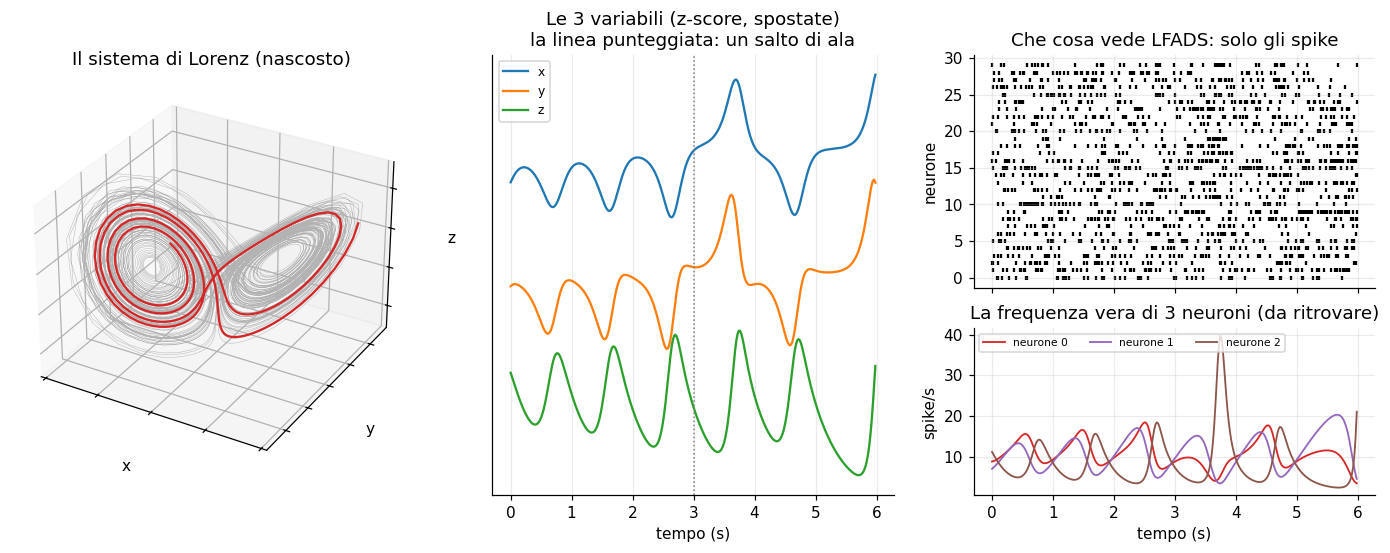

In [58]:
jump = cross[cross > 150][0]                                # il primo salto da un'ala all'altra dopo i primi 3 s
show = slice(jump - 150, jump + 150)                        # 6 s intorno a quel salto
t_s = np.arange(300) * io.BIN_S
fig = plt.figure(figsize=(16, 5.2))
gs = fig.add_gridspec(2, 3, height_ratios=(1.4, 1))
a_ = fig.add_subplot(gs[:, 0], projection="3d")             # a sinistra: l'attrattore (i primi 160 s), e in rosso i 6 s mostrati a destra
a_.plot(*LZ[:8_000:2].T, color="0.7", lw=0.3)
a_.plot(*LZ[show].T, color="C3", lw=1.5)
a_.set(title="Il sistema di Lorenz (nascosto)", xlabel="x", ylabel="y", zlabel="z")
a_.set_xticklabels([]); a_.set_yticklabels([]); a_.set_zticklabels([])
a_ = fig.add_subplot(gs[:, 1])                              # al centro: le 3 variabili nel tempo
for j, (lab, c) in enumerate(zip("xyz", ("C0", "C1", "C2"))):
    a_.plot(t_s, LZ_Z[show, j] + 3.5 * (2 - j), color=c, lw=1.5, label=lab)
a_.axvline(150 * io.BIN_S, color="0.5", ls=":", lw=1)
a_.set(xlabel="tempo (s)", yticks=[], title="Le 3 variabili (z-score, spostate)\nla linea punteggiata: un salto di ala")
a_.legend(fontsize=8, loc="upper left")
a_ = fig.add_subplot(gs[0, 2])                              # a destra in alto: gli spike dei 30 neuroni
for n in range(N_NEU):
    tt_ = np.flatnonzero(SPK_LZ[show, n] > 0)
    a_.scatter(t_s[tt_], np.full(len(tt_), n), s=5, color="k", marker="|")
a_.set(ylabel="neurone", title="Che cosa vede LFADS: solo gli spike")
a_.tick_params(labelbottom=False)                           # i numeri del tempo solo nel pannello sotto
a_2 = fig.add_subplot(gs[1, 2], sharex=a_)                  # a destra in basso: la frequenza vera di 3 neuroni (che LFADS non vede)
for n, c in zip((0, 1, 2), ("C3", "C4", "C5")):
    a_2.plot(t_s, RATE_LZ[show, n] / io.BIN_S, color=c, lw=1.2, label=f"neurone {n}")
a_2.set(xlabel="tempo (s)", ylabel="spike/s", title="La frequenza vera di 3 neuroni (da ritrovare)")
a_2.legend(fontsize=7, loc="upper left", ncol=3)
with warnings.catch_warnings():                            # il pannello 3D non lascia sistemare tutti i margini: matplotlib avvisa, ma la figura è a posto
    warnings.simplefilter("ignore")
    fig.tight_layout()
fig.savefig(FIGS / "04_lfads_synthetic_data.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Gli spike sintetici somigliano ai nostri**: 10 spike/s in media, l'82% dei bin vuoti (77% nei dati
  veri, §9.1); la frequenza vera di un neurone va da meno di 1 a circa 150 spike/s.
- **Il segnale è debole ma realistico**: conoscendo le frequenze vere si guadagnano 0.22 bit per spike
  rispetto alla sola frequenza media di ogni neurone. È lo stesso ordine di grandezza dei valori che
  il Neural Latents Benchmark riporta sui dati veri (0.2-0.37 bit per spike sul labirinto, Pei et
  al. 2021), anche se lì si misurano neuroni nascosti.
- **I pezzi**: 400 per imparare (come in un blocco dei dati veri, §9.3), 50 di validazione, 50 di
  test. Il sistema salta da un'ala all'altra 78 volte in 200 s, in media ogni 2.6 s: un pezzo da 600
  ms contiene un salto solo ogni tanto.
- **La figura** mostra la difficoltà: nelle 3 variabili il salto di ala (la linea punteggiata) è
  evidente, e le frequenze vere dei 3 neuroni oscillano tra circa 3 e 40 spike/s; negli spike, l'unica cosa
  che LFADS vede, a occhio non si riconosce niente.

### 10.2 · LFADS, un blocco alla volta

LFADS è un *autoencoder sequenziale variazionale*: una rete che **riassume** un pezzo di dati in poche
informazioni e poi lo **ricostruisce** a partire solo da quelle. I blocchi, per un pezzo da 30 bin:

```
conteggi del pezzo (30 bin × 30 neuroni)
   │  1. encoder: legge il pezzo in avanti e all'indietro
   ▼
2. condizione iniziale g₀: una media e un'incertezza (64 numeri ciascuna)   ← l'unica informazione che passa
   │  3. generatore: applica le sue regole del moto, bin dopo bin, senza guardare i dati
   ▼
g₁, g₂, …, g₃₀   (lo stato del generatore: 64 numeri per bin)
   │  4. fattori: una proiezione lineare dello stato (10 numeri per bin)
   ▼
f₁, …, f₃₀
   │  5. frequenze: combinazione lineare dei fattori, poi esponenziale (30 neuroni per bin)
   ▼
λ₁, …, λ₃₀  →  quanto sono probabili i conteggi osservati (Poisson)
```

1. **L'encoder** è fatto di due **GRU**, una che legge il pezzo dal primo bin all'ultimo e una
   dall'ultimo al primo. Una GRU è una piccola rete ricorrente: a ogni bin prende il suo stato di prima
   e l'ingresso del bin, e calcola lo stato nuovo come **una media tra lo stato vecchio e una
   proposta nuova**. Quanto pesa ciascuno lo decide una "porta" (z), calcolata anch'essa dai dati. È
   come aggiornare un'opinione leggendo un libro pagina per pagina: a ogni pagina se ne tiene una parte
   e se ne cambia una parte. Alla fine, i due stati finali (avanti e indietro) riassumono tutto il pezzo.
2. **La condizione iniziale.** Dal riassunto, una trasformazione lineare dà **media e incertezza** dello
   stato da cui parte il generatore: "il sistema all'inizio del pezzo è più o meno qui". È la parte
   *variazionale*: durante l'allenamento si estrae a caso un punto dentro l'incertezza; in valutazione
   si usa la media.
3. **Il generatore** è un'altra GRU, **senza ingressi**: dal bin 1 al bin 30 applica solo le sue regole
   al proprio stato. Data la condizione iniziale, tutta la traiettoria è determinata. È il punto chiave
   di LFADS: per ogni pezzo passa solo la condizione iniziale (64 numeri, per descrivere 900
   conteggi), quindi la rete è costretta a mettere la conoscenza del sistema **nelle regole**, che sono
   le stesse per tutti i pezzi.
4. **I fattori** sono una proiezione lineare dello stato del generatore, con pochi numeri: sono
   l'equivalente dei fattori della GPFA, e quelli che useremo per tutte le misure. La libreria
   normalizza le direzioni della proiezione (lunghezza 1): la scala la decide il passo dopo.
5. **Le frequenze**: una combinazione lineare dei fattori più un livello per neurone, poi
   l'**esponenziale**, che rende tutto positivo. È il legame non lineare tra fattori e frequenze; la
   GPFA ha invece un legame lineare, sulla radice dei conteggi.

**Il controller** (gli ingressi esterni inferiti) lo lasciamo fuori, come concordato: con il controller
l'encoder potrebbe "spingere" il generatore anche durante il pezzo, non solo all'inizio.

Qui sotto LFADS scritto a mano con `numpy`, con le stesse formule della libreria `lfads-torch`
(lette nel suo codice: `modules/recurrent.py`, `encoder.py`, `decoder.py`). Due dettagli della libreria
da rispettare:

- nella GRU l'ordine delle porte è **z, r, n**, non r, z, n come nella GRU standard di PyTorch, e la
  porta r moltiplica lo stato **prima** della moltiplicazione per i pesi;
- lo stato della GRU è tagliato a ±5 (`cell_clip`), una protezione contro valori che esplodono.

Lo scriviamo per **capire**, non per allenare: per allenare servono le derivate di tutto rispetto a
tutti i pesi, che calcola automaticamente `torch`. Quello lo lascia fare alla libreria (§10b).

In [59]:
def sigmoid(x):                                             # la funzione a "S" tra 0 e 1, usata dalle porte
    return 1 / (1 + np.exp(-x))

def gru_step(x, h, w, name, clip):                          # un passo della GRU di lfads-torch (ClippedGRUCell): ingresso x, stato h, pesi w[name + ...]
    H = h.shape[1]                                          # dimensione dello stato
    W_ih, b_ih = w[name + "weight_ih"], w[name + "bias_ih"] # pesi dell'ingresso (per le 3 porte, una sopra l'altra) e loro livelli
    W_hh, b_hh = w[name + "weight_hh"], w[name + "bias_hh"] # pesi dello stato precedente, e loro livelli
    x_z, x_r, x_n = np.split(x @ W_ih.T + b_ih, 3, axis=1)  # il contributo dell'ingresso alle porte z, r e alla proposta n (in quest'ordine)
    h_z, h_r = np.split(h @ W_hh[:2 * H].T + b_hh[:2 * H], 2, axis=1)  # il contributo dello stato precedente alle porte z e r
    z = sigmoid(x_z + h_z)                                  # porta di aggiornamento: quanto tenere dello stato vecchio (da 0 a 1)
    r = sigmoid(x_r + h_r)                                  # porta di reset: quanto dello stato vecchio usare per fare la proposta
    n = np.tanh(x_n + (r * h) @ W_hh[2 * H:].T + b_hh[2 * H:])  # la proposta di stato nuovo (r moltiplica lo stato PRIMA dei pesi)
    return np.clip(z * h + (1 - z) * n, -clip, clip)        # lo stato nuovo: media tra vecchio e proposta, tagliata a ±clip

def lfads_forward_np(data, w, hp):
    """LFADS a mano: dai conteggi (pezzi × bin × neuroni) a condizione iniziale, stati, fattori e log-frequenze.
    Versione di valutazione: si usa la media della condizione iniziale e nessun dropout."""
    B, T, _ = data.shape                                    # pezzi, bin per pezzo, neuroni
    clip = hp["cell_clip"]
    h_f = np.tile(w["encoder.ic_enc_h0"][0], (B, 1))        # 1. encoder: stato di partenza della GRU che legge in avanti (un parametro imparato)...
    h_b = np.tile(w["encoder.ic_enc_h0"][1], (B, 1))        # ...e di quella che legge all'indietro
    for t in range(T):                                      # dal primo bin all'ultimo
        h_f = gru_step(data[:, t], h_f, w, "encoder.ic_enc.fwd_gru.cell.", clip)
    for t in reversed(range(T)):                            # dall'ultimo bin al primo
        h_b = gru_step(data[:, t], h_b, w, "encoder.ic_enc.bwd_gru.cell.", clip)
    summary = np.concatenate([h_f, h_b], axis=1)            # il riassunto del pezzo: i due stati finali, uno accanto all'altro
    ic_params = summary @ w["encoder.ic_linear.weight"].T + w["encoder.ic_linear.bias"]  # 2. condizione iniziale: una trasformazione lineare...
    ic_mean, ic_logvar = np.split(ic_params, 2, axis=1)     # ...che dà la media e il logaritmo della varianza
    ic_std = np.sqrt(np.exp(ic_logvar) + hp["ic_post_var_min"])  # l'incertezza (deviazione standard), mai sotto un minimo
    g = ic_mean @ w["decoder.ic_to_g0.weight"].T + w["decoder.ic_to_g0.bias"]  # 3. generatore: lo stato di partenza g₀, dalla media della condizione iniziale
    W_fac = w["decoder.rnn.cell.fac_linear.weight"]         # 4. le direzioni dei fattori nello stato del generatore...
    W_fac = W_fac / np.linalg.norm(W_fac, axis=1, keepdims=True)  # ...ognuna normalizzata a lunghezza 1 (KernelNormalizedLinear)
    no_input = np.zeros((B, 0))                             # il generatore non ha ingressi: un ingresso "vuoto" (0 colonne)
    gen, fac = [], []
    for t in range(T):                                      # bin dopo bin, solo le regole del generatore
        g = gru_step(no_input, g, w, "decoder.rnn.cell.gen_cell.", clip)  # senza ingresso, x @ W_ih vale 0: restano i livelli b_ih
        gen.append(g)
        fac.append(g @ W_fac.T)                             # i fattori del bin
    gen, fac = np.stack(gen, 1), np.stack(fac, 1)           # (pezzi, bin, 64) e (pezzi, bin, 10)
    log_rates = fac @ w["readout.0.weight"].T + w["readout.0.bias"]  # 5. log-frequenze: combinazione lineare dei fattori più un livello per neurone
    return {"ic_mean": ic_mean, "ic_std": ic_std, "gen_states": gen, "factors": fac, "log_rates": log_rates}

### 10.3 · La libreria, e il confronto con il calcolo a mano

**Come usiamo `lfads-torch`.** La libreria (Sedler & Pandarinath 2023) è installata da GitHub (commit
`007a555`), con tre limiti per questa versione di `pytorch_lightning` (2.6.4):

- i file di configurazione non sono installati: **costruiamo il modello direttamente in Python**
  (`make_lfads`, qui sotto), con i parametri scritti in chiaro;
- il modulo che carica i dati (`lfads_torch.datamodules`) non si importa con questa versione di
  Lightning: i dati li passiamo noi;
- l'allenatore di Lightning si rompe su una funzione che ha cambiato forma: scriveremo il nostro ciclo
  di allenamento (§10b).

**Come per CEBRA, un processo separato** (§2.3): il notebook non importa mai `torch`. In più, un
dettaglio scoperto provando la libreria: se nel processo si importa `torch` **prima** di `numpy`,
Python si chiude all'istante (le due copie di OpenMP, quella di `torch` e quella di conda, entrano in
conflitto); importando prima `numpy` funziona. Per questo tutte le funzioni che girano nel processo
separato cominciano con `import numpy`. **Gli allenamenti di LFADS useranno la CPU, non la GPU del
Mac**: in una prova su dati finti della stessa forma la CPU era circa 4.5 volte più veloce (la GPU
conviene per calcoli grandi; LFADS fa tanti calcoli piccoli, un bin alla volta). Lo rimisuriamo al
§10b.

**I parametri dell'esempio sintetico**, e da dove vengono:

| parametro | valore | da dove |
|---|---|---|
| encoder, condizione iniziale, generatore | 64 numeri ciascuno | scelta nostra: piccoli, per pochi dati (la configurazione della libreria per MC_Maze-S usa 100) |
| fattori | 10 | scelta nostra: il sistema ne ha 3, ne diamo di più senza dire quanti servono |
| varianza a priori della condizione iniziale | 0.1 | Sussillo et al. 2016 (appendice); configurazioni della libreria |
| varianza minima della condizione iniziale | 10⁻⁴ | configurazioni della libreria |
| taglio dello stato (`cell_clip`) | 5 | configurazioni della libreria |
| dropout | 0.05 | scelta nostra; la libreria parte da 0.02 e lo cerca tra 0 e 0.6 |
| *coordinated dropout* | 0.3 | configurazione della libreria per MC_Maze-S |
| peso del termine KL | 1 / (30 bin × 30 neuroni) | la verosimiglianza "vera" (§10.4); la libreria lo cerca tra 10⁻⁶ e 10⁻³ |
| peso della penalità sul generatore (L2) | 10⁻² | il centro (in scala logaritmica) dell'intervallo di ricerca della libreria, 10⁻⁴-1 |
| rampe di KL e L2 | da 0 al valore pieno in 80 epoche | configurazioni della libreria |
| passo di apprendimento | 4·10⁻³ | configurazioni della libreria |

I valori della libreria vengono dal suo repository: `configs/model/nlb_mc_maze_small.yaml` e
`scripts/run_pbt.py` (gli intervalli di ricerca di AutoLFADS). Per i dati veri li sceglieremo con una
piccola griglia (§11).

**Il controllo.** Costruiamo un modello della libreria con i pesi iniziali a caso (seme 0), gli diamo
8 pezzi di spike sintetici, e leggiamo tutte le sue uscite. Poi copiamo i suoi pesi nel nostro LFADS
a mano e rifacciamo il calcolo. Se le formule sono le stesse, le uscite devono coincidere a meno
dell'arrotondamento: la libreria calcola con numeri a 32 bit, noi a 64.

In [60]:
from joblib.externals.loky import ProcessPoolExecutor      # (già importato al §2.3) un gruppo di processi separati

POOL_LF = ProcessPoolExecutor(max_workers=4)                # i processi per LFADS: 4 alla volta, sulla CPU

SYN_HP = dict(n_in=N_NEU, n_out=N_NEU, seg_len=SEG_LEN,    # neuroni in ingresso e in uscita (al §12 saranno diversi), bin per pezzo
              enc_dim=64, ic_dim=64, gen_dim=64, fac_dim=10,  # grandezze di encoder, condizione iniziale, generatore, fattori
              ic_prior_var=0.1, ic_post_var_min=1e-4, cell_clip=5.0,  # varianza a priori e minima della condizione iniziale; taglio dello stato
              dropout=0.05, cd_rate=0.3,                    # dropout e coordinated dropout
              kl_ic_scale=1 / (SEG_LEN * N_NEU), l2_gen_scale=1e-2, l2_ic_enc_scale=0.0,  # pesi del termine KL e delle penalità L2
              ramp_epochs=80, lr=4e-3, loss_scale=1.0)      # rampe, passo di apprendimento, scala del costo (la libreria usa 10⁴; qui 1, per leggere i numeri)

def make_lfads(hp):
    """Un LFADS della libreria lfads-torch costruito dai parametri hp, senza controller. Si chiama nel processo separato."""
    import numpy as np                                      # numpy PRIMA di torch: altrimenti Python si chiude (§10.3)
    import torch
    from torch import nn
    from lfads_torch.model import LFADS                     # il modello della libreria
    from lfads_torch.modules import augmentations           # il coordinated dropout
    from lfads_torch.modules.priors import MultivariateNormal, Null  # la distribuzione a priori della condizione iniziale; "nessuna" per il controller
    from lfads_torch.modules.recons import Poisson          # il modello del rumore: Poisson
    from lfads_torch.modules.readin_readout import FanInLinear  # l'uscita lineare dai fattori alle log-frequenze
    cd = augmentations.CoordinatedDropout(cd_rate=hp["cd_rate"], cd_pass_rate=0.0, ic_enc_seq_len=0)
    return LFADS(encod_data_dim=hp["n_in"], encod_seq_len=hp["seg_len"], recon_seq_len=hp["seg_len"],  # forma dei dati
                 ext_input_dim=0, ic_enc_seq_len=0,         # nessun ingresso esterno; l'encoder legge tutto il pezzo
                 ic_enc_dim=hp["enc_dim"], ci_enc_dim=0, ci_lag=1, con_dim=0, co_dim=0,  # encoder; controller spento (dimensioni 0)
                 ic_dim=hp["ic_dim"], gen_dim=hp["gen_dim"], fac_dim=hp["fac_dim"], dropout_rate=hp["dropout"],
                 reconstruction=nn.ModuleList([Poisson()]), variational=True, co_prior=Null(),
                 ic_prior=MultivariateNormal(mean=0.0, variance=hp["ic_prior_var"], shape=hp["ic_dim"]),
                 ic_post_var_min=hp["ic_post_var_min"], cell_clip=hp["cell_clip"],
                 train_aug_stack=augmentations.AugmentationStack([cd], batch_order=[0], loss_order=[0]),  # coordinated dropout solo in allenamento
                 infer_aug_stack=augmentations.AugmentationStack(),
                 readin=nn.ModuleList([nn.Identity()]), readout=nn.ModuleList([FanInLinear(hp["fac_dim"], hp["n_out"])]),
                 loss_scale=hp["loss_scale"], recon_reduce_mean=True,  # errore di ricostruzione come media su pezzi, bin e neuroni
                 lr_scheduler=False, lr_init=hp["lr"], lr_stop=1e-5, lr_decay=0.95, lr_patience=6,
                 lr_adam_beta1=0.9, lr_adam_beta2=0.999, lr_adam_epsilon=1e-8, weight_decay=0.0,
                 l2_start_epoch=0, l2_increase_epoch=hp["ramp_epochs"], l2_ic_enc_scale=hp["l2_ic_enc_scale"],
                 l2_ci_enc_scale=0.0, l2_gen_scale=hp["l2_gen_scale"], l2_con_scale=0.0,
                 kl_start_epoch=0, kl_increase_epoch=hp["ramp_epochs"], kl_ic_scale=hp["kl_ic_scale"], kl_co_scale=0.0)

def lfads_library_check(hp, seed, data):
    """Nel processo separato: un modello della libreria con i pesi iniziali (seme `seed`), le sue uscite e il suo costo su `data`."""
    import numpy as np                                      # numpy PRIMA di torch
    import torch
    from lfads_torch.tuples import SessionBatch             # il formato dei dati della libreria
    from lfads_torch.modules.l2 import compute_l2_penalty   # la penalità L2 della libreria
    torch.set_num_threads(1)                                # un solo thread di CPU (§10b: di più non serve)
    torch.manual_seed(seed)                                 # seme dei pesi iniziali
    model = make_lfads(hp)
    model.eval()                                            # modalità di valutazione: niente dropout
    model.log = model.log_dict = lambda *a, **k: None       # fuori dall'allenatore di Lightning non c'è dove scrivere le misure
    X = torch.tensor(data, dtype=torch.float32)
    batch = SessionBatch(encod_data=X, recon_data=X, ext_input=torch.zeros(len(X), X.shape[1], 0),
                         truth=torch.zeros(0), sv_mask=torch.ones_like(X))  # ingresso = dati da ricostruire; nessun ingresso esterno
    with torch.no_grad():                                   # niente derivate: solo il calcolo in avanti
        out = model({0: batch}, sample_posteriors=False, output_means=False)[0]  # tutte le uscite, con la media della condizione iniziale
        recon = model.recon[0].compute_loss(X, out.output_params).mean()  # errore di ricostruzione (Poisson) della libreria
        kl = model.ic_prior(out.ic_mean, out.ic_std)        # termine KL della libreria
        l2 = compute_l2_penalty(model, model.hparams)       # penalità L2 della libreria
        model.hparams.variational = False                   # per il controllo: il costo con la media, senza estrazioni a caso
        total = model._shared_step({0: (batch, ())}, 0, "valid")  # il costo totale, calcolato dalla funzione che la libreria usa in allenamento
    w = {k: v.detach().numpy().astype(np.float64) for k, v in model.state_dict().items()}  # tutti i pesi, come array numpy
    return {"weights": w, "ic_mean": out.ic_mean.numpy(), "ic_std": out.ic_std.numpy(), "gen_states": out.gen_states.numpy(),
            "factors": out.factors.numpy(), "log_rates": out.output_params[..., 0].numpy(),
            "recon": float(recon), "kl": float(kl), "l2": float(l2), "total": float(total)}

X_chk = LZ_SEGS["impara"][:8]                               # 8 pezzi di spike sintetici
LIB = POOL_LF.submit(lfads_library_check, SYN_HP, 0, X_chk).result()  # la libreria, nel processo separato
MINE = lfads_forward_np(X_chk.astype(np.float64), LIB["weights"], SYN_HP)  # il calcolo a mano, con gli stessi pesi
w_bad = {k: v.copy() for k, v in LIB["weights"].items()}   # controllo del controllo: gli stessi pesi...
w_bad["decoder.rnn.cell.gen_cell.weight_hh"][0, 0] += 1e-3  # ...con un solo peso del generatore cambiato di 0.001
BAD = lfads_forward_np(X_chk.astype(np.float64), w_bad, SYN_HP)
OUT_NAMES = {"ic_mean": "condizione iniziale: media", "ic_std": "condizione iniziale: incertezza",
             "gen_states": "stati del generatore", "factors": "fattori", "log_rates": "log-frequenze"}
display(pd.DataFrame({lab: {"forma": str(LIB[name].shape), "valori: massimo assoluto": f"{np.abs(LIB[name]).max():.3f}",
                            "differenza massima a mano − libreria": f"{np.abs(MINE[name] - LIB[name]).max():.1e}",
                            "idem, con un peso cambiato di 0.001": f"{np.abs(BAD[name] - LIB[name]).max():.1e}"}
                      for name, lab in OUT_NAMES.items()}).T)
print("Parametri del modello:", sum(v.size for k, v in LIB["weights"].items() if not k.endswith("bias_hh")),
      "(senza i livelli b_hh, che la libreria tiene fissi)")

,forma,valori: massimo assoluto,differenza massima a mano − libreria,"idem, con un peso cambiato di 0.001"
condizione iniziale: media,"(8, 64)",0.384,1.6e-07,1.6e-07
condizione iniziale: incertezza,"(8, 64)",1.187,9.9e-08,9.9e-08
stati del generatore,"(8, 30, 64)",0.223,8.7e-08,2.0e-05
fattori,"(8, 30, 10)",0.201,7.2e-08,5.1e-06
log-frequenze,"(8, 30, 30)",0.273,8.2e-08,9.0e-06


Parametri del modello: 70858 (senza i livelli b_hh, che la libreria tiene fissi)


**Lettura.**

- **Il calcolo a mano coincide con la libreria**: in tutti i blocchi, dalla condizione iniziale alle
  log-frequenze, la differenza massima è circa 10⁻⁷, l'arrotondamento dei numeri a 32 bit della
  libreria.
- **Il confronto è sensibile**: cambiando di 0.001 un solo peso del generatore (uno su più di 12 000) la
  differenza negli stati del generatore sale a 2·10⁻⁵, circa 200 volte l'arrotondamento. La condizione
  iniziale invece resta identica, come deve: quel peso sta dopo l'encoder. Se avessimo sbagliato una
  formula, per esempio l'ordine delle porte, lo vedremmo.
- Il modello ha circa **71 000 parametri** per 30 neuroni. Per confronto, un pezzo contiene 900
  conteggi, e i 400 pezzi su cui si impara 360 000 (che però si sovrappongono e sono quasi tutti 0).
- **Che cosa il controllo non copre**: i pesi sono quelli iniziali, a caso, e il calcolo è quello di
  valutazione (media della condizione iniziale, niente dropout). L'estrazione a caso della condizione
  iniziale e il coordinated dropout, usati in allenamento, sono della libreria e non li abbiamo rifatti
  a mano; e il nostro calcolo non ha il controller.

### 10.4 · La funzione di costo, a mano

LFADS si allena minimizzando una somma di tre termini, in media sui pezzi:

1. **L'errore di ricostruzione** (Poisson): quanto sono improbabili i conteggi osservati, date le
   frequenze del modello. Per un bin con frequenza λ e k spike, la probabilità di Poisson è
   λᵏ e^(−λ) / k!, e l'errore è il suo logaritmo cambiato di segno:
   $$\mathrm{NLL} = \lambda - k \log\lambda + \log k!$$
   Più è basso, meglio il modello spiega i dati.
2. **Il termine KL**: quanto la condizione iniziale di un pezzo (media μ, incertezza σ) si allontana da
   quella **a priori** (media m, varianza 0.1, la stessa per tutti i pezzi). Per ognuna delle 64
   dimensioni:
   $$\mathrm{KL} = \log\frac{\sigma_p}{\sigma} + \frac{\sigma^2 + (\mu - m)^2}{2\sigma_p^2} - \frac12$$
   È **un prezzo per ogni informazione** che l'encoder fa passare al generatore. Senza prezzo,
   l'encoder potrebbe scrivere nella condizione iniziale tutto il pezzo, e il generatore ricopiarlo.
3. **La penalità L2** sui pesi ricorrenti del generatore: preferisce regole del moto semplici.

Messi insieme, errore e KL formano il **limite inferiore della verosimiglianza** (*ELBO*, cambiato di
segno), la quantità che ogni autoencoder variazionale minimizza (Kingma & Welling 2014; review, §4.2):
per ogni pezzo, somma degli errori su tutti i bin e i neuroni, più il KL.

**Il peso del termine KL.** La libreria non somma gli errori: ne fa la **media** su pezzi, bin e neuroni
(`recon_reduce_mean=True`), mentre il KL resta una somma sulle 64 dimensioni. Perché il costo sia
proporzionale all'ELBO vero, il KL va quindi diviso per il numero di valori ricostruiti in un pezzo,
30 bin × 30 neuroni = 900: è il peso scelto in `SYN_HP`. Con un peso più grande la condizione iniziale
lascia passare meno informazione; con uno più piccolo di più. È una delle scelte del §11.

**Le rampe.** All'inizio dell'allenamento i pesi di KL e L2 partono da (quasi) 0 e crescono fino al
valore pieno in 80 epoche: prima il modello impara a ricostruire, poi si fa pagare il prezzo. All'epoca
0 valgono 1/81.

**Un dettaglio della libreria.** Il termine log k! la libreria non lo calcola esattamente: per k ≥ 2 usa
l'approssimazione di Stirling, k log k − k + ½ log(2πk) (opzione `full=True` di `poisson_nll_loss` di
PyTorch); per k = 0 e 1 vale 0 in entrambi i casi. Non dipende dal modello, quindi non cambia
l'allenamento; cambia solo il valore del costo. Calcoliamo entrambe le versioni.

In [61]:
from scipy.special import gammaln                           # log k! = gammaln(k + 1)

def stirling(k):                                            # l'approssimazione di log k! usata da PyTorch (full=True): solo per k > 1, altrimenti 0
    k_safe = np.where(k > 1, k, 1.0)                        # per k ≤ 1 un valore qualunque, che poi non si usa (evita log 0)
    return np.where(k > 1, k_safe * np.log(k_safe) - k_safe + 0.5 * np.log(2 * np.pi * k_safe), 0.0)

def poisson_nll(k, log_rate, exact=True):                   # errore di Poisson di ogni bin e neurone: λ − k log λ + log k!
    return np.exp(log_rate) - k * log_rate + (gammaln(k + 1) if exact else stirling(k))

def kl_normal(mu, sd, prior_mean, prior_var):               # KL tra la condizione iniziale (μ, σ) e quella a priori, sommato sulle dimensioni, medio sui pezzi
    sp = np.sqrt(prior_var)
    return np.mean(np.sum(np.log(sp / sd) + (sd ** 2 + (mu - prior_mean) ** 2) / (2 * prior_var) - 0.5, axis=1))

def l2_gen(w, hp):                                          # penalità L2 della libreria: ½ ‖pesi ricorrenti‖², per il suo peso, diviso il numero di pesi
    terms = [(w["decoder.rnn.cell.gen_cell.weight_hh"], hp["l2_gen_scale"]),
             (w["encoder.ic_enc.fwd_gru.cell.weight_hh"], hp["l2_ic_enc_scale"]),
             (w["encoder.ic_enc.bwd_gru.cell.weight_hh"], hp["l2_ic_enc_scale"])]
    used = [(W_, s_) for W_, s_ in terms if s_ > 0]         # come la libreria: solo i pesi con una penalità diversa da 0
    return sum(s_ * 0.5 * np.sum(W_ ** 2) for W_, s_ in used) / (sum(W_.size for W_, _ in used) + 1e-8)

ramp0 = 1 / (SYN_HP["ramp_epochs"] + 1)                     # le rampe all'epoca 0: (0 + 1) / (80 + 1)
k_chk = X_chk.astype(np.float64)
recon_stir = poisson_nll(k_chk, MINE["log_rates"], exact=False).mean()  # errore di ricostruzione come la libreria (Stirling), media su tutto
recon_exact = poisson_nll(k_chk, MINE["log_rates"], exact=True).mean()  # lo stesso con log k! esatto
kl_mine = kl_normal(MINE["ic_mean"], MINE["ic_std"], LIB["weights"]["ic_prior.mean"], np.exp(LIB["weights"]["ic_prior.logvar"]))
l2_mine = l2_gen(LIB["weights"], SYN_HP)
total_mine = SYN_HP["loss_scale"] * (recon_stir + ramp0 * l2_mine + ramp0 * SYN_HP["kl_ic_scale"] * kl_mine)  # la formula del costo della libreria
cost_rows = {"errore di ricostruzione (Stirling)": (recon_stir, LIB["recon"]), "termine KL": (kl_mine, LIB["kl"]),
             "penalità L2": (l2_mine, LIB["l2"]), "costo totale (rampe all'epoca 0)": (total_mine, LIB["total"])}
display(pd.DataFrame({name: {"a mano": f"{a:.6g}", "libreria": f"{b:.6g}", "differenza relativa": f"{abs(a - b) / abs(b):.1e}"}
                      for name, (a, b) in cost_rows.items()}).T)
n_val = SEG_LEN * N_NEU                                     # valori ricostruiti in un pezzo: 900
elbo_neg = poisson_nll(k_chk, MINE["log_rates"], exact=True).sum((1, 2)).mean() + kl_mine  # −ELBO per pezzo, con log k! esatto
print(f"Errore con log k! esatto: {recon_exact:.4f} (Stirling: {recon_stir:.4f}); differenza dovuta solo ai bin con 2 o più spike")
true_chk = np.stack([RATE_LZ[a:a + SEG_LEN] for a in LZ_START["impara"][:8]])  # le frequenze vere degli stessi 8 pezzi
mean_rate = SPK_LZ[:8_000].mean(0)                          # la frequenza media di ogni neurone nei 160 s su cui si impara
print(f"Termini di confronto per l'errore (Stirling), sugli stessi pezzi: con le frequenze vere (il modello perfetto) "
      f"{poisson_nll(k_chk, np.log(true_chk), exact=False).mean():.4f}; con la sola frequenza media di ogni neurone "
      f"{poisson_nll(k_chk, np.broadcast_to(np.log(mean_rate), k_chk.shape), exact=False).mean():.4f}")
print(f"ELBO cambiato di segno, per pezzo: {elbo_neg:.1f}; costo della libreria con le rampe piene e senza L2, × {n_val}: "
      f"{(recon_stir + SYN_HP['kl_ic_scale'] * kl_mine) * n_val:.1f} (la differenza è la correzione di Stirling: "
      f"{(recon_exact - recon_stir) * n_val:.1f})")

,a mano,libreria,differenza relativa
errore di ricostruzione (Stirling),1.01081,1.01081,2.4e-08
termine KL,217.781,217.781,4.6e-08
penalità L2,7.70025e-05,7.70025e-05,2.7e-07
costo totale (rampe all'epoca 0),1.0138,1.0138,1.6e-08


Errore con log k! esatto: 1.0113 (Stirling: 1.0108); differenza dovuta solo ai bin con 2 o più spike
Termini di confronto per l'errore (Stirling), sugli stessi pezzi: con le frequenze vere (il modello perfetto) 0.4791; con la sola frequenza media di ogni neurone 0.4912
ELBO cambiato di segno, per pezzo: 1128.0; costo della libreria con le rampe piene e senza L2, × 900: 1127.5 (la differenza è la correzione di Stirling: 0.5)


**Lettura.**

- **Il costo a mano coincide con quello della libreria** in tutti e tre i termini e nel totale
  (differenze relative tra 10⁻⁸ e 10⁻⁷).
- **Il modello appena creato ricostruisce peggio di chi conosce solo la frequenza media**: errore 1.011
  per valore, contro 0.491 della frequenza media e 0.479 delle frequenze vere. Il motivo: con i pesi
  iniziali le log-frequenze sono vicine a 0, cioè circa 1 spike per bin, cinque volte troppo. La prima
  cosa che l'allenamento imparerà è il livello di ogni neurone.
- **L'informazione sullo stato nascosto sta in una differenza piccola**: tra la frequenza media (0.491)
  e le frequenze vere (0.479) c'è il 2.5%. Per questo si misura in bit per spike, che guarda proprio
  quella differenza (§9.4, §12).
- **Il termine KL pesa poco ora, ma non a regime.** Con i pesi iniziali vale 218 per pezzo: l'incertezza
  della condizione iniziale (circa 1) è molto più larga di quella a priori (0.32). All'epoca 0, con il
  peso 1/900 e la rampa a 1/81, aggiunge al costo appena 0.003; con il peso pieno aggiungerebbe 0.24 per
  valore, circa metà dell'errore di un modello buono (0.48). Il peso del KL quindi conta, ed è per questo che sta nella
  griglia del §11.
- **L'ELBO**: per pezzo, errore sommato più KL vale 1128.0; il costo della libreria con le rampe piene e
  senza L2, moltiplicato per 900, vale 1127.5. La differenza, 0.5, è tutta nell'approssimazione di
  Stirling di log k!, che non dipende dal modello.

**Fine del §10a.** Nel §10b: l'allenamento su questi dati, il confronto tra LFADS e la verità (lo stato
di Lorenz e le frequenze) e con la GPFA, il controllo del seme e il tempo di calcolo su CPU e GPU.

## 10b · LFADS allenato sui dati sintetici

Ora alleniamo davvero LFADS sugli spike di Lorenz del §10.1 e controlliamo, con la verità in mano,
che cosa ha imparato. Tre domande:

1. **Sta imparando o sta memorizzando?** Curve di allenamento sui pezzi visti e su quelli di
   validazione, e, solo qui dove la conosciamo, la distanza dalla verità (§10.6).
2. **Ritrova lo stato nascosto e le frequenze vere?** Meglio o peggio della GPFA e dello smoothing,
   alla pari (§10.7)?
3. **I controlli**: le cuciture tra i pezzi, il calcolo a mano con i pesi allenati, il seme, i tempi
   su CPU e GPU (§10.8).

### 10.5 · Il ciclo di allenamento

Un allenamento è fatto di **epoche**: in ogni epoca LFADS vede tutti i 400 pezzi, mescolati, a gruppi
da 64 (l'ultimo gruppo è più piccolo). Per ogni gruppo:

1. il **costo della libreria** (§10.4), con le due cose che si fanno solo in allenamento: la
   condizione iniziale **estratta a caso** dentro la sua incertezza, e il **coordinated dropout**;
2. le **derivate** del costo rispetto a tutti i pesi (le calcola `torch`);
3. un passo dell'ottimizzatore **AdamW** (Loshchilov & Hutter 2019), con il passo di apprendimento
   della libreria (4·10⁻³).

**Il coordinated dropout** (Keshtkaran & Pandarinath 2019): a ogni gruppo si nasconde all'encoder il
30% dei valori (bin × neurone), scelti a caso, e l'errore si misura **solo su quei valori nascosti**. La
rete non può quindi limitarsi a copiare l'ingresso in uscita: per indovinare un valore che non ha
visto deve usare gli altri, cioè la struttura comune. È come un esercizio in cui si coprono alcune
parole di un testo e si chiede di indovinarle dal resto.

**Dopo ogni epoca** misuriamo l'errore di ricostruzione sui pezzi di **validazione**, con la media della
condizione iniziale e senza dropout, e teniamo la versione del modello con l'errore più basso. Ci
fermiamo quando l'errore non migliora da 200 epoche, al massimo dopo 1000. Prima che le rampe di KL e L2
siano finite (80 epoche) non si sceglie nessuna versione: un modello "senza prezzi" non è quello che
vogliamo. Sono le regole dell'allenatore della libreria (`configs/single.yaml`: 1000 epoche, pazienza
200, periodo iniziale = fine delle rampe).

**Due dettagli tecnici, perché non usiamo l'allenatore di Lightning** (§10.3):

- le rampe di KL e L2 leggono il numero dell'epoca dall'allenatore; senza allenatore resterebbero ferme
  all'epoca 0, quindi glielo diciamo noi a ogni epoca;
- la libreria **taglia le derivate** quando la loro lunghezza supera 200, ma con il costo moltiplicato
  per 10⁴ (`loss_scale`); con il nostro costo, moltiplicato per 1, la stessa soglia è 200 / 10⁴ = 0.02.

**Il salvataggio su disco**, come per CEBRA (§3.1): ogni modello allenato si salva in
`~/tesi_h1_work/cache_04/lfads` con un nome che è l'impronta di tutto ciò che lo determina (il codice di
`lfads_fit` e `make_lfads`, i parametri, il seme, tutti i dati). Rieseguendo il notebook si rilegge;
`RETRAIN = True` (§3.1) rifà tutto da capo.

In [62]:
import copy                                                 # per tenere una copia della versione migliore del modello

CACHE_LF = CACHE / "lfads"                                  # i modelli LFADS salvati, nella stessa cartella di CEBRA (§3.1), fuori dal Desktop
CACHE_LF.mkdir(parents=True, exist_ok=True)
CLIP_LF = 200 / 1e4                                         # la soglia di taglio delle derivate della libreria (200 con il costo × 10⁴), per il nostro costo × 1

def lfads_fit(hp, seed, train, val, apply, watch=None, max_epochs=1000, patience=200, batch_size=64, clip=CLIP_LF,
              device="cpu", model_path=None, rate_cols=None):
    """Allena un LFADS della libreria (make_lfads) sui pezzi `train` (pezzi × bin × neuroni) e sceglie la versione con
    l'errore più basso sui pezzi `val`. Restituisce, per ogni array di `apply`, fattori e frequenze (media della
    condizione iniziale, senza dropout; delle frequenze solo le colonne rate_cols, se indicate), la storia
    dell'allenamento e i pesi. watch = {nome: (pezzi, frequenze vere o None[, colonne nascoste all'encoder])}: altre
    misure a ogni epoca (errore, bit per spike, R² con la verità). Gira nel processo separato."""
    import copy, time                                       # copia della versione migliore; durata
    import numpy as np                                      # numpy PRIMA di torch (§10.3)
    import torch
    from lfads_torch.tuples import SessionBatch             # il formato dei dati della libreria
    torch.set_num_threads(1)                                # un thread: i calcoli sono piccoli (§10.8)
    torch.manual_seed(seed)                                 # pesi iniziali, coordinated dropout, dropout, estrazioni della condizione iniziale
    rng = np.random.default_rng(seed)                       # l'ordine dei pezzi in ogni epoca
    model = make_lfads(hp)
    model.__class__ = type("LFADSconEpoca", (type(model),), {"current_epoch": 0})  # un numero d'epoca che possiamo scrivere noi (per le rampe)
    model = model.to(device)
    model.log = model.log_dict = lambda *a, **k: None       # fuori da Lightning non c'è dove scrivere le misure
    opt = model.configure_optimizers()                      # AdamW con il passo di apprendimento di hp, come la libreria
    n_in = hp["n_in"]                                       # i neuroni che l'encoder vede (i primi n_in; al §12 non saranno tutti)

    def as_batch(X):                                        # pezzi numpy -> il formato della libreria
        Xt = torch.tensor(X, dtype=torch.float32, device=device)
        return SessionBatch(encod_data=Xt[..., :n_in], recon_data=Xt,  # l'encoder vede i primi n_in neuroni, si ricostruiscono tutti
                            ext_input=torch.zeros(len(Xt), Xt.shape[1], 0, device=device),
                            truth=torch.zeros(0), sv_mask=torch.ones_like(Xt))

    def evaluate(X, chunk=256):                             # fattori, log-frequenze ed errore medio, con la media della condizione iniziale e senza dropout
        model.eval()
        fac, logr, err = [], [], []
        with torch.no_grad():
            for i in range(0, len(X), chunk):
                sb = as_batch(X[i:i + chunk])
                out = model({0: sb}, sample_posteriors=False, output_means=False)[0]
                fac.append(out.factors.cpu().numpy())
                logr.append(out.output_params[..., 0].cpu().numpy())
                err.append(model.recon[0].compute_loss(sb.recon_data, out.output_params).sum().item())  # errore di Poisson della libreria (Stirling)
        return np.concatenate(fac), np.concatenate(logr), sum(err) / X.size

    def bits(logr, X, cols):                                # bit per spike sulle colonne cols: guadagno sulla frequenza media di ogni canale in questi dati (§9.4)
        k, lr = X[..., cols].reshape(-1, len(cols)), logr[..., cols].reshape(-1, len(cols))
        lam0 = np.maximum(k.mean(0), 1e-9)                  # la frequenza media di ogni canale (mai esattamente 0)
        nll_model = np.sum(np.exp(lr) - k * lr)             # errore di Poisson del modello (senza log k!, che si cancella)
        nll_null = np.sum(lam0 - k * np.log(lam0))          # errore di chi conosce solo la media
        return float((nll_null - nll_model) / k.sum() / np.log(2))

    def r2_rates(logr, truth):                              # R² tra le frequenze del modello e quelle vere, medio sui neuroni
        p_, t_ = np.exp(logr).reshape(-1, truth.shape[-1]), truth.reshape(-1, truth.shape[-1])
        return float(np.mean(1 - ((t_ - p_) ** 2).sum(0) / ((t_ - t_.mean(0)) ** 2).sum(0)))

    hist, best_err, best_state, best_epoch = [], np.inf, None, 0
    t0, steps = time.time(), 0
    for epoch in range(1, max_epochs + 1):
        model.current_epoch = epoch - 1                     # la libreria conta le epoche da 0
        model.train()                                       # modalità di allenamento: dropout acceso
        order = rng.permutation(len(train))                 # i pezzi in un ordine nuovo a ogni epoca
        costs = []
        for i in range(0, len(train), batch_size):          # a gruppi da 64 pezzi
            loss = model._shared_step({0: (as_batch(train[order[i:i + batch_size]]), ())}, i, "train")  # il costo della libreria (con CD ed estrazione a caso)
            opt.zero_grad()                                 # azzera le derivate del passo precedente
            loss.backward()                                 # le derivate del costo rispetto a tutti i pesi
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)  # taglio delle derivate troppo lunghe
            opt.step()                                      # un passo di AdamW
            costs.append(loss.item()); steps += 1
        val_err = evaluate(val)[2]                          # errore sui pezzi di validazione
        row = {"epoca": epoch, "costo di training": float(np.mean(costs)), "errore, validazione": val_err}
        for name, (Xw, truth, *hid) in (watch or {}).items():  # misure in più (per i dati sintetici, anche la distanza dalla verità)
            _, lw, ew = evaluate(Xw)
            row[f"errore, {name}"] = ew
            if truth is not None:
                row[f"R² frequenze, {name}"] = r2_rates(lw, truth)
            if hid:                                         # canali nascosti all'encoder: bit per spike separati per visibili e nascosti
                vis = np.setdiff1d(np.arange(Xw.shape[-1]), hid[0])
                row[f"bit per spike visibili, {name}"] = bits(lw, Xw, vis)
                row[f"bit per spike nascosti, {name}"] = bits(lw, Xw, np.asarray(hid[0]))
            else:
                row[f"bit per spike, {name}"] = bits(lw, Xw, np.arange(Xw.shape[-1]))
        hist.append(row)
        if epoch >= hp["ramp_epochs"] and val_err < best_err:  # dopo le rampe: teniamo la versione migliore sulla validazione
            best_err, best_state, best_epoch = val_err, copy.deepcopy(model.state_dict()), epoch
        if best_epoch > 0 and epoch - best_epoch >= patience:  # 200 epoche senza miglioramenti: ci si ferma
            break
    if best_state is not None:
        model.load_state_dict(best_state)                   # la versione migliore
    seconds = time.time() - t0
    if model_path is not None:
        torch.save(model.state_dict(), model_path)          # il modello, su disco
    outs = [evaluate(X)[:2] for X in apply]                 # fattori e log-frequenze di ogni array da proiettare
    keep = slice(None) if rate_cols is None else np.asarray(rate_cols)  # quali frequenze tenere (per non riempire il disco)
    return {"factors": [f_.astype(np.float32) for f_, _ in outs], "rates": [np.exp(l_[..., keep]).astype(np.float32) for _, l_ in outs],
            "history": hist, "best_epoch": best_epoch, "epochs": len(hist), "steps": steps, "seconds": seconds,
            "weights": {k: v.detach().cpu().numpy() for k, v in model.state_dict().items()}}

def lf_key(job):                                            # impronta di un allenamento LFADS: cambia se cambia qualunque cosa che lo determina
    h = hashlib.sha1()
    for f in (lfads_fit, make_lfads):
        h.update(inspect.getsource(f).encode())             # il codice
    h.update(json.dumps({k: job.get(k) for k in ("hp", "seed", "max_epochs", "patience", "batch_size", "clip", "device", "rate_cols")},
                        sort_keys=True, default=str).encode())  # parametri, seme, regole dell'allenamento, frequenze tenute
    arrays = [job["train"], job["val"], *job["apply"]]      # i dati...
    for name, (Xw, truth, *hid) in sorted((job.get("watch") or {}).items()):
        h.update(name.encode()); arrays += [Xw] + ([] if truth is None else [truth]) + [np.asarray(c_) for c_ in hid]  # ...e quelli delle misure in più
    for a in arrays:
        h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()[:16]

def run_lfads_cached(jobs):                                 # esegue gli allenamenti che non sono già su disco, 4 alla volta; poi rilegge tutto dal disco
    keys = [lf_key(j) for j in jobs]
    todo = [i for i, k in enumerate(keys) if RETRAIN or not (CACHE_LF / f"{k}.npz").exists()]
    futures = {i: POOL_LF.submit(lfads_fit, **dict(jobs[i], model_path=CACHE_LF / f"{keys[i]}.pt")) for i in todo}
    for i, fut in futures.items():                          # i risultati nuovi si salvano appena arrivano
        r = fut.result()
        np.savez(CACHE_LF / f"{keys[i]}.npz", history=json.dumps(r["history"]),
                 info=json.dumps({k: r[k] for k in ("best_epoch", "epochs", "steps", "seconds")}),
                 **{f"factors_{j}": f_ for j, f_ in enumerate(r["factors"])}, **{f"rates_{j}": x_ for j, x_ in enumerate(r["rates"])})
        np.savez(CACHE_LF / f"{keys[i]}_w.npz", **r["weights"])  # i pesi, anche come array numpy (per il calcolo a mano)
    out = []
    for k in keys:                                          # tutti i risultati, nell'ordine dei lavori, letti dal disco
        z, zw = np.load(CACHE_LF / f"{k}.npz"), np.load(CACHE_LF / f"{k}_w.npz")
        n_ = sum(f_.startswith("factors_") for f_ in z.files)
        out.append({"factors": [z[f"factors_{j}"] for j in range(n_)], "rates": [z[f"rates_{j}"] for j in range(n_)],
                    "history": pd.DataFrame(json.loads(str(z["history"]))).set_index("epoca"),
                    **json.loads(str(z["info"])), "weights": {f_: zw[f_] for f_ in zw.files}, "key": k})
    print(f"Allenamenti LFADS: {len(todo)} eseguiti ora, {len(jobs) - len(todo)} riletti dal disco")
    return out

### 10.6 · Sta imparando o sta memorizzando?

Quattro allenamenti in parallelo, uno per processo:

- **LFADS come in `SYN_HP`** (coordinated dropout al 30%), con **3 semi** (0, 1, 2);
- lo stesso **senza coordinated dropout** (seme 0), per vedere che cosa succede senza la protezione
  contro la copia.

Durante ogni allenamento misuriamo, a ogni epoca, l'errore di ricostruzione su 50 pezzi **visti**
(presi tra quelli su cui impara) e sui 50 pezzi di **validazione**. In più, solo perché qui la
conosciamo, la **distanza dalla verità**: l'R² tra le frequenze del modello e quelle vere. Non entra
nella scelta del modello (che guarda solo l'errore di validazione): serve a controllare se l'errore di
validazione è un buon giudice. Circa 5 minuti la prima volta.

In [63]:
LZ_TRUE_SEGS = {k: np.stack([RATE_LZ[a:a + SEG_LEN] for a in st]) for k, st in LZ_START.items()}  # le frequenze vere, pezzo per pezzo
LZ_WATCH = {"pezzi visti": (LZ_SEGS["impara"][:50], LZ_TRUE_SEGS["impara"][:50]),  # 50 pezzi tra quelli su cui impara
            "validazione": (LZ_SEGS["validazione"], LZ_TRUE_SEGS["validazione"])}

def syn_job(hp, seed):                                      # un allenamento sui dati sintetici
    return dict(hp=hp, seed=seed, train=LZ_SEGS["impara"], val=LZ_SEGS["validazione"],
                apply=[LZ_SEGS[k] for k in LZ_PARTS], watch=LZ_WATCH)  # proietta tutti i pezzi: impara, validazione, test

SYN_RUNS = [("con CD", 0), ("con CD", 1), ("con CD", 2), ("senza CD", 0)]  # (versione, seme)
SYN_HPS = {"con CD": SYN_HP, "senza CD": dict(SYN_HP, cd_rate=0.0)}
res_syn_lf = dict(zip(SYN_RUNS, run_lfads_cached([syn_job(SYN_HPS[v], sd) for v, sd in SYN_RUNS])))
display(pd.DataFrame({f"{v}, seme {sd}": {"epoche": r["epochs"], "epoca scelta": r["best_epoch"],
                                         "durata (minuti)": round(r["seconds"] / 60, 1),
                                         "ms per passo, misure comprese (4 in parallelo)": round(r["seconds"] / r["steps"] * 1000, 1)}
                      for (v, sd), r in res_syn_lf.items()}).T)

Allenamenti LFADS: 0 eseguiti ora, 4 riletti dal disco


,epoche,epoca scelta,durata (minuti),"ms per passo, misure comprese (4 in parallelo)"
"con CD, seme 0",907.0,707.0,3.1,29.4
"con CD, seme 1",878.0,678.0,3.1,30.7
"con CD, seme 2",959.0,759.0,3.4,30.1
"senza CD, seme 0",354.0,154.0,1.2,29.9


,perfetto,solo la media
errore di ricostruzione di riferimento,,
pezzi visti,0.4924,0.5144
validazione,0.5057,0.5351


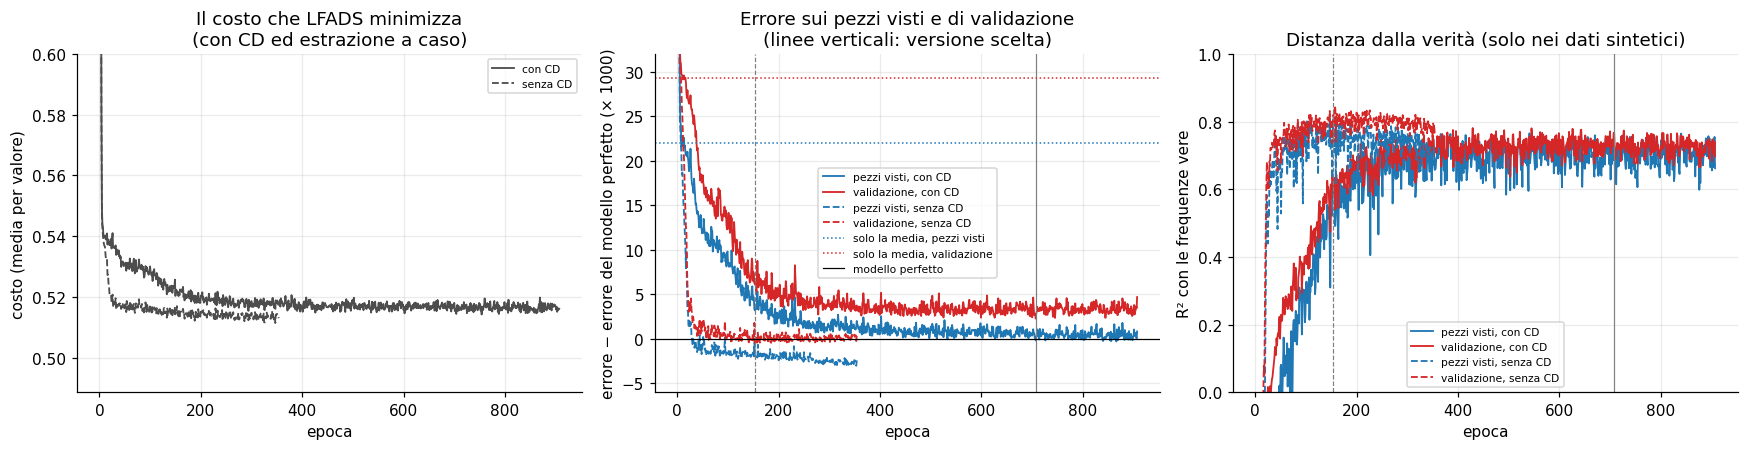

con CD, seme 0: alla versione scelta (epoca 707) errore visti 0.4922, validazione 0.5080; R² frequenze visti 0.728, validazione 0.766; R² di validazione più alto durante l'allenamento 0.781 (epoca 429)
senza CD, seme 0: alla versione scelta (epoca 154) errore visti 0.4904, validazione 0.5052; R² frequenze visti 0.760, validazione 0.820; R² di validazione più alto durante l'allenamento 0.847 (epoca 157)


In [64]:
REF_LZ = {name: {"perfetto": poisson_nll(Xw.astype(float), np.log(truth), exact=False).mean(),  # l'errore con le frequenze vere...
                 "solo la media": poisson_nll(Xw.astype(float), np.broadcast_to(np.log(mean_rate), Xw.shape), exact=False).mean()}  # ...e con la sola frequenza media
          for name, (Xw, truth) in LZ_WATCH.items()}
display(pd.DataFrame(REF_LZ).T.round(4).rename_axis("errore di ricostruzione di riferimento"))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for (v, sd), ls in ((("con CD", 0), "-"), (("senza CD", 0), "--")):
    h_ = res_syn_lf[(v, sd)]["history"]
    best = res_syn_lf[(v, sd)]["best_epoch"]
    ax[0].plot(h_.index, h_["costo di training"], ls, color="0.3", lw=1.2, label=f"{v}")
    for name, c in (("pezzi visti", "C0"), ("validazione", "C3")):  # l'errore come distanza dal modello perfetto di quei pezzi (0 = perfetto)
        ax[1].plot(h_.index, (h_[f"errore, {name}"] - REF_LZ[name]["perfetto"]) * 1000, ls, color=c, lw=1.2, label=f"{name}, {v}")
    for col, c in (("R² frequenze, pezzi visti", "C0"), ("R² frequenze, validazione", "C3")):
        ax[2].plot(h_.index, h_[col], ls, color=c, lw=1.2, label=f"{col.split(', ')[1]}, {v}")
    for a_ in ax[1:]:
        a_.axvline(best, color="0.5", ls=ls, lw=0.8)
for name, c in (("pezzi visti", "C0"), ("validazione", "C3")):
    ax[1].axhline((REF_LZ[name]["solo la media"] - REF_LZ[name]["perfetto"]) * 1000, color=c, ls=":", lw=1, label=f"solo la media, {name}")
ax[1].axhline(0, color="k", lw=0.8, label="modello perfetto")
ax[0].set(xlabel="epoca", ylabel="costo (media per valore)", title="Il costo che LFADS minimizza\n(con CD ed estrazione a caso)", ylim=(None, 0.6))
ax[1].set(xlabel="epoca", ylabel="errore − errore del modello perfetto (× 1000)", ylim=(-6, 32),
          title="Errore sui pezzi visti e di validazione\n(linee verticali: versione scelta)")
ax[2].set(xlabel="epoca", ylabel="R² con le frequenze vere", ylim=(0, 1), title="Distanza dalla verità (solo nei dati sintetici)")
for a_ in ax:
    a_.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_synthetic_training.png", bbox_inches="tight"); plt.show()
for v, sd in (("con CD", 0), ("senza CD", 0)):
    h_ = res_syn_lf[(v, sd)]["history"]
    b_ = res_syn_lf[(v, sd)]["best_epoch"]
    print(f"{v}, seme {sd}: alla versione scelta (epoca {b_}) errore visti {h_.loc[b_, 'errore, pezzi visti']:.4f}, "
          f"validazione {h_.loc[b_, 'errore, validazione']:.4f}; R² frequenze visti {h_.loc[b_, 'R² frequenze, pezzi visti']:.3f}, "
          f"validazione {h_.loc[b_, 'R² frequenze, validazione']:.3f}; R² di validazione più alto durante l'allenamento "
          f"{h_['R² frequenze, validazione'].max():.3f} (epoca {h_['R² frequenze, validazione'].idxmax()})")

**Lettura.**

- **Durata**: con il coordinated dropout ogni allenamento ha fatto 880-960 epoche (versione scelta tra
  l'epoca 678 e la 759), circa 3 minuti; senza, si è fermato a 354 epoche (versione dell'epoca 154).
  Circa 30 ms per passo, misure comprese, con 4 allenamenti in parallelo.
- **LFADS impara.** Sui pezzi di validazione l'errore parte da quello di chi conosce solo la frequenza
  media (0.5351) e con il coordinated dropout scende a 0.5080: chiude il 92% della distanza dal modello
  perfetto (0.5057). Le frequenze arrivano a un R² di 0.77 con quelle vere.
- **Pezzi visti contro pezzi nuovi.** Con il coordinated dropout, sui pezzi visti l'errore arriva proprio
  al livello del modello perfetto (0.4922 contro 0.4924), su quelli di validazione resta un poco sopra: un
  piccolo adattamento ai pezzi su cui impara, normale.
- **Senza coordinated dropout succede la cosa descritta da Keshtkaran & Pandarinath (2019)**: l'errore
  scende **sotto** quello del modello perfetto, sui pezzi visti (0.4904) e persino su quelli di
  validazione (0.5052 contro 0.5057). Nessun modello può spiegare spike nuovi meglio delle frequenze
  vere: se ci "riesce", è perché legge quegli stessi spike e ne ricopia una parte. **L'errore di
  validazione, da solo, non se ne accorge.**
- **Eppure qui la copia non fa danni**: confrontato con la verità, il modello senza coordinated dropout è
  migliore (R² delle frequenze di validazione 0.82 contro 0.77) e impara molto più in fretta (poche
  decine di epoche contro circa 300). Gli autori stessi avvertono che il coordinated dropout può far
  imparare meno quando i neuroni sono pochi, come i nostri 30.
- **L'errore di validazione come giudice**: con il coordinated dropout la versione scelta (epoca 707)
  non è la più vicina alla verità (epoca 429, R² 0.781 contro 0.766); la differenza è piccola.
- **Nella figura**: a sinistra il costo che LFADS minimizza (con il coordinated dropout resta più alto, perché
  deve indovinare valori che non vede); al centro l'errore come distanza dal modello perfetto (lo 0) e da
  chi conosce solo la media (le linee punteggiate): le curve tratteggiate, senza coordinated dropout,
  scendono sotto lo 0; a destra la distanza dalla verità, che con il coordinated dropout sale più lentamente.
- **La conseguenza per il §11**: il coordinated dropout (0 o 0.3) va nella griglia, e la scelta va fatta
  con una misura che la copia non inganna: i **canali nascosti** dei trial di validazione (§9.4).

### 10.7 · Che cosa ha imparato: lo stato di Lorenz e le frequenze, contro GPFA e smoothing

**Le uscite di LFADS su tutta la registrazione.** Ogni pezzo (di training, validazione e test) passa
nel modello allenato, e i pezzi si ricuciono con la regola del §9.2. La funzione `stitch` del §9.2 lavora
sui trial veri; qui ne scriviamo la versione per un tratto qualunque, e controlliamo che sui trial veri
dia lo stesso risultato.

**I termini di confronto, alla pari**, stimati sugli stessi 400 pezzi di training:

- **GPFA** con lo stesso numero di fattori (10), sulla radice dei conteggi, con le impostazioni del 03 e
  del §7b (500 iterazioni, scala di tempo iniziale 100 ms), poi gli stessi pezzi ricuciti allo stesso modo;
- **smoothing**: gli spike smussati con σ = 50 ms (la scelta del 02_new), senza nessun modello.

**Le misure, sui 20 s di test**, che nessun metodo ha visto:

1. **lo stato di Lorenz**: una regressione lineare dai fattori (o dai 30 neuroni smussati) alle 3
   variabili vere, stimata sui 160 s di training e giudicata sul test (R² per variabile). È la misura di
   Sussillo et al. (2016), Tabella 1;
2. **le frequenze**: quanto le frequenze stimate somigliano a quelle vere, neurone per neurone, con due
   misure: l'**R²** (conta anche la scala: una stima giusta nella forma ma doppia dà un R² basso) e la
   **correlazione** (guarda solo la forma). Ogni metodo dà le frequenze secondo il **proprio modello**:
   - LFADS: le sue frequenze;
   - GPFA: il suo modello descrive la **radice** dei conteggi, √k, come una previsione μ più un rumore
     gaussiano di varianza R (una per neurone). Il valore atteso del conteggio è quindi
     E[k] = E[(√k)²] = μ² + R. Rielevare al quadrato la sola previsione, μ², sottostimerebbe molto
     le frequenze, perché con conteggi così piccoli la radice "schiaccia" i valori;
   - smoothing: gli spike smussati stessi.

   Abbiamo provato anche una regressione di Poisson (GLM) per neurone, dai fattori agli spike, come fa il
   Neural Latents Benchmark per la GPFA: qui la scartiamo, perché la regressione impara a ricopiare gli
   spike che riceve in ingresso, e sul test l'esponenziale fa esplodere le previsioni (lo mostriamo
   sotto).

Non misuriamo qui i bit per spike: sui pezzi di test ogni metodo legge gli stessi spike che poi
"predice", e il confronto con quegli spike premierebbe chi copia (§9.4). Con le frequenze vere questo
problema non c'è.

In [65]:
from sklearn.linear_model import PoissonRegressor           # regressione di Poisson (GLM): dai fattori agli spike di un neurone

def stitch_at(Y_seg, starts, a0, a1):                       # la ricucitura del §9.2 per un tratto qualunque [a0, a1) con i pezzi che cominciano in `starts`
    num, den = np.zeros((a1 - a0, Y_seg.shape[2])), np.zeros((a1 - a0, 1))
    for a, y, w in zip(np.asarray(starts) - a0, Y_seg, segment_weights(len(Y_seg))):
        num[a:a + SEG_LEN] += w[:, None] * y
        den[a:a + SEG_LEN] += w[:, None]
    return num / den

print("La ricucitura per un tratto qualunque coincide con quella del §9.2 sui trial veri:",
      all(np.array_equal(stitch_at(SEGS[t], SEG_START[t], *TRIAL_SPAN[t]), stitch(SEGS[t], t)) for t in TRIALS))

def stitch_lz(per_part):                                    # ricuce le uscite delle tre parti (impara, validazione, test) e le mette in fila: 10 000 bin
    return np.concatenate([stitch_at(Y, LZ_START[k], *LZ_PARTS[k]) for k, Y in zip(LZ_PARTS, per_part)])

FIT_LZ, TEST_LZ = slice(*LZ_PARTS["impara"]), slice(*LZ_PARTS["test"])  # i bin su cui si stimano le regressioni, e quelli di test

def gpfa_seqs(segs):                                        # pezzi di conteggi -> il formato di elephant, con la radice dei conteggi (come nel 03 e nel §7b)
    return np.array([(s_.shape[0], np.sqrt(s_.astype(float)).T) for s_ in segs], dtype=[("T", int), ("y", "O")])

def gpfa_fit_segments(segs, x_dim):                         # GPFA con x_dim fattori stimata sui pezzi dati
    np.random.seed(0)                                       # punto di partenza fisso
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        params, _ = gpfa_core.fit(gpfa_seqs(segs), x_dim=x_dim, bin_width=20.0, em_max_iters=500, tau_init=100.0)
    return params

def gpfa_sqrt_pred(segs, params):                           # la previsione μ = C x + d della GPFA per la radice dei conteggi, in ogni pezzo: (pezzi, bin, neuroni)
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(gpfa_seqs(segs), params, get_ll=False)
    return np.stack([(params["C"] @ x_ + params["d"][:, None]).T for x_ in lat["latent_variable"]])

def gpfa_infer_segments(segs, params):                      # i fattori ordinati (orthonormalize) di ogni pezzo: (pezzi, bin, fattori)
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(gpfa_seqs(segs), params, get_ll=False)
        _, orth = gpfa_core.orthonormalize(params, lat)
    return np.stack([x_.T for x_ in orth["latent_variable_orth"]])

GP_LZ = gpfa_fit_segments(LZ_SEGS["impara"], SYN_HP["fac_dim"])  # la GPFA alla pari: stessi pezzi, 10 fattori
F_GP_LZ = stitch_lz([gpfa_infer_segments(LZ_SEGS[k], GP_LZ) for k in LZ_PARTS])  # i suoi fattori su tutta la registrazione
SM_LZ = np.concatenate([gaussian_filter1d(SPK_LZ[a0:a1].astype(float), sigma=50 / 20, axis=0, mode="nearest")  # smoothing σ = 50 ms (2.5 bin),
                        for a0, a1 in LZ_PARTS.values()])   # parte per parte, come i pezzi

def lorenz_r2(F):                                           # R² delle 3 variabili di Lorenz ricavate linearmente da F (stimato sul training, giudicato sul test)
    reg = LinearRegression().fit(F[FIT_LZ], LZ_Z[FIT_LZ])
    return r2_score(LZ_Z[TEST_LZ], reg.predict(F[TEST_LZ]), multioutput="raw_values")

def rate_r2(R):                                             # R² tra frequenze stimate e vere sul test, medio sui 30 neuroni
    return float(np.mean(r2_score(RATE_LZ[TEST_LZ], R[TEST_LZ], multioutput="raw_values")))

def rate_corr(R):                                           # correlazione tra frequenze stimate e vere sul test, media sui 30 neuroni
    return float(np.mean([np.corrcoef(RATE_LZ[TEST_LZ, n], R[TEST_LZ, n])[0, 1] for n in range(N_NEU)]))

def glm_rates(F):                                           # frequenze da una regressione di Poisson per neurone, dai fattori agli spike, stimata sul training
    sc = StandardScaler().fit(F[FIT_LZ])
    Fs = sc.transform(F)
    return np.column_stack([PoissonRegressor(alpha=1e-4, max_iter=1000).fit(Fs[FIT_LZ], SPK_LZ[FIT_LZ, n]).predict(Fs)
                            for n in range(N_NEU)])

F_LF_LZ = {run: stitch_lz(r["factors"]) for run, r in res_syn_lf.items()}  # i fattori di LFADS ricuciti, per ogni allenamento
R_LF_LZ = {run: stitch_lz(r["rates"]) for run, r in res_syn_lf.items()}    # le sue frequenze ricucite
R_GP_LZ = stitch_lz([gpfa_sqrt_pred(LZ_SEGS[k], GP_LZ) for k in LZ_PARTS]) ** 2 + np.diag(GP_LZ["R"])  # le frequenze della GPFA: μ² + R

def lz_row(F, R):                                           # una riga della tabella: stato (da F) e frequenze (R)
    return {**dict(zip("xyz", lorenz_r2(F))), "frequenze: R²": rate_r2(R), "frequenze: correlazione": rate_corr(R)}

rows_lz = {"smoothing σ = 50 ms (30 neuroni)": [lz_row(SM_LZ, SM_LZ)],
           "GPFA, 10 fattori": [lz_row(F_GP_LZ, R_GP_LZ)]}
for v in ("con CD", "senza CD"):
    rows_lz[f"LFADS, 10 fattori, {v}"] = [lz_row(F_LF_LZ[(v_, sd)], R_LF_LZ[(v_, sd)]) for v_, sd in SYN_RUNS if v_ == v]

def cell_fmt(vals):                                         # "media (minimo-massimo)" se ci sono più semi
    vals = np.array([x_ for x_ in vals if x_ is not None and not np.isnan(x_)])
    if len(vals) == 0:
        return ""
    return f"{vals.mean():.3f}" if len(vals) == 1 else f"{vals.mean():.3f} ({vals.min():.3f}-{vals.max():.3f})"

COLS_LZ = ["x", "y", "z", "frequenze: R²", "frequenze: correlazione"]
tab_lz = pd.DataFrame({name: {c: cell_fmt([r_.get(c, np.nan) for r_ in runs]) for c in COLS_LZ} for name, runs in rows_lz.items()}).T
tab_lz.loc["Sussillo et al. 2016 (altri dati): GPFA"] = ["0.713", "0.725", "0.325", "", ""]
tab_lz.loc["Sussillo et al. 2016 (altri dati): LFADS"] = ["0.826", "0.900", "0.821", "", ""]
display(tab_lz.rename(columns={"x": "stato: R² di x", "y": "stato: R² di y", "z": "stato: R² di z"}))
print(f"Media delle frequenze sul test (spike per bin): vere {RATE_LZ[TEST_LZ].mean():.3f}; GPFA con μ² + R {R_GP_LZ[TEST_LZ].mean():.3f}, "
      f"con μ² soltanto {(R_GP_LZ - np.diag(GP_LZ['R']))[TEST_LZ].mean():.3f}; LFADS (seme 0) {R_LF_LZ[('con CD', 0)][TEST_LZ].mean():.3f}")
glm_max = {name: glm_rates(F)[TEST_LZ].max() / io.BIN_S for name, F in (("smoothing", SM_LZ), ("GPFA", F_GP_LZ), ("LFADS (seme 0)", F_LF_LZ[("con CD", 0)]))}
print("Alternativa scartata, il GLM dai fattori agli spike: frequenza massima prevista sul test (spike/s)",
      {k: round(v) for k, v in glm_max.items()}, f"| vera al massimo {RATE_LZ[TEST_LZ].max() / io.BIN_S:.0f}")

La ricucitura per un tratto qualunque coincide con quella del §9.2 sui trial veri: True


,stato: R² di x,stato: R² di y,stato: R² di z,frequenze: R²,frequenze: correlazione
smoothing σ = 50 ms (30 neuroni),0.823,0.800,0.863,-4.870,0.507
"GPFA, 10 fattori",0.899,0.851,0.886,0.505,0.880
"LFADS, 10 fattori, con CD",0.962 (0.959-0.965),0.940 (0.935-0.948),0.900 (0.888-0.922),0.820 (0.798-0.840),0.933 (0.925-0.939)
"LFADS, 10 fattori, senza CD",0.968,0.956,0.948,0.880,0.952
Sussillo et al. 2016 (altri dati): GPFA,0.713,0.725,0.325,,
Sussillo et al. 2016 (altri dati): LFADS,0.826,0.900,0.821,,


Media delle frequenze sul test (spike per bin): vere 0.199; GPFA con μ² + R 0.197, con μ² soltanto 0.043; LFADS (seme 0) 0.196


Alternativa scartata, il GLM dai fattori agli spike: frequenza massima prevista sul test (spike/s) {'smoothing': 1563, 'GPFA': 354, 'LFADS (seme 0)': 106} | vera al massimo 155


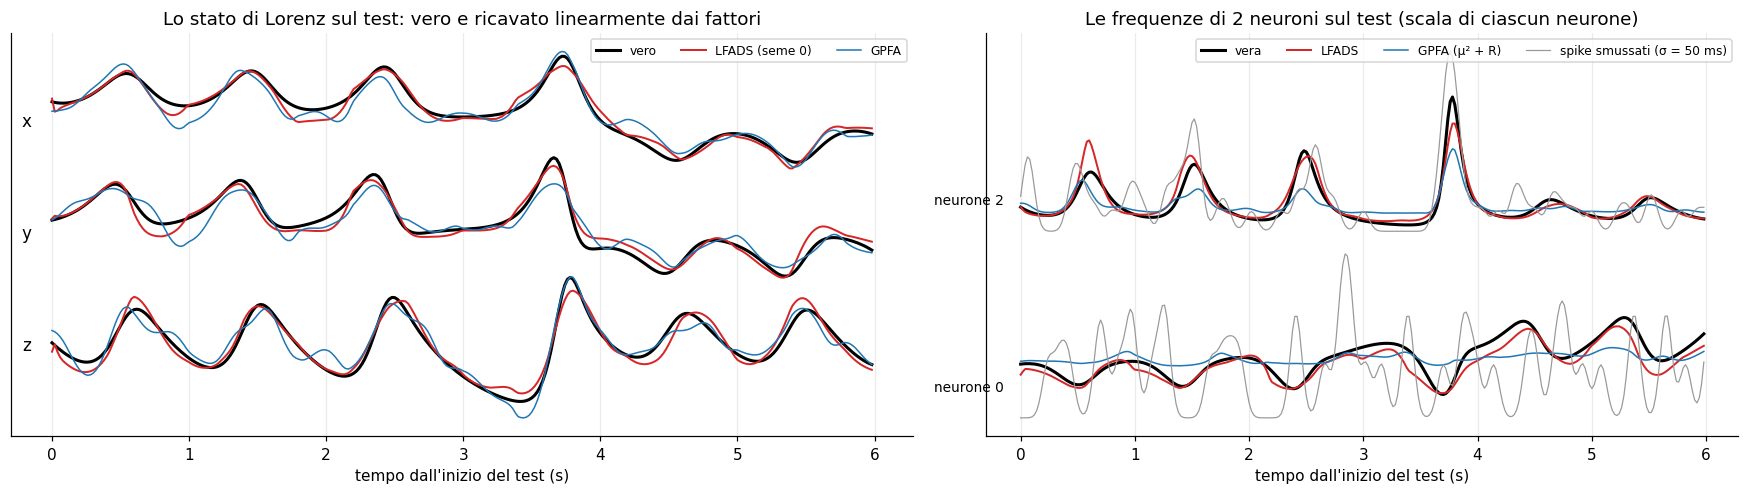

In [66]:
show_t = slice(LZ_PARTS["test"][0], LZ_PARTS["test"][0] + 300)  # i primi 6 s del test
t_s = np.arange(300) * io.BIN_S
reg_lf = LinearRegression().fit(F_LF_LZ[("con CD", 0)][FIT_LZ], LZ_Z[FIT_LZ])  # le mappe lineari stimate sul training
reg_gp = LinearRegression().fit(F_GP_LZ[FIT_LZ], LZ_Z[FIT_LZ])
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": (1.2, 1)})
for j, lab in enumerate("xyz"):
    off = 4 * (2 - j)
    ax[0].plot(t_s, LZ_Z[show_t, j] + off, color="k", lw=2, label="vero" if j == 0 else None)
    ax[0].plot(t_s, reg_lf.predict(F_LF_LZ[("con CD", 0)][show_t])[:, j] + off, color="C3", lw=1.3, label="LFADS (seme 0)" if j == 0 else None)
    ax[0].plot(t_s, reg_gp.predict(F_GP_LZ[show_t])[:, j] + off, color="C0", lw=1.0, label="GPFA" if j == 0 else None)
    ax[0].text(-0.15, off, lab, fontsize=11, ha="right", va="center")
ax[0].set(xlabel="tempo dall'inizio del test (s)", yticks=[], title="Lo stato di Lorenz sul test: vero e ricavato linearmente dai fattori")
ax[0].legend(fontsize=8, loc="upper right", ncol=3)
for n_, off in ((0, 0), (2, 1)):
    sc_ = RATE_LZ[:, n_].max() / io.BIN_S
    ax[1].plot(t_s, RATE_LZ[show_t, n_] / io.BIN_S / sc_ + off * 1.2, color="k", lw=2, label="vera" if n_ == 0 else None)
    ax[1].plot(t_s, R_LF_LZ[("con CD", 0)][show_t, n_] / io.BIN_S / sc_ + off * 1.2, color="C3", lw=1.3, label="LFADS" if n_ == 0 else None)
    ax[1].plot(t_s, R_GP_LZ[show_t, n_] / io.BIN_S / sc_ + off * 1.2, color="C0", lw=1.0, label="GPFA (μ² + R)" if n_ == 0 else None)
    ax[1].plot(t_s, SM_LZ[show_t, n_] / io.BIN_S / sc_ + off * 1.2, color="0.6", lw=0.8, label="spike smussati (σ = 50 ms)" if n_ == 0 else None)
    ax[1].text(-0.15, off * 1.2 + 0.2, f"neurone {n_}", fontsize=9, ha="right", va="center")
ax[1].set(xlabel="tempo dall'inizio del test (s)", yticks=[], title="Le frequenze di 2 neuroni sul test (scala di ciascun neurone)")
ax[1].legend(fontsize=8, loc="upper right", ncol=4)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_synthetic_recovery.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **LFADS ritrova lo stato di Lorenz meglio della GPFA**: R² 0.96 contro 0.90 per x e 0.94 contro 0.85
  per y, con tutti e tre i semi; per z la differenza è piccola (0.90 contro 0.89, e il seme peggiore di
  LFADS, 0.888, è alla pari con la GPFA). Lo smoothing sta sotto entrambi (0.80-0.86) pur partendo da 30
  numeri invece che da 10.
- **La GPFA qui va molto meglio che nell'articolo** (z: 0.89 contro 0.33). I dati sono diversi: un
  sistema più lento rispetto ai bin, una registrazione continua, 10 fattori. Il grande distacco di
  Sussillo et al. su z non si riproduce; quello su x e y sì, più piccolo.
- **Le frequenze**: LFADS arriva a un R² di 0.82 (0.80-0.84) con quelle vere, la GPFA a 0.51, lo
  smoothing a un valore negativo (−4.9: il rumore degli spike smussati è più grande delle variazioni
  vere). Guardando solo la forma (correlazione) la distanza si riduce: 0.93 contro 0.88. Nella figura si
  vede perché: dove la sua previsione μ è vicina a 0, le frequenze della GPFA non scendono sotto il
  livello del rumore R, e restano quasi piatte (neurone 0).
- **La formula conta**: rielevando al quadrato la sola previsione della GPFA la frequenza media sul test
  sarebbe 0.043 spike per bin invece di 0.199; con μ² + R è 0.197, giusta. LFADS dà 0.196.
- **Il GLM scartato**: dagli spike smussati prevede sul test fino a 1563 spike/s, dalla GPFA fino a 354,
  quando le frequenze vere non superano i 155. Ricopia gli spike in ingresso, e l'esponenziale amplifica.
- **Che cosa non dice**: questi dati sono generati **esattamente** con le ipotesi di LFADS (frequenze =
  esponenziale di una combinazione lineare, rumore di Poisson, regole del moto fisse, nessun ingresso
  esterno). L'esempio mostra che LFADS funziona quando le sue ipotesi valgono, non che vincerà sui dati
  veri. Un solo esempio sintetico, parametri non ottimizzati, GPFA con 10 fattori non scelti con la
  cross-validation.

### 10.8 · Controlli

Quattro controlli, tutti veloci:

- **(a) Le cuciture.** Nei 200 ms in comune tra due pezzi, quanto differiscono i fattori dati dal pezzo
  che finisce e da quello che comincia? E in quale punto del pezzo LFADS è più preciso? Se i bordi
  fossero molto peggio del centro, la ricucitura con i pesi graduali sarebbe tanto più importante.
- **(b) Il calcolo a mano con i pesi allenati**: il confronto del §10.3 era con i pesi iniziali, a caso.
  Lo rifacciamo con i pesi del modello allenato (seme 0), sui pezzi di test.
- **(c) Il seme**: due allenamenti brevi (15 epoche) con lo stesso seme devono essere identici, bit per
  bit; uno con un altro seme deve essere diverso. Non si salvano su disco: si rifanno a ogni esecuzione.
- **(d) I tempi**: millisecondi per passo di allenamento sulla CPU e sulla GPU del Mac (MPS), per la
  forma dei dati sintetici e per quella dei dati veri (160 canali, 25 fattori), un allenamento alla
  volta.

In [67]:
R_lf_test = res_syn_lf[("con CD", 0)]["factors"][2]         # i fattori dei 50 pezzi di test, non ricuciti (seme 0)
R_gp_test = gpfa_infer_segments(LZ_SEGS["test"], GP_LZ)     # gli stessi per la GPFA
st_test = LZ_START["test"]

def seam_gap(Fseg, starts):                                 # nelle zone comuni a due pezzi consecutivi: differenza media tra i loro fattori, in deviazioni standard
    sd_ = Fseg.reshape(-1, Fseg.shape[2]).std(0)
    gaps = []
    for i in range(len(starts) - 1):
        ov = starts[i] + SEG_LEN - starts[i + 1]            # quanti bin hanno in comune
        if ov > 0:
            gaps.append(np.abs(Fseg[i, -ov:] - Fseg[i + 1, :ov]) / sd_)
    return float(np.mean(np.concatenate(gaps)))

print(f"(a) Zone comuni tra pezzi consecutivi: i fattori dei due pezzi differiscono in media di {seam_gap(R_lf_test, st_test):.2f} "
      f"deviazioni standard (LFADS) e di {seam_gap(R_gp_test, st_test):.2f} (GPFA)")
pos_r2 = [np.mean(r2_score(LZ_TRUE_SEGS["test"][:, p_], res_syn_lf[("con CD", 0)]["rates"][2][:, p_], multioutput="raw_values"))
          for p_ in range(SEG_LEN)]                         # R² delle frequenze di LFADS, posizione per posizione dentro il pezzo
print("    R² delle frequenze di LFADS per posizione nel pezzo (bin 1, 5, 10, 15, 20, 25, 30):",
      [round(float(pos_r2[p_]), 3) for p_ in (0, 4, 9, 14, 19, 24, 29)])
W_auto = segment_weights(len(st_test))                      # tre modi di ricucire le frequenze di test: i pesi di AutoLFADS (§9.2)...
W_flat = np.ones_like(W_auto)                               # ...la media semplice...
W_cut = np.ones_like(W_auto); W_cut[1:, :SEG_OVL // 2] = 1e-12; W_cut[:-1, -SEG_OVL // 2:] = 1e-12  # ...e il taglio netto a metà della zona comune

def stitch_test_w(Y_seg, W):                                # ricucitura dei pezzi di test con pesi dati
    a0, a1 = LZ_PARTS["test"]
    num, den = np.zeros((a1 - a0, Y_seg.shape[2])), np.zeros((a1 - a0, 1))
    for a, y, w in zip(st_test - a0, Y_seg, W):
        num[a:a + SEG_LEN] += w[:, None] * y
        den[a:a + SEG_LEN] += w[:, None]
    return num / den

print("    R² delle frequenze di test ricucite:", {lab: round(float(np.mean(r2_score(RATE_LZ[TEST_LZ], stitch_test_w(res_syn_lf[("con CD", 0)]["rates"][2], W_),
                                                                                 multioutput="raw_values"))), 3)
                                               for lab, W_ in (("pesi di AutoLFADS", W_auto), ("media semplice", W_flat), ("taglio a metà", W_cut))})

W_tr = res_syn_lf[("con CD", 0)]["weights"]                 # (b) i pesi allenati, come array numpy
MINE_tr = lfads_forward_np(LZ_SEGS["test"].astype(np.float64), {k: v.astype(np.float64) for k, v in W_tr.items()}, SYN_HP)
print(f"(b) Pesi allenati, 50 pezzi di test: differenza massima a mano − libreria nei fattori "
      f"{np.abs(MINE_tr['factors'] - R_lf_test).max():.1e} (valori fino a {np.abs(R_lf_test).max():.2f}), nelle frequenze "
      f"{np.abs(np.exp(MINE_tr['log_rates']) - res_syn_lf[('con CD', 0)]['rates'][2]).max():.1e}")

short = [POOL_LF.submit(lfads_fit, **dict(syn_job(SYN_HP, sd), max_epochs=15, watch=None)) for sd in (0, 0, 1)]  # (c) due volte il seme 0, una il seme 1
short = [f_.result() for f_ in short]
same_w = all(np.array_equal(short[0]["weights"][k], short[1]["weights"][k]) for k in short[0]["weights"])
diff_w = max(np.abs(short[0]["weights"][k] - short[2]["weights"][k]).max() for k in short[0]["weights"] if short[0]["weights"][k].size)  # (i pesi del controller spento hanno 0 elementi)
print(f"(c) Seme 0 due volte: pesi identici bit per bit {same_w}, costo identico a ogni epoca "
      f"{[h_['costo di training'] for h_ in short[0]['history']] == [h_['costo di training'] for h_ in short[1]['history']]}; "
      f"seme 1: differenza massima nei pesi {diff_w:.2f}")

def lfads_step_time(hp, device, n_steps=30, n_seg=256, seed=0):
    """Millisecondi per passo di allenamento (mediana dopo 5 passi di riscaldamento), su dati finti della forma di hp."""
    import time
    import numpy as np                                      # numpy PRIMA di torch
    import torch
    from lfads_torch.tuples import SessionBatch
    torch.set_num_threads(1); torch.manual_seed(seed)
    model = make_lfads(hp)
    model.__class__ = type("LFADSconEpoca", (type(model),), {"current_epoch": 0})
    model = model.to(device); model.train()
    model.log = model.log_dict = lambda *a, **k: None
    opt = model.configure_optimizers()
    X = torch.tensor(np.random.default_rng(seed).poisson(0.2, size=(n_seg, hp["seg_len"], hp["n_out"])), dtype=torch.float32, device=device)
    times = []
    for s_ in range(n_steps):
        idx = torch.randint(0, n_seg, (64,), device=device)
        sb = SessionBatch(X[idx][..., :hp["n_in"]], X[idx], torch.zeros(64, hp["seg_len"], 0, device=device), torch.zeros(0), torch.ones_like(X[idx]))
        t0 = time.time()
        loss = model._shared_step({0: (sb, ())}, s_, "train")
        opt.zero_grad(); loss.backward(); opt.step()
        if device == "mps":
            torch.mps.synchronize()                         # sulla GPU i calcoli sono asincroni: si aspetta che finiscano
        times.append(time.time() - t0)
    return float(np.median(times[5:]) * 1000)

REAL_SHAPE = dict(SYN_HP, n_in=N_CH, n_out=N_CH, fac_dim=25, kl_ic_scale=1 / (SEG_LEN * N_CH))  # la forma dei dati veri
tab_time = pd.DataFrame({name: {dev: POOL_LF.submit(lfads_step_time, hp_, dev).result() for dev in ("cpu", "mps")}  # uno alla volta
                         for name, hp_ in (("dati sintetici (30 neuroni, 10 fattori)", SYN_HP),
                                           ("forma dei dati veri (160 canali, 25 fattori)", REAL_SHAPE))}).T
tab_time["GPU / CPU"] = tab_time["mps"] / tab_time["cpu"]
display(tab_time.rename(columns={"cpu": "CPU (ms per passo)", "mps": "GPU del Mac, MPS (ms per passo)"}).round(1))

(a) Zone comuni tra pezzi consecutivi: i fattori dei due pezzi differiscono in media di 0.41 deviazioni standard (LFADS) e di 0.35 (GPFA)
    R² delle frequenze di LFADS per posizione nel pezzo (bin 1, 5, 10, 15, 20, 25, 30): [0.44, 0.795, 0.832, 0.83, 0.87, 0.821, 0.742]
    R² delle frequenze di test ricucite: {'pesi di AutoLFADS': 0.84, 'media semplice': 0.833, 'taglio a metà': 0.835}
(b) Pesi allenati, 50 pezzi di test: differenza massima a mano − libreria nei fattori 1.6e-06 (valori fino a 2.23), nelle frequenze 5.9e-07


(c) Seme 0 due volte: pesi identici bit per bit True, costo identico a ogni epoca True; seme 1: differenza massima nei pesi 1.15


,CPU (ms per passo),"GPU del Mac, MPS (ms per passo)",GPU / CPU
"dati sintetici (30 neuroni, 10 fattori)",22.7,144.6,6.4
"forma dei dati veri (160 canali, 25 fattori)",31.4,145.2,4.6


**Lettura.**

- **(a) Le cuciture contano meno del previsto, ma i bordi dei pezzi sono deboli.** Nella zona comune i
  fattori dei due pezzi differiscono in media di 0.41 deviazioni standard (GPFA: 0.35): i due pezzi non
  sono d'accordo, soprattutto vicino ai bordi. Dentro il pezzo LFADS è preciso al centro (R² 0.83-0.87)
  e peggio ai bordi: 0.74 all'ultimo bin, **0.44 al primo**. I pesi di AutoLFADS danno poco peso proprio
  all'inizio del pezzo nuovo, ma rispetto alla media semplice o a un taglio netto la differenza è minima
  (R² 0.840, 0.833, 0.835). **Per i dati veri**: il primo pezzo di ogni trial non ha un pezzo prima, quindi
  i primi 100 ms circa di ogni trial (la coda del `Release` precedente, §1.5) saranno meno affidabili.
- **(b) Il calcolo a mano coincide con la libreria anche con i pesi allenati**: differenza massima
  1.6·10⁻⁶ nei fattori (che arrivano a 2.2) e 6·10⁻⁷ nelle frequenze.
- **(c) Il seme funziona**: due allenamenti con lo stesso seme danno pesi identici bit per bit e lo stesso
  costo a ogni epoca; con un altro seme i pesi sono diversi. Vale su questo computer, con queste versioni
  (torch 2.7.1, CPU); per questo i modelli si salvano su disco.
- **(d) La CPU è più veloce della GPU**, da 4 a 7 volte. I millisecondi esatti cambiano a ogni esecuzione
  e con il carico del computer (quelli dell'ultima sono nella tabella; in tutte le esecuzioni fatte sono
  stati tra 20 e 60 ms per passo sulla CPU e tra 140 e 260 sulla GPU, i più alti con il Mac in modalità
  di risparmio energetico). Per i dati veri: circa 400 pezzi per blocco, quindi circa 5 minuti
  per allenamento, 4 alla volta.

### Riepilogo del §10

| domanda | risposta | dove |
|---|---|---|
| LFADS scritto a mano coincide con la libreria? | sì: 10⁻⁷ con i pesi iniziali, 10⁻⁶ con quelli allenati; il confronto vede un cambio di 0.001 in un solo peso | §10.3, §10.8 |
| il costo a mano coincide? | sì, nei tre termini; il peso del KL 1/(bin × neuroni) dà l'ELBO vero; la libreria approssima log k! con Stirling (non cambia l'allenamento) | §10.4 |
| LFADS ritrova lo stato nascosto? | sì: R² 0.96, 0.94, 0.90 (GPFA 0.90, 0.85, 0.89; smoothing 0.82, 0.80, 0.86) | §10.7 |
| e le frequenze? | R² 0.82 contro 0.51 della GPFA (correlazione 0.93 contro 0.88) | §10.7 |
| serve il coordinated dropout? | qui no: senza, LFADS è più vicino alla verità; ma l'errore di validazione scende sotto il modello perfetto (copia), quindi non è un giudice affidabile | §10.6 |
| i bordi dei pezzi? | il primo bin di un pezzo è molto peggio del centro (R² 0.44 contro 0.83-0.87); la ricucitura con i pesi aiuta poco | §10.8 |
| riproducibilità e tempi | stesso seme = stesso modello; CPU 4-7 volte più veloce della GPU; circa 3 minuti per modello sintetico | §10.6, §10.8 |

**Che cosa portiamo ai dati veri**: i parametri di `SYN_HP` come punto di partenza, il coordinated
dropout (0 o 0.3) e il peso del KL nella griglia del §11, la scelta con i canali nascosti dei trial di
validazione, la CPU con 4 allenamenti in parallelo.

**Che cosa non abbiamo verificato**: un solo sistema sintetico, costruito con le ipotesi di LFADS;
parametri non ottimizzati; GPFA con 10 fattori fissati da noi; la copia senza coordinated dropout l'abbiamo
vista nell'errore, non misurata direttamente.

## 11 · LFADS sui dati veri: un primo allenamento

Prima di misurare qualunque cosa con il metro comune (§12), guardiamo LFADS al lavoro sui dati veri,
con **una sola configurazione**, nel **blocco 0** (trial di test 3, 8 e 14, che qui non si guardano).
Il §11 è diviso in due parti:

- **§11a (questa)**: un primo allenamento. Sta imparando o sta memorizzando? Che aspetto hanno le
  frequenze ricostruite? Sa generare trial finti credibili?
- **§11b**: la piccola griglia di parametri, scelta sui soli trial di validazione.

### 11.1 · La configurazione di partenza, e due forme del modello

**I parametri** sono quelli dell'esempio sintetico (`SYN_HP`, §10.3), con tre cambiamenti dovuti ai dati:

| parametro | sintetico | dati veri | perché |
|---|---|---|---|
| canali | 30 | 160 | i canali attivi (§9.1) |
| fattori | 10 | **25** | lo stesso numero della GPFA (02_new, §10.2): il confronto alla pari del §12 |
| peso del termine KL | 1 / (30 × 30) | 1 / (30 bin × 160 canali) | sempre l'ELBO vero (§10.4) |

Coordinated dropout 0.3, dropout 0.05, encoder, condizione iniziale e generatore da 64: come nel §10.
Nel §10b senza coordinated dropout LFADS andava meglio, ma il suo errore di validazione non vedeva la
copia; partiamo quindi dalla versione protetta, e la scelta la fa la griglia del §11b.

**Due forme dello stesso modello**:

- **tutti i canali**: l'encoder legge i 160 canali e il modello li ricostruisce tutti. È la forma che
  useremo per il metro comune (§12);
- **120 visibili + 40 nascosti** (§9.4): l'encoder legge solo i 120 visibili, ma il modello ricostruisce
  tutti i 160. Durante l'allenamento i 40 nascosti servono solo come "risposte" da indovinare; nei trial
  di validazione e di test il modello non li vede mai. I **bit per spike sui canali nascosti** sono la
  misura che la copia del §10.6 non può ingannare: un canale che l'encoder non legge non si può
  ricopiare.

**Due coppie di validazione**, come per CEBRA (§3.2): 12 e 15 (la regola del §9.3), e 6 e 7, a metà
sessione, con un altro seme. In tutti i casi LFADS impara sugli altri 10 trial di training del blocco 0.

**Che cosa misuriamo a ogni epoca**, su due gruppi di trial della stessa forma (due trial, uno pari e uno
dispari): i trial **4 e 5**, che il modello vede (come al §3.2), e i 2 trial di **validazione**. In
**bit per spike**, cioè quanto il modello spiega gli spike meglio di chi conosce solo la frequenza media
di ogni canale (§9.4): sui canali che l'encoder legge e, per la seconda forma, sui canali nascosti.

Le uscite dei trial di test vengono calcolate e salvate per il §12, ma qui non si guardano.

4 allenamenti (2 forme × 2 coppie di validazione), uno per processo: circa 7 minuti la prima volta.

In [68]:
REAL_HP = dict(SYN_HP, n_in=N_CH, n_out=N_CH, fac_dim=K_PCA,  # 160 canali, 25 fattori come la GPFA
               kl_ic_scale=1 / (SEG_LEN * N_CH))            # il peso del KL che dà l'ELBO vero: 1 / (30 bin × 160 canali)
HID_HP = dict(REAL_HP, n_in=len(HELD_IN))                   # l'encoder legge solo i 120 canali visibili; si ricostruiscono tutti i 160
ORDER_HID = np.r_[HELD_IN, HIDDEN]                          # i canali riordinati: prima i 120 visibili, poi i 40 nascosti
SEGS_HID = {t: SEGS[t][..., ORDER_HID] for t in TRIALS}     # i pezzi con i canali in quest'ordine
HID_COLS = list(range(len(HELD_IN), N_CH))                  # le colonne dei canali nascosti dopo il riordino: 120-159

def real_job(hp, seed, val_trials, segs, hidden=None, k=0):  # un allenamento sui dati veri nel blocco k: impara sui trial di training tranne val_trials
    fit = [int(t) for t in TRIALS if t not in TEST_TRIALS[k] and t not in val_trials]  # i 10 trial su cui impara
    hid = [] if hidden is None else [hidden]                # le colonne nascoste all'encoder (se ci sono)
    return dict(hp=hp, seed=seed, train=np.concatenate([segs[t] for t in fit]),
                val=np.concatenate([segs[t] for t in val_trials]),
                apply=[segs[t] for t in TRIALS],             # le uscite di tutti i 15 trial (quelle di test servono al §12)
                watch={"trial visti (4, 5)": (np.concatenate([segs[t] for t in CHECK_TRIALS]), None, *hid),
                       "validazione": (np.concatenate([segs[t] for t in val_trials]), None, *hid)})

FORMS = {"tutti i canali": (REAL_HP, SEGS, None), "120 visibili + 40 nascosti": (HID_HP, SEGS_HID, HID_COLS)}
RUNS_11 = [(form, vt, sd) for vt, sd in ((VAL_TRIALS, 0), (VAL_TRIALS_B, 1)) for form in FORMS]  # (forma, coppia di validazione, seme)
res11 = dict(zip(RUNS_11, run_lfads_cached([real_job(FORMS[f][0], sd, vt, FORMS[f][1], FORMS[f][2]) for f, vt, sd in RUNS_11])))
n_par_real = sum(v.size for k_, v in res11[RUNS_11[0]]["weights"].items() if not k_.endswith("bias_hh"))
print(f"Parametri del modello (tutti i canali): {n_par_real}; pezzi su cui impara: {len(real_job(REAL_HP, 0, VAL_TRIALS, SEGS)['train'])}")

rows11 = {}
for (f, vt, sd), r in res11.items():
    h_, b_ = r["history"], r["best_epoch"]
    row = {"epoche": r["epochs"], "epoca scelta": b_, "durata (minuti)": round(r["seconds"] / 60, 1)}
    for g in ("trial visti (4, 5)", "validazione"):         # i bit per spike alla versione scelta
        if f == "tutti i canali":
            row[f"bit/spike, {g}"] = round(h_.loc[b_, f"bit per spike, {g}"], 3)
        else:
            row[f"bit/spike, {g}"] = round(h_.loc[b_, f"bit per spike visibili, {g}"], 3)
            row[f"bit/spike nascosti, {g}"] = round(h_.loc[b_, f"bit per spike nascosti, {g}"], 3)
    rows11[f"{f}; validazione {vt[0]}-{vt[1]} (seme {sd})"] = row
display(pd.DataFrame(rows11).T.fillna(""))

Allenamenti LFADS: 0 eseguiti ora, 4 riletti dal disco
Parametri del modello (tutti i canali): 125568; pezzi su cui impara: 400


,epoche,epoca scelta,durata (minuti),"bit/spike, trial visti (4, 5)","bit/spike, validazione","bit/spike nascosti, trial visti (4, 5)","bit/spike nascosti, validazione"
tutti i canali; validazione 12-15 (seme 0),1000.0,929.0,5.8,0.030,0.019,,
120 visibili + 40 nascosti; validazione 12-15 (seme 0),437.0,237.0,2.8,0.021,0.015,0.029,0.011
tutti i canali; validazione 6-7 (seme 1),802.0,602.0,4.9,0.030,0.024,,
120 visibili + 40 nascosti; validazione 6-7 (seme 1),585.0,385.0,3.8,0.029,0.028,0.041,0.015


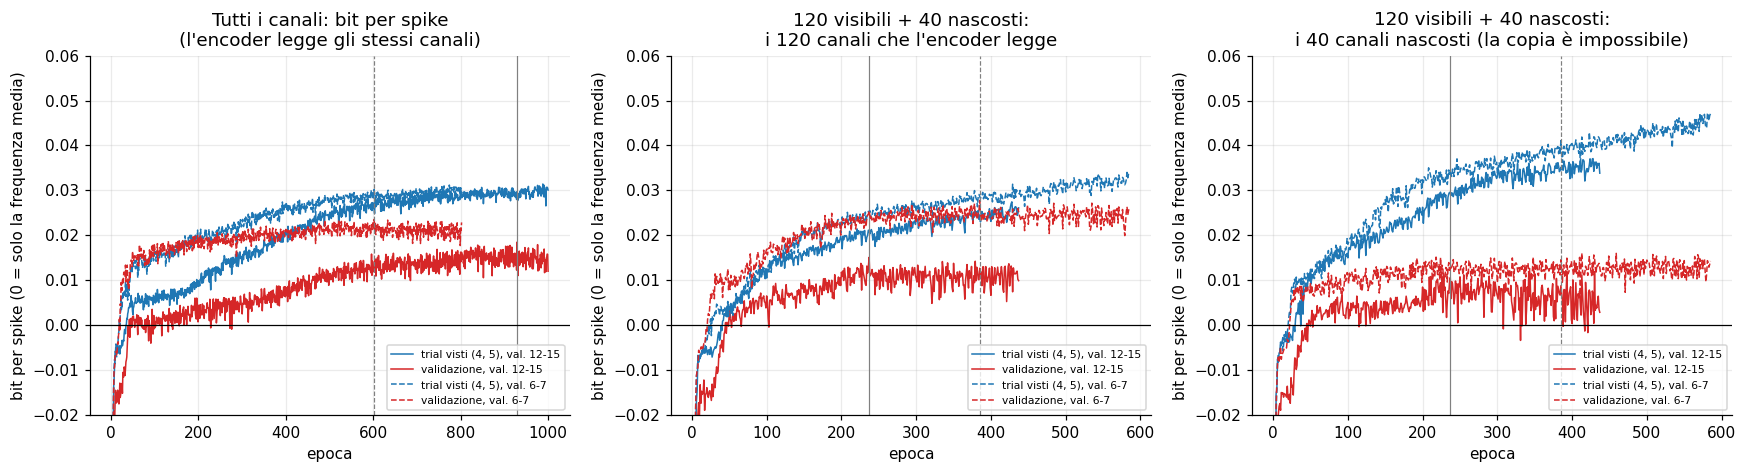

In [69]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for j, (vt, ls) in enumerate(((VAL_TRIALS, "-"), (VAL_TRIALS_B, "--"))):
    sd = 0 if vt == VAL_TRIALS else 1
    h_, b_ = res11[("tutti i canali", vt, sd)]["history"], res11[("tutti i canali", vt, sd)]["best_epoch"]
    for g, c in (("trial visti (4, 5)", "C0"), ("validazione", "C3")):  # a sinistra: la forma "tutti i canali"
        ax[0].plot(h_.index, h_[f"bit per spike, {g}"], ls, color=c, lw=1, label=f"{g}, val. {vt[0]}-{vt[1]}")
    ax[0].axvline(b_, color="0.5", ls=ls, lw=0.8)
    h_, b_ = res11[("120 visibili + 40 nascosti", vt, sd)]["history"], res11[("120 visibili + 40 nascosti", vt, sd)]["best_epoch"]
    for g, c in (("trial visti (4, 5)", "C0"), ("validazione", "C3")):  # al centro e a destra: visibili e nascosti della seconda forma
        ax[1].plot(h_.index, h_[f"bit per spike visibili, {g}"], ls, color=c, lw=1, label=f"{g}, val. {vt[0]}-{vt[1]}")
        ax[2].plot(h_.index, h_[f"bit per spike nascosti, {g}"], ls, color=c, lw=1, label=f"{g}, val. {vt[0]}-{vt[1]}")
    for a_ in ax[1:]:
        a_.axvline(b_, color="0.5", ls=ls, lw=0.8)
for a_, ttl in zip(ax, ("Tutti i canali: bit per spike\n(l'encoder legge gli stessi canali)",
                        "120 visibili + 40 nascosti:\ni 120 canali che l'encoder legge",
                        "120 visibili + 40 nascosti:\ni 40 canali nascosti (la copia è impossibile)")):
    a_.axhline(0, color="k", lw=0.8)
    a_.set(xlabel="epoca", ylabel="bit per spike (0 = solo la frequenza media)", title=ttl, ylim=(-0.02, 0.06))  # le prime epoche, molto negative, restano fuori
    a_.legend(fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_real_training.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **LFADS impara qualcosa, ma poco.** Sui trial di validazione, alla versione scelta, spiega gli spike
  meglio della sola frequenza media di 0.015-0.028 bit per spike sui canali che legge, e di 0.011-0.015
  sui canali nascosti. Nei dati sintetici il modello perfetto arrivava a 0.22 (§10.1). Valori così bassi
  non sono per forza un difetto del modello: nel 02_new (§9.2) la parte di variabilità che un canale
  condivide con la popolazione era di pochi punti percentuali, e solo quella parte si può prevedere.
- **Sui canali nascosti, dove copiare è impossibile, il modello memorizza**: sui trial visti (4 e 5) i bit
  per spike continuano a salire fino a 0.03-0.046, sui trial di validazione si fermano a circa
  0.01-0.015 già dopo 100-200 epoche. Il distacco, 2-3 volte, è quello che il modello impara dei trial
  su cui si allena e che non vale per quelli nuovi. È lo stesso fenomeno trovato per CEBRA (§3.2).
- **La regola di arresto guarda l'errore di ricostruzione**, e sceglie versioni tardive (epoche 237-929;
  con tutti i canali e la coppia 12-15 non si è fermata prima del massimo di 1000). Sui canali nascosti,
  oltre le 200 epoche non si guadagna più niente: allenare più a lungo serve solo a memorizzare.
- **Leggere un canale aiuta poco**: sui trial di validazione i bit per spike dei canali che l'encoder legge
  (0.015-0.028) sono di poco sopra quelli dei canali nascosti.
- **La coppia 12-15, a fine sessione, va peggio della 6-7** in tutte le misure (per esempio, nascosti
  0.011 contro 0.015). Per CEBRA le due coppie si equivalevano (§3.2); qui la differenza c'è, ma è
  confusa con il seme (0 contro 1). È il dubbio del §9.3 sulla validazione a fine sessione.

### Un termine di confronto senza modello

Quanti bit per spike sono "tanti" sui canali nascosti? Il Neural Latents Benchmark usa come riferimento
più semplice lo **smoothing** (Pei et al. 2021): si smussano gli spike dei canali visibili e una
regressione di Poisson (GLM) per ogni canale nascosto, stimata sui trial su cui si impara, li
predice nei trial nuovi. Qui il GLM non può ricopiare niente (l'abbiamo scartato nel §10.7 proprio per
questo): i canali nascosti non sono tra i suoi ingressi. Usiamo i 120 canali visibili smussati con
σ = 50 ms, gli stessi 10 trial di LFADS, e tre valori della penalità della regressione (0.001, 0.1 e 1).

Per confrontare sugli **stessi bin**, i bit per spike di LFADS li ricalcoliamo qui sulle frequenze
**ricucite** dei trial di validazione: durante l'allenamento erano calcolati sui pezzi, dove i bin delle
zone comuni contano due volte.

In [70]:
def bits_per_spike(rates, X):                               # bit per spike: guadagno sulla frequenza media di ogni canale, in questi dati (§9.4)
    k, lam = X.reshape(-1, X.shape[-1]), rates.reshape(-1, X.shape[-1])
    lam0 = np.maximum(k.mean(0), 1e-9)                      # la frequenza media di ogni canale (mai esattamente 0)
    return float((np.sum(lam0 - k * np.log(lam0)) - np.sum(lam - k * np.log(lam))) / k.sum() / np.log(2))

SM_VIS = io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE][:, HELD_IN]  # i 120 canali visibili smussati (σ = 50 ms)

def smooth_glm_rates(fit_trials, alpha, C=None):            # frequenze dei canali nascosti da una regressione di Poisson sui visibili smussati, stimata sui trial fit_trials
    C = COUNTS if C is None else C                          # i conteggi da predire (al §13.4 quelli spostati nel tempo)
    fit_ = np.isin(trial, fit_trials)
    F = StandardScaler().fit(SM_VIS[fit_]).transform(SM_VIS)
    return np.column_stack([PoissonRegressor(alpha=alpha, max_iter=500).fit(F[fit_], C[fit_, h]).predict(F) for h in HIDDEN])

rows_ref = {}
for vt, sd in ((VAL_TRIALS, 0), (VAL_TRIALS_B, 1)):
    val_ = np.isin(trial, vt)                               # i bin dei 2 trial di validazione
    fit_tr = [int(t) for t in TRIALS if t not in TEST_TRIALS[0] and t not in vt]
    r_ = res11[("120 visibili + 40 nascosti", vt, sd)]["rates"]
    R_hid = np.concatenate([stitch(r_[list(TRIALS).index(t)], t) for t in vt])[:, HID_COLS]  # LFADS: frequenze ricucite dei nascosti
    col = {"LFADS (120 + 40)": bits_per_spike(R_hid, COUNTS[val_][:, HIDDEN])}
    for alpha in (1e-3, 1e-1, 1.0):
        col[f"smoothing + GLM, penalità {alpha:g}"] = bits_per_spike(smooth_glm_rates(fit_tr, alpha)[val_], COUNTS[val_][:, HIDDEN])
    rows_ref[f"validazione {vt[0]}-{vt[1]}"] = col
display(pd.DataFrame(rows_ref).round(4).rename_axis("bit per spike, 40 canali nascosti, trial di validazione"))

,validazione 12-15,validazione 6-7
"bit per spike, 40 canali nascosti, trial di validazione",,
LFADS (120 + 40),0.0113,0.0178
"smoothing + GLM, penalità 0.001",-0.0019,0.0099
"smoothing + GLM, penalità 0.1",0.0277,0.0332
"smoothing + GLM, penalità 1",0.0271,0.0321


**Lettura.**

- **Il primo LFADS fa circa la metà del riferimento più semplice.** Sugli stessi bin dei trial di
  validazione, sui canali nascosti: LFADS 0.011 e 0.018 bit per spike, lo smoothing con il GLM 0.028 e
  0.033 (penalità 0.1; 0.027 e 0.032 con penalità 1). Con una penalità troppo piccola (0.001) anche il
  GLM memorizza e scende a −0.002 e 0.010.
- **Non è ancora un verdetto su LFADS**: è una sola configurazione, con i parametri dell'esempio
  sintetico, e le curve qui sopra mostrano che memorizza. Ma fissa l'asticella per il §11b: la griglia
  deve trovare una configurazione che superi 0.028-0.033 bit per spike sui canali nascosti dei trial di
  validazione, altrimenti LFADS non vale la sua complicazione su questi dati.
- Ricucendo, i bit per spike di LFADS sui trial 12-15 restano quelli dei pezzi (0.011); sui trial 6-7
  salgono da 0.015 a 0.018 (nei pezzi i bin delle zone comuni contano due volte).

### 11.2 · Le frequenze ricostruite, accanto a quelle smussate

Un trial di validazione (il 12), 8 secondi. Per tre canali che l'encoder legge, la frequenza di LFADS
(forma "tutti i canali") accanto al firing rate smussato con σ = 50 ms, quello usato dalla parte A. Per
un canale **nascosto**, la frequenza che LFADS ricava senza averlo mai letto (forma "120 + 40"). I tre
canali li scegliamo con una regola: il più modulato (deviazione standard del firing rate smussato più
alta), quello in 20ª posizione e quello in 60ª; il canale nascosto è il più modulato tra i nascosti.

Attenzione: il firing rate smussato **non è la verità**, come lo era la frequenza vera nel §10. È una
stima rumorosa, che nel §10.7 aveva una correlazione di appena 0.51 con le frequenze vere.

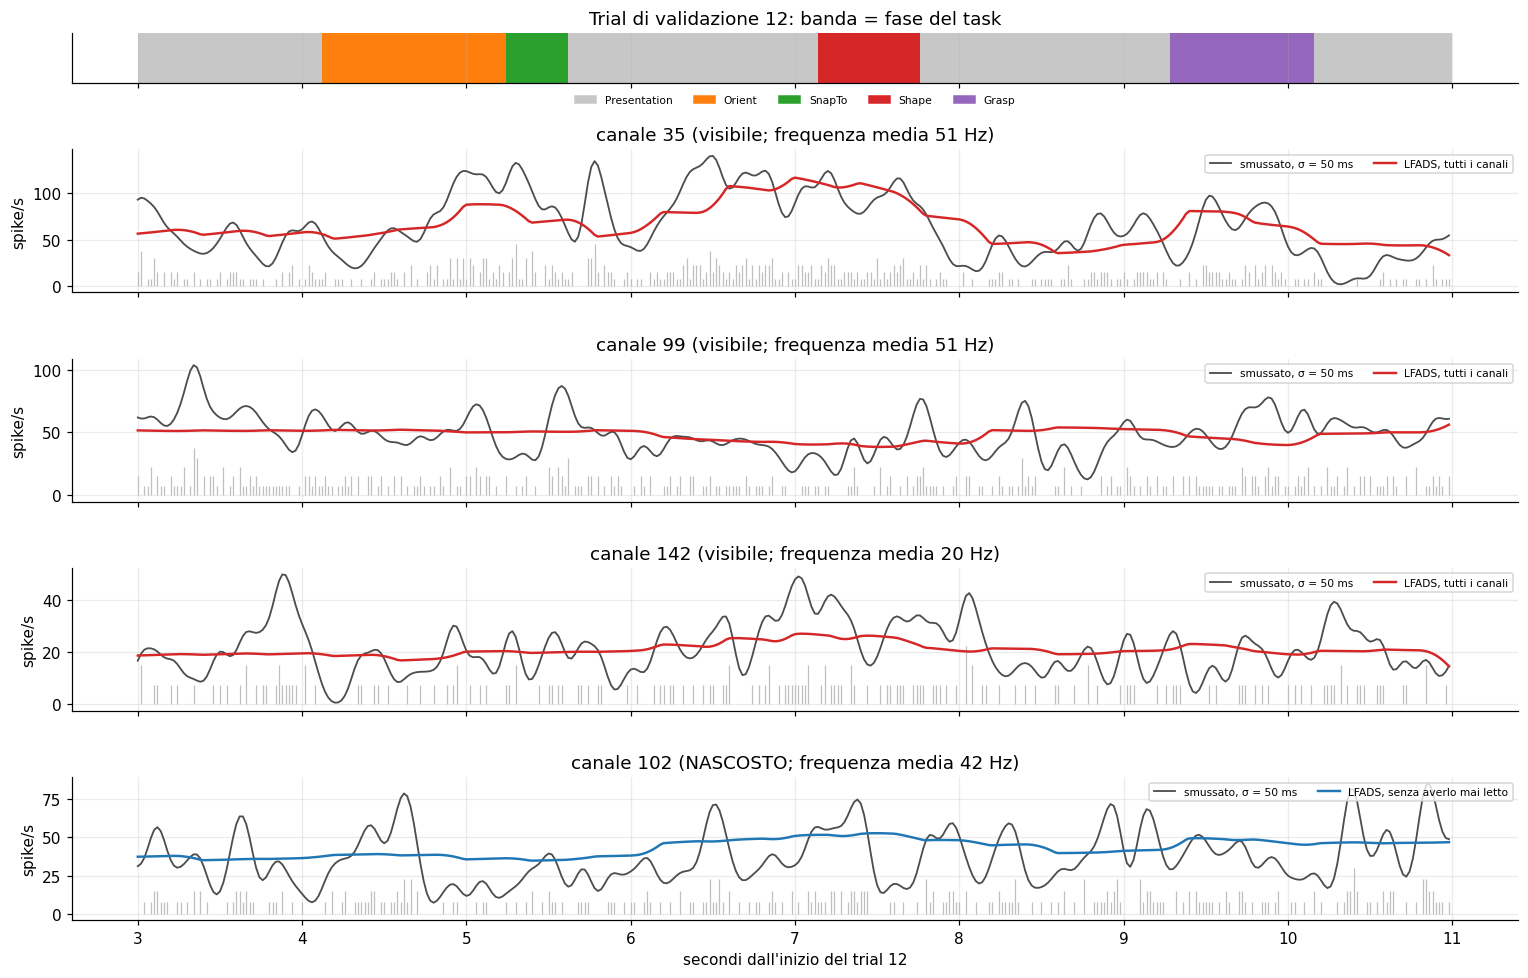

In [71]:
R11_all = {t: stitch(r_, t) for t, r_ in zip(TRIALS, res11[("tutti i canali", VAL_TRIALS, 0)]["rates"])}  # frequenze ricucite, trial per trial
R11_hid = {t: stitch(r_, t) for t, r_ in zip(TRIALS, res11[("120 visibili + 40 nascosti", VAL_TRIALS, 0)]["rates"])}
SM_RATE = io.smooth_rates(s.spikes, sigma_ms=50)[:, ACTIVE]  # firing rate smussato (σ = 50 ms) dei 160 canali, in spike al secondo (non z-scorato)
mod_rank = np.argsort(SM_RATE.std(0))[::-1]                 # canali dal più modulato al meno modulato
show_ch = [mod_rank[0], mod_rank[19], mod_rank[59]]         # i tre canali visibili mostrati
hid_show = HIDDEN[np.argmax(SM_RATE[:, HIDDEN].std(0))]     # il canale nascosto più modulato
t_val = VAL_TRIALS[0]                                       # il trial 12
a0_, a1_ = TRIAL_SPAN[t_val]
win_ = np.arange(a0_ + 150, a0_ + 550)                      # 8 s, dal terzo secondo del trial
t_w = (win_ - a0_) * io.BIN_S

fig, axes = plt.subplots(5, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": (0.35, 1, 1, 1, 1)})
for b_ in win_:                                             # in alto: le fasi del task
    axes[0].axvspan((b_ - a0_) * io.BIN_S, (b_ - a0_ + 1) * io.BIN_S, color=io.PHASE_COLORS.get(phase[b_], "white"), lw=0)
axes[0].set(yticks=[], title=f"Trial di validazione {t_val}: banda = fase del task")
ph_here = [p for p in ["Presentation", "Intertrial", *io.MOVEMENT_PHASES] if p in set(phase[win_])]
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=io.PHASE_COLORS[p]) for p in ph_here], ph_here, ncol=len(ph_here),
               fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.05), frameon=False)
panels11 = [(ch, R11_all[t_val][:, ch], "LFADS, tutti i canali", "C3", "visibile") for ch in show_ch]
panels11.append((hid_show, R11_hid[t_val][:, int(np.flatnonzero(ORDER_HID == hid_show)[0])], "LFADS, senza averlo mai letto", "C0", "NASCOSTO"))
for a_, (ch, r_lf, lab, c, kind) in zip(axes[1:], panels11):
    spk = COUNTS[win_, ch]
    a_.vlines(t_w[spk > 0], 0, spk[spk > 0] / io.BIN_S * 0.15, color="0.75", lw=0.8)  # gli spike (altezza ∝ conteggio)
    a_.plot(t_w, SM_RATE[win_, ch], color="0.3", lw=1.2, label="smussato, σ = 50 ms")
    a_.plot(t_w, r_lf[win_ - a0_] / io.BIN_S, color=c, lw=1.6, label=lab)
    a_.set(ylabel="spike/s", title=f"canale {ch} ({kind}; frequenza media {rate_hz[ch]:.0f} Hz)")
    a_.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel(f"secondi dall'inizio del trial {t_val}")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_real_rates.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Le frequenze di LFADS seguono solo i cambiamenti lenti.** Nel canale più modulato (35, 51 Hz di
  media) salgono da circa 55 a circa 110 spike/s durante `Orient` e `Shape`, come il firing rate
  smussato; nei canali 99 e 142 restano quasi piatte, mentre il firing rate smussato oscilla molto.
  Anche il canale nascosto 102, che il modello non ha mai letto, ha una frequenza che cambia lentamente
  (da circa 35 a circa 50 spike/s).
- **Il modello "decide" che quasi tutte le oscillazioni rapide sono rumore.** Con σ = 50 ms e circa uno
  spike per bin il firing rate smussato è molto rumoroso (nel §10.7 aveva una correlazione di appena 0.51
  con le frequenze vere); in più contiene il ritmo a 18 Hz del §11.3. Chi abbia ragione, senza verità,
  lo dicono solo i canali nascosti: e lì le frequenze lente di LFADS spiegano circa 0.01 bit per spike.

### 11.3 · LFADS genera trial finti

È la prova che CEBRA non può fare (§2): un modello generativo sa **produrre dati nuovi**. Il procedimento,
con la seconda metà del nostro LFADS a mano (§10.2): si estrae a caso una condizione iniziale dalla
distribuzione **a priori** (media imparata, varianza 0.1), il generatore la srotola per 30 bin, i fattori
danno le frequenze, e da queste si estraggono spike di Poisson. Nessun dato vero entra nel procedimento.

Confrontiamo 400 pezzi finti con i 400 pezzi veri su cui il modello ha imparato (forma "tutti i canali",
validazione 12-15), e con una terza versione: gli spike estratti dalle frequenze che il modello assegna
ai pezzi veri (la condizione iniziale questa volta viene dall'encoder, cioè "a posteriori"). Quattro
proprietà:

1. la **frequenza media di ogni canale**;
2. le **correlazioni tra coppie di canali**, sugli spike sommati in finestre da 100 ms;
3. la **distribuzione degli spike di tutta la popolazione** in un bin;
4. l'**autocorrelazione nel tempo** degli spike della popolazione: quanto lo stato di adesso somiglia a
   quello di qualche bin dopo. È la proprietà che dipende dalle regole del moto.

In [72]:
def lfads_sample_prior(n, w, hp, seed=0):
    """Pezzi finti: condizione iniziale estratta dalla distribuzione a priori, poi la seconda metà di lfads_forward_np
    (generatore, fattori, frequenze), poi spike di Poisson. Restituisce (frequenze, spike)."""
    rng_ = np.random.default_rng(seed)
    ic = w["ic_prior.mean"] + np.exp(0.5 * w["ic_prior.logvar"]) * rng_.normal(size=(n, hp["ic_dim"]))  # dalla distribuzione a priori
    g = ic @ w["decoder.ic_to_g0.weight"].T + w["decoder.ic_to_g0.bias"]  # lo stato di partenza del generatore
    W_fac = w["decoder.rnn.cell.fac_linear.weight"]
    W_fac = W_fac / np.linalg.norm(W_fac, axis=1, keepdims=True)  # direzioni dei fattori normalizzate, come nella libreria
    lam = []
    for _ in range(hp["seg_len"]):                          # 30 bin, solo le regole del generatore
        g = gru_step(np.zeros((n, 0)), g, w, "decoder.rnn.cell.gen_cell.", hp["cell_clip"])
        lam.append(np.exp((g @ W_fac.T) @ w["readout.0.weight"].T + w["readout.0.bias"]))  # fattori -> frequenze
    lam = np.stack(lam, 1)
    return lam, rng_.poisson(lam).astype(np.float32)

W11 = {k_: v.astype(np.float64) for k_, v in res11[("tutti i canali", VAL_TRIALS, 0)]["weights"].items()}
REAL11 = real_job(REAL_HP, 0, VAL_TRIALS, SEGS)["train"]    # i 400 pezzi veri su cui ha imparato
fit11 = [int(t) for t in TRIALS if t not in TEST_TRIALS[0] and t not in VAL_TRIALS]
POST11 = np.concatenate([res11[("tutti i canali", VAL_TRIALS, 0)]["rates"][list(TRIALS).index(t)] for t in fit11])  # le frequenze del modello sui pezzi veri
_, FAKE11 = lfads_sample_prior(len(REAL11), W11, REAL_HP, seed=0)  # 400 pezzi finti
POSTSPK11 = np.random.default_rng(1).poisson(POST11).astype(np.float32)  # spike estratti dalle frequenze "a posteriori"
SETS11 = {"veri": REAL11, "finti (a priori)": FAKE11, "dalle frequenze a posteriori": POSTSPK11}

def pair_corr(X):                                           # correlazioni tra coppie di canali, sugli spike sommati in finestre da 5 bin (100 ms) dentro i pezzi
    Y = X.reshape(len(X), SEG_LEN // 5, 5, X.shape[2]).sum(2).reshape(-1, X.shape[2])
    return np.corrcoef(Y.T)[np.triu_indices(X.shape[2], 1)]

def pop_autocorr(X, lags=range(1, 11)):                     # autocorrelazione nel tempo degli spike della popolazione, dentro i pezzi
    P = X.sum(2)                                            # spike di tutta la popolazione, bin per bin: (pezzi, 30)
    P = P - P.mean()
    return np.array([np.sum(P[:, :-l] * P[:, l:]) / np.sum(P[:, :-l] ** 2) for l in lags])

stats11 = {name: {"rates": X.mean((0, 1)) / io.BIN_S, "corr": pair_corr(X), "pop": X.sum(2).ravel(), "ac": pop_autocorr(X)}
           for name, X in SETS11.items()}
display(pd.DataFrame({name: {"spike per bin, popolazione (media)": st_["pop"].mean(),
                             "idem, deviazione standard": st_["pop"].std(),
                             "correlazione con i veri: frequenze dei canali": np.corrcoef(stats11["veri"]["rates"], st_["rates"])[0, 1],
                             "correlazione con i veri: correlazioni tra coppie": np.corrcoef(stats11["veri"]["corr"], st_["corr"])[0, 1],
                             "correlazione media tra coppie": st_["corr"].mean(),
                             "autocorrelazione a 1 bin": st_["ac"][0], "autocorrelazione a 10 bin (200 ms)": st_["ac"][-1]}
                      for name, st_ in stats11.items()}).round(3))

,veri,finti (a priori),dalle frequenze a posteriori
"spike per bin, popolazione (media)",45.810,44.924,45.271
"idem, deviazione standard",10.308,7.099,7.406
correlazione con i veri: frequenze dei canali,1.000,0.999,0.999
correlazione con i veri: correlazioni tra coppie,1.000,0.466,0.516
correlazione media tra coppie,0.007,0.002,0.003
autocorrelazione a 1 bin,-0.080,0.127,0.156
autocorrelazione a 10 bin (200 ms),0.035,0.109,0.168


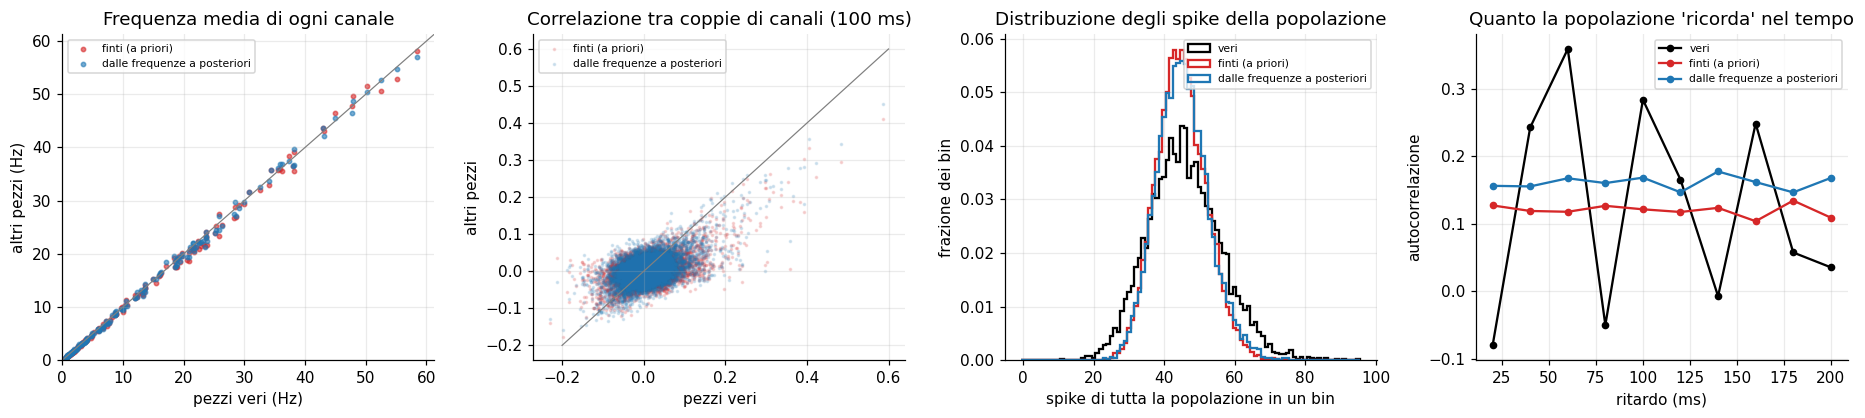

In [73]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9))
cols11 = {"veri": "k", "finti (a priori)": "C3", "dalle frequenze a posteriori": "C0"}
for name in ("finti (a priori)", "dalle frequenze a posteriori"):
    ax[0].scatter(stats11["veri"]["rates"], stats11[name]["rates"], s=8, alpha=0.6, color=cols11[name], label=name)
    ax[1].scatter(stats11["veri"]["corr"], stats11[name]["corr"], s=2, alpha=0.15, color=cols11[name], label=name)
lim0 = (0, max(stats11["veri"]["rates"].max(), stats11["finti (a priori)"]["rates"].max()) * 1.05)
ax[0].plot(lim0, lim0, color="0.5", lw=0.8); ax[0].set(xlim=lim0, ylim=lim0, xlabel="pezzi veri (Hz)", ylabel="altri pezzi (Hz)",
                                                        title="Frequenza media di ogni canale")
ax[1].plot((-0.2, 0.6), (-0.2, 0.6), color="0.5", lw=0.8); ax[1].set(xlabel="pezzi veri", ylabel="altri pezzi",
                                                                  title="Correlazione tra coppie di canali (100 ms)")
bins_pop = np.arange(0, max(st_["pop"].max() for st_ in stats11.values()) + 2) - 0.5
for name, st_ in stats11.items():
    ax[2].hist(st_["pop"], bins=bins_pop, histtype="step", density=True, color=cols11[name], lw=1.5, label=name)
    ax[3].plot(np.arange(1, 11) * 20, st_["ac"], "o-", color=cols11[name], ms=4, label=name)
ax[2].set(xlabel="spike di tutta la popolazione in un bin", ylabel="frazione dei bin", title="Distribuzione degli spike della popolazione")
ax[3].set(xlabel="ritardo (ms)", ylabel="autocorrelazione", title="Quanto la popolazione 'ricorda' nel tempo")
for a_ in ax:
    a_.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_generated.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **LFADS genera dati con il livello giusto di ogni canale**: le frequenze medie dei pezzi finti
  coincidono con quelle vere (correlazione 0.999), e la popolazione emette in media lo stesso numero di
  spike per bin (44.9 contro 45.8).
- **Ma la popolazione vera fluttua molto di più**: deviazione standard 10.3 spike per bin contro 7.1 dei
  finti. Se gli spike fossero solo rumore di Poisson attorno a frequenze fisse sarebbe circa 6.8: i dati
  veri hanno molta variabilità comune in più, LFADS quasi niente.
- **Le correlazioni tra coppie di canali sono riprodotte solo in parte**: tra veri e finti si
  somigliano con una correlazione di 0.47, e la correlazione media tra coppie è 0.007 nei veri, 0.002 nei
  finti.
- **L'autocorrelazione vera cambia segno** da un ritardo all'altro (−0.08 a 20 ms, poi valori alti a
  60 e 100 ms), quella dei finti è piatta intorno a 0.11-0.17: il modello ha fluttuazioni comuni lente,
  ma non l'oscillazione. Lo vediamo nella cella qui sotto.
- **I finti somigliano alle ricostruzioni del modello** (gli spike estratti dalle frequenze "a posteriori"
  hanno quasi le stesse proprietà): quello che manca non dipende dalla distribuzione a priori, manca
  proprio al modello.

### Un ritmo a 18 Hz nei conteggi

L'autocorrelazione dei pezzi veri (figura qui sopra, a destra) cambia segno da un ritardo all'altro: è il
segno di un'**oscillazione**. Nei notebook precedenti non poteva emergere: lo smoothing con σ = 50 ms
toglie quasi del tutto le frequenze sopra i 10 Hz. La caratterizziamo con lo **spettro** degli spike di
tutta la popolazione (quanta varianza c'è a ogni frequenza):

- con gli **istanti esatti degli spike**, contati a 1 ms: con bin da 20 ms non si vedono frequenze sopra i
  25 Hz, e una frequenza più alta potrebbe "travestirsi" da una più bassa. Misuriamo la potenza media in
  alcune bande, rispetto a quella tra 60 e 90 Hz, e cerchiamo righe strette sopra i 35 Hz;
- separatamente nelle **pause** e nel **movimento**, su finestre da 1 s (50 bin, una ogni 200 ms) che
  cadono tutte dentro una pausa o tutte dentro una fase di movimento, facendo la media degli spettri delle
  finestre (il metodo di Welch). Le oscillazioni beta della corteccia motoria (13-30 Hz) di solito calano
  durante il movimento, anche solo tentato o immaginato (Kilavik et al. 2013, rassegna): se questo ritmo
  fosse quello, dovrebbe essere più debole nel movimento.

Spettro a 1 ms: picco a 18.08 Hz
Potenza media per banda, rispetto alla banda 60-90 Hz: {'10-15 Hz': 0.98, '16-20 Hz': 6.22, '21-26 Hz': 2.12, '30-40 Hz': 1.48, '45-55 Hz': 1.2}
Sopra i 35 Hz la riga più alta è a 265.6 Hz (18 volte i ±2 Hz intorno); il conteggio a 20 ms ne lascia passare una frazione 2.5e-03 della potenza
pause: 193 finestre; potenza a 18 Hz = 5.7 volte la potenza tipica sopra gli 8 Hz; potenza assoluta a 18 Hz 5582
movimento: 150 finestre; potenza a 18 Hz = 5.8 volte la potenza tipica sopra gli 8 Hz; potenza assoluta a 18 Hz 5914
Lo smoothing con σ = 50 ms lascia passare a 18 Hz una frazione 1e-14 della potenza


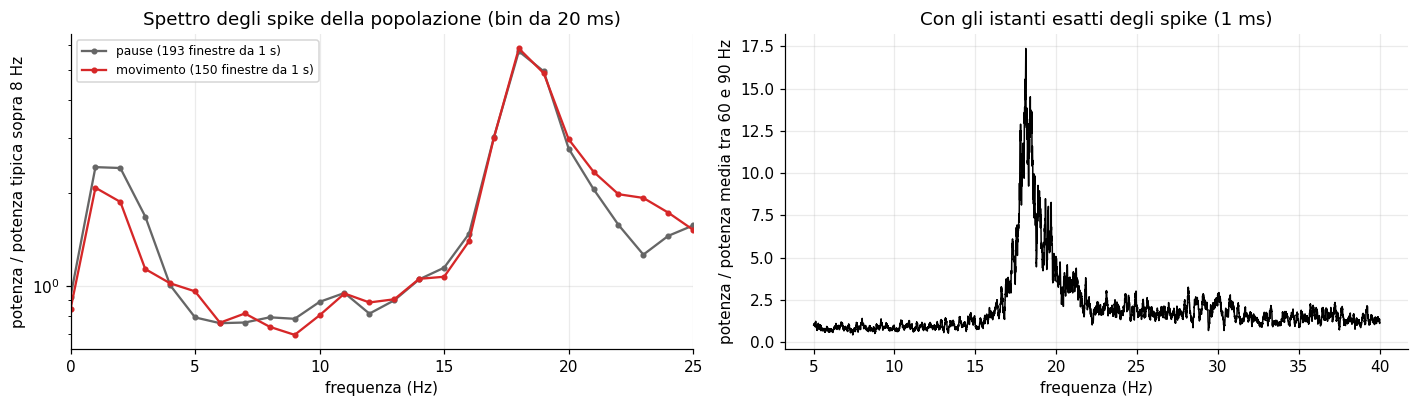

In [74]:
P_pop = COUNTS.sum(1).astype(float)                         # spike di tutta la popolazione in ogni bin da 20 ms
st_pop = np.concatenate([s.spike_times[u] for u in ACTIVE]) # gli istanti di tutti gli spike dei 160 canali
h1, _ = np.histogram(st_pop, bins=np.arange(s.times[0], s.times[-1] + io.BIN_S, 0.001))  # contati a 1 ms
f1 = np.fft.rfftfreq(len(h1), d=0.001)
S1 = np.abs(np.fft.rfft(h1 - h1.mean())) ** 2              # lo spettro a 1 ms
ref_band = (f1 > 60) & (f1 < 90)                            # banda di riferimento
k_peak = np.argmax(S1 * (f1 > 5))                           # la frequenza con più potenza sopra i 5 Hz
print(f"Spettro a 1 ms: picco a {f1[k_peak]:.2f} Hz")
print("Potenza media per banda, rispetto alla banda 60-90 Hz:",
      {f"{lo}-{hi} Hz": round(float(S1[(f1 >= lo) & (f1 < hi)].mean() / S1[ref_band].mean()), 2)
       for lo, hi in ((10, 15), (16, 20), (21, 26), (30, 40), (45, 55))})
k_hi = np.flatnonzero(f1 > 35)[np.argmax(S1[f1 > 35])]      # la riga più alta sopra i 35 Hz
print(f"Sopra i 35 Hz la riga più alta è a {f1[k_hi]:.1f} Hz ({S1[k_hi] / np.median(S1[np.abs(f1 - f1[k_hi]) < 2]):.0f} volte i ±2 Hz intorno); "
      f"il conteggio a 20 ms ne lascia passare una frazione {np.sinc(f1[k_hi] * io.BIN_S) ** 2:.1e} della potenza")

def welch_pop(mask, L=50, step=10):                         # spettro medio degli spike della popolazione su finestre da L bin tutte dentro `mask`
    starts = [a for a in range(0, n_bins - L, step) if mask[a:a + L].all()]
    win = np.hanning(L)                                     # una finestra che si annulla ai bordi (attenua le frequenze spurie)
    S = np.mean([np.abs(np.fft.rfft((P_pop[a:a + L] - P_pop[a:a + L].mean()) * win)) ** 2 for a in starts], axis=0)
    return np.fft.rfftfreq(L, io.BIN_S), S, len(starts)

WELCH = {"pause": welch_pop(~MOV), "movimento": welch_pop(MOV)}
f_w = WELCH["pause"][0]
k18 = np.argmin(np.abs(f_w - 18))                           # la frequenza della griglia di Welch più vicina a 18 Hz
side = (np.abs(f_w - 18) > 3) & (f_w > 8)                   # le frequenze di confronto: sopra 8 Hz e lontane più di 3 Hz dal picco
for name, (_, S_, n_) in WELCH.items():
    print(f"{name}: {n_} finestre; potenza a {f_w[k18]:.0f} Hz = {S_[k18] / np.median(S_[side]):.1f} volte la potenza tipica sopra gli 8 Hz; "
          f"potenza assoluta a {f_w[k18]:.0f} Hz {S_[k18]:.0f}")
print(f"Lo smoothing con σ = 50 ms lascia passare a 18 Hz una frazione {np.exp(-(2 * np.pi * 18 * 0.05) ** 2):.0e} della potenza")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name, c in (("pause", "0.4"), ("movimento", "C3")):
    f_, S_, n_ = WELCH[name]
    ax[0].plot(f_, S_ / np.median(S_[side]), "o-", ms=3, color=c, label=f"{name} ({n_} finestre da 1 s)")
ax[0].set(xlabel="frequenza (Hz)", ylabel="potenza / potenza tipica sopra 8 Hz", xlim=(0, 25), yscale="log",
          title="Spettro degli spike della popolazione (bin da 20 ms)")
ax[0].legend(fontsize=8)
zoom = (f1 > 5) & (f1 < 40)
ax[1].plot(f1[zoom], uniform_filter1d(S1, 25)[zoom] / S1[ref_band].mean(), color="k", lw=1)  # media mobile su 25 frequenze vicine (0.1 Hz)
ax[1].set(xlabel="frequenza (Hz)", ylabel="potenza / potenza media tra 60 e 90 Hz", title="Con gli istanti esatti degli spike (1 ms)")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_beta.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **C'è un ritmo vero intorno ai 18 Hz.** Con gli istanti esatti degli spike il picco è a 18.1 Hz, quindi
  non è una frequenza più alta "travestita". È largo, non una riga sottile: nella banda 16-20 Hz la
  potenza è 6.2 volte quella tra 60 e 90 Hz, tra 21 e 26 Hz 2.1 volte, sotto i 15 Hz come a 60-90 Hz.
  Cade nella banda beta (13-30 Hz).
- **Non cala durante il movimento**: rispetto alle frequenze vicine vale 5.7 volte nelle pause e 5.8 nel
  movimento, e anche in valore assoluto è quasi uguale. Le oscillazioni beta motorie di solito si
  riducono durante il movimento, anche solo tentato (Kilavik et al. 2013); qui no. Quindi **non sappiamo
  da dove venga**: un ritmo fisiologico non legato al movimento, oppure una sorgente tecnica. Non
  l'abbiamo indagato.
- Una seconda riga, stretta, sta a 265.6 Hz (18 volte i dintorni): probabilmente tecnica; il conteggio a
  20 ms ne lascia passare solo lo 0.25%, quindi non conta.
- **Per i notebook precedenti non cambia niente**: lo smoothing con σ = 50 ms lascia passare a 18 Hz una
  frazione 10⁻¹⁴ della potenza. **Per LFADS e la GPFA sì**: ricevono i conteggi grezzi, ritmo compreso,
  e nessuno dei due lo riproduce. È una parte della variabilità comune della popolazione che, a quanto
  pare, non ha a che fare con le fasi del task (lo stesso livello in pausa e in movimento); non abbiamo
  verificato se porti informazione sul task.

### 11.4 · I bordi dei pezzi, sui dati veri

Nel §10.8 il primo bin di ogni pezzo era molto meno preciso del centro. Sui dati veri non c'è la verità,
ma ci sono i canali nascosti: misuriamo i bit per spike dei 40 canali nascosti **posizione per
posizione** dentro i pezzi dei 2 trial di validazione (forma "120 + 40"), e il disaccordo tra pezzi
consecutivi nella zona in comune (forma "tutti i canali").

In [75]:
r_hid = res11[("120 visibili + 40 nascosti", VAL_TRIALS, 0)]["rates"]
X_val_hid = np.concatenate([SEGS_HID[t] for t in VAL_TRIALS])[..., HID_COLS]  # gli spike veri dei canali nascosti, pezzi di validazione
R_val_hid = np.concatenate([r_hid[list(TRIALS).index(t)] for t in VAL_TRIALS])[..., HID_COLS]  # le frequenze di LFADS per quei canali
print(f"Canali nascosti, trial di validazione: {bits_per_spike(R_val_hid, X_val_hid):.3f} bit per spike sui pezzi "
      f"(la storia dell'allenamento, epoca scelta: "
      f"{res11[('120 visibili + 40 nascosti', VAL_TRIALS, 0)]['history'].loc[res11[('120 visibili + 40 nascosti', VAL_TRIALS, 0)]['best_epoch'], 'bit per spike nascosti, validazione']:.3f})")
pos_bits = [bits_per_spike(R_val_hid[:, p_:p_ + 3], X_val_hid[:, p_:p_ + 3]) for p_ in range(0, SEG_LEN, 3)]  # a gruppi di 3 bin (60 ms)
print("Bit per spike dei canali nascosti per posizione nel pezzo (gruppi di 3 bin: 1-3, 4-6, ..., 28-30):", [round(b_, 3) for b_ in pos_bits])
F_val = [res11[("tutti i canali", VAL_TRIALS, 0)]["factors"][list(TRIALS).index(t)] for t in VAL_TRIALS]
print(f"Zone comuni tra pezzi consecutivi, trial di validazione: i fattori differiscono in media di "
      f"{np.mean([seam_gap(F_, SEG_START[t]) for F_, t in zip(F_val, VAL_TRIALS)]):.2f} deviazioni standard (sintetici: 0.41)")

Canali nascosti, trial di validazione: 0.011 bit per spike sui pezzi (la storia dell'allenamento, epoca scelta: 0.011)
Bit per spike dei canali nascosti per posizione nel pezzo (gruppi di 3 bin: 1-3, 4-6, ..., 28-30): [-0.006, 0.002, -0.002, 0.005, 0.01, 0.001, 0.011, 0.007, 0.002, 0.003]
Zone comuni tra pezzi consecutivi, trial di validazione: i fattori differiscono in media di 0.65 deviazioni standard (sintetici: 0.41)


**Lettura.**

- **Posizione per posizione, sui dati veri il segnale è troppo debole per vedere i bordi**: i bit per
  spike dei canali nascosti vanno da −0.006 (i primi 3 bin del pezzo) a 0.011, e oscillano senza un
  andamento chiaro. Il primo gruppo è il più basso, come nei dati sintetici (§10.8), ma la differenza è
  dentro il rumore.
- **I pezzi consecutivi sono più in disaccordo che nei dati sintetici**: nella zona comune i fattori
  differiscono in media di 0.65 deviazioni standard (0.41 nei sintetici). Le traiettorie ricucite potranno
  avere delle "giunture": al §12 controlleremo quanto pesano sulla seghettatura.

### Riepilogo del §11a

| domanda | risposta | dove |
|---|---|---|
| LFADS impara dai dati veri? | poco: 0.011-0.015 bit per spike sui canali nascosti dei trial di validazione | §11.1 |
| memorizza? | sì: sui trial visti i nascosti arrivano a 0.03-0.046; il distacco si apre dopo 100-200 epoche | §11.1 |
| è meglio del riferimento senza modello? | no: lo smoothing con il GLM fa 0.028-0.033, circa il doppio | §11.1 |
| che frequenze ricostruisce? | lente: segue le variazioni legate alle fasi, tratta il resto come rumore | §11.2 |
| genera dati credibili? | il livello di ogni canale sì; la variabilità comune e l'autocorrelazione no | §11.3 |
| che cosa c'è nei conteggi che il modello non vede? | un ritmo a circa 18 Hz, uguale in pausa e in movimento, di origine non chiarita | §11.3 |

**Che cosa portiamo al §11b.** La configurazione dell'esempio sintetico **non basta**: LFADS memorizza
e resta sotto il riferimento più semplice. La griglia deve quindi esplorare più regolarizzazione (dropout,
peso del KL, generatore più piccolo) e il coordinated dropout, scegliendo con i **bit per spike sui canali
nascosti** dei trial di validazione, con l'asticella dello smoothing + GLM.

**Che cosa non abbiamo verificato**: una sola configurazione e due semi; la differenza tra le due coppie di
validazione è confusa con il seme; l'origine del ritmo a 18 Hz e se porti informazione sul task.

## 11b · La griglia dei parametri, sui soli trial di validazione

Nel §11a LFADS memorizzava e restava sotto il riferimento più semplice. Qui proviamo a correggerlo con
più regolarizzazione, cambiando le stesse "manopole" che AutoLFADS cerca da solo (`scripts/run_pbt.py`
della libreria): il dropout, il coordinated dropout e il peso del termine KL. Non potendo far girare
AutoLFADS (§9), usiamo una **piccola griglia**:

| manopola | valori | intervallo di AutoLFADS | che cosa fa |
|---|---|---|---|
| dropout | 0.05 (§11a), 0.25, 0.5 | 0-0.6 | spegne a caso una parte dei numeri dentro la rete a ogni passo: la rete non può affidarsi a un dettaglio solo |
| peso del termine KL | × 1 (l'ELBO vero, §10.4), × 5 | 10⁻⁶-10⁻³ (× 5 qui vale 1.04·10⁻³) | fa pagare di più l'informazione che passa nella condizione iniziale |
| coordinated dropout | 0, 0.3 (§11a) | 0.01-0.7 | nasconde all'encoder una parte dei valori e misura l'errore solo su quelli (§10.5) |

Restano fissi la grandezza del generatore (64), la penalità L2 (10⁻²) e il passo di apprendimento
(4·10⁻³): sono tra le alternative del §14.

**Lo schema** è quello del §11a: forma "120 visibili + 40 nascosti", blocco 0, le due coppie di
validazione (12-15 con il seme 0, 6-7 con il seme 1). 12 configurazioni × 2 coppie = 24 allenamenti; la
configurazione del §11a è già su disco. Dei nuovi modelli salviamo solo le frequenze dei canali nascosti.

**La regola, fissata prima di guardare i risultati.** Per ogni allenamento prendiamo la curva dei bit per
spike sui canali nascosti dei trial di validazione (registrata a ogni epoca), la smussiamo con una media
mobile su 21 epoche (le misure di una singola epoca sono rumorose, §11a) e ne leggiamo il **massimo** e
l'epoca in cui cade. Il **punteggio** di una configurazione è la media dei due massimi (una per coppia).
Vince il punteggio più alto. Il **numero di epoche** che useremo al §12 è la media delle due epoche di
picco della configurazione vincente, arrotondata per eccesso a un multiplo di 50: come per CEBRA (§3.2),
il numero di passi si sceglie sulla validazione e poi resta fisso.

**Perché non l'errore di ricostruzione**: è quello che usa la regola di arresto dell'allenamento, ma il
§10.6 ha mostrato che senza coordinated dropout la copia lo inganna; i canali nascosti no.

**L'asticella**: lo smoothing con la regressione di Poisson, 0.028 e 0.033 bit per spike sulle due coppie
(§11a). Va ricordato che anche la sua penalità era la migliore delle tre provate sugli stessi trial, e che
il massimo di una curva rumorosa è un po' ottimista: la misura definitiva, sui trial di test, è al §12.

22 allenamenti nuovi, 4 alla volta: circa 30-40 minuti la prima volta.

In [76]:
GRID_DROP, GRID_KL, GRID_CD = (0.05, 0.25, 0.5), (1, 5), (0.0, 0.3)  # i valori della griglia
CENTER = (0.05, 1, 0.3)                                     # la configurazione del §11a

def grid_hp(drop, kl, cd):                                  # i parametri di una configurazione della griglia (forma "120 + 40")
    return dict(HID_HP, dropout=drop, kl_ic_scale=kl / (SEG_LEN * N_CH), cd_rate=cd)

GRID = list(product(GRID_DROP, GRID_KL, GRID_CD))           # 12 configurazioni
PAIRS_11 = ((VAL_TRIALS, 0), (VAL_TRIALS_B, 1))             # le due coppie di validazione, con i semi del §11a
jobs_g, keys_g = [], []
for cfg in GRID:
    for vt, sd in PAIRS_11:
        j_ = real_job(grid_hp(*cfg), sd, vt, SEGS_HID, HID_COLS)  # come nel §11a
        if cfg != CENTER:
            j_["rate_cols"] = HID_COLS                      # delle frequenze teniamo solo i 40 nascosti (la configurazione del §11a è già su disco con tutte)
        jobs_g.append(j_); keys_g.append((cfg, vt))
print("La configurazione del §11a coincide con quella della griglia:", grid_hp(*CENTER) == HID_HP)
res_g = dict(zip(keys_g, run_lfads_cached(jobs_g)))

SMOOTH_EP = 21                                              # la media mobile sulle epoche

def smooth_curve(h, col):                                   # una colonna della storia, smussata su 21 epoche
    return uniform_filter1d(h[col].values, SMOOTH_EP, mode="nearest")

def grid_row(cfg):                                          # le misure di una configurazione: massimo della curva smussata, epoca, trial visti, per ogni coppia
    row, vals, eps = {}, [], []
    for vt, _ in PAIRS_11:
        r_ = res_g[(cfg, vt)]
        h_ = r_["history"]
        v_ = smooth_curve(h_, "bit per spike nascosti, validazione")
        i_ = int(np.argmax(v_))                             # l'epoca del massimo (posizione nella storia)
        lab = f"{vt[0]}-{vt[1]}"
        row[f"nascosti, val. {lab}"] = v_[i_]
        row[f"epoca, val. {lab}"] = int(h_.index[i_])
        row[f"visti (4, 5), val. {lab}"] = smooth_curve(h_, "bit per spike nascosti, trial visti (4, 5)")[i_]
        row[f"epoche fatte, val. {lab}"] = r_["epochs"]
        vals.append(v_[i_]); eps.append(int(h_.index[i_]))
    row["punteggio"] = np.mean(vals)
    row["epoca di picco (media)"] = np.mean(eps)
    return row

def cfg_name(c):                                            # il nome di una configurazione
    return f"dropout {c[0]}, KL × {c[1]}, CD {c[2]}"

def grid_table(cfgs):                                       # la tabella di un gruppo di configurazioni, dal punteggio più alto
    t_ = pd.DataFrame({cfg_name(c): grid_row(c) for c in cfgs}).T
    return t_.sort_values("punteggio", ascending=False)

REF_GLM = {f"{vt[0]}-{vt[1]}": rows_ref[f"validazione {vt[0]}-{vt[1]}"]["smoothing + GLM, penalità 0.1"] for vt, _ in PAIRS_11}
REF_GLM_MEAN = np.mean(list(REF_GLM.values()))              # l'asticella: lo smoothing + GLM del §11a, media delle due coppie
tab_g1 = grid_table(GRID)
display(tab_g1.round(4))
best1 = max(GRID, key=lambda c: grid_row(c)["punteggio"])
print(f"Prima tornata: la migliore è {cfg_name(best1)} (punteggio {grid_row(best1)['punteggio']:.4f}); "
      f"asticella {REF_GLM} -> media {REF_GLM_MEAN:.4f}; sopra l'asticella: {int((tab_g1['punteggio'] > REF_GLM_MEAN).sum())} su {len(GRID)}")
print("Configurazioni che non imparano nulla (punteggio sotto 0):", int((tab_g1["punteggio"] < 0).sum()), "su", len(GRID))

La configurazione del §11a coincide con quella della griglia: True


Allenamenti LFADS: 0 eseguiti ora, 24 riletti dal disco


,"nascosti, val. 12-15","epoca, val. 12-15","visti (4, 5), val. 12-15","epoche fatte, val. 12-15","nascosti, val. 6-7","epoca, val. 6-7","visti (4, 5), val. 6-7","epoche fatte, val. 6-7",punteggio,epoca di picco (media)
"dropout 0.05, KL × 1, CD 0.0",0.0254,158.0,0.0577,435.0,0.0264,249.0,0.0684,443.0,0.0259,203.5
"dropout 0.25, KL × 1, CD 0.0",0.0178,642.0,0.0424,871.0,0.0183,594.0,0.0422,797.0,0.0181,618.0
"dropout 0.05, KL × 1, CD 0.3",0.0083,281.0,0.0320,437.0,0.0137,584.0,0.0464,585.0,0.0110,432.5
"dropout 0.5, KL × 1, CD 0.0",-0.0150,360.0,-0.0035,360.0,0.0134,733.0,0.0266,1000.0,-0.0008,546.5
"dropout 0.25, KL × 1, CD 0.3",-0.0152,354.0,-0.0035,360.0,0.0120,602.0,0.0286,1000.0,-0.0016,478.0
"dropout 0.05, KL × 5, CD 0.0",-0.0154,201.0,-0.0035,448.0,0.0118,346.0,0.0292,520.0,-0.0018,273.5
"dropout 0.5, KL × 1, CD 0.3",-0.0150,360.0,-0.0035,360.0,-0.0054,541.0,-0.0049,541.0,-0.0102,450.5
"dropout 0.5, KL × 5, CD 0.3",-0.0151,360.0,-0.0035,360.0,-0.0054,541.0,-0.0049,541.0,-0.0102,450.5
"dropout 0.5, KL × 5, CD 0.0",-0.0150,289.0,-0.0036,360.0,-0.0055,394.0,-0.0049,399.0,-0.0103,341.5
"dropout 0.25, KL × 5, CD 0.0",-0.0153,289.0,-0.0037,360.0,-0.0056,399.0,-0.0048,399.0,-0.0104,344.0


Prima tornata: la migliore è dropout 0.05, KL × 1, CD 0.0 (punteggio 0.0259); asticella {'12-15': 0.027739039966554007, '6-7': 0.033233380429930216} -> media 0.0305; sopra l'asticella: 0 su 12
Configurazioni che non imparano nulla (punteggio sotto 0): 9 su 12


**Lettura.**

- **Più regolarizzazione non aiuta: fa smettere di imparare.** 9 configurazioni su 12 hanno un punteggio
  sotto 0. Sulla coppia 12-15 si fermano tutte intorno a −0.015 bit per spike, cioè al livello di chi
  prevede sempre la frequenza media dei trial di training: l'encoder non passa più nessuna informazione
  al generatore. Succede con il peso del KL × 5 e con il dropout a 0.25-0.5. È il fenomeno noto negli
  autoencoder variazionali come *collasso*: se ogni informazione che passa costa troppo, conviene non
  farne passare nessuna, come uno studente che, se ogni parola gli costa troppo, consegna il foglio
  bianco. In alcune configurazioni una coppia impara e l'altra no: anche questo dice che siamo al limite.
- **Il coordinated dropout peggiora**: con dropout 0.05 e KL × 1, 0.026 senza contro 0.011 con il
  coordinated dropout (la configurazione del §11a). È lo stesso esito dei dati sintetici (§10.6), e qui
  non dipende dalla copia: i canali nascosti non si possono copiare.
- **La migliore, dropout 0.05, KL × 1, senza coordinated dropout, sta sul bordo della griglia** per tutte e
  tre le manopole, dalla parte della regolarizzazione più bassa. Fa 0.025 e 0.026, sotto l'asticella
  (0.028 e 0.033). Contro l'aspettativa del §11a: il modello memorizza, ma la cura classica, più
  regolarizzazione, lo spegne invece di correggerlo.

### La seconda tornata, verso meno regolarizzazione

Questa tornata l'abbiamo decisa **dopo** aver visto la prima, e lo dichiariamo: la configurazione migliore
sta sul bordo della griglia, dalla parte della regolarizzazione più bassa per tutte e tre le manopole, e un
massimo sul bordo non dice se andando oltre si starebbe meglio. Estendiamo quindi in quella direzione:

- coordinated dropout fisso a 0, perché lo 0.3 è peggio a ogni livello delle altre due manopole;
- dropout 0, 0.02 (il valore di partenza della configurazione della libreria per MC_Maze-S) e 0.05;
- peso del KL × 0.3 e × 1.

5 configurazioni nuove × 2 coppie = 10 allenamenti, circa 12-15 minuti. La regola resta la stessa e vale
per tutte le 17 configurazioni insieme. Se la vincente stesse ancora sul bordo del peso del KL, lo
dichiareremo e lo lasceremo al §14.

In [77]:
GRID2 = [(0.0, 0.3, 0.0), (0.0, 1, 0.0), (0.02, 0.3, 0.0), (0.02, 1, 0.0), (0.05, 0.3, 0.0)]  # le configurazioni nuove
jobs_g2, keys_g2 = [], []
for cfg in GRID2:
    for vt, sd in PAIRS_11:
        j_ = real_job(grid_hp(*cfg), sd, vt, SEGS_HID, HID_COLS)
        j_["rate_cols"] = HID_COLS
        jobs_g2.append(j_); keys_g2.append((cfg, vt))
res_g.update(zip(keys_g2, run_lfads_cached(jobs_g2)))
GRID_ALL = GRID + GRID2                                     # le 17 configurazioni
tab_g = grid_table(GRID_ALL)
display(tab_g.round(4))
BEST_CFG = max(GRID_ALL, key=lambda c: grid_row(c)["punteggio"])  # la configurazione vincente
N_EP_LF = int(np.ceil(grid_row(BEST_CFG)["epoca di picco (media)"] / 50) * 50)  # il numero di epoche per il §12
print(f"Configurazione scelta: {cfg_name(BEST_CFG)}; punteggio {grid_row(BEST_CFG)['punteggio']:.4f} "
      f"(asticella {REF_GLM_MEAN:.4f}); numero di epoche per il §12: N_EP_LF = {N_EP_LF}")
print(f"Configurazioni sopra l'asticella: {int((tab_g['punteggio'] > REF_GLM_MEAN).sum())} su {len(GRID_ALL)}")

Allenamenti LFADS: 0 eseguiti ora, 10 riletti dal disco


,"nascosti, val. 12-15","epoca, val. 12-15","visti (4, 5), val. 12-15","epoche fatte, val. 12-15","nascosti, val. 6-7","epoca, val. 6-7","visti (4, 5), val. 6-7","epoche fatte, val. 6-7",punteggio,epoca di picco (media)
"dropout 0.05, KL × 0.3, CD 0.0",0.0263,103.0,0.0677,480.0,0.0277,257.0,0.0923,510.0,0.0270,180.0
"dropout 0.05, KL × 1, CD 0.0",0.0254,158.0,0.0577,435.0,0.0264,249.0,0.0684,443.0,0.0259,203.5
"dropout 0.02, KL × 1, CD 0.0",0.0255,155.0,0.0620,348.0,0.0246,223.0,0.0755,414.0,0.0250,189.0
"dropout 0.02, KL × 0.3, CD 0.0",0.0239,78.0,0.0643,323.0,0.0222,108.0,0.0782,369.0,0.0231,93.0
"dropout 0.0, KL × 1, CD 0.0",0.0237,117.0,0.0579,347.0,0.0224,172.0,0.0635,389.0,0.0231,144.5
"dropout 0.0, KL × 0.3, CD 0.0",0.0225,87.0,0.0730,300.0,0.0210,103.0,0.0760,330.0,0.0218,95.0
"dropout 0.25, KL × 1, CD 0.0",0.0178,642.0,0.0424,871.0,0.0183,594.0,0.0422,797.0,0.0181,618.0
"dropout 0.05, KL × 1, CD 0.3",0.0083,281.0,0.0320,437.0,0.0137,584.0,0.0464,585.0,0.0110,432.5
"dropout 0.5, KL × 1, CD 0.0",-0.0150,360.0,-0.0035,360.0,0.0134,733.0,0.0266,1000.0,-0.0008,546.5
"dropout 0.25, KL × 1, CD 0.3",-0.0152,354.0,-0.0035,360.0,0.0120,602.0,0.0286,1000.0,-0.0016,478.0


Configurazione scelta: dropout 0.05, KL × 0.3, CD 0.0; punteggio 0.0270 (asticella 0.0305); numero di epoche per il §12: N_EP_LF = 200
Configurazioni sopra l'asticella: 0 su 17


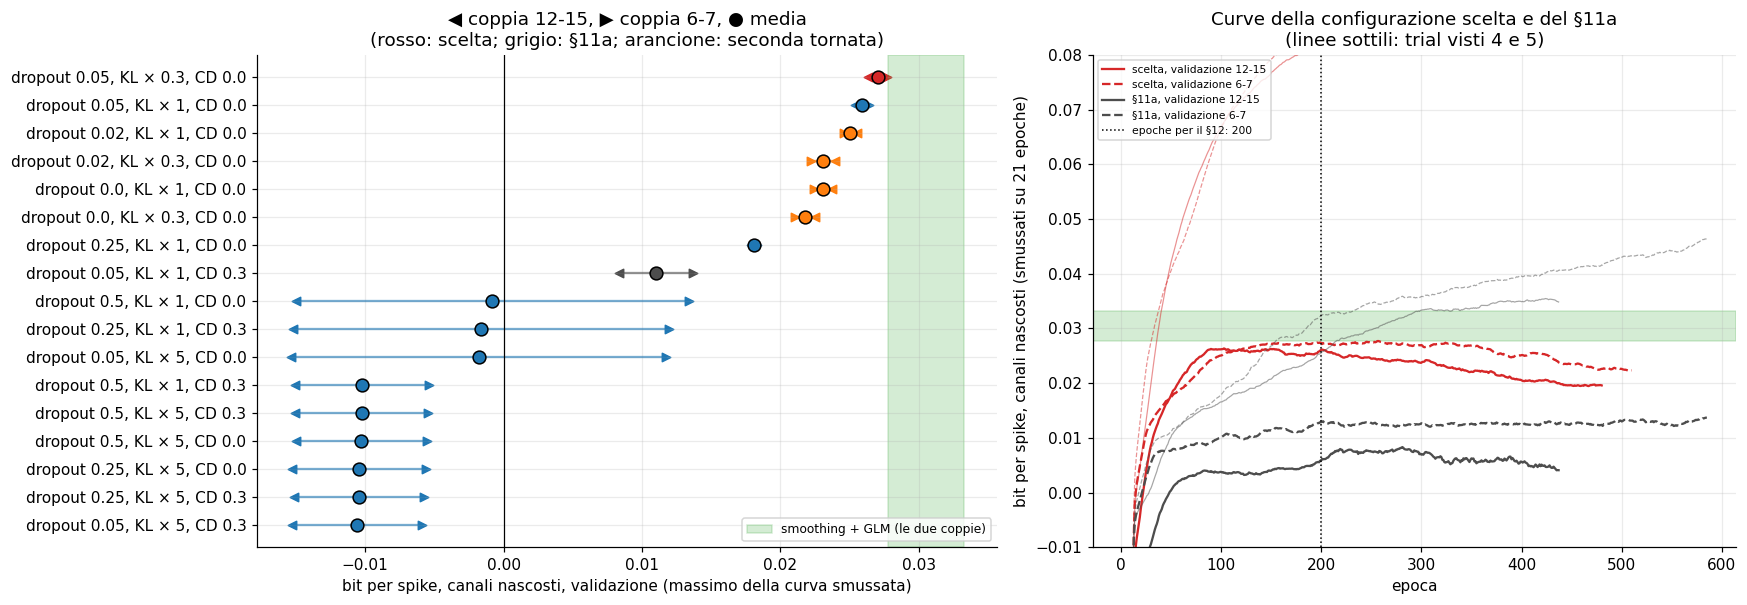

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": (1.15, 1)})
order_g = list(tab_g.index)[::-1]                           # dal punteggio più basso (in basso) al più alto (in alto)
for yi, name in enumerate(order_g):
    cfg = [c for c in GRID_ALL if cfg_name(c) == name][0]
    row = grid_row(cfg)
    v12, v67 = row["nascosti, val. 12-15"], row["nascosti, val. 6-7"]
    col = "C3" if cfg == BEST_CFG else ("0.3" if cfg == CENTER else ("C1" if cfg in GRID2 else "C0"))
    ax[0].plot([v12, v67], [yi, yi], color=col, lw=1.5, alpha=0.6)
    ax[0].scatter([v12], [yi], color=col, marker="<", s=30); ax[0].scatter([v67], [yi], color=col, marker=">", s=30)
    ax[0].scatter(row["punteggio"], yi, color=col, s=70, edgecolor="k", zorder=3)
ax[0].axvspan(min(REF_GLM.values()), max(REF_GLM.values()), color="C2", alpha=0.2, label="smoothing + GLM (le due coppie)")
ax[0].axvline(0, color="k", lw=0.8)
ax[0].set(yticks=range(len(order_g)), yticklabels=order_g, xlabel="bit per spike, canali nascosti, validazione (massimo della curva smussata)",
          title="◀ coppia 12-15, ▶ coppia 6-7, ● media\n(rosso: scelta; grigio: §11a; arancione: seconda tornata)")
ax[0].legend(fontsize=8, loc="lower right")
for cfg, c in ((BEST_CFG, "C3"), (CENTER, "0.3")):
    for (vt, _), ls in zip(PAIRS_11, ("-", "--")):
        h_ = res_g[(cfg, vt)]["history"]
        ax[1].plot(h_.index, smooth_curve(h_, "bit per spike nascosti, validazione"), ls, color=c, lw=1.5,
                   label=f"{'scelta' if cfg == BEST_CFG else '§11a'}, validazione {vt[0]}-{vt[1]}")
        ax[1].plot(h_.index, smooth_curve(h_, "bit per spike nascosti, trial visti (4, 5)"), ls, color=c, lw=0.8, alpha=0.5)
ax[1].axhspan(min(REF_GLM.values()), max(REF_GLM.values()), color="C2", alpha=0.2)
ax[1].axvline(N_EP_LF, color="k", ls=":", lw=1, label=f"epoche per il §12: {N_EP_LF}")
ax[1].set(xlabel="epoca", ylabel="bit per spike, canali nascosti (smussati su 21 epoche)", ylim=(-0.01, 0.08),
          title="Curve della configurazione scelta e del §11a\n(linee sottili: trial visti 4 e 5)")
ax[1].legend(fontsize=7, loc="upper left")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_grid.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **La configurazione scelta: dropout 0.05, peso del KL × 0.3, senza coordinated dropout.** Sui canali
  nascosti dei trial di validazione fa 0.026 (coppia 12-15) e 0.028 (coppia 6-7), punteggio 0.0270. Le
  due epoche di picco sono 103 e 257: **N_EP_LF = 200**.
- **Le prime sei configurazioni sono in pratica equivalenti** (punteggi da 0.022 a 0.027): tutte senza
  coordinated dropout, con dropout fino a 0.05 e peso del KL fino a × 1. Le differenze tra loro sono
  dell'ordine della differenza tra le due coppie di una stessa configurazione, con un solo seme per
  coppia: la scelta tra queste sei non è significativa. Conta il gruppo: niente coordinated dropout, poca
  regolarizzazione.
- **Il dropout ha il suo massimo all'interno** (0.05 meglio di 0, 0.02 e 0.25). **Il peso del KL no**: ×
  0.3 è appena meglio di × 1 (0.0270 contro 0.0259), ed è il valore più basso provato. Come dichiarato
  prima di guardare, valori ancora più bassi restano per il §14.
- **Nessuna delle 17 configurazioni supera lo smoothing con la regressione** (0.0305 in media): la migliore
  resta sotto dell'11%. Sulla coppia 12-15 la distanza è piccola (0.026 contro 0.028), sulla 6-7 no (0.028
  contro 0.033).
- **Rispetto al §11a il guadagno è grande** (da 0.011 a 0.027), e viene soprattutto dal togliere il
  coordinated dropout.
- **Il modello memorizza ancora molto**: sui trial visti i canali nascosti arrivano a 0.068-0.092, tre volte
  la validazione. Nella figura a destra le curve di validazione salgono fino a circa 100 epoche, restano
  piatte fino a circa 250 e poi calano piano, mentre quelle dei trial visti continuano a salire. La
  regolarizzazione non chiude questa distanza; restano da provare più dati (le altre due sessioni, §14) e
  la curva "quanti trial servono" (§13).
- **Limiti**: la scelta è fatta sugli stessi trial su cui si misura (il massimo di una curva rumorosa è un
  po' ottimista; vale anche per la penalità del GLM); un solo seme per coppia e solo il blocco 0. La misura
  vera, sui trial di test e su 5 blocchi, è al §12.

### Riepilogo del §11

**Che cosa portiamo al §12:**

| scelta | valore | da dove |
|---|---|---|
| encoder, condizione iniziale, generatore | 64 | §10.3 (le grandezze sono nelle alternative del §14) |
| fattori | 25 | come la GPFA (§11.1) |
| dropout | 0.05 | griglia, massimo all'interno (§11b) |
| coordinated dropout | 0 | griglia: con 0.3 sempre peggio (§11b); stesso esito nei dati sintetici (§10.6) |
| peso del KL | 0.3 / (30 × 160) = 6.25·10⁻⁵ | griglia, sul bordo: valori più bassi al §14 (§11b) |
| L2 sul generatore, passo di apprendimento | 10⁻², 4·10⁻³ | §10.3 (nelle alternative del §14) |
| epoche | **200, fisse** | il picco dei canali nascosti sulla validazione (§11b); al §12 non si usa la regola di arresto sull'errore di ricostruzione, che sceglieva versioni tardive (§11a) |
| due forme | tutti i canali (metro comune); 120 + 40 (canali nascosti) | §11.1 |
| asticella per i canali nascosti | smoothing + regressione di Poisson | §11a |

**Che cosa abbiamo imparato su LFADS con questi dati**: impara poco (circa 0.027 bit per spike sui canali
nascosti) e memorizza molto; la regolarizzazione forte lo fa collassare, il coordinated dropout lo
peggiora; con la migliore configurazione trovata resta sotto il riferimento più semplice sui trial di
validazione. I conteggi contengono un ritmo a circa 18 Hz che il modello non riproduce (§11.3).

**Che cosa non abbiamo verificato**: che la configurazione scelta sulla forma "120 + 40" sia la migliore
anche per la forma con tutti i canali (lo assumiamo); che 200 epoche vadano bene anche negli altri
blocchi; valori del peso del KL sotto × 0.3; più semi per configurazione.

## 12 · LFADS con il metro comune, e il confronto alla pari con la GPFA

Ora la misura vera, sui **trial di test** dei 5 blocchi del 03. In ogni blocco LFADS si allena sui **12
trial di training** e i 3 trial di test passano nel modello già allenato, senza riallenarlo. Con le
epoche fisse (§11b) i trial di validazione non servono più per fermarsi: come la GPFA, CEBRA e tutti
gli altri metodi, LFADS impara su tutti i 12 trial di training.

Il §12 è diviso in due parti:

- **§12a (questa)**: il riconoscimento della fase con il metro comune e le traiettorie single-trial;
- **§12b**: la misura propria dei modelli generativi, i canali nascosti dei trial di test.

### 12.1 · I tre modelli alla pari

Tre modelli della stessa famiglia, che partono dagli stessi conteggi dei 12 trial di training e danno
25 fattori per bin:

| modello | che cosa aggiunge | dati | da dove |
|---|---|---|---|
| **FA** | separa il segnale condiviso dal rumore di ogni canale; nessun modello del tempo | radice dei conteggi, tutti i bin dei 12 trial | 02_new, §9 e §10.4 ("la GPFA senza il tempo") |
| **GPFA alla pari** | + fattori che cambiano gradualmente nel tempo | radice dei conteggi, **gli stessi pezzi da 600 ms di LFADS** | 02_new, §10 |
| **LFADS** | + regole del moto non lineari imparate, e legame esponenziale con le frequenze | conteggi, gli stessi pezzi | §11b |

**La GPFA alla pari si stima sui pezzi interi.** `elephant`, durante la stima, spezza ogni sequenza in
pezzi da 20 bin (02_new, §10.1): con i nostri pezzi da 30 bin ne farebbe due da 20 che si
sovrappongono, e la GPFA guarderebbe 400 ms alla volta mentre LFADS ne vede 600. Usiamo quindi i pezzi
interi, come nella prova del 02_new (§10.6), dove la stima sulle finestre intere dava un modello
migliore sui dati mai visti. Costa come l'altra (misurato: circa 2.5 minuti per stima). Per il resto le
impostazioni del 02_new: 25 fattori, 500 iterazioni, scala di tempo iniziale 100 ms. Le stime si
salvano su disco (`cache_04/gpfa`), come i modelli di LFADS.

**La GPFA "come nel §7b"** resta come quarta riga: quella stimata sulle finestre da 1 s dall'inizio
delle fasi, cioè la GPFA dei numeri del 03 (ma qui sui 1106 punti).

**LFADS**: la configurazione scelta al §11b (dropout 0.05, peso del KL × 0.3, senza coordinated
dropout), forma "tutti i canali", **200 epoche**, 5 semi. Il ciclo di allenamento (§10.5) tiene la
versione con l'errore più basso su un insieme di controllo; qui gli diamo come insieme di controllo i
pezzi di training stessi, il cui errore scende per tutto l'allenamento, e quindi la versione tenuta è in
pratica l'ultima. Lo controlliamo qui sotto. (Cambiare il ciclo per tenere sempre l'ultima versione
avrebbe cambiato l'impronta, e quindi richiesto di riallenare, tutti i modelli già salvati.)

**I fattori ordinati.** Per il confronto "con 2-3 coordinate" prendiamo i primi fattori **ordinati per
importanza**, come per la GPFA (`orthonormalize`, 02_new §10.5) e per la FA (02_new §9.4): si scompone
la matrice che porta dai fattori all'uscita (per LFADS dai fattori alle log-frequenze) con la SVD, e si
ruotano i fattori lungo le sue direzioni, dalla più forte. Il "tetto" è il classificatore su tutti i 25.

**Per le traiettorie** servono, come per CEBRA (§4.2), modelli stimati su **tutti i 15 trial**: i
fattori di blocchi diversi hanno orientamenti diversi e non si possono mescolare. Descrivono, non
misurano la generalizzazione.

30 allenamenti di LFADS (25 per blocco + 5 su tutti i trial) e 6 stime della GPFA: circa 40 minuti la
prima volta (misurati con il Mac in risparmio energetico: 33 minuti per LFADS, 4 allenamenti alla volta,
e 5 per la GPFA, 3 alla volta).

In [79]:
from sklearn.decomposition import FactorAnalysis            # la FA (02_new, §9)
import pickle                                               # per salvare su disco le GPFA stimate

LF_HP = dict(REAL_HP, dropout=BEST_CFG[0], kl_ic_scale=BEST_CFG[1] / (SEG_LEN * N_CH), cd_rate=BEST_CFG[2])  # la configurazione del §11b, tutti i canali
SEEDS_LF = range(5)                                         # 5 semi, come per CEBRA (§4)
KEEP_CH = [int(mod_rank[0])]                                # delle frequenze salviamo un solo canale (il più modulato, §11.2): qui servono i fattori

def train_trials(k):                                        # i 12 trial di training del blocco k (k = "tutti": tutti i 15)
    return [int(t) for t in TRIALS] if k == "tutti" else [int(t) for t in TRIALS if t not in TEST_TRIALS[k]]

def lf12_job(seed, trs, hp=None, segs=None, rate_cols=None):  # LFADS sui trial trs per N_EP_LF epoche; proietta tutti i 15 trial
    tr_ = np.concatenate([(SEGS if segs is None else segs)[t] for t in trs])
    return dict(hp=LF_HP if hp is None else hp, seed=seed, train=tr_, val=tr_,  # insieme di controllo = i pezzi di training (si tiene in pratica l'ultima versione)
                apply=[(SEGS if segs is None else segs)[t] for t in TRIALS], max_epochs=N_EP_LF, patience=N_EP_LF,
                rate_cols=KEEP_CH if rate_cols is None else rate_cols)

RUNS12 = [(k, sd) for k in list(range(5)) + ["tutti"] for sd in SEEDS_LF]  # (blocco, seme): 25 per blocco + 5 su tutti i trial
res12 = dict(zip(RUNS12, run_lfads_cached([lf12_job(sd, train_trials(k)) for k, sd in RUNS12])))

def order_by_readout(F, W):                                 # fattori ordinati per importanza: SVD della matrice d'uscita W (canali × fattori)
    U_, S_, Vt_ = np.linalg.svd(W, full_matrices=False)
    return F @ Vt_.T * S_                                   # coordinate lungo le direzioni di W, dalla più forte (come orthonormalize della GPFA)

def stitch_all(per_trial):                                  # ricuce le uscite di tutti i 15 trial e le mette in fila: 12233 bin
    return np.concatenate([stitch(y_, t) for t, y_ in zip(TRIALS, per_trial)])

F_LF12 = {run: order_by_readout(stitch_all(r["factors"]), r["weights"]["readout.0.weight"]) for run, r in res12.items()}
ep_kept = np.array([r["best_epoch"] for r in res12.values()])
print(f"LFADS: {len(res12)} modelli; versione tenuta: epoca {ep_kept.min()}-{ep_kept.max()} su {N_EP_LF} "
      f"(uguale a {N_EP_LF} in {int((ep_kept == N_EP_LF).sum())} casi); durata media {np.mean([r['seconds'] for r in res12.values()]) / 60:.1f} minuti")

Allenamenti LFADS: 0 eseguiti ora, 30 riletti dal disco
LFADS: 30 modelli; versione tenuta: epoca 196-200 su 200 (uguale a 200 in 12 casi); durata media 4.1 minuti


In [80]:
CACHE_GP = CACHE / "gpfa"                                   # le GPFA stimate, su disco
CACHE_GP.mkdir(parents=True, exist_ok=True)
GP_ITERS = 500                                              # iterazioni della stima (02_new, §10.1)

def gpfa_fit_whole(segs, x_dim, iters):
    """GPFA sui pezzi interi (senza il taglio a 20 bin di elephant, come al 02_new §10.6). Gira in un processo separato."""
    import contextlib, os                                   # per silenziare i messaggi di elephant
    import numpy as np
    from elephant.gpfa import gpfa_core
    cut_orig = gpfa_core.gpfa_util.cut_trials               # la funzione che taglia i pezzi...
    gpfa_core.gpfa_util.cut_trials = lambda seqs, seg_length=np.inf: cut_orig(seqs, seg_length=np.inf)  # ...sostituita da una che non taglia
    try:
        np.random.seed(0)                                   # punto di partenza fisso
        seqs = np.array([(s_.shape[0], np.sqrt(s_.astype(float)).T) for s_ in segs], dtype=[("T", int), ("y", "O")])  # radice dei conteggi
        with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
            params, _ = gpfa_core.fit(seqs, x_dim=x_dim, bin_width=20.0, em_max_iters=iters, tau_init=100.0)
    finally:
        gpfa_core.gpfa_util.cut_trials = cut_orig           # in ogni caso si rimette la funzione originale
    return params

def gp_key(segs, x_dim, iters):                             # impronta di una stima della GPFA: codice, impostazioni, dati
    h = hashlib.sha1(inspect.getsource(gpfa_fit_whole).encode())
    h.update(json.dumps([x_dim, iters]).encode()); h.update(np.ascontiguousarray(segs).tobytes())
    return h.hexdigest()[:16]

def gpfa_cached(seg_sets, x_dim=K_PCA, iters=GP_ITERS):     # le GPFA di più insiemi di pezzi: rilette dal disco o stimate 3 alla volta
    keys = [gp_key(sg, x_dim, iters) for sg in seg_sets]
    todo = [i for i, k_ in enumerate(keys) if RETRAIN or not (CACHE_GP / f"{k_}.pkl").exists()]
    fits = Parallel(n_jobs=3)(delayed(gpfa_fit_whole)(seg_sets[i], x_dim, iters) for i in todo)
    for i, p_ in zip(todo, fits):
        with open(CACHE_GP / f"{keys[i]}.pkl", "wb") as f_:
            pickle.dump(p_, f_)
    print(f"GPFA: {len(todo)} stimate ora, {len(keys) - len(todo)} rilette dal disco")
    out = []
    for k_ in keys:
        with open(CACHE_GP / f"{k_}.pkl", "rb") as f_:
            out.append(pickle.load(f_))
    return out

BLOCKS12 = list(range(5)) + ["tutti"]
GP12 = dict(zip(BLOCKS12, gpfa_cached([np.concatenate([SEGS[t] for t in train_trials(k)]) for k in BLOCKS12])))
F_GP12 = {k: stitch_all([gpfa_infer_segments(SEGS[t], GP12[k]) for t in TRIALS]) for k in BLOCKS12}  # fattori ordinati, tutta la sessione

def fa_factors(trs):                                        # FA con 25 fattori sulla radice dei conteggi dei trial trs (tutti i loro bin); fattori ordinati di tutta la sessione
    Y = np.sqrt(COUNTS.astype(float))
    fa_ = FactorAnalysis(n_components=K_PCA, svd_method="lapack", random_state=0).fit(Y[np.isin(trial, trs)])
    return order_by_readout(fa_.transform(Y), fa_.components_.T)  # ordinati come quelli della GPFA (02_new, §9.4)

F_FA12 = {k: fa_factors(train_trials(k)) for k in BLOCKS12}
print("Fattori per bin:", {"FA": F_FA12[0].shape, "GPFA alla pari": F_GP12[0].shape, "LFADS": F_LF12[(0, 0)].shape})

GPFA: 0 stimate ora, 6 rilette dal disco


Fattori per bin: {'FA': (12233, 25), 'GPFA alla pari': (12233, 25), 'LFADS': (12233, 25)}


**Lettura.**

- **La versione tenuta è in pratica l'ultima**, come volevamo: in tutti i 30 modelli è tra l'epoca 196
  e la 200 (in 12 proprio la 200). Le "200 epoche fisse" sono quindi 200 a meno di 4.
- **Un allenamento dura in media 4.1 minuti** (4 alla volta sulla CPU, con il Mac in risparmio
  energetico; senza, 1.8 minuti: §12.4). Modelli e GPFA restano su disco: rieseguire il notebook non
  riallena nulla.
- **I tre modelli danno 25 fattori per ognuno dei 12 233 bin della sessione**: la FA bin per bin, la GPFA
  e LFADS ricucendo i pezzi. In ogni blocco i fattori dei 3 trial di test vengono da modelli i cui pesi
  quei trial non li hanno mai visti. Le scelte del §11b (configurazione, 200 epoche) invece sono state
  fatte sui trial del blocco 0, alcuni dei quali sono trial di test negli altri blocchi: lo stesso limite
  del numero di passi di CEBRA nella parte A.

### 12.2 · Il riconoscimento della fase

Il metro comune del §1.2, sugli stessi 1106 punti e gli stessi 5 blocchi: classificatore a 10 vicini
stimato sui punti dei trial di training, giudicato su quelli dei trial di test, accuratezza bilanciata
(a caso 12.5%). Per ognuno dei quattro modelli (FA, GPFA come nel §7b, GPFA alla pari, LFADS):

- i **primi 2, 3 e 7 fattori ordinati**;
- le mappe a **3 coordinate** costruite sui 25 fattori con **PCA, Isomap e UMAP** (come nel 03 sui fattori
  GPFA), stimate sui soli punti di training;
- il **tetto**: il classificatore su tutti i 25 fattori.

LFADS ha 5 semi (per UMAP, il seme di UMAP è lo stesso di LFADS); per FA e GPFA, UMAP ha 5 semi.
Accanto, i numeri della parte A sui 25 PC dei firing rate smussati (PCA, Isomap, UMAP, CEBRA-Time, tetto)
e l'orologio (§5.3).

**Senza `SnapTo`** (§9.5): lo stesso calcolo per i primi 3 fattori e per il tetto, togliendo i punti di
`SnapTo` sia dal training sia dal test (7 fasi: a caso 14.3%).

In [81]:
GETTERS12 = {"FA": [lambda k: F_FA12[k]],                   # per ogni modello, una funzione blocco -> fattori di tutta la sessione (una per seme)
             "GPFA come nel §7b": [lambda k: X_GP[k]],
             "GPFA alla pari": [lambda k: F_GP12[k]],
             "LFADS": [lambda k, sd=sd: F_LF12[(k, sd)] for sd in SEEDS_LF]}
MEASURES12 = {"primi 2 fattori": lambda g, i: decode_map(fold_inp(lambda k: g(k)[:, :2]), emb_none),
              "primi 3 fattori": lambda g, i: decode_map(fold_inp(lambda k: g(k)[:, :3]), emb_none),
              "primi 7 fattori": lambda g, i: decode_map(fold_inp(lambda k: g(k)[:, :7]), emb_none),
              "PCA, d = 3": lambda g, i: decode_map(fold_inp(g), emb_pca(3)),
              "Isomap, d = 3": lambda g, i: decode_map(fold_inp(g), emb_isomap(3)),
              "UMAP, d = 3": None,                          # calcolata in parallelo in run_measure
              "tetto: tutti i 25 fattori": lambda g, i: decode_map(fold_inp(g), emb_none)}

def run_measure(name, meas):                                # le accuratezze di un modello per una misura: una per seme (5 per UMAP anche con un solo modello)
    gs = GETTERS12[name]
    if meas == "UMAP, d = 3":                               # UMAP in parallelo: ai processi passano solo i 1106 punti di ogni blocco, non tutta la sessione
        inps = [fold_inp(g) for g in gs] if len(gs) > 1 else [fold_inp(gs[0])] * 5
        return Parallel(n_jobs=5)(delayed(decode_map)(inp_, emb_umap(3, seed=i)) for i, inp_ in enumerate(inps))
    return [MEASURES12[meas](g, i) for i, g in enumerate(gs)]

ACC12 = {(name, meas): run_measure(name, meas) for name in GETTERS12 for meas in MEASURES12}
tab12 = pd.DataFrame({name: {meas: fmt(ACC12[(name, meas)]) for meas in MEASURES12} for name in GETTERS12}).T
tab12.loc["parte A: 25 PC dei firing rate smussati"] = [fmt(ACC["PCA, d = 2"]), fmt(ACC["PCA, d = 3"]), fmt(HI_ACC[("PCA", 7)]),
                                                        fmt(ACC["PCA, d = 3"]), fmt(ACC["Isomap, d = 3"]), fmt(ACC["UMAP, d = 3"]),
                                                        fmt(ACC["tetto, 25 dimensioni"])]
display(tab12)
print(f"Per confronto (parte A, 25 PC): CEBRA-Time con 2 e 3 coordinate libere {fmt(ACC['CEBRA-Time, 3 dimensioni'])} e "
      f"{fmt(ACC['CEBRA-Time, 4 dimensioni'])}; l'orologio da solo {acc_clock:.1f}; a caso 12.5")

,primi 2 fattori,primi 3 fattori,primi 7 fattori,"PCA, d = 3","Isomap, d = 3","UMAP, d = 3",tetto: tutti i 25 fattori
FA,17.4,17.3,21.5,19.9,22.2,21.7 (21.0-23.0),25.8
GPFA come nel §7b,31.1,33.8,45.3,33.2,43.8,50.5 (49.4-51.3),50.7
GPFA alla pari,32.1,30.9,41.5,32.5,44.9,50.4 (49.3-52.0),51.4
LFADS,17.9 (16.7-19.5),20.9 (19.1-22.4),32.2 (29.3-34.1),30.9 (27.9-34.7),40.0 (36.0-43.5),45.8 (43.6-49.0),46.5 (44.7-47.7)
parte A: 25 PC dei firing rate smussati,26.0,32.4,39.0,32.4,36.0,42.6 (41.9-43.2),42.2


Per confronto (parte A, 25 PC): CEBRA-Time con 2 e 3 coordinate libere 37.7 (35.3-40.6) e 40.4 (38.5-42.7); l'orologio da solo 48.5; a caso 12.5


In [82]:
keep_ns = phase[bins] != "SnapTo"                           # i punti di valutazione che non sono di SnapTo

def decode_subset(get, keep, d=None):                       # il metro comune solo sui punti `keep` (training e test), con i primi d fattori (None = tutti)
    idx = np.flatnonzero(keep)
    pred = pd.Series(index=idx, dtype=object)
    for k, (trn, tst) in enumerate(FOLDS):
        trn_k, tst_k = trn[keep[trn]], tst[keep[tst]]       # punti di training e di test del blocco k, senza SnapTo
        F = get(k) if d is None else get(k)[:, :d]
        clf = KNeighborsClassifier(n_neighbors=K_NN).fit(F[bins[trn_k]], phase[bins[trn_k]])
        pred.loc[tst_k] = clf.predict(F[bins[tst_k]])
    return balanced_accuracy_score(phase[bins[idx]], pred.loc[idx].values) * 100

rows_ns = {}
for name, gs in GETTERS12.items():
    rows_ns[name] = {"primi 3 fattori": fmt([decode_subset(g, keep_ns, 3) for g in gs]),
                     "tetto: tutti i 25 fattori": fmt([decode_subset(g, keep_ns) for g in gs])}
rows_ns["parte A: 25 PC dei firing rate smussati"] = {"primi 3 fattori": fmt(decode_subset(lambda k: PCA(3).fit(X25[k][bins[FOLDS[k][0]]]).transform(X25[k]), keep_ns)),
                                                      "tetto: tutti i 25 fattori": fmt(decode_subset(lambda k: X25[k], keep_ns))}
display(pd.DataFrame(rows_ns).T.rename_axis("senza SnapTo (7 fasi, a caso 14.3%)"))

,primi 3 fattori,tetto: tutti i 25 fattori
"senza SnapTo (7 fasi, a caso 14.3%)",,
FA,20.5,29.5
GPFA come nel §7b,38.6,57.9
GPFA alla pari,35.5,58.5
LFADS,23.6 (20.9-25.3),53.1 (50.6-54.1)
parte A: 25 PC dei firing rate smussati,37.2,48.0


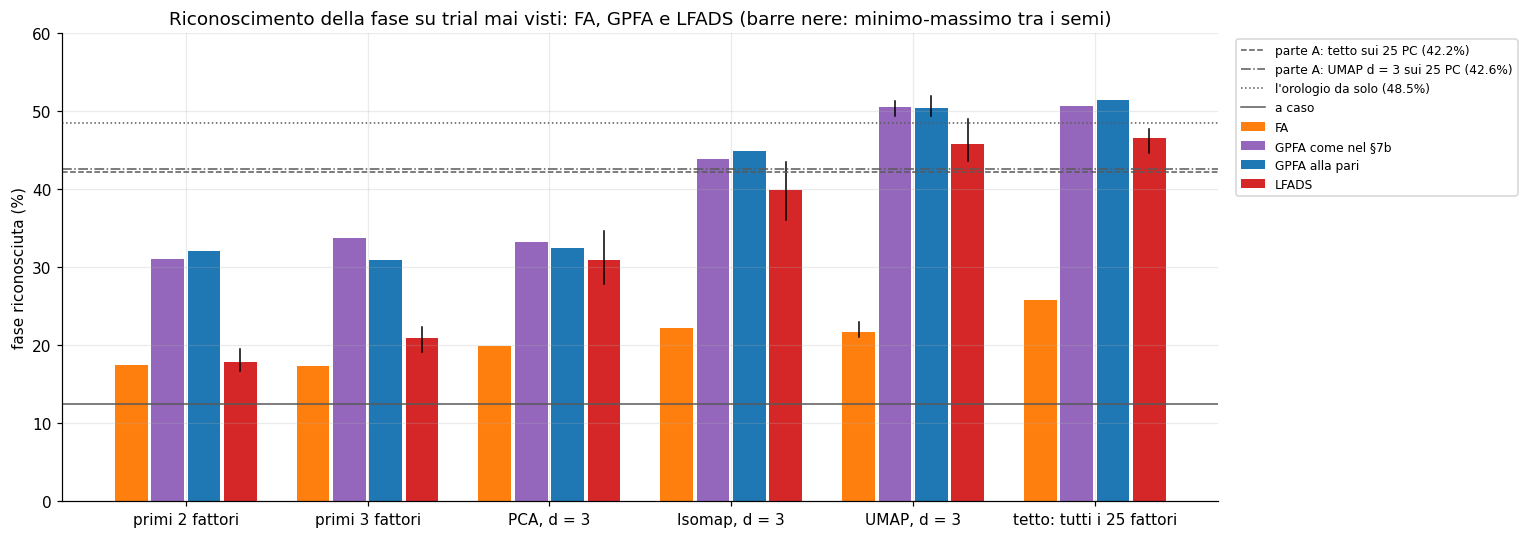

In [83]:
MEAS_PLOT = ["primi 2 fattori", "primi 3 fattori", "PCA, d = 3", "Isomap, d = 3", "UMAP, d = 3", "tetto: tutti i 25 fattori"]
COL12 = {"FA": "C1", "GPFA come nel §7b": "C4", "GPFA alla pari": "C0", "LFADS": "C3"}
fig, ax = plt.subplots(figsize=(14, 5))
w12 = 0.2
for i, name in enumerate(GETTERS12):
    for j, meas in enumerate(MEAS_PLOT):
        v = np.atleast_1d(ACC12[(name, meas)])
        x = j + (i - 1.5) * w12
        ax.bar(x, v.mean(), width=w12 * 0.9, color=COL12[name], label=name if j == 0 else None)
        if len(v) > 1:
            ax.plot([x, x], [v.min(), v.max()], color="k", lw=1)  # minimo-massimo tra i semi
for yv, lab, ls in ((ACC["tetto, 25 dimensioni"], f"parte A: tetto sui 25 PC ({ACC['tetto, 25 dimensioni']:.1f}%)", "--"),
                    (np.mean(ACC["UMAP, d = 3"]), f"parte A: UMAP d = 3 sui 25 PC ({np.mean(ACC['UMAP, d = 3']):.1f}%)", "-."),
                    (acc_clock, f"l'orologio da solo ({acc_clock:.1f}%)", ":"), (12.5, "a caso", "-")):
    ax.axhline(yv, color="0.35", ls=ls, lw=1, label=lab)
ax.set(xticks=range(len(MEAS_PLOT)), xticklabels=MEAS_PLOT, ylim=(0, 60), ylabel="fase riconosciuta (%)",
       title="Riconoscimento della fase su trial mai visti: FA, GPFA e LFADS (barre nere: minimo-massimo tra i semi)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_phase.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **LFADS non batte la GPFA alla pari: è sotto in ogni misura.** Con tutti i 25 fattori (il tetto)
  riconosce la fase nel 46.5% dei punti (44.7-47.7 tra i 5 semi), la GPFA alla pari nel 51.4%: nessuno dei
  5 semi arriva alla GPFA. Con le mappe a 3 coordinate la distanza resta: UMAP 45.8 contro 50.4, Isomap 40.0
  contro 44.9. Solo con la PCA a 3 è piccola (30.9 contro 32.5) e dentro la variazione tra i semi di LFADS
  (27.9-34.7).
- **La distanza più grande è nei primi fattori ordinati**: con 2 e 3 fattori LFADS arriva al 17.9% e al
  20.9%, la GPFA al 32.1% e al 30.9%; con 7, 32.2% contro 41.5%. Le direzioni che pesano di più nelle
  frequenze di LFADS non sono quelle che distinguono le fasi: la PCA a 3 sugli stessi 25 fattori, che
  cerca le direzioni di massima varianza, arriva al 30.9%. Perché, non l'abbiamo verificato.
- **Le due GPFA si equivalgono**: tetto 51.4 (alla pari: pezzi da 600 ms, tutti i bin dei trial di
  training) contro 50.7 (§7b: finestre da 1 s dall'inizio delle fasi); con UMAP 50.4 contro 50.5. Il
  taglio in pezzi da 600 ms non penalizza la GPFA, quindi non spiega la distanza di LFADS.
- **Il modello del tempo conta più di tutto il resto.** La FA, che tratta ogni bin da solo, arriva al
  25.8% con tutti i fattori e al 17.4% con i primi 2. Aggiungere fattori che cambiano gradualmente (la
  GPFA) porta il tetto al 51.4%. Aggiungere regole del moto non lineari (LFADS) non aggiunge altro, anzi
  toglie circa 5 punti. Perché i primi fattori della FA valgano così poco lo vediamo nei controlli del
  §12.3.
- **Rispetto ai riferimenti**: solo le due GPFA superano l'orologio (48.5%). LFADS resta sotto, ma sopra i
  25 PC dei firing rate smussati della parte A (tetto 42.2, UMAP a 3 coordinate 42.6) e sopra CEBRA-Time
  (37.7 e 40.4 con 2 e 3 coordinate libere).
- **Senza `SnapTo` (7 fasi, a caso 14.3%) l'ordine non cambia**: tetto GPFA alla pari 58.5, GPFA del §7b
  57.9, LFADS 53.1 (50.6-54.1), 25 PC della parte A 48.0, FA 29.5. Con i primi 3 fattori LFADS resta il
  più basso dopo la FA (23.6 contro 35.5 e 38.6 delle due GPFA). `SnapTo` non decide il confronto.
- **La figura** riassume la tabella: le barre rosse (LFADS) sono sotto le blu (GPFA alla pari) in ogni
  gruppo, e il minimo-massimo tra i semi (le linee nere) arriva alla GPFA solo con la PCA a 3.
- **Che cosa non dice: perché LFADS resta sotto.** Tre ipotesi, che controlleremo: (1) LFADS impara da 12
  trial, circa 3 minuti di registrazione, e al §11 memorizzava i trial visti (§13: training contro test,
  e quanti trial servono); (2) la configurazione è stata scelta sui canali nascosti, non sulla fase, e il
  peso del KL era sul bordo della griglia (§14); (3) riconoscere la fase non è il compito per cui LFADS è
  costruito: la sua misura, predire i canali nascosti dei trial di test, è al §12b.

### 12.3 · Le traiettorie single-trial

Le misure del §4.2 (seghettatura e consistenza, anche per versione del task) sulle 119 finestre da 1 s,
con i **primi 3 fattori ordinati** dei modelli stimati su **tutti i 15 trial**. Accanto, i numeri della
parte A (PCA, Isomap, UMAP, CEBRA-Time sui 25 PC) e quelli della GPFA del 02_new (0.011 e 0.11, stimata
sulle finestre stesse).

Va tenuto presente che per GPFA alla pari e LFADS ogni finestra è ricucita da pezzi da 600 ms (§9.2),
mentre la GPFA del 02_new vedeva ogni finestra da 1 s intera.

In [84]:
def traj_of(F):                                             # le misure del §4.2 con i primi 3 fattori ordinati
    return traj_stats([w_[:, :3] for w_ in cut(F)])

TRAJ12 = {"FA (tutti i trial)": [traj_of(F_FA12["tutti"])],
          "GPFA alla pari (tutti i trial)": [traj_of(F_GP12["tutti"])],
          "LFADS (tutti i trial, 5 semi)": [traj_of(F_LF12[("tutti", sd)]) for sd in SEEDS_LF],
          **{f"parte A: {name}": TRAJ[name] for name in ("PCA", "Isomap", "UMAP", "CEBRA-Time, 4 dimensioni")}}
def fmt3(v):                                                # "media (minimo-massimo)" con 3 decimali (fmt della parte A ne ha uno: è per le percentuali)
    v = np.atleast_1d(v)
    return f"{v.mean():.3f}" if len(v) == 1 else f"{v.mean():.3f} ({v.min():.3f}-{v.max():.3f})"

rows_t12 = {}
for name, runs in TRAJ12.items():
    d_ = pd.DataFrame(runs)
    rows_t12[name] = {c: fmt3(d_[c].values) for c in d_.columns}
rows_t12["GPFA del 02_new (§10.5, finestre intere)"] = {"seghettatura": "0.011", "consistenza, tutte le ripetizioni": "0.11"}
display(pd.DataFrame(rows_t12).T.fillna("non calcolata"))

,seghettatura,"consistenza, tutte le ripetizioni","consistenza, solo trial dispari","consistenza, solo trial pari",consistenza per versione (media delle due)
FA (tutti i trial),7.321,0.029,0.026,0.042,0.034
GPFA alla pari (tutti i trial),0.017,0.118,0.118,0.159,0.138
"LFADS (tutti i trial, 5 semi)",0.028 (0.018-0.048),0.109 (0.090-0.135),0.109 (0.064-0.149),0.155 (0.128-0.188),0.132 (0.103-0.155)
parte A: PCA,0.013,0.088,0.085,0.134,0.109
parte A: Isomap,0.275,0.095,0.081,0.162,0.122
parte A: UMAP,0.596 (0.571-0.628),0.125 (0.110-0.134),0.102 (0.095-0.123),0.187 (0.164-0.209),0.144 (0.137-0.152)
"parte A: CEBRA-Time, 4 dimensioni",0.074 (0.066-0.080),0.106 (0.086-0.127),0.110 (0.080-0.134),0.134 (0.095-0.166),0.122 (0.091-0.141)
"GPFA del 02_new (§10.5, finestre intere)",0.011,0.11,non calcolata,non calcolata,non calcolata


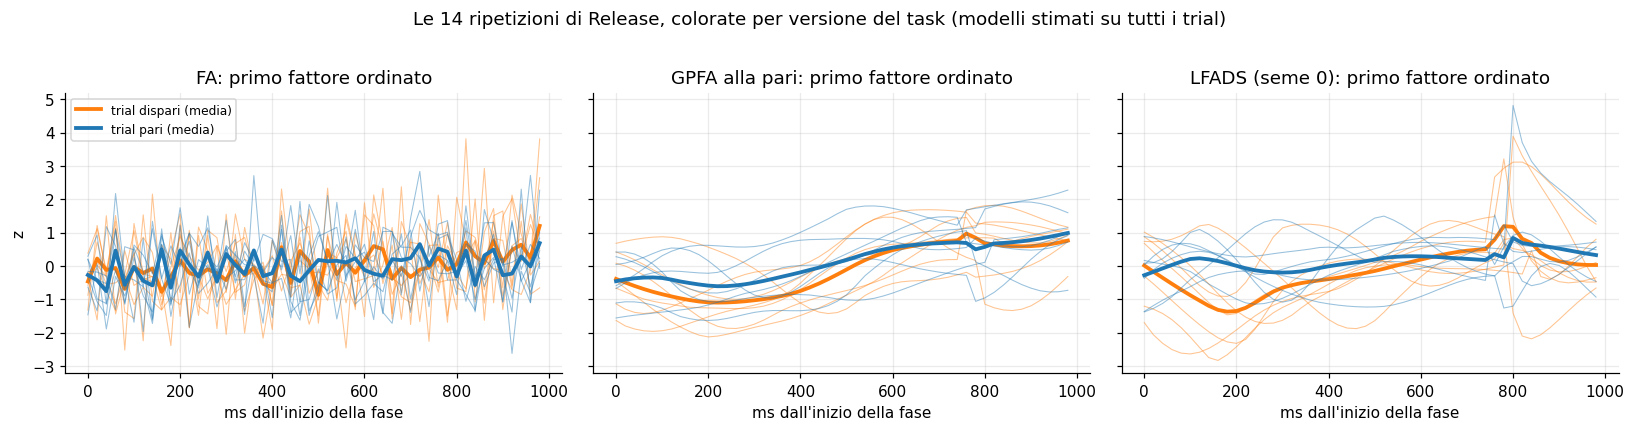

In [85]:
show12 = {"FA": cut(F_FA12["tutti"]), "GPFA alla pari": cut(F_GP12["tutti"]), "LFADS (seme 0)": cut(F_LF12[("tutti", 0)])}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a_, (name, tr_) in zip(ax, show12.items()):
    R = np.stack([tr_[i][:, 0] for i in idx_ph])            # il primo fattore ordinato di ogni ripetizione di Release
    R = (R - R.mean()) / R.std()                            # stessa scala per tutti i modelli
    for odd, c, lab in ((True, "C1", "trial dispari"), (False, "C0", "trial pari")):
        sel = WIN_ODD[idx_ph] == odd
        for r_ in R[sel]:
            a_.plot(t_win, r_, color=c, lw=0.7, alpha=0.45)
        a_.plot(t_win, R[sel].mean(0), color=c, lw=2.5, label=f"{lab} (media)")
    a_.set(title=f"{name}: primo fattore ordinato", xlabel="ms dall'inizio della fase")
ax[0].set_ylabel("z"); ax[0].legend(fontsize=8)
fig.suptitle(f"Le {len(idx_ph)} ripetizioni di {PH_SHOW}, colorate per versione del task (modelli stimati su tutti i trial)", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_trajectories.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **LFADS è liscio quasi come la GPFA**: seghettatura 0.028 (0.018-0.048 tra i semi) contro 0.017 della
  GPFA alla pari e 0.013 della PCA; molto meno di CEBRA-Time (0.074), Isomap (0.275) e UMAP (0.596). Quasi
  tutta la sua seghettatura viene però da poche finestre, quelle con il cambio di trial (controlli qui
  sotto). La FA, che non ha un modello del tempo, arriva a 7.3: come un rumore senza memoria, anzi un po' di
  più (controlli qui sotto).
- **Consistenza: LFADS e GPFA alla pari.** Su tutte le ripetizioni LFADS 0.109 (0.090-0.135), la GPFA alla
  pari 0.118; separando le due versioni del task 0.132 (0.103-0.155) contro 0.138. La differenza è dentro la
  variazione tra i semi di LFADS. UMAP è un po' più alto (0.125 e 0.144), CEBRA-Time un po' più basso (0.106
  e 0.122), la FA quasi a zero (0.029 e 0.034).
- **Per tutti i metodi la consistenza sale separando le versioni**, e i trial pari sono più simili tra loro
  dei dispari (GPFA alla pari 0.159 contro 0.118, LFADS 0.155 contro 0.109), come per i metodi della parte A
  nelle righe in basso.
- **GPFA alla pari e GPFA del 02_new**: seghettatura 0.017 contro 0.011, consistenza 0.118 contro 0.11. I
  pezzi ricuciti rendono la GPFA un po' meno liscia, non meno consistente.
- **La figura** (le 14 ripetizioni di `Release`, primo fattore ordinato): la FA è rumore attorno a una media
  quasi piatta; GPFA e LFADS danno curve lisce, e in tutti e due la media dei trial dispari scende verso i
  200 ms più di quella dei pari. Tra 760 e 840 ms c'è un salto, molto più forte in LFADS: è il cambio di
  trial, dove i modelli ripartono da capo (controlli qui sotto).
- **Che cosa non dice**: questi modelli sono stimati su tutti i 15 trial, quindi descrivono le traiettorie
  ma non misurano la generalizzazione; e i primi 3 fattori ordinati non sono le direzioni migliori di LFADS
  per distinguere le fasi (§12.2).

#### Due controlli sulle traiettorie: le giunture e il ritmo di 18 Hz

**Le giunture.** Al §11.4 i fattori di due pezzi consecutivi di LFADS, nella zona che hanno in comune,
differivano in media di 0.65 deviazioni standard, e avevamo rimandato qui la domanda: quanto pesano le
giunture sulla seghettatura? Dividiamo i bin delle 119 finestre in due gruppi: quelli **nella zona comune
a due pezzi**, dove la ricucitura fa la media di due pezzi, e quelli **coperti da un pezzo solo**. Poi
calcoliamo la seghettatura in ciascun gruppo (ogni differenza seconda va al suo bin centrale). Se le
giunture contano, la seghettatura è più alta nelle zone comuni. La FA e la PCA della parte A non sono
ricucite: per loro i due gruppi devono dare lo stesso numero, e questo controlla la misura stessa.

**La giuntura più grande: il cambio di trial.** I pezzi non scavalcano mai il confine tra due trial
(§9.2): lì GPFA e LFADS ripartono da capo. Il cambio di trial cade dentro `Release` (§1.5), quindi
dentro le finestre da 1 s di `Release`. Contiamo quali finestre lo contengono e ricalcoliamo la
seghettatura senza di loro.

**Il ritmo di 18 Hz.** I fattori della FA sono più seghettati di un rumore senza memoria. Per un rumore
che cambia a caso da un bin all'altro la seghettatura vale 6 (calcolo a mano: la differenza seconda
x[t+1] − 2x[t] + x[t−1] ha varianza 1 + 4 + 1 = 6 volte quella di x), anzi 6 × 50/49 = 6.12 perché lo
z-score di ogni finestra usa la varianza dei suoi 50 bin. Un'oscillazione che quasi a ogni bin cambia
verso alza ancora la differenza seconda: il ritmo di ~18 Hz del §11.3 fa un periodo ogni 2.8 bin. Per
saperlo misuriamo quanta parte della potenza dei primi 3 fattori ordinati cade tra 16 e 20 Hz, con lo
spettro medio su finestre da 1 s (come al §11.3).

In [86]:
COVER = np.zeros(n_bins, int)                               # in quanti pezzi sta ogni bin della sessione
for t in TRIALS:
    for a in SEG_START[t]:
        COVER[a:a + SEG_LEN] += 1                           # ogni pezzo copre 30 bin a partire dal suo inizio
IN_OVL = COVER > 1                                          # vero per i bin nella zona comune a due pezzi (dove la ricucitura fa la media)
MID = np.concatenate([np.arange(w["start"] + 1, w["stop"] - 1) for w in windows])  # i bin centrali delle differenze seconde, finestra dopo finestra

def rough_split(F):                                         # seghettatura dei primi 3 fattori nei bin delle zone comuni e nei bin di un pezzo solo
    d2 = np.concatenate([(np.diff((T_ - T_.mean(0)) / (T_.std(0) + 1e-9), n=2, axis=0) ** 2).mean(1)  # come roughness (§4.2): un valore per bin centrale
                         for T_ in (F[w["start"]:w["stop"], :3] for w in windows)])
    return d2[IN_OVL[MID]].mean(), d2[~IN_OVL[MID]].mean()

def share_18(F, L=50, step=25):                             # quota della potenza dei primi 3 fattori tra 16 e 20 Hz, spettro medio su finestre da 1 s
    win = np.hanning(L)                                     # la stessa finestra del §11.3
    S = np.mean([np.abs(np.fft.rfft((F[a:a + L, :3] - F[a:a + L, :3].mean(0)) * win[:, None], axis=0)) ** 2
                 for a in range(0, n_bins - L, step)], axis=0)  # potenza per frequenza, una colonna per fattore
    f_ = np.fft.rfftfreq(L, io.BIN_S)                       # le frequenze: da 0 a 25 Hz ogni 1 Hz
    return S[(f_ >= 16) & (f_ <= 20)].sum(0) / S[1:].sum(0)  # quota sulla potenza totale (senza lo 0 Hz)

def cross_tr(w):                                            # vero se nella finestra w cambia il trial
    return bool((np.diff(trial[w["start"]:w["stop"]]) != 0).any())

CUT_MS = [20 * (int(np.flatnonzero(np.diff(trial[w["start"]:w["stop"]]))[0]) + 1) for w in windows if cross_tr(w)]  # dove cade il cambio, in ms dall'inizio della finestra
print(f"Finestre con un cambio di trial: {len(CUT_MS)} su {len(windows)}, delle fasi {sorted({w['tag'] for w in windows if cross_tr(w)})}; "
      f"il cambio cade tra {min(CUT_MS)} e {max(CUT_MS)} ms dall'inizio della finestra")

CTRL12 = {"FA (tutti i trial)": [F_FA12["tutti"]],
          "GPFA alla pari (tutti i trial)": [F_GP12["tutti"]],
          "LFADS (tutti i trial, 5 semi)": [F_LF12[("tutti", sd)] for sd in SEEDS_LF],
          "parte A: PCA (non ricucita)": [PCA(3).fit(X_all).transform(Z25)]}
rows_c = {}
for name, Fs in CTRL12.items():
    sp = np.array([rough_split(F_) for F_ in Fs])           # (semi, 2): zone comuni, un pezzo solo
    q = 100 * np.array([share_18(F_) for F_ in Fs])         # (semi, 3): un valore per fattore, in %
    nb_ = [roughness([F_[w["start"]:w["stop"], :3] for w in windows if not cross_tr(w)]) for F_ in Fs]  # senza le finestre con il cambio di trial
    rows_c[name] = {"seghettatura, zone comuni": fmt3(sp[:, 0]), "seghettatura, un pezzo solo": fmt3(sp[:, 1]),
                    "seghettatura, senza cambio di trial": fmt3(nb_),
                    "16-20 Hz, fattore 1 (%)": fmt(q[:, 0]), "16-20 Hz, fattore 2 (%)": fmt(q[:, 1]), "16-20 Hz, fattore 3 (%)": fmt(q[:, 2])}
display(pd.DataFrame(rows_c).T)
rng_w = np.random.default_rng(0)                            # un rumore senza memoria, per il calcolo a mano
print(f"Bin centrali nelle zone comuni: {IN_OVL[MID].mean() * 100:.1f}%. Rumore senza memoria (2000 finestre da 50 bin): "
      f"seghettatura {roughness([rng_w.standard_normal((50, 3)) for _ in range(2000)]):.2f} (a mano: 6 × 50/49 = {6 * 50 / 49:.2f}); "
      f"quota 16-20 Hz {100 * share_18(rng_w.standard_normal((n_bins, 3))).mean():.1f}% (a mano: 5 frequenze su 25 = 20%)")

Finestre con un cambio di trial: 14 su 119, delle fasi ['Release']; il cambio cade tra 760 e 840 ms dall'inizio della finestra


,"seghettatura, zone comuni","seghettatura, un pezzo solo","seghettatura, senza cambio di trial","16-20 Hz, fattore 1 (%)","16-20 Hz, fattore 2 (%)","16-20 Hz, fattore 3 (%)"
FA (tutti i trial),7.324,7.317,7.491,51.4,24.4,31.1
GPFA alla pari (tutti i trial),0.012,0.023,0.012,0.0,0.0,0.0
"LFADS (tutti i trial, 5 semi)",0.005 (0.004-0.006),0.051 (0.031-0.090),0.005 (0.004-0.005),0.2 (0.1-0.5),0.0 (0.0-0.1),0.0 (0.0-0.1)
parte A: PCA (non ricucita),0.013,0.012,0.013,0.0,0.0,0.0


Bin centrali nelle zone comuni: 49.4%. Rumore senza memoria (2000 finestre da 50 bin): seghettatura 6.12 (a mano: 6 × 50/49 = 6.12); quota 16-20 Hz 20.1% (a mano: 5 frequenze su 25 = 20%)


**Lettura.**

- **Il controllo della misura funziona**: per la FA e la PCA della parte A, che non sono ricucite, i due
  gruppi di bin danno lo stesso numero (FA 7.324 e 7.317, PCA 0.013 e 0.012).
- **Dove si ricuciono i pezzi le traiettorie sono lisce**: nelle zone comuni la seghettatura è 0.005
  (0.004-0.006) per LFADS e 0.012 per la GPFA alla pari, come la PCA. Il disaccordo tra pezzi consecutivi
  visto al §11.4 viene assorbito dalla media pesata, che passa gradualmente da un pezzo all'altro.
- **Tutta la seghettatura in più di LFADS viene dal cambio di trial.** Il cambio cade in 14 finestre su
  119, tutte di `Release`, tra 760 e 840 ms dall'inizio. Senza quelle 14 finestre LFADS scende da 0.028 a
  0.005 (0.004-0.005): **il più liscio di tutti**, più della GPFA alla pari (0.012) e della PCA (0.013).
  Nei bin coperti da un pezzo solo, tra cui l'inizio di ogni trial, sale invece a 0.051 (0.031-0.090). Al
  cambio di trial il modello riparte dalla sola condizione iniziale del primo pezzo, e il primo bin di un
  pezzo era già il punto più debole nei dati sintetici (§10b).
- **I primi fattori della FA sono in buona parte il ritmo di 18 Hz**: tra 16 e 20 Hz cade il 51.4% della
  potenza del primo fattore, il 24.4% del secondo e il 31.1% del terzo. Per un rumore senza memoria è il
  20.1%, come il calcolo a mano (5 frequenze su 25 = 20%); anche la seghettatura del rumore, 6.12,
  coincide con il calcolo a mano (6 × 50/49). Il ritmo del §11.3 è un'attività comune a molti canali, cioè proprio quello
  che la FA cerca, e la FA non ha un modo per preferire i segnali lenti: lo mette nei fattori più forti. È
  coerente con la seghettatura sopra quella del rumore (un'oscillazione che cambia verso ogni 1.4 bin alza
  la differenza seconda) e con i primi 2-3 fattori della FA al 17% nel riconoscimento della fase (§12.2).
- **GPFA e LFADS il ritmo non lo prendono**: tra 16 e 20 Hz cade lo 0.0% e lo 0.2% (0.1-0.5) della potenza
  del primo fattore, come per la PCA dei firing rate smussati. La GPFA, con fattori che cambiano
  gradualmente, non potrebbe; LFADS in linea di principio potrebbe, ma non lo fa, in accordo con il §11.3
  (i trial generati da LFADS non avevano l'autocorrelazione oscillante dei dati veri).
- **Che cosa non dice**: il controllo guarda i primi 3 fattori ordinati e le finestre da 1 s, non tutti i
  25 fattori; che il salto al cambio di trial pesi anche sul riconoscimento della fase è poco probabile
  (pochi punti di valutazione cadono vicino a un confine, §1.5), ma non l'abbiamo misurato; l'origine del
  ritmo di 18 Hz resta sconosciuta (§11.3).

### Riepilogo del §12a

**Prima risposta alla domanda della parte B**, per il riconoscimento della fase e le traiettorie: **no**,
su questi dati la non linearità e le regole del moto imparate da LFADS non migliorano la GPFA. Le
traiettorie di LFADS sono più lisce dentro i trial e consistenti come quelle della GPFA, ma riconoscono la
fase circa 5 punti peggio.

| domanda | risposta | dove |
|---|---|---|
| LFADS riconosce la fase meglio della GPFA alla pari? | **no**: 46.5% (44.7-47.7) contro 51.4% con tutti i 25 fattori; sotto anche con le mappe a 3 coordinate e senza `SnapTo` | §12.2 |
| e rispetto agli altri metodi? | sopra i 25 PC della parte A (42.2%) e CEBRA-Time; sotto l'orologio (48.5%), che superano solo le GPFA | §12.2 |
| che cosa conta di più? | avere un modello del tempo: FA 25.8%, GPFA 51.4%; la non linearità di LFADS non aggiunge | §12.2 |
| le traiettorie di LFADS sono lisce e ripetibili? | lisce: 0.005 senza il cambio di trial (GPFA alla pari 0.012); consistenti come la GPFA (0.109 contro 0.118) | §12.3 |
| le giunture tra i pezzi contano? | no; conta il cambio di trial, dove LFADS riparte da capo | §12.3 |
| perché la FA va così male? | i suoi primi fattori sono in buona parte il ritmo di 18 Hz | §12.3 |

**Che cosa non abbiamo verificato**: perché LFADS resta sotto la GPFA (pochi dati e memorizzazione, §13;
configurazione, §14); se la distanza cambia nella misura propria dei modelli generativi, i canali nascosti
dei trial di test (§12b); il tutto vale per una sola sessione e per i 5 blocchi fissati nel 03.

### 12.4 · La misura dei modelli generativi: i canali nascosti dei trial di test (§12b)

Il riconoscimento della fase (§12.2) chiede ai fattori di separare le fasi, una cosa per cui nessuno di
questi modelli è stato allenato. Ora la misura per cui sono costruiti: **predire attività mai vista**
(§9.4). In ogni blocco ogni modello impara sui 12 trial di training, dove vede tutti i 160 canali; nei 3
trial di test riceve solo i **120 canali visibili** e deve indovinare i **40 nascosti**. Il voto è in
bit per spike (§9.4): 0 = "dire sempre la frequenza media del canale", di più = meglio.

Ogni trial è di test in un solo blocco: mettendo in fila le previsioni dei 5 blocchi si ottiene una
previsione di **tutta la sessione** fatta solo su trial mai visti, e il voto si calcola sui 12 233 bin
(il benchmark usa tutti i bin dei trial di test). Accanto, il voto blocco per blocco.

| modello | come predice i nascosti di un trial di test | da dove |
|---|---|---|
| **smoothing + GLM** (il riferimento) | smussa i 120 visibili (σ = 50 ms) e, per ogni nascosto, una regressione di Poisson stimata sui trial di training; penalità 0.1 | §11a, il riferimento del benchmark |
| **FA** | ricava i fattori di ogni bin dai soli visibili, poi la conta attesa del modello per i nascosti | §12.1 |
| **GPFA alla pari** | la stessa GPFA del §12a (stimata sui 160 canali dei pezzi di training); nei pezzi di test ricava i fattori dai soli visibili, poi la conta attesa | §12.1 |
| **LFADS** | la forma "120 visibili + 40 nascosti" del §11: l'encoder legge i visibili, l'uscita dà tutti i 160. Configurazione del §11b, 200 epoche, 5 semi | §11, §12.1 |

**La conta attesa di FA e GPFA.** Questi due modelli descrivono la **radice** dei conteggi, con un rumore
gaussiano. Se la radice di un conteggio y ha media μ e varianza v, allora la media di y è μ² + v. La
varianza v ha due parti: il rumore proprio del canale (R per la GPFA, Ψ per la FA) e l'incertezza sui
fattori, che dai soli 120 visibili non si ricavano esattamente (Σ, portata sul canale dai suoi pesi:
c Σ cᵀ). Al §10b, con tutti i canali visibili, avevamo usato μ² + R; qui usiamo la formula completa, e
μ² + R resta come variante.

**Una seconda variante della GPFA**: invece della conta attesa del modello, una regressione di Poisson dai
25 fattori (ricavati dai visibili) a ogni canale nascosto, stimata sui trial di training, come fanno i
riferimenti del benchmark con i modelli che non predicono da soli i conteggi. Penalità 0.1, come per lo
smoothing, senza sceglierla apposta.

**Tre calcoli a mano**, prima dei voti: (1) i bit per spike con la formula del §11a e con la
verosimiglianza di Poisson di `scipy`; (2) i fattori della FA con la nostra formula, usando tutti i 160
canali, contro quelli di `scikit-learn`; (3) la previsione della GPFA con il nostro modello ristretto,
usando tutti i 160 canali, contro quella del §10b.

25 allenamenti di LFADS (5 blocchi × 5 semi), 4 alla volta, e 10 regressioni da 40 canali: circa 12 minuti
la prima volta (misurati con il Mac non in risparmio energetico; in risparmio energetico gli allenamenti
durano più del doppio, §12.1).

In [87]:
from scipy.stats import poisson                             # la verosimiglianza di Poisson della libreria, per il calcolo a mano
from sklearn.linear_model import PoissonRegressor           # la regressione di Poisson (già usata al §11a)

LF_HID_HP = dict(LF_HP, n_in=len(HELD_IN))                  # la configurazione del §12a, ma l'encoder legge solo i 120 visibili
RUNS12B = [(k, sd) for k in range(5) for sd in SEEDS_LF]    # (blocco, seme): 25 allenamenti
res12b = dict(zip(RUNS12B, run_lfads_cached([lf12_job(sd, train_trials(k), hp=LF_HID_HP, segs=SEGS_HID, rate_cols=HID_COLS)
                                             for k, sd in RUNS12B])))  # 12 trial di training, 200 epoche; salva le frequenze dei 40 nascosti
ep_b = np.array([r["best_epoch"] for r in res12b.values()])
print(f"LFADS (120 + 40): {len(res12b)} modelli; versione tenuta: epoca {ep_b.min()}-{ep_b.max()} su {N_EP_LF}; "
      f"durata media {np.mean([r['seconds'] for r in res12b.values()]) / 60:.1f} minuti")

Y_HID = COUNTS[:, HIDDEN].astype(float)                     # i conteggi veri dei 40 nascosti, in tutta la sessione

def test_only(per_block):                                   # da "blocco -> previsione di tutta la sessione" alla sessione fatta solo di trial di test
    out = np.empty_like(per_block[0])
    for k in range(5):
        tb = np.isin(trial, TEST_TRIALS[k])                 # i bin dei 3 trial di test del blocco k
        out[tb] = per_block[k][tb]                          # presi dal modello del blocco k, che non li ha mai visti
    return out

PRED_LF = [test_only([stitch_all(res12b[(k, sd)]["rates"]) for k in range(5)]) for sd in SEEDS_LF]  # per seme: conte attese dei 40 nascosti, 12233 × 40

Allenamenti LFADS: 0 eseguiti ora, 25 riletti dal disco
LFADS (120 + 40): 25 modelli; versione tenuta: epoca 194-200 su 200; durata media 1.8 minuti


In [88]:
def gpfa_vis(segs, params, ch):                             # i fattori della GPFA ricavati dai soli canali ch (media e incertezza), pezzo per pezzo
    p_ = dict(params, C=params["C"][ch], d=params["d"][ch], R=params["R"][np.ix_(ch, ch)])  # il modello ristretto ai canali ch
    with open(os.devnull, "w") as devnull, contextlib.redirect_stdout(devnull):
        lat, _ = gpfa_core.exact_inference_with_ll(gpfa_seqs(segs[..., ch]), p_, get_ll=False)
    return lat["latent_variable"], lat["Vsm"]               # per pezzo: fattori (25 × bin) e incertezza (25 × 25 × bin)

def gpfa_hidden(segs, params):                              # conte attese dei nascosti in ogni pezzo, dai soli visibili: completa e variante μ² + R
    X_, V_ = gpfa_vis(segs, params, HELD_IN)
    C_h, d_h, r_h = params["C"][HIDDEN], params["d"][HIDDEN], np.diag(params["R"])[HIDDEN]  # pesi, medie e rumore dei nascosti
    mu = np.stack([(C_h @ x_ + d_h[:, None]).T for x_ in X_])  # media della radice dei conteggi: (pezzi, bin, 40)
    unc = np.stack([np.einsum("hi,ijt,hj->th", C_h, v_, C_h) for v_ in V_])  # incertezza sui fattori portata su ogni canale: c Σ cᵀ
    return mu ** 2 + r_h + unc, mu ** 2 + r_h

def fa_hidden(trs, C=None):                                 # FA sui 160 canali dei trial trs; conte attese dei nascosti in tutta la sessione, dai soli visibili
    Y = np.sqrt((COUNTS if C is None else C).astype(float))  # i conteggi (al §13.4 quelli spostati nel tempo)
    fa_ = FactorAnalysis(n_components=K_PCA, svd_method="lapack", random_state=0).fit(Y[np.isin(trial, trs)])
    L, psi, m = fa_.components_.T, fa_.noise_variance_, fa_.mean_  # pesi (160 × 25), rumore di ogni canale (Ψ), medie
    Lv, Lh = L[HELD_IN], L[HIDDEN]
    S = np.linalg.inv(np.eye(K_PCA) + Lv.T @ (Lv / psi[HELD_IN, None]))  # incertezza sui fattori, dati i 120 visibili (Σ)
    X = ((Y[:, HELD_IN] - m[HELD_IN]) / psi[HELD_IN]) @ Lv @ S  # fattori di ogni bin dai soli visibili: Σ Λᵀ Ψ⁻¹ (y − m)
    mu = X @ Lh.T + m[HIDDEN]                               # media della radice dei conteggi dei nascosti
    return mu ** 2 + psi[HIDDEN] + np.einsum("hi,ij,hj->h", Lh, S, Lh)

# (1) bit per spike: formula del §11a contro la verosimiglianza di Poisson di scipy (log k! si cancella nella differenza)
lam_ = PRED_LF[0]
by_scipy = (poisson.logpmf(Y_HID, lam_).sum() - poisson.logpmf(Y_HID, Y_HID.mean(0)).sum()) / Y_HID.sum() / np.log(2)
print(f"(1) bit per spike di LFADS (seme 0): formula del §11a {bits_per_spike(lam_, Y_HID):.6f}, con scipy {by_scipy:.6f}")
# (2) fattori della FA: la nostra formula con tutti i 160 canali contro transform di scikit-learn
Yq = np.sqrt(COUNTS.astype(float))
fa_chk = FactorAnalysis(n_components=K_PCA, svd_method="lapack", random_state=0).fit(Yq[np.isin(trial, train_trials(0))])
L_, psi_ = fa_chk.components_.T, fa_chk.noise_variance_
X_hand = ((Yq - fa_chk.mean_) / psi_) @ L_ @ np.linalg.inv(np.eye(K_PCA) + L_.T @ (L_ / psi_[:, None]))
print(f"(2) FA, fattori a mano contro scikit-learn: differenza massima {np.abs(X_hand - fa_chk.transform(Yq)).max():.1e} "
      f"(i fattori arrivano a {np.abs(X_hand).max():.1f})")
# (3) GPFA: il modello ristretto, con tutti i canali, contro la previsione del §10b
t_chk = int(TEST_TRIALS[0][0])
X_chk, _ = gpfa_vis(SEGS[t_chk], GP12[0], np.arange(N_CH))
mu_chk = np.stack([(GP12[0]["C"] @ x_ + GP12[0]["d"][:, None]).T for x_ in X_chk])
print(f"(3) GPFA, modello ristretto a tutti i 160 canali contro gpfa_sqrt_pred (§10b), trial {t_chk}: "
      f"differenza massima {np.abs(mu_chk - gpfa_sqrt_pred(SEGS[t_chk], GP12[0])).max():.1e}")

(1) bit per spike di LFADS (seme 0): formula del §11a 0.039313, con scipy 0.039313


(2) FA, fattori a mano contro scikit-learn: differenza massima 1.3e-15 (i fattori arrivano a 3.8)
(3) GPFA, modello ristretto a tutti i 160 canali contro gpfa_sqrt_pred (§10b), trial 3: differenza massima 0.0e+00


In [89]:
GP_PIECES = {int(t): gpfa_hidden(SEGS[t], GP12[k]) for k in range(5) for t in TEST_TRIALS[k]}  # ogni trial con la GPFA del blocco in cui è di test
PRED_GP = np.concatenate([stitch(GP_PIECES[int(t)][0], t) for t in TRIALS])     # conta attesa completa, ricucita
PRED_GP_R = np.concatenate([stitch(GP_PIECES[int(t)][1], t) for t in TRIALS])   # variante μ² + R (§10b)
PRED_FA = test_only([fa_hidden(train_trials(k)) for k in range(5)])
PRED_GLM = test_only([smooth_glm_rates(train_trials(k), 0.1) for k in range(5)])  # lo smoothing + GLM del §11a, sui 12 trial di training

def gpfa_glm(k, segs=None, gp=None, C=None, trs=None):     # variante: regressione di Poisson dai 25 fattori GPFA (ricavati dai visibili) ai nascosti, nel blocco k
    segs, gp, C = (SEGS if segs is None else segs), (GP12 if gp is None else gp), (COUNTS if C is None else C)  # al §13.4: i dati spostati nel tempo
    lat = np.concatenate([stitch(np.stack([x_.T for x_ in gpfa_vis(segs[t], gp[k], HELD_IN)[0]]), t) for t in TRIALS])  # fattori di tutta la sessione
    fit_ = np.isin(trial, train_trials(k) if trs is None else trs)  # la regressione si stima sui 12 trial di training (al §13b su meno trial)
    F = StandardScaler().fit(lat[fit_]).transform(lat)
    return np.column_stack([PoissonRegressor(alpha=0.1, max_iter=500).fit(F[fit_], C[fit_, h]).predict(F) for h in HIDDEN])

PRED_GPGLM = test_only([gpfa_glm(k) for k in range(5)])

PRED12B = {"smoothing + GLM (riferimento)": [PRED_GLM], "FA": [PRED_FA], "GPFA alla pari": [PRED_GP],
           "LFADS (5 semi)": PRED_LF,
           "variante: GPFA, μ² + R (§10b)": [PRED_GP_R], "variante: GPFA + regressione di Poisson": [PRED_GPGLM]}

def fmt4(v):                                                # "media [minimo, massimo]" con 4 decimali (le parentesi quadre perché i valori possono essere negativi)
    v = np.atleast_1d(v)
    return f"{v.mean():.4f}" if len(v) == 1 else f"{v.mean():.4f} [{v.min():.4f}, {v.max():.4f}]"

BPS12 = {}                                                  # (modello, dove) -> un valore per seme
for name, P in PRED12B.items():
    BPS12[(name, "tutta la sessione")] = [bits_per_spike(p_, Y_HID) for p_ in P]
    for k in range(5):
        tb = np.isin(trial, TEST_TRIALS[k])                 # i 3 trial di test del blocco k
        BPS12[(name, f"blocco {k}")] = [bits_per_spike(p_[tb], Y_HID[tb]) for p_ in P]
WHERE12 = ["tutta la sessione"] + [f"blocco {k}" for k in range(5)]
display(pd.DataFrame({name: {w: fmt4(BPS12[(name, w)]) for w in WHERE12} for name in PRED12B}).T
        .rename_axis("bit per spike, 40 canali nascosti, trial di test; LFADS: media [minimo, massimo] tra i semi"))
lf_vs = np.array([[BPS12[("LFADS (5 semi)", f"blocco {k}")][i] > BPS12[("smoothing + GLM (riferimento)", f"blocco {k}")][0]
                   for k in range(5)] for i in range(len(SEEDS_LF))])
gp_vs = [BPS12[("LFADS (5 semi)", f"blocco {k}")] > np.array(BPS12[("GPFA alla pari", f"blocco {k}")]) for k in range(5)]
print(f"LFADS sopra lo smoothing + GLM: {int(lf_vs.sum())} casi su {lf_vs.size} (blocco × seme); "
      f"sopra la GPFA alla pari: {int(np.sum(gp_vs))} su {lf_vs.size}")

,tutta la sessione,blocco 0,blocco 1,blocco 2,blocco 3,blocco 4
"bit per spike, 40 canali nascosti, trial di test; LFADS: media [minimo, massimo] tra i semi",,,,,,
smoothing + GLM (riferimento),0.0416,0.0381,0.0346,0.0417,0.0354,0.0418
FA,0.0358,0.0311,0.0341,0.0386,0.0278,0.0311
GPFA alla pari,0.0422,0.0378,0.0364,0.0427,0.0341,0.0435
LFADS (5 semi),"0.0388 [0.0383, 0.0393]","0.0327 [0.0307, 0.0352]","0.0334 [0.0326, 0.0350]","0.0417 [0.0408, 0.0427]","0.0331 [0.0313, 0.0356]","0.0363 [0.0351, 0.0376]"
"variante: GPFA, μ² + R (§10b)",0.0421,0.0377,0.0363,0.0421,0.0345,0.0433
variante: GPFA + regressione di Poisson,0.0474,0.0431,0.0411,0.0484,0.0398,0.0479


LFADS sopra lo smoothing + GLM: 4 casi su 25 (blocco × seme); sopra la GPFA alla pari: 2 su 25


In [90]:
BAND_OF = np.array([next(b for b, b_ in enumerate(bands) if h in b_) for h in HIDDEN])  # la fascia di frequenza (0 = la più lenta) di ogni nascosto
BAND_LAB = [f"fascia {b + 1}: {rate_hz[HIDDEN[BAND_OF == b]].min():.1f}-{rate_hz[HIDDEN[BAND_OF == b]].max():.1f} Hz" for b in range(4)]
rows_band = {name: {BAND_LAB[b]: fmt4([bits_per_spike(p_[:, BAND_OF == b], Y_HID[:, BAND_OF == b]) for p_ in P]) for b in range(4)}
             for name, P in PRED12B.items()}
display(pd.DataFrame(rows_band).T.rename_axis("bit per spike per fascia di frequenza (10 nascosti ciascuna), tutta la sessione"))

,fascia 1: 0.5-2.5 Hz,fascia 2: 3.5-7.8 Hz,fascia 3: 10.0-21.3 Hz,fascia 4: 22.6-45.3 Hz
"bit per spike per fascia di frequenza (10 nascosti ciascuna), tutta la sessione",,,,
smoothing + GLM (riferimento),0.0158,0.0709,0.0670,0.0256
FA,-0.0003,0.0250,0.0523,0.0309
GPFA alla pari,0.0007,0.0441,0.0704,0.0299
LFADS (5 semi),"-0.0087 [-0.0129, -0.0028]","0.0821 [0.0809, 0.0834]","0.0646 [0.0634, 0.0664]","0.0210 [0.0204, 0.0216]"
"variante: GPFA, μ² + R (§10b)",0.0007,0.0445,0.0705,0.0296
variante: GPFA + regressione di Poisson,0.0153,0.0780,0.0752,0.0302


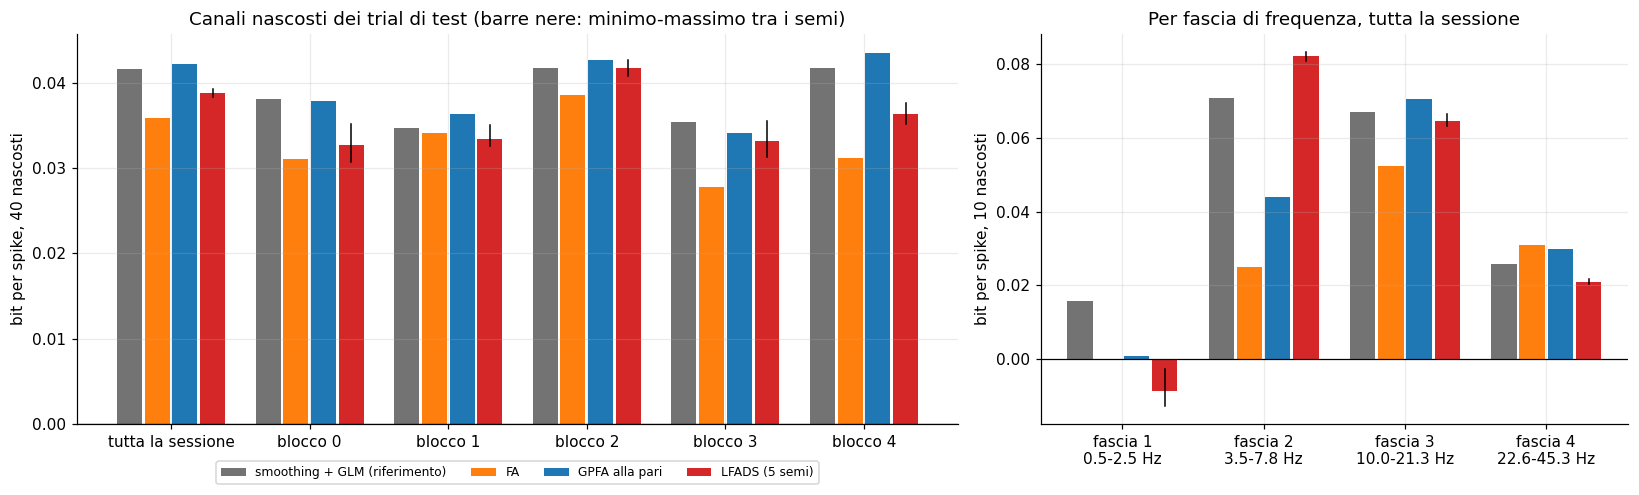

In [91]:
MAIN12B = ["smoothing + GLM (riferimento)", "FA", "GPFA alla pari", "LFADS (5 semi)"]
COL12B = {"smoothing + GLM (riferimento)": "0.45", "FA": "C1", "GPFA alla pari": "C0", "LFADS (5 semi)": "C3"}
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": (1.5, 1)})
for i, name in enumerate(MAIN12B):                          # a sinistra: tutta la sessione e i 5 blocchi
    for j, w in enumerate(WHERE12):
        v = np.array(BPS12[(name, w)])
        x = j + (i - 1.5) * 0.2
        ax[0].bar(x, v.mean(), width=0.18, color=COL12B[name], label=name if j == 0 else None)
        if len(v) > 1:
            ax[0].plot([x, x], [v.min(), v.max()], color="k", lw=1)  # minimo-massimo tra i semi
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set(xticks=range(len(WHERE12)), xticklabels=WHERE12, ylabel="bit per spike, 40 nascosti",
          title="Canali nascosti dei trial di test (barre nere: minimo-massimo tra i semi)")
ax[0].legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))  # sotto il grafico, per non coprire le barre
for i, name in enumerate(MAIN12B):                          # a destra: per fascia di frequenza
    for b in range(4):
        v = np.array([bits_per_spike(p_[:, BAND_OF == b], Y_HID[:, BAND_OF == b]) for p_ in PRED12B[name]])
        x = b + (i - 1.5) * 0.2
        ax[1].bar(x, v.mean(), width=0.18, color=COL12B[name])
        if len(v) > 1:
            ax[1].plot([x, x], [v.min(), v.max()], color="k", lw=1)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xticks=range(4), xticklabels=[l_.replace(": ", "\n") for l_ in BAND_LAB], ylabel="bit per spike, 10 nascosti",
          title="Per fascia di frequenza, tutta la sessione")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_cobps.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Gli allenamenti**: in tutti i 25 modelli la versione tenuta è tra l'epoca 194 e la 200, in pratica
  l'ultima. 1.8 minuti per modello, con il Mac non più in risparmio energetico (al §12a erano 4.1).
- **I tre calcoli a mano tornano**: i bit per spike con la nostra formula e con `scipy` coincidono
  (0.039313); i fattori della FA con la nostra formula differiscono da quelli di `scikit-learn` di circa
  10⁻¹⁵ (il valore esatto cambia con il numero di thread); la GPFA ristretta, usata con tutti i canali, dà
  esattamente la previsione del §10b
  (differenza 0). Le previsioni dei nascosti poggiano quindi su formule verificate.
- **Sulla sua misura LFADS non batte né la GPFA né il riferimento.** Su tutta la sessione: LFADS 0.0388 bit
  per spike [0.0383, 0.0393 tra i 5 semi], la GPFA alla pari 0.0422, lo smoothing + GLM 0.0416; sotto c'è
  solo la FA (0.0358). Blocco per blocco LFADS supera lo smoothing + GLM in 4 casi su 25 (blocco × seme) e
  la GPFA in 2 su 25; arriva alla pari solo nel blocco 2 (0.0417, come il riferimento; la GPFA 0.0427).
- **Conferma il §11b**: lì, sui trial di validazione, nessuna configurazione superava lo smoothing + GLM;
  qui, su trial mai visti e con 12 trial di training invece di 10, LFADS resta circa il 7% sotto (0.0388
  contro 0.0416).
- **Su questa misura il modello del tempo aiuta poco**: la GPFA supera la FA (0.0422 contro 0.0358), ma lo
  smoothing + GLM, che non ha un modello comune della popolazione, è già quasi lì (0.0416).
- **Conta molto come si passa dai fattori ai conteggi.** La variante GPFA + regressione di Poisson è la
  migliore di tutte, 0.0474 (il 14% sopra il riferimento): gli stessi fattori della GPFA, letti con una
  regressione di Poisson invece che con la conta attesa del modello, predicono meglio. L'incertezza sui
  fattori invece non pesa: con μ² + R la GPFA dà 0.0421 contro 0.0422.
- **Per fascia di frequenza il quadro cambia** (tabella e figura a destra):
  - **canali più lenti** (0.5-2.5 Hz): guadagnano qualcosa solo le due regressioni di Poisson (0.0158 e
    0.0153); GPFA e FA stanno a zero; LFADS va sotto zero (−0.0087 [−0.0129, −0.0028]), cioè fa peggio
    che dire la frequenza media del canale;
  - **3.5-7.8 Hz**: **LFADS è il migliore** (0.0821, contro 0.0709 del riferimento, 0.0780 della GPFA con
    la regressione di Poisson e 0.0441 della GPFA alla pari);
  - **da 10 a 45 Hz**: LFADS è sotto la GPFA (0.0646 contro 0.0704; 0.0210 contro 0.0299). Questi canali
    portano la maggior parte degli spike, e il voto complessivo è la media dei voti delle fasce pesata con i
    loro spike: è qui che LFADS perde.
  - Una spiegazione plausibile, non verificata, per le due fasce lente: la conta attesa di GPFA e FA viene
    da un rumore gaussiano sulla radice dei conteggi, una descrizione povera quando gli spike sono rari;
    i modelli con il rumore di Poisson (le regressioni e LFADS) vanno molto meglio tra 3.5 e 7.8 Hz.
- **Che cosa non dice**: (1) i 40 canali nascosti sono un solo sorteggio (§9.4); (2) perché LFADS va sotto
  zero sui canali più lenti: un'ipotesi è la memorizzazione del §11 (il readout di quei canali impara dai
  trial di training dettagli che non si ripetono), da controllare al §13; (3) la GPFA ha avuto una
  variante con la regressione di Poisson e LFADS no: la stessa regressione sui fattori di LFADS non
  l'abbiamo provata (§14); (4) i numeri del Neural Latents Benchmark non sono confrontabili con questi
  (altri dati, neuroni isolati invece di canali).

### 12.5 · Un canale nascosto, da vicino

Lo stesso trial e lo stesso canale del §11.2 (il trial 12, il nascosto più modulato, 8 secondi), ma ora con
i modelli del blocco in cui il trial 12 è di test: nessuno di loro l'ha mai visto. In grigio il firing rate
smussato con σ = 50 ms, che non è la verità (§11.2) ma aiuta l'occhio; in alto gli spike veri.

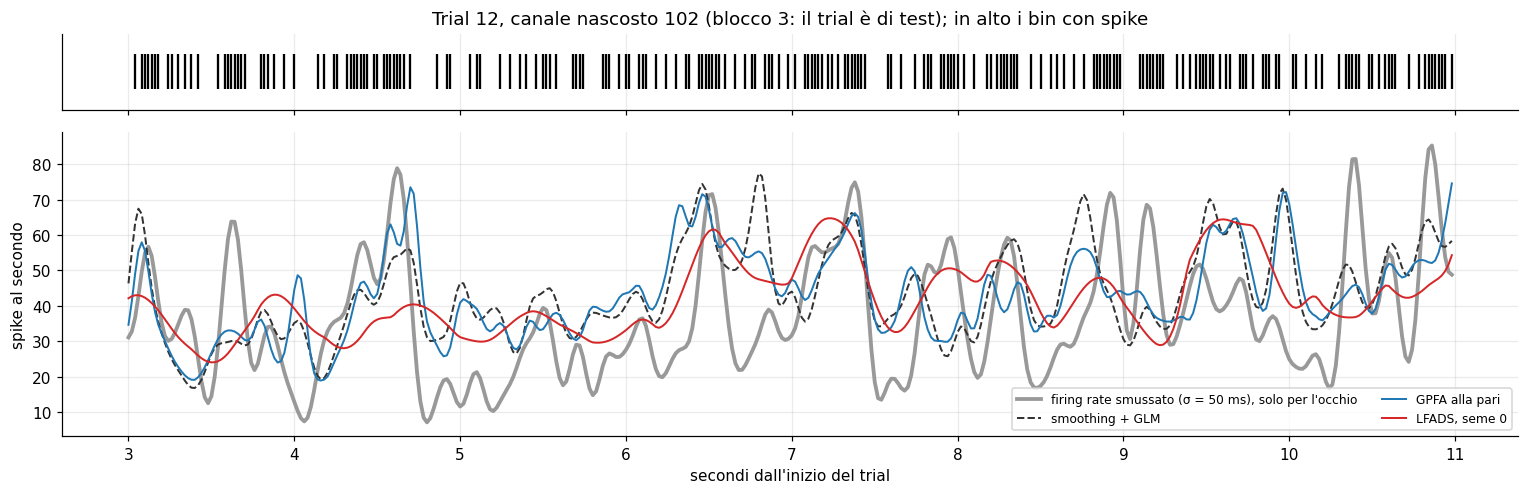

In [92]:
k12 = next(k for k in range(5) if 12 in TEST_TRIALS[k])     # il blocco in cui il trial 12 è di test
h12 = int(np.flatnonzero(HIDDEN == hid_show)[0])            # la colonna del canale mostrato tra i 40 nascosti
fig, ax = plt.subplots(2, 1, figsize=(14, 4.6), sharex=True, gridspec_kw={"height_ratios": (0.25, 1)})
ax[0].eventplot(t_w[COUNTS[win_, hid_show] > 0], color="k", lineoffsets=0.5, linelengths=0.8)  # i bin con almeno uno spike
ax[0].set(yticks=[], title=f"Trial 12, canale nascosto {hid_show} (blocco {k12}: il trial è di test); in alto i bin con spike")
ax[1].plot(t_w, SM_RATE[win_, hid_show], color="0.6", lw=2.5, label="firing rate smussato (σ = 50 ms), solo per l'occhio")
for name, p_, c_, ls_ in (("smoothing + GLM", PRED_GLM, "0.2", "--"), ("GPFA alla pari", PRED_GP, "C0", "-"),
                          ("LFADS, seme 0", PRED_LF[0], "C3", "-")):
    ax[1].plot(t_w, p_[win_, h12] / io.BIN_S, lw=1.3, color=c_, ls=ls_, label=name)  # conte attese per bin -> spike al secondo
ax[1].set(xlabel="secondi dall'inizio del trial", ylabel="spike al secondo"); ax[1].legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_hidden_example.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Tutti e tre i modelli seguono l'andamento lento del canale** senza averlo mai visto in questo trial:
  la salita tra 6 e 7.5 s, le oscillazioni tra 8 e 10 s.
- **LFADS è più liscio**: le sue frequenze cambiano su tempi più lunghi, mentre lo smoothing + GLM e la
  GPFA seguono anche le oscillazioni più rapide.
- **Nessuno scende quanto il firing rate smussato** (per esempio tra 4.8 e 5.2 s, o verso 7.8 s): i modelli
  restano tra 30 e 45 spike al secondo. Il firing rate smussato però non è la verità (§11.2), e le sue
  discese più profonde possono essere rumore.
- **Che cosa non dice**: è un canale solo in un trial solo, scelto con una regola (il nascosto più
  modulato), non per far bella figura a un modello; il confronto è nei numeri del §12.4.

### Riepilogo del §12b

| domanda | risposta | dove |
|---|---|---|
| LFADS predice i canali nascosti dei trial di test meglio della GPFA alla pari? | **no**: 0.0388 [0.0383, 0.0393] contro 0.0422 bit per spike; meglio solo in 2 casi su 25 (blocco × seme) | §12.4 |
| e meglio dello smoothing + GLM? | **no**: 0.0416; meglio solo in 4 casi su 25 | §12.4 |
| chi predice meglio? | la GPFA con una regressione di Poisson sui fattori: 0.0474 | §12.4 |
| dove LFADS va meglio, e dove peggio? | il migliore sui canali tra 3.5 e 7.8 Hz (0.0821); sotto zero sui più lenti, sotto la GPFA sui più veloci | §12.4 |
| i calcoli a mano tornano? | sì: bit per spike, fattori della FA, GPFA ristretta | §12.4 |

### La risposta del §12 alla domanda della parte B

Su questi dati, con 12 trial di training, **la non linearità e le regole del moto imparate da LFADS non
migliorano la GPFA**: né nel riconoscimento della fase (46.5% contro 51.4%, §12.2), né nella misura dei
modelli generativi (0.0388 contro 0.0422 bit per spike, §12.4). LFADS dà traiettorie più lisce dentro i
trial e consistenti come quelle della GPFA (§12.3), ed è il migliore su una sola fascia di canali.

**Che cosa non abbiamo verificato**: perché LFADS resta sotto (§13: memorizzazione, quanti trial servono;
§14: configurazione, peso del KL, lunghezza dei pezzi, controller, regressione di Poisson sui suoi fattori);
un solo sorteggio dei canali nascosti; una sola sessione.

## 13 · I controlli

Il §12 ha dato una risposta negativa: LFADS non migliora la GPFA. Prima di fidarsi, quattro controlli
sui risultati del §12, più uno sulla quantità di dati:

- **§13a (questa parte)**
  - **13.1** quanto cambiano i risultati con il **seme**;
  - **13.2** quanto i modelli vanno meglio sui **trial visti** che sui trial nuovi (la memorizzazione);
  - **13.3** il **gemello di Poisson**: senza legame con il task, il riconoscimento della fase deve
    scendere al caso;
  - **13.4** i **canali nascosti spostati nel tempo**: senza legame tra i canali, il voto deve scendere a 0;
- **§13b**: **13.5-13.7** quanti trial servono, per LFADS e per la GPFA.

### 13.1 · Quanto conta il seme

**Le distanze del §12 sono più grandi della variazione tra i semi?** Lo leggiamo dai numeri già
calcolati.

**I fattori cambiano da un seme all'altro?** La misura della parte A (§5.2): l'R² della trasformazione
lineare che porta i fattori di un seme il più vicino possibile a quelli di un altro, sui 1106 punti di
valutazione, per ogni coppia ordinata di semi (20 coppie). R² = 1 vuol dire "gli stessi fattori, a meno di
una trasformazione lineare". Con tutti i 25 fattori e con i primi 3 ordinati, per i modelli stimati su tutti
i trial e per quelli dei blocchi. GPFA e FA danno un solo modello (punto di partenza fisso), la PCA non
dipende dal caso.

**LFADS e GPFA vedono la stessa cosa?** La stessa misura tra i due modelli: quanto i 25 fattori della GPFA
spiegano quelli di LFADS, e viceversa.

In [93]:
acc_lf = np.array(ACC12[("LFADS", "tetto: tutti i 25 fattori")])           # tetto di LFADS, un valore per seme (§12.2)
acc_gp = ACC12[("GPFA alla pari", "tetto: tutti i 25 fattori")][0]
b_lf = np.array(BPS12[("LFADS (5 semi)", "tutta la sessione")])           # canali nascosti di LFADS, un valore per seme (§12.4)
b_gp = BPS12[("GPFA alla pari", "tutta la sessione")][0]
print(f"Fase (tetto): LFADS da {acc_lf.min():.1f} a {acc_lf.max():.1f} tra i 5 semi (ampiezza {np.ptp(acc_lf):.1f} punti); "
      f"GPFA alla pari {acc_gp:.1f}, {acc_gp - acc_lf.max():.1f} punti sopra il seme migliore")
print(f"Canali nascosti: LFADS da {b_lf.min():.4f} a {b_lf.max():.4f} (ampiezza {np.ptp(b_lf):.4f}); "
      f"GPFA alla pari {b_gp:.4f}, {b_gp - b_lf.max():.4f} sopra il seme migliore")

cons12 = {}
for d_, lab in ((K_PCA, "25 fattori"), (3, "primi 3 fattori ordinati")):
    cons12[f"LFADS, {lab}, stimato su tutti i trial"] = run_consistency([F_LF12[("tutti", sd)][bins, :d_] for sd in SEEDS_LF])
    cons12[f"LFADS, {lab}, modelli dei blocchi (media sui 5)"] = np.array(
        [run_consistency([F_LF12[(k, sd)][bins, :d_] for sd in SEEDS_LF]).mean() for k in range(5)])  # una media per blocco
cons12["parte A: CEBRA-Time, 3 dimensioni, stimato su tutti i trial"] = cons["CEBRA-Time, 3 dimensioni (stimato su tutti i trial)"]
cons12["parte A: UMAP, d = 3"] = cons["UMAP, d = 3"]
G_ = F_GP12["tutti"][bins]                                  # i 25 fattori della GPFA stimata su tutti i trial, sui 1106 punti
cons12["dai 25 fattori della GPFA a quelli di LFADS"] = np.array(
    [LinearRegression().fit(G_, F_LF12[("tutti", sd)][bins]).score(G_, F_LF12[("tutti", sd)][bins]) for sd in SEEDS_LF])
cons12["dai 25 fattori di LFADS a quelli della GPFA"] = np.array(
    [LinearRegression().fit(F_LF12[("tutti", sd)][bins], G_).score(F_LF12[("tutti", sd)][bins], G_) for sd in SEEDS_LF])
display(pd.Series({name: mean_range(v * 100) for name, v in cons12.items()} | {"GPFA, FA (un solo modello), PCA": "100 (per costruzione)"},
                  name="R² (%), media (min-max)").to_frame())

Fase (tetto): LFADS da 44.7 a 47.7 tra i 5 semi (ampiezza 3.0 punti); GPFA alla pari 51.4, 3.7 punti sopra il seme migliore
Canali nascosti: LFADS da 0.0383 a 0.0393 (ampiezza 0.0010); GPFA alla pari 0.0422, 0.0029 sopra il seme migliore


,"R² (%), media (min-max)"
"LFADS, 25 fattori, stimato su tutti i trial",88.7 (86.7-89.5)
"LFADS, 25 fattori, modelli dei blocchi (media sui 5)",87.4 (86.9-87.9)
"LFADS, primi 3 fattori ordinati, stimato su tutti i trial",40.4 (29.7-55.6)
"LFADS, primi 3 fattori ordinati, modelli dei blocchi (media sui 5)",38.4 (35.7-40.3)
"parte A: CEBRA-Time, 3 dimensioni, stimato su tutti i trial",63.4 (46.9-83.1)
"parte A: UMAP, d = 3",93.3 (87.5-99.2)
dai 25 fattori della GPFA a quelli di LFADS,85.8 (84.9-86.8)
dai 25 fattori di LFADS a quelli della GPFA,66.5 (65.1-67.7)
"GPFA, FA (un solo modello), PCA",100 (per costruzione)


**Lettura.**

- **Le distanze del §12 non dipendono dal seme.** Nel riconoscimento della fase i 5 semi di LFADS vanno da
  44.7% a 47.7% (3.0 punti), e la GPFA alla pari sta 3.7 punti sopra il seme migliore. Sui canali nascosti i
  semi vanno da 0.0383 a 0.0393, e la GPFA sta 0.0029 sopra il migliore: una distanza tre volte la
  variazione tra i semi.
- **I 25 fattori di LFADS, presi insieme, sono abbastanza stabili tra i semi**: l'R² da un seme all'altro è
  88.7% (86.7-89.5), e 87.4% con i modelli dei blocchi.
- **I primi 3 fattori ordinati invece cambiano molto**: 40.4%, con coppie di semi che scendono al 29.7%;
  meno anche delle mappe a 3 dimensioni della parte A (CEBRA-Time 63.4%, UMAP 93.3%).
  Le direzioni che pesano di più nelle frequenze non sono le stesse da un seme all'altro: insieme al §12.2
  (primi 3 fattori al 20.9%), dice che per LFADS i "primi fattori" non sono una descrizione affidabile.
  Conta tutto lo spazio dei 25.
- **I fattori della GPFA spiegano quasi tutti quelli di LFADS (85.8%), non il contrario (66.5%).** In parole
  semplici, quello che LFADS descrive è quasi tutto anche nella GPFA, mentre circa un terzo di quello che
  descrive la GPFA non si ritrova, linearmente, in LFADS. Attenzione: l'R² è la media sulle 25 dimensioni,
  ciascuna con lo stesso peso, comprese le più deboli; quali parti della GPFA manchino non l'abbiamo
  verificato.
- **Che cosa non dice**: le misure sono sui 1106 punti di valutazione, cioè solo nelle fasi di movimento,
  e sono lineari: due fattori legati in modo non lineare risultano diversi.

### 13.2 · Trial visti e trial nuovi

Al §11 LFADS prediceva i canali nascosti dei trial su cui aveva imparato tre volte meglio di quelli nuovi.
Qui la stessa domanda per tutti i modelli del §12.4, ciascuno nel suo blocco: i bit per spike dei 40
nascosti sui **12 trial di training** (visti: i loro nascosti sono serviti a stimare il modello) e sui **3
di test** (nuovi), poi la media sui 5 blocchi. Ogni modello va un po' meglio sui trial visti; conta quanto.

Nota: la colonna "trial nuovi" è la media dei 5 blocchi, quindi è vicina ma non uguale al voto di "tutta la
sessione" del §12.4, che mette insieme tutti i bin.

In [94]:
FULL13 = {"smoothing + GLM (riferimento)": [[smooth_glm_rates(train_trials(k), 0.1)] for k in range(5)],  # [blocco][seme] -> previsione di tutta la sessione
          "FA": [[fa_hidden(train_trials(k))] for k in range(5)],
          "GPFA alla pari": [[np.concatenate([stitch(gpfa_hidden(SEGS[t], GP12[k])[0], t) for t in TRIALS])] for k in range(5)],
          "GPFA + regressione di Poisson": [[gpfa_glm(k)] for k in range(5)],
          "LFADS (5 semi)": [[stitch_all(res12b[(k, sd)]["rates"]) for sd in SEEDS_LF] for k in range(5)]}

def seen_new(full, Y):                                      # bit per spike sui trial visti e su quelli nuovi, blocco per blocco: (semi, 5 blocchi, 2)
    out = np.zeros((len(full[0]), 5, 2))
    for k in range(5):
        trn_b, tst_b = np.isin(trial, train_trials(k)), np.isin(trial, TEST_TRIALS[k])  # i bin dei 12 trial di training e dei 3 di test
        for i, p_ in enumerate(full[k]):
            out[i, k] = bits_per_spike(p_[trn_b], Y[trn_b]), bits_per_spike(p_[tst_b], Y[tst_b])
    return out

SN13 = {name: seen_new(full, Y_HID) for name, full in FULL13.items()}
display(pd.DataFrame({name: {"trial visti (training)": fmt4(v[:, :, 0].mean(1)), "trial nuovi (test)": fmt4(v[:, :, 1].mean(1)),
                             "differenza": fmt4((v[:, :, 0] - v[:, :, 1]).mean(1)),
                             "nuovi / visti": fmt4(v[:, :, 1].mean(1) / v[:, :, 0].mean(1))} for name, v in SN13.items()}).T
        .rename_axis("bit per spike, 40 nascosti, media sui 5 blocchi; LFADS: media [minimo, massimo] tra i semi"))

,trial visti (training),trial nuovi (test),differenza,nuovi / visti
"bit per spike, 40 nascosti, media sui 5 blocchi; LFADS: media [minimo, massimo] tra i semi",,,,
smoothing + GLM (riferimento),0.0865,0.0383,0.0482,0.4430
FA,0.0477,0.0325,0.0152,0.6818
GPFA alla pari,0.0586,0.0389,0.0197,0.6638
GPFA + regressione di Poisson,0.0683,0.0441,0.0243,0.6447
LFADS (5 semi),"0.0882 [0.0870, 0.0892]","0.0355 [0.0350, 0.0360]","0.0527 [0.0510, 0.0541]","0.4021 [0.3929, 0.4136]"


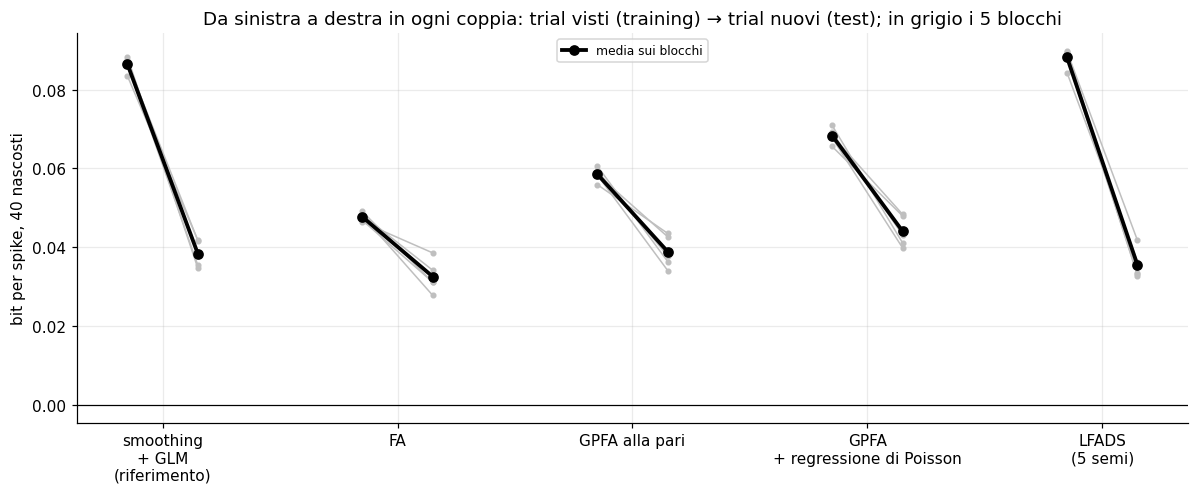

In [95]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (name, v) in enumerate(SN13.items()):
    vb = v.mean(0)                                          # (5 blocchi, 2): per LFADS media sui semi
    for k in range(5):
        ax.plot([i - 0.15, i + 0.15], vb[k], color="0.75", lw=1, marker="o", ms=3)  # un blocco: dai trial visti ai nuovi
    ax.plot([i - 0.15, i + 0.15], vb.mean(0), color="k", lw=2.5, marker="o", ms=6, label="media sui blocchi" if i == 0 else None)
ax.axhline(0, color="k", lw=0.8)
ax.set(xticks=range(len(SN13)), xticklabels=[n_.replace(" (", "\n(").replace(" + ", "\n+ ") for n_ in SN13],
       ylabel="bit per spike, 40 nascosti", title="Da sinistra a destra in ogni coppia: trial visti (training) → trial nuovi (test); in grigio i 5 blocchi")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_overfit.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Tutti i modelli vanno meglio sui trial visti**, ma non allo stesso modo. Sui trial nuovi resta:
  - circa due terzi del voto per FA (0.68), GPFA alla pari (0.66) e GPFA con la regressione di Poisson
    (0.64);
  - meno della metà per lo smoothing + GLM (0.44) e per LFADS (0.40 [0.39, 0.41]).
- **LFADS ha la differenza più grande** (0.0527 bit per spike, contro 0.0482 dello smoothing + GLM e 0.0197
  della GPFA alla pari) e il voto più alto sui trial visti (0.0882): è quello che impara di più dai trial
  di training, e la parte che non si ripete nei trial nuovi è la più grande. È la memorizzazione già vista
  al §11, ora su 5 blocchi e su trial di test.
- **La memorizzazione non spiega da sola la classifica**: lo smoothing + GLM memorizza quasi quanto LFADS,
  eppure sui trial nuovi va meglio (0.0383 contro 0.0355, medie sui blocchi). La GPFA memorizza meno e sui
  trial nuovi è alla pari con il riferimento (0.0389).
- **La figura**: in ogni coppia di punti, il primo è il voto sui trial visti e il secondo quello sui nuovi;
  le linee grigie dei 5 blocchi sono tutte vicine alla media, quindi il quadro è lo stesso in ogni blocco.
- **Che cosa non dice**: se con più trial di training la distanza si chiude (§13b, quanti trial servono);
  e i trial visti qui sono quelli i cui canali nascosti sono serviti a stimare il modello, quindi il loro
  voto non è una misura di generalizzazione.

### 13.3 · Il gemello di Poisson

**La domanda**: il 46.5% di LFADS sul riconoscimento della fase viene davvero dal legame tra attività e
task, o la catena LFADS → ricucitura → metro comune lo crea da sola? Un punto delicato: i pezzi ripartono a
ogni inizio di trial, e il solo tempo dall'inizio del trial riconosce la fase al 48.5% (l'orologio,
§5.3). Se i fattori ricuciti portassero con sé quell'orologio, il riconoscimento resterebbe alto anche su
dati senza alcun legame con il task.

**Il gemello di Poisson.** Partiamo dalle frequenze smussate (σ = 50 ms) dei 160 canali, ne prendiamo la
radice e le passiamo al gemello della parte A (§5.1): stesse ampiezze di Fourier, fasi casuali, **le stesse
per tutti i canali**. Poi torniamo al quadrato ed estraiamo i conteggi a caso con la distribuzione di Poisson.
Il gemello conserva:

- la frequenza media di ogni canale (calcolo a mano: le fasi casuali non cambiano né la media né la varianza
  della radice, e la media del quadrato è media² + varianza);
- le correlazioni tra i canali (stesse fasi per tutti) e la velocità con cui l'attività cambia nel tempo;
- i confini dei trial e i pezzi da 600 ms, che sono gli stessi;

ma l'attività non ha più nessun legame con le fasi del task. La radice serve a tornare a frequenze positive
(il gemello della radice può scendere sotto zero; il suo quadrato no).

Su 3 gemelli (semi 0-2) alleniamo LFADS come al §12a (12 trial di training per blocco, 200 epoche, seme di
LFADS = seme del gemello): 15 allenamenti. Sul gemello 0 anche la GPFA alla pari (5 stime) e, come
termine di confronto, il classificatore direttamente sulle frequenze del gemello. Le etichette di fase sono
quelle vere: **il riconoscimento deve scendere al caso** (12.5%).

In [96]:
TW_SEEDS = range(3)                                         # 3 gemelli
def poisson_twin(seed):                                     # gemello di Poisson: radice delle frequenze smussate a fasi casuali, al quadrato, poi conteggi a caso
    R_tw = phase_randomize(np.sqrt(SM_RATE), seed) ** 2     # frequenze del gemello (Hz), sempre positive
    return np.random.default_rng(1000 + seed).poisson(R_tw * io.BIN_S).astype(np.float32), R_tw  # conteggi per bin da 20 ms

TWIN13 = {sd: poisson_twin(sd) for sd in TW_SEEDS}
C_tw, R_tw0 = TWIN13[0]
Q_tw0 = phase_randomize(np.sqrt(SM_RATE), 0)                # la radice del gemello 0, prima del quadrato
iu = np.triu_indices(N_CH, 1)
print(f"Frequenza media di ogni canale, gemello contro dati: differenza massima {np.abs(R_tw0.mean(0) - SM_RATE.mean(0)).max():.1e} Hz "
      f"(le frequenze medie vanno da {SM_RATE.mean(0).min():.1f} a {SM_RATE.mean(0).max():.1f} Hz)")
print(f"Covarianze tra i canali della radice, gemello contro dati: differenza massima "
      f"{np.abs(np.cov(Q_tw0.T) - np.cov(np.sqrt(SM_RATE).T)).max():.1e} (la più grande vale {np.abs(np.cov(np.sqrt(SM_RATE).T)).max():.2f})")
print(f"Correlazioni tra coppie di canali delle frequenze: gemello contro dati, correlazione "
      f"{np.corrcoef(np.corrcoef(R_tw0.T)[iu], np.corrcoef(SM_RATE.T)[iu])[0, 1]:.3f}")
print(f"Conteggi: bin a zero {np.mean(C_tw == 0) * 100:.1f}% nel gemello, {np.mean(COUNTS == 0) * 100:.1f}% nei dati; "
      f"spike totali {C_tw.sum() / COUNTS.sum():.3f} volte quelli dei dati")
print(f"Legame con i dati veri: correlazione media, canale per canale, tra frequenze del gemello e frequenze vere "
      f"{np.mean([np.corrcoef(R_tw0[:, c], SM_RATE[:, c])[0, 1] for c in range(N_CH)]):.3f}")

Frequenza media di ogni canale, gemello contro dati: differenza massima 5.4e-06 Hz (le frequenze medie vanno da 0.5 a 57.2 Hz)
Covarianze tra i canali della radice, gemello contro dati: differenza massima 6.4e-08 (la più grande vale 6.11)
Correlazioni tra coppie di canali delle frequenze: gemello contro dati, correlazione 0.921
Conteggi: bin a zero 79.1% nel gemello, 77.3% nei dati; spike totali 1.002 volte quelli dei dati
Legame con i dati veri: correlazione media, canale per canale, tra frequenze del gemello e frequenze vere 0.014


In [97]:
SEGS_TW = {sd: {t: cut_segments(TWIN13[sd][0], t) for t in TRIALS} for sd in TW_SEEDS}  # i pezzi dei conteggi di ogni gemello
RUNS_TW = [(k, sd) for k in range(5) for sd in TW_SEEDS]
res_tw13 = dict(zip(RUNS_TW, run_lfads_cached([lf12_job(sd, train_trials(k), segs=SEGS_TW[sd]) for k, sd in RUNS_TW])))
F_LF_TW = {run: order_by_readout(stitch_all(r["factors"]), r["weights"]["readout.0.weight"]) for run, r in res_tw13.items()}
GP_TW = dict(zip(range(5), gpfa_cached([np.concatenate([SEGS_TW[0][t] for t in train_trials(k)]) for k in range(5)])))  # GPFA sul gemello 0
F_GP_TW = {k: stitch_all([gpfa_infer_segments(SEGS_TW[0][t], GP_TW[k]) for t in TRIALS]) for k in range(5)}
Z_TW = StandardScaler().fit_transform(R_tw0)                # le frequenze del gemello 0, z-scorate: il termine di confronto

rows_tw = {"LFADS sul gemello (3 gemelli)": {"primi 3 fattori": fmt([decode_map(fold_inp(lambda k, sd=sd: F_LF_TW[(k, sd)][:, :3]), emb_none) for sd in TW_SEEDS]),
                                             "tetto: tutte le dimensioni": fmt([decode_map(fold_inp(lambda k, sd=sd: F_LF_TW[(k, sd)]), emb_none) for sd in TW_SEEDS])},
           "GPFA alla pari sul gemello 0": {"primi 3 fattori": fmt(decode_map(fold_inp(lambda k: F_GP_TW[k][:, :3]), emb_none)),
                                            "tetto: tutte le dimensioni": fmt(decode_map(fold_inp(lambda k: F_GP_TW[k]), emb_none))},
           "classificatore sulle frequenze del gemello 0 (160 canali)": {"tetto: tutte le dimensioni": fmt(decode_map(fold_inp(lambda k: Z_TW), emb_none))},
           "per confronto, dati veri: LFADS (§12.2)": {"primi 3 fattori": fmt(ACC12[("LFADS", "primi 3 fattori")]), "tetto: tutte le dimensioni": fmt(acc_lf)},
           "per confronto, dati veri: GPFA alla pari (§12.2)": {"primi 3 fattori": fmt(ACC12[("GPFA alla pari", "primi 3 fattori")]), "tetto: tutte le dimensioni": fmt(acc_gp)}}
display(pd.DataFrame(rows_tw).T.fillna("—").rename_axis("fase riconosciuta (%), a caso 12.5"))

Allenamenti LFADS: 0 eseguiti ora, 15 riletti dal disco


GPFA: 0 stimate ora, 5 rilette dal disco


,primi 3 fattori,tetto: tutte le dimensioni
"fase riconosciuta (%), a caso 12.5",,
LFADS sul gemello (3 gemelli),11.8 (10.1-14.7),11.0 (7.8-13.9)
GPFA alla pari sul gemello 0,15.3,13.8
classificatore sulle frequenze del gemello 0 (160 canali),—,13.8
"per confronto, dati veri: LFADS (§12.2)",20.9 (19.1-22.4),46.5 (44.7-47.7)
"per confronto, dati veri: GPFA alla pari (§12.2)",30.9,51.4


**Lettura.**

- **Il gemello è fatto bene**: conserva la frequenza media di ogni canale (differenza massima 5.4·10⁻⁶ Hz,
  la precisione dei numeri a 32 bit) e le covarianze tra i canali della radice (differenza massima 6.4·10⁻⁸),
  come previsto dal calcolo a mano; le correlazioni tra coppie di canali delle frequenze restano quasi le
  stesse (0.921 tra le due matrici), perché il quadrato le cambia un po'. I conteggi sono simili a quelli
  veri (79.1% di bin a zero contro 77.3%, stesso numero di spike), e il gemello non ha legame con i dati veri
  (correlazione media 0.014).
- **Sul gemello tutto scende al caso**: LFADS 11.0% con tutti i fattori (7.8-13.9 tra i 3 gemelli) e 11.8%
  con i primi 3; la GPFA 13.8% e 15.3%; il classificatore sulle frequenze del gemello 13.8%. Tutti intorno al
  12.5%, con le oscillazioni di qualche punto che ci si aspetta da 1106 punti e 8 classi.
- **Quindi il 46.5% di LFADS viene dal legame tra attività e task**, non dalla catena LFADS → ricucitura →
  metro comune. In particolare i fattori ricuciti **non** portano con sé l'orologio dall'inizio del trial: i
  pezzi e i confini dei trial nel gemello sono gli stessi dei dati veri, e l'orologio da solo varrebbe il
  48.5%.
- **Che cosa non dice**: il gemello è gaussiano sulla radice e poi Poisson, quindi esclude una struttura
  qualsiasi che abbia le stesse correlazioni e la stessa velocità dei dati, non ogni possibile struttura
  non lineare; la GPFA è stata provata su un gemello solo.

### 13.4 · I canali nascosti spostati nel tempo

**La domanda**: i bit per spike positivi del §12.4 vengono davvero dalla coordinazione tra i canali, o la
catena (modello, ricucitura, voto) li produce anche senza? Spostiamo nel tempo l'intera registrazione di
ciascuno dei 40 nascosti, di un tratto a caso diverso per ogni canale (tra un quarto e tre quarti della
sessione, cioè tra 61 e 183 s, con rotazione: quello che esce da una parte rientra dall'altra). Ogni
nascosto conserva la sua frequenza media e il suo andamento nel tempo; i visibili restano come sono. Si
perde solo il legame tra i nascosti e i visibili nello stesso istante, cioè proprio quello che serve per
predirli.

Rifacciamo tutto il §12.4 sui dati spostati: LFADS (forma "120 + 40", 3 semi × 5 blocchi), la GPFA alla pari
(5 stime), la FA, lo smoothing + GLM e la GPFA con la regressione di Poisson. **Sui trial nuovi il voto deve
scendere a circa 0.** Sui trial visti invece un modello che memorizza può ancora andare sopra 0.

Un'avvertenza: il task si ripete (un trial ogni 16 s circa), quindi un canale spostato può trovarsi per caso
in una fase simile del task e conservare un po' di legame con i visibili.

In [98]:
rng_sh = np.random.default_rng(0)                           # seme fisso: gli stessi spostamenti a ogni esecuzione
SHIFT = rng_sh.integers(n_bins // 4, 3 * n_bins // 4, size=len(HIDDEN))  # di quanti bin si sposta ciascun nascosto
COUNTS_SH = COUNTS.copy()
COUNTS_SH[:, HIDDEN] = np.column_stack([np.roll(COUNTS[:, h], sh) for h, sh in zip(HIDDEN, SHIFT)])  # rotazione nel tempo, canale per canale
Y_SH = COUNTS_SH[:, HIDDEN].astype(float)                   # i nascosti spostati: ciò che i modelli devono predire
SEGS_SH = {t: cut_segments(COUNTS_SH, t) for t in TRIALS}   # i pezzi dei dati spostati, canali nell'ordine originale (GPFA)
SEGS_SH_HID = {t: SEGS_SH[t][..., ORDER_HID] for t in TRIALS}  # e con prima i 120 visibili, poi i 40 nascosti (LFADS)
SM_SH = io.smooth_rates(COUNTS_SH.astype(float), sigma_ms=50)  # firing rate smussati dei dati spostati, per il controllo qui sotto
R_sh = np.corrcoef(SM_SH.T)
print(f"Spostamenti: da {SHIFT.min() * io.BIN_S:.0f} a {SHIFT.max() * io.BIN_S:.0f} s. Correlazione più alta di un nascosto con un "
      f"visibile: mediana {np.median(R_sh[np.ix_(HIDDEN, HELD_IN)].max(1)):.2f} (prima: {np.median(best_vis):.2f})")

RUNS_SH = [(k, sd) for k in range(5) for sd in range(3)]
res_sh = dict(zip(RUNS_SH, run_lfads_cached([lf12_job(sd, train_trials(k), hp=LF_HID_HP, segs=SEGS_SH_HID, rate_cols=HID_COLS)
                                             for k, sd in RUNS_SH])))
GP_SH = dict(zip(range(5), gpfa_cached([np.concatenate([SEGS_SH[t] for t in train_trials(k)]) for k in range(5)])))
FULL_SH = {"smoothing + GLM (riferimento)": [[smooth_glm_rates(train_trials(k), 0.1, C=COUNTS_SH)] for k in range(5)],
           "FA": [[fa_hidden(train_trials(k), C=COUNTS_SH)] for k in range(5)],
           "GPFA alla pari": [[np.concatenate([stitch(gpfa_hidden(SEGS_SH[t], GP_SH[k])[0], t) for t in TRIALS])] for k in range(5)],
           "GPFA + regressione di Poisson": [[gpfa_glm(k, segs=SEGS_SH, gp=GP_SH, C=COUNTS_SH)] for k in range(5)],
           "LFADS (3 semi)": [[stitch_all(res_sh[(k, sd)]["rates"]) for sd in range(3)] for k in range(5)]}
SN_SH = {name: seen_new(full, Y_SH) for name, full in FULL_SH.items()}
REAL_NAME = {"LFADS (3 semi)": "LFADS (5 semi)", "GPFA + regressione di Poisson": "variante: GPFA + regressione di Poisson"}
display(pd.DataFrame({name: {"dati veri, trial nuovi (§12.4)": fmt4(BPS12[(REAL_NAME.get(name, name), "tutta la sessione")]),
                             "spostati, trial nuovi (tutta la sessione)": fmt4([bits_per_spike(test_only([full[k][i] for k in range(5)]), Y_SH)
                                                                              for i in range(len(full[0]))]),
                             "spostati, trial visti (media sui blocchi)": fmt4(SN_SH[name][:, :, 0].mean(1))}
                      for name, full in FULL_SH.items()}).T.rename_axis("bit per spike, 40 nascosti"))

Spostamenti: da 61 a 180 s. Correlazione più alta di un nascosto con un visibile: mediana 0.07 (prima: 0.18)


Allenamenti LFADS: 0 eseguiti ora, 15 riletti dal disco
GPFA: 0 stimate ora, 5 rilette dal disco


,"dati veri, trial nuovi (§12.4)","spostati, trial nuovi (tutta la sessione)","spostati, trial visti (media sui blocchi)"
"bit per spike, 40 nascosti",,,
smoothing + GLM (riferimento),0.0416,-0.0234,0.0352
FA,0.0358,-0.0044,0.0055
GPFA alla pari,0.0422,-0.0122,0.0143
GPFA + regressione di Poisson,0.0474,-0.0109,0.0186
LFADS (3 semi),"0.0388 [0.0383, 0.0393]","-0.0179 [-0.0190, -0.0162]","0.0398 [0.0385, 0.0409]"


**Lettura.**

- **Lo spostamento toglie il legame tra nascosti e visibili**: la correlazione più alta di un nascosto con
  un visibile scende da 0.18 a 0.07 (mediane). Gli spostamenti estratti vanno da 61 a 180 s.
- **Sui trial nuovi tutti scendono sotto zero**: smoothing + GLM −0.0234, LFADS −0.0179 [−0.0190, −0.0162],
  GPFA alla pari −0.0122, GPFA con la regressione di Poisson −0.0109, FA −0.0044. Senza coordinazione tra i
  canali nessun modello guadagna qualcosa sulla frequenza media: i voti positivi del §12.4 vengono davvero
  dalla struttura comune della popolazione.
- **Sotto zero, non a zero**: ogni modello ha imparato dai trial di training un legame che nei trial nuovi
  non c'è, e lo applica lo stesso, facendo peggio che dire la frequenza media. Chi ha più libertà (lo
  smoothing + GLM, una regressione con 120 ingressi per canale, e LFADS) perde di più.
- **Sui trial visti la memorizzazione si vede da sola**: con i nascosti spostati LFADS arriva a 0.0398 e lo
  smoothing + GLM a 0.0352, quanto (o più di) quello che LFADS fa sui trial nuovi con i dati veri (0.0388).
  Un voto sui trial visti non dice quindi nulla sulla struttura; la GPFA (0.0143) e la FA (0.0055) ne
  inventano molto meno.
- **Che cosa non dice**: uno spostamento solo (seme 0) e 3 semi di LFADS invece di 5; e la ripetizione
  del task (un trial ogni 16 s circa) potrebbe lasciare un po' di legame residuo, che però qui non basta a
  portare sopra zero nessun modello.

### Riepilogo del §13a

| controllo | risultato | dove |
|---|---|---|
| le distanze LFADS-GPFA reggono al cambio di seme? | **sì**: la GPFA è sopra il seme migliore di LFADS (3.7 punti sulla fase, 0.0029 bit per spike sui nascosti) | §13.1 |
| i fattori di LFADS sono stabili tra i semi? | i 25 insieme sì (R² 88.7%); i primi 3 ordinati no (40.4%) | §13.1 |
| LFADS e GPFA descrivono la stessa cosa? | in gran parte: la GPFA spiega l'85.8% di LFADS, LFADS il 66.5% della GPFA | §13.1 |
| LFADS memorizza? | **sì**, come lo smoothing + GLM: sui trial nuovi resta il 40% del voto dei trial visti (GPFA 66%) | §13.2 |
| la catena crea il riconoscimento della fase dal nulla? | **no**: sul gemello di Poisson tutto al caso (LFADS 11.0%) | §13.3 |
| crea voti positivi sui nascosti senza coordinazione? | **no**: con i nascosti spostati nel tempo tutti sotto zero sui trial nuovi | §13.4 |

**Che cosa non abbiamo verificato**: se con più dati LFADS raggiunge o supera la GPFA (§13b); un solo
spostamento dei nascosti e un gemello solo per la GPFA.

### 13.5 · Quanti trial servono: gli allenamenti

**La domanda.** LFADS ha molti più parametri della GPFA e con 12 trial di training memorizza (§13.2). Se
la sua distanza dalla GPFA dipende dalla quantità di dati, togliendo trial di training dovrebbe allargarsi,
e la pendenza della curva dice se LFADS sta ancora salendo quando arriva a 12 trial: cioè se con più dati
il verdetto del §12 potrebbe cambiare. Oltre i 12 non possiamo andare (i trial della sessione sono 15, e 3
sono di test), quindi la curva indica una direzione, non il punto in cui le due curve si incrocerebbero.

**Come.** In ogni blocco i 3 trial di test restano gli stessi, e i modelli ricevono **4, 7 o 10** dei 12
trial di training (a 12: i modelli del §12):

- i sottoinsiemi sono **annidati** (i 4 stanno dentro i 7, i 7 dentro i 10): la differenza tra un punto
  della curva e il successivo viene dai trial aggiunti, non da un'estrazione nuova;
- sono **bilanciati tra dispari e pari** (le due versioni del task): 2 + 2, 4 + 3 (o 3 + 4), 5 + 5;
- l'ordine in cui si aggiungono i trial è casuale (seme fisso, diverso per ogni blocco), quindi i 5 blocchi
  danno anche 5 sottoinsiemi diversi.

**Cambia solo quello che impara il modello.** Il metro comune resta lo stesso: il classificatore a 10 vicini
si stima sempre sui punti dei 12 trial di training (con i fattori dati dal modello allenato su meno trial) e
si giudica sui 3 di test; i canali nascosti si giudicano sui trial di test come al §12.4. Così la curva
misura la rappresentazione, non il classificatore.

**I modelli**: LFADS nelle due forme del §12 (tutti i canali per la fase, 120 visibili + 40 nascosti per i
nascosti), con 3 semi invece di 5; la GPFA alla pari e la FA; per i nascosti anche lo smoothing + GLM e la
GPFA con la regressione di Poisson. Tutti si stimano sugli stessi trial ridotti, con le impostazioni del
§12: i parametri di LFADS **non** si scelgono di nuovo per ogni quantità di dati (AutoLFADS lo farebbe).

**Quanto allenare LFADS.** Con le 200 epoche del §12, meno trial vuol dire anche meno passi di allenamento
(un passo = un gruppo di 64 pezzi): circa 600 con 4 trial, 1600 con 12. Un LFADS allenato su 4 trial
potrebbe quindi andare peggio perché ha fatto meno passi, non perché ha visto meno dati. Per controllarlo,
a 4 trial alleniamo anche una versione con **gli stessi passi del §12** (circa 530 epoche). Le rampe del
KL e della L2 restano di 80 epoche.

**Un precedente.** Il Neural Latents Benchmark (Pei et al., 2021) misura la stessa cosa su tre sessioni di
scimmia (MC_Maze) con 500, 250 e 100 trial di training: AutoLFADS resta il migliore, con un margine ampio
sulla GPFA, anche con 100 trial. Ma lì ogni taglia è una sessione diversa (nella loro tabella la sessione da
250 trial dà a quasi tutti i metodi voti più bassi di quella da 100), un trial dura 700 ms, il compito ha 27
condizioni ripetute e i parametri di AutoLFADS si scelgono di nuovo per ogni dataset. Qui i sottoinsiemi
vengono dalla stessa sessione e i parametri restano quelli del §11b.

120 allenamenti nuovi di LFADS (90 a 200 epoche, 30 di controllo; i 30 a 12 trial sono già su disco) e 15
stime nuove della GPFA: circa 45 minuti la prima volta.

In [99]:
from itertools import zip_longest                           # per alternare dispari e pari

SIZES13 = (4, 7, 10, 12)                                    # quanti trial di training riceve il modello (12: i modelli del §12)
SEEDS13 = range(3)                                          # 3 semi di LFADS (al §12 erano 5)

def trial_order(k):                                         # l'ordine in cui si aggiungono i 12 trial di training del blocco k
    rng_ = np.random.default_rng(100 + k)                   # seme fisso, diverso per ogni blocco
    odd = [int(t) for t in rng_.permutation([t for t in train_trials(k) if t % 2 == 1])]  # i dispari, in ordine casuale
    even = [int(t) for t in rng_.permutation([t for t in train_trials(k) if t % 2 == 0])]  # i pari, in ordine casuale
    first, second = (odd, even) if k % 2 == 0 else (even, odd)  # nei blocchi 0, 2, 4 si comincia da un dispari, negli altri da un pari
    return [t for pair in zip_longest(first, second) for t in pair if t is not None]  # alternati; finito un gruppo, il resto dell'altro

TRIAL_ORDER = {k: trial_order(k) for k in range(5)}

def subset(k, n):                                           # i primi n trial di quell'ordine, rimessi in ordine di tempo (n = 12: train_trials(k))
    return sorted(TRIAL_ORDER[k][:n])

def n_batch(trs):                                           # gruppi da 64 pezzi in un'epoca di allenamento (l'ultimo può essere più piccolo)
    return int(np.ceil(n_seg(trs) / 64))

def ep_same_steps(k, n):                                    # le epoche con cui n trial fanno almeno i passi del §12 (200 epoche con i 12 trial)
    return int(np.ceil(N_EP_LF * n_batch(train_trials(k)) / n_batch(subset(k, n))))

def mm(v):                                                  # "minimo-massimo" di una serie di numeri interi (un numero solo se sono tutti uguali)
    return f"{min(v)}" if min(v) == max(v) else f"{min(v)}-{max(v)}"

for k in range(5):
    print(f"Blocco {k}: trial di test {[int(t) for t in TEST_TRIALS[k]]}; ordine dei 12 trial di training {TRIAL_ORDER[k]}")
print("Annidati:", all(set(subset(k, a)) <= set(subset(k, b)) for k in range(5) for a, b in zip(SIZES13, SIZES13[1:])),
      "| a 12 trial gli stessi del §12:", all(subset(k, 12) == train_trials(k) for k in range(5)))
display(pd.DataFrame({f"{n} trial": {"dispari + pari, blocchi 0-4": ", ".join(f"{sum(t % 2 for t in subset(k, n))}+{sum(t % 2 == 0 for t in subset(k, n))}"
                                                                              for k in range(5)),
                                     "secondi di registrazione": mm([int(np.isin(trial, subset(k, n)).sum() * io.BIN_S) for k in range(5)]),
                                     "pezzi da 600 ms": mm([n_seg(subset(k, n)) for k in range(5)]),
                                     "passi in 200 epoche": mm([N_EP_LF * n_batch(subset(k, n)) for k in range(5)]),
                                     "epoche per fare i passi del §12": mm([ep_same_steps(k, n) for k in range(5)])} for n in SIZES13}))

Blocco 0: trial di test [3, 8, 14]; ordine dei 12 trial di training [7, 10, 5, 12, 13, 6, 15, 2, 11, 4, 9, 1]
Blocco 1: trial di test [4, 10, 11]; ordine dei 12 trial di training [6, 13, 14, 3, 8, 1, 12, 9, 2, 15, 7, 5]
Blocco 2: trial di test [6, 7, 13]; ordine dei 12 trial di training [5, 4, 15, 12, 1, 8, 3, 2, 9, 10, 11, 14]
Blocco 3: trial di test [9, 12, 15]; ordine dei 12 trial di training [6, 1, 10, 13, 2, 11, 8, 7, 4, 5, 14, 3]
Blocco 4: trial di test [1, 2, 5]; ordine dei 12 trial di training [3, 6, 11, 14, 9, 10, 7, 12, 13, 4, 15, 8]
Annidati: True | a 12 trial gli stessi del §12: True


,4 trial,7 trial,10 trial,12 trial
"dispari + pari, blocchi 0-4","2+2, 2+2, 2+2, 2+2, 2+2","4+3, 3+4, 4+3, 3+4, 4+3","5+5, 5+5, 5+5, 5+5, 5+5","7+5, 7+5, 6+6, 6+6, 6+6"
secondi di registrazione,63-69,111-119,157-167,193-197
pezzi da 600 ms,157-174,278-296,394-417,483-491
passi in 200 epoche,600,1000,1400,1600
epoche per fare i passi del §12,534,320,229,200


In [100]:
FORMS13 = {"tutti i canali": {}, "120 + 40": dict(hp=LF_HID_HP, segs=SEGS_HID, rate_cols=HID_COLS)}  # le due forme del §12: fase (§12a), nascosti (§12b)

def job13(form, n, k, sd, rule):                            # un allenamento: forma, quanti trial, blocco, seme, regola
    j_ = lf12_job(sd, subset(k, n), **FORMS13[form])        # come al §12, ma sui trial ridotti
    if rule == "passi del §12":                             # il controllo: più epoche, finché i passi sono quelli del §12
        j_.update(max_epochs=ep_same_steps(k, n), patience=ep_same_steps(k, n))
    return j_

RUNS13 = ([(f_, n, k, sd, "200 epoche") for f_ in FORMS13 for n in SIZES13 for k in range(5) for sd in SEEDS13]  # 120 (i 30 a 12 trial sono del §12)
          + [(f_, 4, k, sd, "passi del §12") for f_ in FORMS13 for k in range(5) for sd in SEEDS13])  # 30 di controllo, a 4 trial
res13 = dict(zip(RUNS13, run_lfads_cached([job13(*r) for r in RUNS13])))

KEYS13 = [(n, k) for n in SIZES13 for k in range(5)]        # (quanti trial, blocco)
GP13 = dict(zip(KEYS13, gpfa_cached([np.concatenate([SEGS[t] for t in subset(k, n)]) for n, k in KEYS13])))  # a 12 trial: le GPFA del §12

st13 = pd.DataFrame([{"trial": n, "regola": rule, "epoche": r["epochs"], "passi": r["steps"], "prima della fine": r["epochs"] - r["best_epoch"]}
                     for (f_, n, k, sd, rule), r in res13.items()])
display(pd.DataFrame({f"{n} trial, {rule}": {"allenamenti": len(g_), "epoche": mm(g_["epoche"]), "passi": mm(g_["passi"]),
                                             "versione tenuta: epoche prima della fine (massimo)": int(g_["prima della fine"].max())}
                      for (rule, n), g_ in st13.groupby(["regola", "trial"], sort=False)}).T)

Allenamenti LFADS: 120 eseguiti ora, 30 riletti dal disco


GPFA: 15 stimate ora, 5 rilette dal disco


,allenamenti,epoche,passi,versione tenuta: epoche prima della fine (massimo)
"4 trial, 200 epoche",30,200,600,4
"7 trial, 200 epoche",30,200,1000,3
"10 trial, 200 epoche",30,200,1400,6
"12 trial, 200 epoche",30,200,1600,6
"4 trial, passi del §12",30,534,1602,9


**Lettura.**

- **I sottoinsiemi sono come volevamo**: annidati, con 2 + 2 trial dispari e pari a 4 trial, 4 + 3 o 3 + 4 a
  7, 5 + 5 a 10; a 12 sono esattamente i trial del §12. In secondi di registrazione: circa 65 s con 4 trial,
  115 con 7, 160 con 10, 195 con 12.
- **I passi di allenamento**: con 200 epoche, 600 a 4 trial, 1000 a 7, 1400 a 10, 1600 a 12. Il controllo a
  4 trial fa 534 epoche, cioè 1602 passi, come il §12.
- **La versione tenuta è in pratica l'ultima** in tutti i 150 modelli: al massimo 6 epoche prima della fine
  con 200 epoche, 9 con 534. Come al §12, le epoche fisse sono davvero fisse.
- I 120 allenamenti nuovi e le 15 GPFA hanno richiesto 47 minuti; i 30 modelli a 12 trial e le 5 GPFA del
  §12 sono stati riletti dal disco.

### 13.6 · La fase, con meno trial

Il metro comune del §12.2 sui fattori ordinati di ogni modello: il tetto (tutti i 25 fattori) e i primi 3.
A 12 trial i numeri devono essere esattamente quelli del §12.2 (per LFADS i semi 0-2): è il controllo che i
sottoinsiemi e la cache funzionano come previsto.

In [101]:
F_LF13 = {run: order_by_readout(stitch_all(r["factors"]), r["weights"]["readout.0.weight"])  # fattori ordinati, tutta la sessione
          for run, r in res13.items() if run[0] == "tutti i canali"}
F_GP13 = {nk: stitch_all([gpfa_infer_segments(SEGS[t], GP13[nk]) for t in TRIALS]) for nk in KEYS13}
F_FA13 = {(n, k): fa_factors(subset(k, n)) for n, k in KEYS13}

GET13 = {}                                                  # (modello, quanti trial) -> per ogni seme, una funzione blocco -> fattori
for n in SIZES13:
    GET13[("FA", n)] = [lambda k, n=n: F_FA13[(n, k)]]
    GET13[("GPFA alla pari", n)] = [lambda k, n=n: F_GP13[(n, k)]]
    GET13[("LFADS (3 semi)", n)] = [lambda k, n=n, sd=sd: F_LF13[("tutti i canali", n, k, sd, "200 epoche")] for sd in SEEDS13]
GET13[("LFADS, passi del §12", 4)] = [lambda k, sd=sd: F_LF13[("tutti i canali", 4, k, sd, "passi del §12")] for sd in SEEDS13]
MEAS13 = {"tetto: tutti i 25 fattori": K_PCA, "primi 3 fattori": 3}  # quante colonne dei fattori ordinati vede il classificatore
ACC13 = {(name, n, meas): [decode_map(fold_inp(lambda k, g=g, d_=d_: g(k)[:, :d_]), emb_none) for g in gs]
         for (name, n), gs in GET13.items() for meas, d_ in MEAS13.items()}

NAME12 = {"FA": "FA", "GPFA alla pari": "GPFA alla pari", "LFADS (3 semi)": "LFADS"}  # i nomi del §12.2
d_chk = max(np.abs(np.array(ACC13[(nm, 12, meas)]) - np.array(ACC12[(nm12, meas)][:len(SEEDS13) if nm12 == "LFADS" else 1])).max()
            for nm, nm12 in NAME12.items() for meas in MEAS13)
print(f"Controllo: a 12 trial, differenza massima dai numeri del §12.2: {d_chk:.1e} punti")

def fmt1s(v):                                               # "media [minimo, massimo]" con un decimale (le parentesi quadre perché può essere negativo)
    v = np.atleast_1d(v)
    return f"{v.mean():.1f}" if len(v) == 1 else f"{v.mean():.1f} [{v.min():.1f}, {v.max():.1f}]"

NAMES_PH13 = ["FA", "GPFA alla pari", "LFADS (3 semi)", "LFADS, passi del §12"]
tab13 = pd.DataFrame({(meas, name): {f"{n} trial": fmt(ACC13[(name, n, meas)]) if (name, n, meas) in ACC13 else "—" for n in SIZES13}
                      | {"da 4 a 12 trial": f"{np.mean(ACC13[(name, 12, meas)]) - np.mean(ACC13[(name, 4, meas)]):+.1f}"
                         if (name, 12, meas) in ACC13 else "—"}
                      for meas in MEAS13 for name in NAMES_PH13}).T
display(tab13.rename_axis(["fase riconosciuta (%), a caso 12.5", "modello"]))
for meas in MEAS13:
    gap_ = {n: ACC13[("GPFA alla pari", n, meas)][0] - np.array(ACC13[("LFADS (3 semi)", n, meas)]) for n in SIZES13}
    print(f"GPFA alla pari meno LFADS, {meas} (punti; [minimo, massimo] tra i semi di LFADS): "
          + "; ".join(f"{n} trial {fmt1s(v)}" for n, v in gap_.items()))

Controllo: a 12 trial, differenza massima dai numeri del §12.2: 0.0e+00 punti


4 trial  \
fase riconosciuta (%), a caso 12.5 modello                                  
tetto: tutti i 25 fattori          FA                                23.1   
                                   GPFA alla pari                    46.7   
                                   LFADS (3 semi)        40.7 (39.3-42.8)   
                                   LFADS, passi del §12  39.8 (39.3-40.5)   
primi 3 fattori                    FA                                19.6   
                                   GPFA alla pari                    32.4   
                                   LFADS (3 semi)        23.1 (22.3-23.9)   
                                   LFADS, passi del §12  19.0 (18.3-19.4)   

                                                                  7 trial  \
fase riconosciuta (%), a caso 12.5 modello                                  
tetto: tutti i 25 fattori          FA                                23.7   
                                   GPFA alla pari                    50.1   
                                   LFADS (3 semi)        42.9 (41.0-44.1)   
                                   LFADS, passi del §12                 —   
primi 3 fattori                    FA                                19.1   
                                   GPFA alla pari                    32.4   
                                   LFADS (3 semi)        22.2 (20.8-24.2)   
                                   LFADS, passi del §12                 —   

                                                                 10 trial  \
fase riconosciuta (%), a caso 12.5 modello                                  
tetto: tutti i 25 fattori          FA                                22.9   
                                   GPFA alla pari                    50.1   
                                   LFADS (3 semi)        44.9 (44.5-45.4)   
                                   LFADS, passi del §12                 —   
primi 3 fattori                    FA                                19.0   
                                   GPFA alla pari                    30.2   
                                   LFADS (3 semi)        20.3 (19.2-22.1)   
                                   LFADS, passi del §12                 —   

                                                                 12 trial  \
fase riconosciuta (%), a caso 12.5 modello                                  
tetto: tutti i 25 fattori          FA                                25.8   
                                   GPFA alla pari                    51.4   
                                   LFADS (3 semi)        47.0 (45.9-47.7)   
                                   LFADS, passi del §12                 —   
primi 3 fattori                    FA                                17.3   
                                   GPFA alla pari                    30.9   
                                   LFADS (3 semi)        21.3 (19.2-22.4)   
                                   LFADS, passi del §12                 —   

                                                        da 4 a 12 trial  
fase riconosciuta (%), a caso 12.5 modello                               
tetto: tutti i 25 fattori          FA                              +2.7  
                                   GPFA alla pari                  +4.7  
                                   LFADS (3 semi)                  +6.3  
                                   LFADS, passi del §12               —  
primi 3 fattori                    FA                              -2.3  
                                   GPFA alla pari                  -1.5  
                                   LFADS (3 semi)                  -1.8  
                                   LFADS, passi del §12               —

GPFA alla pari meno LFADS, tetto: tutti i 25 fattori (punti; [minimo, massimo] tra i semi di LFADS): 4 trial 6.0 [4.0, 7.4]; 7 trial 7.2 [6.1, 9.1]; 10 trial 5.2 [4.6, 5.5]; 12 trial 4.5 [3.7, 5.5]
GPFA alla pari meno LFADS, primi 3 fattori (punti; [minimo, massimo] tra i semi di LFADS): 4 trial 9.3 [8.5, 10.0]; 7 trial 10.1 [8.1, 11.5]; 10 trial 9.9 [8.1, 11.0]; 12 trial 9.6 [8.5, 11.6]


**Lettura.**

- **Il controllo torna**: a 12 trial gli stessi numeri del §12.2 (differenza 0). Con i semi 0-2 il tetto di
  LFADS è 47.0 (45.9-47.7); con 5 semi era 46.5.
- **Con più trial tutti migliorano un po', LFADS più degli altri**: dal tetto con 4 trial a quello con 12,
  LFADS guadagna 6.3 punti (da 40.7 a 47.0), la GPFA alla pari 4.7 (da 46.7 a 51.4), la FA 2.7.
- **Ma LFADS resta sotto la GPFA a ogni quantità di dati**: la distanza è 6.0 punti a 4 trial, 7.2 a 7, 5.2 a
  10 e 4.5 a 12, e nessun seme di LFADS arriva alla GPFA (la distanza più piccola, seme per seme, è 3.7
  punti). Da 7 a 12 trial si accorcia di 2.7 punti, ma non in modo regolare: le differenze tra punti vicini
  sono dell'ordine della variazione tra i semi (fino a 3.5 punti).
- **La GPFA ha bisogno di pochi dati**: con 4 trial, circa 65 secondi di registrazione, riconosce la fase nel
  46.7% dei punti, quanto LFADS con 12 trial (47.0%).
- **I primi 3 fattori ordinati di LFADS non migliorano con i dati**: restano tra 20 e 23%, contro 30-32% della
  GPFA, con una distanza di circa 10 punti a ogni quantità. Conferma il §13.1: per LFADS i "primi fattori"
  non descrivono la parte utile.
- **La regola delle 200 epoche non penalizza LFADS con pochi trial**: a 4 trial, con i passi del §12, fa
  39.8 sul tetto (contro 40.7) e 19.0 sui primi 3 (contro 23.1). Più passi sugli stessi pochi dati non
  aiutano: la curva non è più ripida per colpa di un allenamento troppo breve.
- **Che cosa non dice**: dove le due curve si incontrerebbero con più di 12 trial (non lo estrapoliamo); i
  punti della curva non sono indipendenti (i sottoinsiemi sono annidati) e ogni blocco ha un solo
  sottoinsieme per quantità di dati.

### 13.7 · I canali nascosti, con meno trial

Il voto del §12.4: bit per spike dei 40 nascosti, sulla sessione fatta dei soli trial di test, ciascuno
predetto dal modello del suo blocco. Ogni modello impara il legame tra visibili e nascosti solo dai trial
ridotti. Anche qui, a 12 trial i numeri devono essere quelli del §12.4. In più contiamo in quanti casi
(blocco × seme) LFADS supera la GPFA alla pari sui 3 trial di test del blocco.

In [102]:
def gpfa_hidden_test(gp_of):                                # conte attese dei nascosti di ogni trial di test, dalla GPFA del suo blocco (gp_of: blocco -> parametri)
    pieces = {int(t): gpfa_hidden(SEGS[t], gp_of(k))[0] for k in range(5) for t in TEST_TRIALS[k]}
    return np.concatenate([stitch(pieces[int(t)], t) for t in TRIALS])  # ricucite e in fila: la sessione fatta di soli trial di test

PRED13 = {}                                                 # (modello, quanti trial) -> previsioni dei 40 nascosti, una per seme
for n in SIZES13:
    PRED13[("smoothing + GLM (riferimento)", n)] = [test_only([smooth_glm_rates(subset(k, n), 0.1) for k in range(5)])]
    PRED13[("FA", n)] = [test_only([fa_hidden(subset(k, n)) for k in range(5)])]
    PRED13[("GPFA alla pari", n)] = [gpfa_hidden_test(lambda k, n=n: GP13[(n, k)])]
    PRED13[("GPFA + regressione di Poisson", n)] = [test_only([gpfa_glm(k, gp={k: GP13[(n, k)]}, trs=subset(k, n)) for k in range(5)])]
    PRED13[("LFADS (3 semi)", n)] = [test_only([stitch_all(res13[("120 + 40", n, k, sd, "200 epoche")]["rates"]) for k in range(5)])
                                     for sd in SEEDS13]
PRED13[("LFADS, passi del §12", 4)] = [test_only([stitch_all(res13[("120 + 40", 4, k, sd, "passi del §12")]["rates"]) for k in range(5)])
                                       for sd in SEEDS13]
BPS13 = {key: [bits_per_spike(p_, Y_HID) for p_ in P] for key, P in PRED13.items()}  # bit per spike, uno per seme

NAME12B = {"smoothing + GLM (riferimento)": "smoothing + GLM (riferimento)", "FA": "FA", "GPFA alla pari": "GPFA alla pari",
           "GPFA + regressione di Poisson": "variante: GPFA + regressione di Poisson", "LFADS (3 semi)": "LFADS (5 semi)"}  # i nomi del §12.4
d_chk_b = max(np.abs(np.array(BPS13[(nm, 12)]) - np.array(BPS12[(nm12, "tutta la sessione")][:len(BPS13[(nm, 12)])])).max()
              for nm, nm12 in NAME12B.items())
print(f"Controllo: a 12 trial, differenza massima dai numeri del §12.4: {d_chk_b:.1e} bit per spike")

NAMES_B13 = list(NAME12B) + ["LFADS, passi del §12"]
display(pd.DataFrame({name: {f"{n} trial": fmt4(BPS13[(name, n)]) if (name, n) in BPS13 else "—" for n in SIZES13}
                            | {"da 4 a 12 trial": f"{np.mean(BPS13[(name, 12)]) - np.mean(BPS13[(name, 4)]):+.4f}" if (name, 12) in BPS13 else "—"}
                      for name in NAMES_B13}).T.rename_axis("bit per spike, 40 nascosti, trial di test; LFADS: media [minimo, massimo] tra i semi"))

def bps_blocks(P):                                          # bit per spike sui 3 trial di test di ogni blocco: (semi, 5 blocchi)
    return np.array([[bits_per_spike(p_[np.isin(trial, TEST_TRIALS[k])], Y_HID[np.isin(trial, TEST_TRIALS[k])]) for k in range(5)] for p_ in P])

for n in SIZES13:
    gap_ = BPS13[("GPFA alla pari", n)][0] - np.array(BPS13[("LFADS (3 semi)", n)])
    above = bps_blocks(PRED13[("LFADS (3 semi)", n)]) > bps_blocks(PRED13[("GPFA alla pari", n)])  # (3 semi, 5 blocchi)
    print(f"{n:2d} trial: GPFA alla pari meno LFADS {fmt4(gap_)} bit per spike; LFADS sopra la GPFA alla pari in "
          f"{int(above.sum())} casi su {above.size} (blocco × seme)")

Controllo: a 12 trial, differenza massima dai numeri del §12.4: 0.0e+00 bit per spike


,4 trial,7 trial,10 trial,12 trial,da 4 a 12 trial
"bit per spike, 40 nascosti, trial di test; LFADS: media [minimo, massimo] tra i semi",,,,,
smoothing + GLM (riferimento),0.0096,0.0306,0.0378,0.0416,+0.0321
FA,0.0289,0.0327,0.0347,0.0358,+0.0069
GPFA alla pari,0.0342,0.0390,0.0408,0.0422,+0.0080
GPFA + regressione di Poisson,0.0374,0.0437,0.0459,0.0474,+0.0100
LFADS (3 semi),"0.0228 [0.0216, 0.0238]","0.0306 [0.0302, 0.0311]","0.0358 [0.0349, 0.0369]","0.0387 [0.0383, 0.0393]",+0.0159
"LFADS, passi del §12","0.0142 [0.0136, 0.0149]",—,—,—,—


 4 trial: GPFA alla pari meno LFADS 0.0114 [0.0103, 0.0126] bit per spike; LFADS sopra la GPFA alla pari in 0 casi su 15 (blocco × seme)
 7 trial: GPFA alla pari meno LFADS 0.0084 [0.0079, 0.0088] bit per spike; LFADS sopra la GPFA alla pari in 0 casi su 15 (blocco × seme)
10 trial: GPFA alla pari meno LFADS 0.0050 [0.0039, 0.0059] bit per spike; LFADS sopra la GPFA alla pari in 0 casi su 15 (blocco × seme)
12 trial: GPFA alla pari meno LFADS 0.0035 [0.0029, 0.0039] bit per spike; LFADS sopra la GPFA alla pari in 1 casi su 15 (blocco × seme)


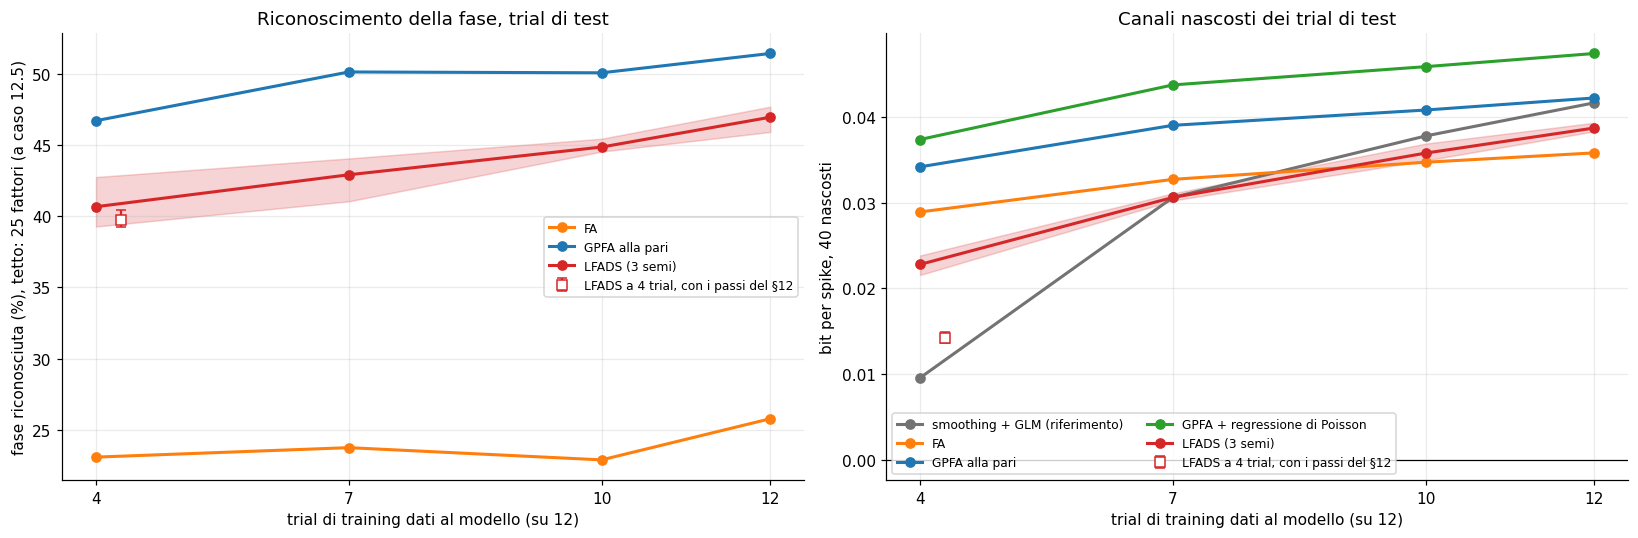

In [103]:
COL13 = {"smoothing + GLM (riferimento)": "0.45", "FA": "C1", "GPFA alla pari": "C0", "GPFA + regressione di Poisson": "C2", "LFADS (3 semi)": "C3"}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
curves = ((ax[0], ["FA", "GPFA alla pari", "LFADS (3 semi)"], lambda name, n: ACC13[(name, n, "tetto: tutti i 25 fattori")],
           "fase riconosciuta (%), tetto: 25 fattori (a caso 12.5)", "Riconoscimento della fase, trial di test"),
          (ax[1], list(COL13), lambda name, n: BPS13[(name, n)], "bit per spike, 40 nascosti", "Canali nascosti dei trial di test"))
for a_, names, get_, ylab, title in curves:
    for name in names:
        v = np.array([get_(name, n) for n in SIZES13])      # (4 quantità di trial, semi)
        a_.plot(SIZES13, v.mean(1), color=COL13[name], marker="o", lw=2, label=name)
        if v.shape[1] > 1:
            a_.fill_between(SIZES13, v.min(1), v.max(1), color=COL13[name], alpha=0.2)  # minimo-massimo tra i semi
    v4 = np.array(get_("LFADS, passi del §12", 4))           # il controllo a 4 trial, spostato un po' a destra per non coprire il punto
    a_.errorbar(4.3, v4.mean(), yerr=[[v4.mean() - v4.min()], [v4.max() - v4.mean()]], color="C3", marker="s", mfc="white",
                ls="none", capsize=3, label="LFADS a 4 trial, con i passi del §12")
    a_.set(xticks=SIZES13, xlabel="trial di training dati al modello (su 12)", ylabel=ylab, title=title)
ax[1].axhline(0, color="k", lw=0.8)
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_trials.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Il controllo torna**: a 12 trial gli stessi numeri del §12.4 (differenza 0).
- **Sui canali nascosti la distanza tra GPFA e LFADS si accorcia con regolarità**: 0.0114 bit per spike a 4
  trial, 0.0084 a 7, 0.0050 a 10, 0.0035 a 12, circa 0.001 per ogni trial in più (un po' meno negli ultimi).
  LFADS guadagna il doppio della GPFA (+0.0159 contro +0.0080 da 4 a 12 trial). Però resta sotto a ogni
  quantità: supera la GPFA alla pari in 0 casi su 15 (blocco × seme) a 4, 7 e 10 trial, in 1 su 15 a 12.
- **La classifica cambia con i dati, ed è istruttiva**:
  - lo **smoothing + GLM**, che ha 120 coefficienti liberi per ogni nascosto, è quello che soffre di più
    con pochi dati (0.0096 a 4 trial) e guadagna di più (+0.0321): è sotto LFADS a 4 trial, alla pari a 7
    (0.0306), sopra a 10 e 12;
  - **LFADS supera la FA solo da 10 trial in su** (0.0358 contro 0.0347): con meno dati il modello lineare
    senza dinamica va meglio;
  - la **GPFA con la regressione di Poisson** resta la migliore a ogni quantità di dati, e la GPFA alla pari
    la seconda tra i modelli a fattori.

  In parole semplici: più un modello è libero, più dati gli servono. LFADS sta in mezzo, tra i modelli a
  fattori lineari, che con pochi dati vanno già bene, e la regressione canale per canale.
- **Anche qui la regola delle 200 epoche non penalizza LFADS**: a 4 trial, con i passi del §12, scende da
  0.0228 a 0.0142. Più passi sugli stessi dati vuol dire più memorizzazione (§13.2), e questa sui trial
  nuovi si paga.
- **La figura**: a sinistra la fase, a destra i nascosti; la fascia rossa è il minimo-massimo tra i 3 semi
  di LFADS, il quadrato vuoto il controllo con i passi del §12.
- **Che cosa non dice**: se con più di 12 trial LFADS raggiungerebbe la GPFA. La tendenza sui nascosti
  dice che la distanza si accorcia, quella sulla fase è meno chiara; per saperlo servono più dati, cioè le
  altre sessioni (§14).

### Riepilogo del §13b

| domanda | risultato | dove |
|---|---|---|
| con meno trial LFADS perde più della GPFA? | **sì**: da 4 a 12 trial LFADS guadagna 6.3 punti sulla fase e 0.016 bit per spike sui nascosti, la GPFA 4.7 punti e 0.008 | §13.6, §13.7 |
| la distanza si chiude entro i 12 trial? | **no**: LFADS resta sotto la GPFA a ogni quantità di dati (fase: da 4.5 a 7.2 punti; nascosti: da 0.0114 a 0.0035) | §13.6, §13.7 |
| la regola delle 200 epoche penalizza LFADS con pochi trial? | **no**: con gli stessi passi del §12, a 4 trial va peggio (fase 39.8 contro 40.7; nascosti 0.0142 contro 0.0228) | §13.5-§13.7 |
| quanti dati servono alla GPFA? | pochi: con 4 trial (circa 65 s) riconosce la fase quanto LFADS con 12 (46.7 contro 47.0) | §13.6 |

**Il §13 nel complesso**: il risultato negativo del §12 non è un artefatto (seme, gemello, spostamento dei
nascosti); LFADS memorizza i trial di training più della GPFA; con più trial la distanza si accorcia, ma
entro i dati di questa sessione non si chiude.

**Che cosa non abbiamo verificato**: più di 12 trial di training (le altre due sessioni, §14); un solo
ordine dei trial per blocco; i parametri di LFADS, la penalità del GLM e il numero di fattori della GPFA non
sono stati scelti di nuovo per ogni quantità di dati.

## 14 · Sensibilità e alternative

Il §12 ha dato una risposta negativa e il §13 ha controllato che non sia un artefatto. Resta una domanda: la
risposta dipende dalle **scelte** fatte per LFADS? La configurazione viene da una piccola griglia sui trial
di validazione del blocco 0 (§11b); le grandezze della rete, la lunghezza dei pezzi e l'assenza del
controller sono state fissate a mano. Qui cambiamo **una cosa alla volta**, lasciando tutto il resto come al
§12, e rifacciamo le due misure.

- **§14a (questa parte)**: le grandezze (fattori, generatore) e la regolarizzazione che la griglia non ha
  esplorato (peso del KL sotto × 0.3, penalità L2 sul generatore);
- **§14b**: la lunghezza dei pezzi e il controller;
- **§14c**: LFADS senza dinamica (la "FA non lineare") e la regressione di Poisson sui fattori di LFADS;
- **§14d**: più dati, con le altre due sessioni dello stesso giorno.

**Lo schema di ogni variante** è quello del §12: 12 trial di training per blocco, 5 blocchi, 200 epoche,
le due forme (tutti i canali per la fase, 120 + 40 per i nascosti), con i **semi 0-2**. Il termine di
confronto è la configurazione del §12 con gli stessi semi (i modelli sono già su disco): ogni variante si
confronta con la principale **seme per seme**.

**Le misure**: la fase con il metro comune (tutti i fattori, cioè il tetto, e i primi 3 ordinati); i bit
per spike dei 40 nascosti sui trial di test (§12.4); quanto del voto sui nascosti resta passando dai trial
visti a quelli nuovi (§13.2), perché la memorizzazione è il sospetto principale.

**La regola, fissata prima di guardare**: il verdetto del §12 cambia se una variante porta LFADS **sopra la
GPFA alla pari con lo stesso numero di fattori**, con tutti e 3 i semi, su una delle due misure (tetto della
fase o nascosti). Per le varianti con 10 e 40 fattori stimiamo anche la GPFA alla pari con 10 e 40 fattori.

### 14.1 · Le grandezze e la regolarizzazione

| variante | che cosa cambia (al §12) | perché provarla |
|---|---|---|
| fattori 10 | 10 fattori (25) | meno dimensioni in cui descrivere l'attività: meno spazio per memorizzare |
| fattori 40 | 40 fattori (25) | più spazio, nel caso 25 fossero pochi per un modello non lineare |
| generatore 32 | 32 unità nel generatore (64) | una rete più piccola, con meno pesi da imparare da pochi dati |
| generatore 128 | 128 unità (64) | una rete più grande: dinamiche più ricche, se i dati le contengono |
| peso del KL × 0.1 | 0.1 / (30 × 160) (0.3 / (30 × 160)) | il valore scelto stava sul bordo della griglia (§11b) |
| L2 sul generatore × 10 | 10⁻¹ (10⁻²) | pesi ricorrenti più piccoli: una dinamica più semplice, quindi meno memorizzazione |

Il dropout non lo cambiamo: nella griglia del §11b il suo massimo cadeva all'interno (0.05 meglio di 0,
0.02 e 0.25). Encoder e condizione iniziale restano a 64.

180 allenamenti nuovi (6 varianti × 2 forme × 5 blocchi × 3 semi; i 30 della principale sono del §12) e 10
stime della GPFA (10 e 40 fattori): circa 1 ora e 35 minuti la prima volta. Una prova di 10 epoche (4
alla volta) ha dato per il generatore da 128 circa il 10% di tempo in più, e per le altre varianti lo stesso
tempo della principale.

In [104]:
SEEDS14 = range(3)                                          # i semi 0-2, gli stessi del §13b
VARIANTS14A = {"principale (§12)": {},                       # che cosa cambia rispetto alla configurazione del §12
               "fattori 10": dict(fac_dim=10),
               "fattori 40": dict(fac_dim=40),
               "generatore 32": dict(gen_dim=32),
               "generatore 128": dict(gen_dim=128),
               "peso del KL × 0.1": dict(kl_ic_scale=LF_HP["kl_ic_scale"] / 3),  # da 0.3 a 0.1 volte l'ELBO vero
               "L2 sul generatore × 10": dict(l2_gen_scale=LF_HP["l2_gen_scale"] * 10)}
FORMS14 = {"tutti i canali": (LF_HP, {}),                   # (configurazione di partenza, dati) delle due forme del §12
           "120 + 40": (LF_HID_HP, dict(segs=SEGS_HID, rate_cols=HID_COLS))}

def job14(var, form, k, sd):                                # un allenamento: variante, forma, blocco, seme; il resto come al §12
    hp_, data_ = FORMS14[form]
    return lf12_job(sd, train_trials(k), hp=dict(hp_, **VARIANTS14A[var]), **data_)

RUNS14A = [(v, f_, k, sd) for v in VARIANTS14A for f_ in FORMS14 for k in range(5) for sd in SEEDS14]
res14a = dict(zip(RUNS14A, run_lfads_cached([job14(*r) for r in RUNS14A])))

GP14 = {d_: dict(zip(range(5), gpfa_cached([np.concatenate([SEGS[t] for t in train_trials(k)]) for k in range(5)], x_dim=d_)))
        for d_ in (10, 40)}                                 # la GPFA alla pari con 10 e 40 fattori
GP14[K_PCA] = {k: GP12[k] for k in range(5)}                # con 25: quella del §12

def shapes(w):                                              # le grandezze di un modello lette dai suoi pesi: fattori, generatore
    return w["readout.0.weight"].shape[1], w["decoder.rnn.cell.gen_cell.weight_hh"].shape[1]

display(pd.DataFrame({v: {"fattori, generatore (dai pesi)": ", ".join(sorted({"{}, {}".format(*shapes(res14a[(v, f_, k, sd)]["weights"]))
                                                                             for f_ in FORMS14 for k in range(5) for sd in SEEDS14})),
                          "versione tenuta (epoca)": mm([res14a[(v, f_, k, sd)]["best_epoch"] for f_ in FORMS14 for k in range(5) for sd in SEEDS14])}
                      for v in VARIANTS14A}).T)

Allenamenti LFADS: 180 eseguiti ora, 30 riletti dal disco


GPFA: 5 stimate ora, 0 rilette dal disco


GPFA: 5 stimate ora, 0 rilette dal disco


,"fattori, generatore (dai pesi)",versione tenuta (epoca)
principale (§12),"25, 64",194-200
fattori 10,"10, 64",196-200
fattori 40,"40, 64",194-200
generatore 32,"25, 32",194-200
generatore 128,"25, 128",195-200
peso del KL × 0.1,"25, 64",194-200
L2 sul generatore × 10,"25, 64",193-200


**Lettura.**

- **Le varianti sono quelle volute**: i pesi salvati hanno 10 e 40 fattori, un generatore da 32 e da 128 unità;
  il peso del KL e la penalità L2 non si vedono nei pesi, ma fanno parte della configurazione e quindi
  dell'impronta di ogni modello (§10.5).
- **La versione tenuta è in pratica l'ultima** in tutti i 210 modelli (tra l'epoca 193 e la 200), come al §12.
- I 30 modelli della principale e le GPFA a 25 fattori sono stati riletti dal disco. La durata di questa
  esecuzione non è indicativa: il computer eseguiva nello stesso tempo altri notebook ed è rimasto in stop per
  quasi due ore (l'esecuzione è poi ripresa da sola). Senza altri calcoli vale la stima scritta sopra.

### 14.2 · Le due misure, variante per variante

In [105]:
F_LF14 = {run: order_by_readout(stitch_all(r["factors"]), r["weights"]["readout.0.weight"])  # fattori ordinati, tutta la sessione
          for run, r in res14a.items() if run[1] == "tutti i canali"}
F_GP14 = {d_: {k: stitch_all([gpfa_infer_segments(SEGS[t], GP14[d_][k]) for t in TRIALS]) for k in range(5)} for d_ in (10, 40)}
F_GP14[K_PCA] = {k: F_GP12[k] for k in range(5)}

def acc14(get):                                             # fase riconosciuta: (tetto, primi 3) per una funzione blocco -> fattori
    return decode_map(fold_inp(get), emb_none), decode_map(fold_inp(lambda k: get(k)[:, :3]), emb_none)

def full_lf14(var):                                         # [blocco][seme] -> conte attese dei 40 nascosti in tutta la sessione (forma 120 + 40)
    return [[stitch_all(res14a[(var, "120 + 40", k, sd)]["rates"]) for sd in SEEDS14] for k in range(5)]

def full_gp14(d_):                                          # lo stesso per la GPFA alla pari con d_ fattori (un solo modello per blocco)
    if d_ == K_PCA:
        return FULL13["GPFA alla pari"]                     # con 25 fattori: già calcolata al §13.2
    return [[np.concatenate([stitch(gpfa_hidden(SEGS[t], GP14[d_][k])[0], t) for t in TRIALS])] for k in range(5)]

def fmt2(v):                                                # "media [minimo, massimo]" con 2 decimali
    v = np.atleast_1d(v)
    return f"{v.mean():.2f}" if len(v) == 1 else f"{v.mean():.2f} [{v.min():.2f}, {v.max():.2f}]"

M14 = {}                                                    # nome -> dict di misure, ognuna una lista (un valore per seme)
for v in VARIANTS14A:
    ph = [acc14(lambda k, sd=sd: F_LF14[(v, "tutti i canali", k, sd)]) for sd in SEEDS14]
    full = full_lf14(v)
    sn = seen_new(full, Y_HID)                              # (semi, 5 blocchi, 2): bit per spike su trial visti e nuovi (§13.2)
    M14[v] = {"tetto": [a for a, _ in ph], "primi 3": [b for _, b in ph],
              "nascosti": [bits_per_spike(test_only([full[k][i] for k in range(5)]), Y_HID) for i in range(len(SEEDS14))],
              "nuovi / visti": list(sn[:, :, 1].mean(1) / sn[:, :, 0].mean(1))}
for d_ in (10, K_PCA, 40):
    a_, b_ = acc14(lambda k, d_=d_: F_GP14[d_][k])
    full = full_gp14(d_)
    sn = seen_new(full, Y_HID)
    M14[f"GPFA alla pari, {d_} fattori"] = {"tetto": [a_], "primi 3": [b_],
                                            "nascosti": [bits_per_spike(test_only([full[k][0] for k in range(5)]), Y_HID)],
                                            "nuovi / visti": [sn[0, :, 1].mean() / sn[0, :, 0].mean()]}

GP_SAME = {v: f"GPFA alla pari, {VARIANTS14A[v].get('fac_dim', K_PCA)} fattori" for v in VARIANTS14A}  # la GPFA con gli stessi fattori
chk14 = max(abs(np.mean(M14["principale (§12)"]["tetto"]) - np.mean(ACC13[("LFADS (3 semi)", 12, "tetto: tutti i 25 fattori")])),
            abs(np.mean(M14["principale (§12)"]["nascosti"]) - np.mean(BPS13[("LFADS (3 semi)", 12)])),
            abs(M14[f"GPFA alla pari, {K_PCA} fattori"]["nascosti"][0] - BPS12[("GPFA alla pari", "tutta la sessione")][0]))
print(f"Controllo: la principale e la GPFA a 25 fattori danno gli stessi numeri del §13b e del §12.4 (differenza massima {chk14:.1e})")

display(pd.DataFrame({name: {"fase, tetto (%)": fmt(m["tetto"]), "fase, primi 3 (%)": fmt(m["primi 3"]),
                             "nascosti, trial di test (bit per spike)": fmt4(m["nascosti"]), "nuovi / visti": fmt2(m["nuovi / visti"])}
                      for name, m in M14.items()}).T.rename_axis("media (minimo-massimo) tra i 3 semi; a caso 12.5%"))

P14 = M14["principale (§12)"]
display(pd.DataFrame({v: {"tetto: differenza dalla principale (punti)": fmt1s(np.subtract(M14[v]["tetto"], P14["tetto"])),
                          "nascosti: differenza dalla principale": fmt4(np.subtract(M14[v]["nascosti"], P14["nascosti"])),
                          "GPFA con gli stessi fattori": GP_SAME[v].replace("GPFA alla pari, ", ""),
                          "semi sopra la GPFA: tetto": f"{int(np.sum(np.array(M14[v]['tetto']) > M14[GP_SAME[v]]['tetto'][0]))} su 3",
                          "semi sopra la GPFA: nascosti": f"{int(np.sum(np.array(M14[v]['nascosti']) > M14[GP_SAME[v]]['nascosti'][0]))} su 3"}
                      for v in VARIANTS14A}).T.rename_axis("seme per seme; [minimo, massimo] tra i 3 semi"))

Controllo: la principale e la GPFA a 25 fattori danno gli stessi numeri del §13b e del §12.4 (differenza massima 0.0e+00)


,"fase, tetto (%)","fase, primi 3 (%)","nascosti, trial di test (bit per spike)",nuovi / visti
media (minimo-massimo) tra i 3 semi; a caso 12.5%,,,,
principale (§12),47.0 (45.9-47.7),21.3 (19.2-22.4),"0.0387 [0.0383, 0.0393]","0.40 [0.39, 0.41]"
fattori 10,41.2 (39.2-43.8),20.7 (19.1-22.7),"0.0321 [0.0315, 0.0330]","0.47 [0.47, 0.48]"
fattori 40,47.1 (46.6-47.9),20.5 (19.5-21.9),"0.0380 [0.0376, 0.0384]","0.35 [0.34, 0.35]"
generatore 32,45.9 (44.4-47.6),20.5 (19.1-22.5),"0.0382 [0.0374, 0.0393]","0.48 [0.47, 0.49]"
generatore 128,45.2 (44.1-45.8),19.2 (16.9-20.6),"0.0316 [0.0300, 0.0326]","0.25 [0.24, 0.26]"
peso del KL × 0.1,45.3 (43.6-47.1),20.4 (20.1-21.0),"0.0354 [0.0349, 0.0361]","0.33 [0.32, 0.34]"
L2 sul generatore × 10,47.4 (46.3-48.5),21.0 (19.9-21.9),"0.0393 [0.0385, 0.0398]","0.42 [0.41, 0.43]"
"GPFA alla pari, 10 fattori",44.7,34.1,0.0329,0.72
"GPFA alla pari, 25 fattori",51.4,30.9,0.0422,0.66


,tetto: differenza dalla principale (punti),nascosti: differenza dalla principale,GPFA con gli stessi fattori,semi sopra la GPFA: tetto,semi sopra la GPFA: nascosti
"seme per seme; [minimo, massimo] tra i 3 semi",,,,,
principale (§12),"0.0 [0.0, 0.0]","0.0000 [0.0000, 0.0000]",25 fattori,0 su 3,0 su 3
fattori 10,"-5.7 [-6.8, -3.9]","-0.0066 [-0.0070, -0.0063]",10 fattori,0 su 3,1 su 3
fattori 40,"0.1 [-0.6, 0.7]","-0.0007 [-0.0009, -0.0003]",40 fattori,0 su 3,0 su 3
generatore 32,"-1.1 [-2.1, 0.4]","-0.0005 [-0.0011, -0.0000]",25 fattori,0 su 3,0 su 3
generatore 128,"-1.7 [-3.6, -0.1]","-0.0071 [-0.0085, -0.0062]",25 fattori,0 su 3,0 su 3
peso del KL × 0.1,"-1.6 [-2.3, -0.5]","-0.0033 [-0.0036, -0.0030]",25 fattori,0 su 3,0 su 3
L2 sul generatore × 10,"0.5 [0.2, 0.8]","0.0006 [-0.0000, 0.0013]",25 fattori,0 su 3,0 su 3


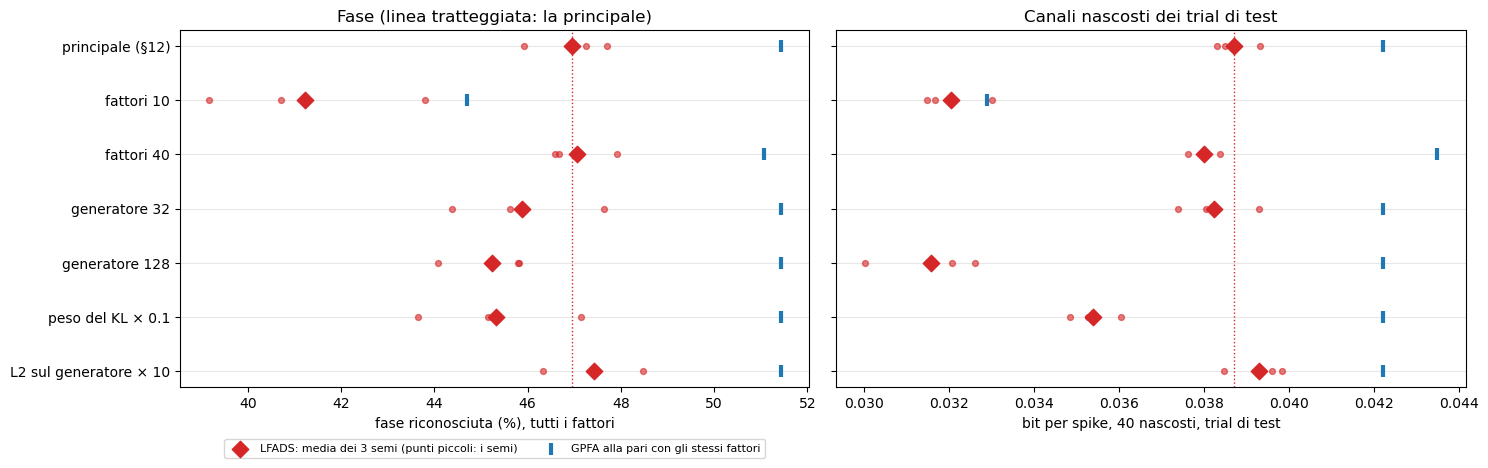

In [106]:
ROWS14 = list(VARIANTS14A)[::-1]                            # dall'alto in basso come nella tabella
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for a_, meas, xlab in ((ax[0], "tetto", "fase riconosciuta (%), tutti i fattori"), (ax[1], "nascosti", "bit per spike, 40 nascosti, trial di test")):
    for y, v in enumerate(ROWS14):
        vals = np.array(M14[v][meas])
        a_.scatter(vals, np.full(len(vals), y), color="C3", s=18, alpha=0.6, zorder=3)  # i 3 semi
        a_.scatter(vals.mean(), y, color="C3", s=70, marker="D", zorder=4, label="LFADS: media dei 3 semi (punti piccoli: i semi)" if y == 0 else None)
        g_ = M14[GP_SAME[v]][meas][0]
        a_.scatter(g_, y, color="C0", s=70, marker="|", linewidths=3, zorder=4, label="GPFA alla pari con gli stessi fattori" if y == 0 else None)
    a_.axvline(np.mean(P14[meas]), color="C3", ls=":", lw=1)  # la principale, per confronto
    a_.set(xlabel=xlab, yticks=range(len(ROWS14)), yticklabels=ROWS14)
    a_.grid(axis="y", alpha=0.3)
ax[0].legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))  # sotto il grafico, per non coprire i punti
ax[0].set_title("Fase (linea tratteggiata: la principale)"); ax[1].set_title("Canali nascosti dei trial di test")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_variants_a.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Il controllo torna**: la principale e la GPFA a 25 fattori danno esattamente i numeri del §13b e del §12.4.
- **Nessuna variante cambia il verdetto**, secondo la regola fissata prima di guardare: nessuna porta LFADS
  sopra la GPFA alla pari con gli stessi fattori con tutti e 3 i semi, né sulla fase né sui nascosti. Il caso
  più vicino è quello con 10 fattori sui nascosti: un seme su tre supera la GPFA a 10 fattori di circa 0.0001
  bit per spike, ma la media resta sotto (0.0321 contro 0.0329).
- **Tre varianti peggiorano LFADS in tutti e 3 i semi**, seme per seme rispetto alla principale:
  - **10 fattori**: −5.7 punti sulla fase e −0.0066 bit per spike sui nascosti. Sono troppo poche
    dimensioni; ma anche la GPFA ne soffre (44.7% e 0.0329 con 10 fattori), e così le due si avvicinano;
  - **generatore da 128**: −1.7 punti e −0.0071. È la variante che memorizza di più: sui trial nuovi resta
    solo il 25% del voto dei trial visti (40% la principale);
  - **peso del KL × 0.1**: −1.6 punti e −0.0033, e memorizza di più (33%). Il valore scelto al §11b stava sul
    bordo della griglia: andando oltre, verso meno regolarizzazione, si sta peggio, non meglio.
- **Due varianti cambiano poco**: 40 fattori (+0.1 punti, −0.0007, memorizza di più: 35%) e generatore da 32
  (−1.1 punti, −0.0005: memorizza di meno, 48%, ma sui trial nuovi non guadagna).
- **L'unica che va un po' meglio è la L2 sul generatore × 10**: +0.5 punti sulla fase in tutti e 3 i semi
  (da +0.2 a +0.8) e +0.0006 sui nascosti (da circa 0 a +0.0013), con un po' meno memorizzazione (42%). Il
  guadagno però è piccolo rispetto alla distanza dalla GPFA, che resta di 4.0 punti e 0.0029 bit per spike.
  È il valore più alto che abbiamo provato: valori ancora più alti non li conosciamo.
- **Memorizzare di più non aiuta mai**: le varianti con più capacità o meno regolarizzazione (generatore da
  128, KL × 0.1, 40 fattori) trattengono sui trial nuovi il 25-35% del voto dei trial visti, e vanno peggio o
  uguale sui nascosti; quelle con meno capacità (generatore da 32, 10 fattori) memorizzano meno (47-48%) ma
  non vanno meglio. La GPFA trattiene il 62-72%.
- **Il confronto è giusto anche per la GPFA**: con 40 fattori fa 51.1% e 0.0435 (sui nascosti un po' meglio
  che con 25), con 10 fattori peggio (44.7% e 0.0329). I 25 fattori del §12 non la favoriscono, e LFADS con
  40 fattori va come con 25.
- **I primi 3 fattori ordinati di LFADS restano tra il 19 e il 21%** in tutte le varianti, contro il 31-34%
  della GPFA: nessuna variante risolve questo punto (§12.2, §13.1).
- **La figura**: per ogni variante i 3 semi di LFADS (punti piccoli) e la loro media (rombo), e la GPFA alla
  pari con gli stessi fattori (trattino blu); la linea tratteggiata è la principale.
- **Che cosa non dice**: abbiamo cambiato una manopola alla volta, quindi le combinazioni (per esempio meno
  fattori e più L2 insieme) non sono provate; valori della L2 sopra × 10 nemmeno; la configurazione di
  partenza viene dal blocco 0 (§11b); 3 semi per variante.

### Riepilogo del §14a

| variante | fase, tetto: differenza dalla principale (punti) | nascosti: differenza (bit per spike) | sui trial nuovi resta (nuovi / visti) | sopra la GPFA con gli stessi fattori? |
|---|---|---|---|---|
| principale (§12) | 47.0% | 0.0387 | 0.40 | no |
| fattori 10 | −5.7 | −0.0066 | 0.47 | no (sui nascosti 1 seme su 3, di circa 0.0001) |
| fattori 40 | +0.1 | −0.0007 | 0.35 | no |
| generatore 32 | −1.1 | −0.0005 | 0.48 | no |
| generatore 128 | −1.7 | −0.0071 | 0.25 | no |
| peso del KL × 0.1 | −1.6 | −0.0033 | 0.33 | no |
| L2 sul generatore × 10 | +0.5 | +0.0006 | 0.42 | no |

**In sintesi**: il verdetto del §12 non dipende dalle grandezze della rete né dalla regolarizzazione che la
griglia non aveva esplorato. Più capacità fa memorizzare di più e non aiuta; l'unico piccolo guadagno viene da
una penalità L2 più forte, troppo piccolo per avvicinare la GPFA.

### 14.3 · La lunghezza dei pezzi e il controller

**I pezzi.** Al §9.2 abbiamo scelto pezzi da 600 ms, e tra le alternative c'erano pezzi più lunghi. Qui
ne proviamo due:

- **400 ms**: il generatore deve srotolare da solo meno tempo, ma ogni pezzo vede meno contesto;
- **1 s**: la durata delle finestre del metro comune (§4.2). Più contesto, ma il generatore deve srotolare
  da solo un secondo intero, spesso a cavallo di due fasi.

La sovrapposizione resta di 200 ms, con la stessa ricucitura (§9.2): con pezzi da 400 ms quasi ogni bin sta
in due pezzi, con pezzi da 1 s quasi sempre in uno solo. Il resto di LFADS resta come al §12, con due
adattamenti:

- il peso del KL resta 0.3 volte quello dell'ELBO vero, quindi diventa 0.3 / (bin del pezzo × 160): l'errore
  di ricostruzione è una media su bin e canali, il KL una somma per pezzo (§10.4);
- 200 epoche, cioè lo stesso numero di passaggi sui dati: con pezzi da 400 ms un'epoca ha il doppio dei passi
  (3200 in tutto), con pezzi da 1 s la metà (800).

La GPFA alla pari si stima **sugli stessi pezzi**, così il confronto resta alla pari.

**Il controller.** Senza controller, tutto quello che succede in un pezzo deve essere già scritto nello stato
iniziale: poi il generatore va da solo. Il controller aggiunge degli **ingressi inferiti**: a ogni bin una
piccola rete, il controller, legge quello che un secondo encoder ha visto dei dati intorno a quel bin e passa
al generatore 4 numeri, una "spinta" che può seguire eventi che lo stato iniziale non poteva prevedere (per
esempio un cue). È la versione completa di LFADS (Pandarinath et al., 2018). Le impostazioni sono quelle della
configurazione di lfads-torch per MC_RTT, la registrazione continua del Neural Latents Benchmark, portate alle
nostre grandezze:

| parte | qui | MC_RTT (lfads-torch) |
|---|---|---|
| encoder degli ingressi | 64 unità, GRU nei due sensi | 80 |
| controller | 64 unità | 80 |
| ingressi inferiti | 4 | 4 |
| ritardo degli ingressi | 1 bin | 1 |
| distribuzione a priori degli ingressi | autoregressiva: costante di tempo 10 bin (200 ms), varianza 0.1 | uguale |
| peso del KL degli ingressi | come quello della condizione iniziale, 0.3 / (30 × 160) | scelto da AutoLFADS |
| penalità L2 su encoder degli ingressi e controller | 0 | scelte da AutoLFADS, partendo da 0 |

La penalità L2 sul controller resta a 0 perché la libreria divide la penalità totale per il numero di pesi
penalizzati: aggiungendo il controller si dimezzerebbe di fatto quella sul generatore, e la variante
cambierebbe due cose insieme. Pezzi da 600 ms, il resto come al §12.

Il rischio è noto: più libertà vuol dire più spazio per memorizzare (§13.2, §14a). Per questo, oltre alle due
misure, guardiamo se il modello **usa** davvero gli ingressi: se il termine KL li spinge a zero, il controller
c'è ma è spento.

**La regola** è quella del §14a: il verdetto del §12 cambia se una variante porta LFADS sopra la GPFA alla pari
(sugli stessi pezzi) con tutti e 3 i semi, su una delle due misure.

**I controlli a mano**:

- le funzioni nuove di taglio e ricucitura, con pezzi da 600 ms, devono dare esattamente i pezzi e la
  ricucitura del §9.2; con 400 ms e 1 s, ricucire i pezzi dei conteggi deve restituire i conteggi;
- la probabilità a priori degli ingressi, calcolata a mano, deve coincidere con quella della libreria.

90 allenamenti nuovi (3 varianti × 2 forme × 5 blocchi × 3 semi) e 10 stime della GPFA: circa 1 ora la prima
volta. Una prova di 10 epoche (4 alla volta) ha dato, per allenamento, 132 s con pezzi da 400 ms, 84 s con
pezzi da 1 s e 158 s con il controller, contro 95 s della principale.

In [107]:
OVL14 = SEG_OVL                                             # la sovrapposizione resta di 10 bin (200 ms)
LENS14 = {"pezzi da 400 ms": 20, "pezzi da 1 s": 50}        # bin per pezzo delle due varianti

def starts_L(t, L):                                         # come segment_starts (§9.2), per pezzi di L bin che si sovrappongono di 10
    a0, a1 = TRIAL_SPAN[t]
    st = list(range(a0, a1 - L + 1, L - OVL14))             # un pezzo ogni L − 10 bin...
    if st[-1] != a1 - L:
        st.append(a1 - L)                                   # ...più un ultimo pezzo che finisce esattamente con il trial
    return np.array(st)

def cut_L(X, t, L):                                         # come cut_segments: i pezzi da L bin del trial t di un segnale X
    return np.stack([X[a:a + L] for a in starts_L(t, L)])

def stitch_L(Y_seg, t, L):                                  # come stitch: media pesata, con le rampe di AutoLFADS sui 10 bin in comune
    a0, a1 = TRIAL_SPAN[t]
    W = np.ones((len(Y_seg), L))                            # 1 dove il pezzo è da solo
    W[1:, :OVL14] = RAMP_IN                                 # rampa in salita all'inizio (tranne il primo pezzo del trial)
    W[:-1, -OVL14:] = RAMP_OUT                              # rampa in discesa alla fine (tranne l'ultimo)
    num, den = np.zeros((a1 - a0, Y_seg.shape[2])), np.zeros((a1 - a0, 1))
    for a, y, w in zip(starts_L(t, L) - a0, Y_seg, W):
        num[a:a + L] += w[:, None] * y                      # somma dei valori pesati...
        den[a:a + L] += w[:, None]                          # ...e dei pesi
    return num / den

def stitch_all_L(per_trial, L):                             # come stitch_all: i 15 trial ricuciti e messi in fila
    return np.concatenate([stitch_L(y_, t, L) for t, y_ in zip(TRIALS, per_trial)])

rng_chk = np.random.default_rng(0)
Y_chk = {t: rng_chk.normal(size=SEGS[t].shape[:2] + (3,)) for t in TRIALS}  # valori a caso, diversi in ogni pezzo
print("Pezzi da 600 ms: gli stessi del §9.2:", all(np.array_equal(cut_L(COUNTS, t, SEG_LEN), SEGS[t]) for t in TRIALS),
      f"| ricucitura di valori a caso, differenza massima da stitch: "
      f"{max(np.abs(stitch_L(Y_chk[t], t, SEG_LEN) - stitch(Y_chk[t], t)).max() for t in TRIALS):.1e}")
SEGS14 = {L: {t: cut_L(COUNTS, t, L) for t in TRIALS} for L in LENS14.values()}  # i pezzi dei conteggi, per ognuna delle due lunghezze
SEGS14_HID = {L: {t: s_[..., ORDER_HID] for t, s_ in seg.items()} for L, seg in SEGS14.items()}  # prima i 120 visibili, poi i 40 nascosti
for name, L in LENS14.items():
    back = np.concatenate([stitch_L(SEGS14[L][t].astype(float), t, L) for t in TRIALS])
    print(f"{name}: {sum(len(v) for v in SEGS14[L].values())} pezzi, da {min(len(v) for v in SEGS14[L].values())} a "
          f"{max(len(v) for v in SEGS14[L].values())} per trial ({sum(len(SEGS14[L][t]) for t in train_trials(0))} nei 12 trial di training "
          f"del blocco 0); ricucitura dei conteggi, differenza massima {np.abs(back - COUNTS).max():.1e}")

Pezzi da 600 ms: gli stessi del §9.2: True | ricucitura di valori a caso, differenza massima da stitch: 0.0e+00
pezzi da 400 ms: 1215 pezzi, da 66 a 96 per trial (971 nei 12 trial di training del blocco 0); ricucitura dei conteggi, differenza massima 8.9e-16
pezzi da 1 s: 310 pezzi, da 17 a 24 per trial (248 nei 12 trial di training del blocco 0); ricucitura dei conteggi, differenza massima 8.9e-16


In [108]:
CO14 = dict(ci_enc_dim=64, con_dim=64, co_dim=4, co_tau=10.0, co_nvar=0.1,  # encoder degli ingressi, controller, ingressi; priori autoregressiva
            kl_co_scale=LF_HP["kl_ic_scale"], l2_ci_enc_scale=0.0, l2_con_scale=0.0)  # KL degli ingressi come quello della condizione iniziale; niente L2

def make_lfads_co(hp):
    """Come make_lfads (§10.3), ma con il controller: un secondo encoder, il controller e 4 ingressi inferiti. Si chiama nel processo separato."""
    import numpy as np                                      # numpy PRIMA di torch (§10.3)
    import torch
    from torch import nn
    from lfads_torch.model import LFADS                     # il modello della libreria
    from lfads_torch.modules import augmentations           # il coordinated dropout (qui a 0, come al §12)
    from lfads_torch.modules.priors import AutoregressiveMultivariateNormal, MultivariateNormal  # priori degli ingressi e della condizione iniziale
    from lfads_torch.modules.recons import Poisson          # il modello del rumore: Poisson
    from lfads_torch.modules.readin_readout import FanInLinear  # l'uscita lineare dai fattori alle log-frequenze
    cd = augmentations.CoordinatedDropout(cd_rate=hp["cd_rate"], cd_pass_rate=0.0, ic_enc_seq_len=0)
    return LFADS(encod_data_dim=hp["n_in"], encod_seq_len=hp["seg_len"], recon_seq_len=hp["seg_len"],  # forma dei dati
                 ext_input_dim=0, ic_enc_seq_len=0,         # nessun ingresso esterno; l'encoder legge tutto il pezzo
                 ic_enc_dim=hp["enc_dim"], ci_enc_dim=hp["ci_enc_dim"], ci_lag=1, con_dim=hp["con_dim"], co_dim=hp["co_dim"],  # il controller è acceso
                 ic_dim=hp["ic_dim"], gen_dim=hp["gen_dim"], fac_dim=hp["fac_dim"], dropout_rate=hp["dropout"],
                 reconstruction=nn.ModuleList([Poisson()]), variational=True,
                 co_prior=AutoregressiveMultivariateNormal(tau=hp["co_tau"], nvar=hp["co_nvar"], shape=hp["co_dim"]),  # priori degli ingressi
                 ic_prior=MultivariateNormal(mean=0.0, variance=hp["ic_prior_var"], shape=hp["ic_dim"]),
                 ic_post_var_min=hp["ic_post_var_min"], cell_clip=hp["cell_clip"],
                 train_aug_stack=augmentations.AugmentationStack([cd], batch_order=[0], loss_order=[0]),
                 infer_aug_stack=augmentations.AugmentationStack(),
                 readin=nn.ModuleList([nn.Identity()]), readout=nn.ModuleList([FanInLinear(hp["fac_dim"], hp["n_out"])]),
                 loss_scale=hp["loss_scale"], recon_reduce_mean=True,
                 lr_scheduler=False, lr_init=hp["lr"], lr_stop=1e-5, lr_decay=0.95, lr_patience=6,
                 lr_adam_beta1=0.9, lr_adam_beta2=0.999, lr_adam_epsilon=1e-8, weight_decay=0.0,
                 l2_start_epoch=0, l2_increase_epoch=hp["ramp_epochs"], l2_ic_enc_scale=hp["l2_ic_enc_scale"],
                 l2_ci_enc_scale=hp["l2_ci_enc_scale"], l2_gen_scale=hp["l2_gen_scale"], l2_con_scale=hp["l2_con_scale"],
                 kl_start_epoch=0, kl_increase_epoch=hp["ramp_epochs"], kl_ic_scale=hp["kl_ic_scale"], kl_co_scale=hp["kl_co_scale"])

def run_lfads_cached_co(jobs):                              # run_lfads_cached (§10.5) con il modello del controller
    global make_lfads                                       # durante la chiamata il nome make_lfads indica make_lfads_co: così lfads_fit,
    orig = make_lfads                                       # nel processo separato, costruisce il modello con il controller, e l'impronta
    make_lfads = make_lfads_co                              # di ogni modello (lf_key) contiene il codice di make_lfads_co
    try:
        return run_lfads_cached(jobs)
    finally:
        make_lfads = orig                                   # in ogni caso si rimette la funzione originale

def co_prior_check(tau, nvar, seed):                        # log-probabilità di alcune sequenze sotto la priori autoregressiva della libreria (processo separato)
    import numpy as np                                      # numpy PRIMA di torch
    import torch
    from lfads_torch.modules.priors import AutoregressiveMultivariateNormal
    torch.manual_seed(seed)
    prior = AutoregressiveMultivariateNormal(tau=tau, nvar=nvar, shape=4)  # 4 ingressi, come in CO14
    x = torch.randn(3, 30, 4)                               # 3 pezzi da 30 bin, 4 ingressi: valori a caso
    with torch.no_grad():
        return x.numpy().astype(np.float64), prior.log_prob(x).numpy().astype(np.float64)

x_co, lp_lib = POOL_LF.submit(co_prior_check, CO14["co_tau"], CO14["co_nvar"], 0).result()
alpha = np.exp(-1 / CO14["co_tau"])                         # quanto di ogni ingresso resta al bin successivo: e^(−1/τ)
var0 = CO14["co_nvar"] / (1 - alpha ** 2)                   # varianza al primo bin: quella stazionaria del processo
mu_co = np.concatenate([np.zeros_like(x_co[:, :1]), alpha * x_co[:, :-1]], axis=1)  # media di ogni bin: α × il bin precedente (0 al primo)
var_co = np.concatenate([np.full_like(x_co[:, :1], var0), np.full_like(x_co[:, 1:], CO14["co_nvar"])], axis=1)  # varianza di ogni bin
lp_hand = (-0.5 * np.log(2 * np.pi * var_co) - (x_co - mu_co) ** 2 / (2 * var_co)).sum(axis=(1, 2))  # somma su bin e ingressi, pezzo per pezzo
print(f"Priori autoregressiva degli ingressi: log-probabilità a mano {np.round(lp_hand, 3)}, libreria {np.round(lp_lib, 3)}; "
      f"differenza massima {np.abs(lp_hand - lp_lib).max():.1e}. Deviazione stazionaria della priori: {np.sqrt(var0):.2f}")

Priori autoregressiva degli ingressi: log-probabilità a mano [-1151.466  -775.377 -1200.04 ], libreria [-1151.466  -775.377 -1200.04 ]; differenza massima 7.5e-05. Deviazione stazionaria della priori: 0.74


In [109]:
def job14b(var, form, k, sd):                               # un allenamento del §14b: variante, forma, blocco, seme; il resto come al §12
    hp_, data_ = FORMS14[form]                              # configurazione e dati delle due forme (§14a)
    if var == "controller":
        return lf12_job(sd, train_trials(k), hp=dict(hp_, **CO14), **data_)  # pezzi da 600 ms, con il controller
    L = LENS14[var]
    hp_L = dict(hp_, seg_len=L, kl_ic_scale=hp_["kl_ic_scale"] * SEG_LEN / L)  # peso del KL: 0.3 / (L × 160)
    if form == "tutti i canali":
        return lf12_job(sd, train_trials(k), hp=hp_L, segs=SEGS14[L])
    return lf12_job(sd, train_trials(k), hp=hp_L, segs=SEGS14_HID[L], rate_cols=HID_COLS)

RUNS14B = [(v, f_, k, sd) for v in LENS14 for f_ in FORMS14 for k in range(5) for sd in SEEDS14]           # pezzi da 400 ms e da 1 s: 60
RUNS14B_CO = [("controller", f_, k, sd) for f_ in FORMS14 for k in range(5) for sd in SEEDS14]           # controller: 30
res14b = dict(zip(RUNS14B, run_lfads_cached([job14b(*r) for r in RUNS14B])))
res14b |= dict(zip(RUNS14B_CO, run_lfads_cached_co([job14b(*r) for r in RUNS14B_CO])))
GP14B = {L: dict(zip(range(5), gpfa_cached([np.concatenate([SEGS14[L][t] for t in train_trials(k)]) for k in range(5)])))
         for L in LENS14.values()}                          # la GPFA alla pari sugli stessi pezzi da 400 ms e da 1 s

def co_dim_of(w):                                           # quanti ingressi inferiti ha un modello, letto dai pesi (0 = niente controller)
    return next((v.shape[0] // 2 for k_, v in w.items() if k_.endswith("co_linear.weight")), 0)

display(pd.DataFrame({v: {"bin per pezzo (dalle uscite)": mm([res14b[(v, f_, k, sd)]["factors"][0].shape[1] for f_ in FORMS14 for k in range(5) for sd in SEEDS14]),
                          "ingressi inferiti (dai pesi)": mm([co_dim_of(res14b[(v, f_, k, sd)]["weights"]) for f_ in FORMS14 for k in range(5) for sd in SEEDS14]),
                          "passi": mm([res14b[(v, f_, k, sd)]["steps"] for f_ in FORMS14 for k in range(5) for sd in SEEDS14]),
                          "versione tenuta (epoca)": mm([res14b[(v, f_, k, sd)]["best_epoch"] for f_ in FORMS14 for k in range(5) for sd in SEEDS14])}
                      for v in list(LENS14) + ["controller"]}).T)

Allenamenti LFADS: 0 eseguiti ora, 60 riletti dal disco


Allenamenti LFADS: 0 eseguiti ora, 30 riletti dal disco
GPFA: 0 stimate ora, 5 rilette dal disco
GPFA: 0 stimate ora, 5 rilette dal disco


,bin per pezzo (dalle uscite),ingressi inferiti (dai pesi),passi,versione tenuta (epoca)
pezzi da 400 ms,20,0,3200,192-200
pezzi da 1 s,50,0,800,197-200
controller,30,4,1600,194-200


**Lettura.**

- **I controlli a mano tornano.** Con pezzi da 600 ms le funzioni nuove danno esattamente i pezzi e la ricucitura del
  §9.2 (differenza 0); con 400 ms e 1 s, ricucire i pezzi dei conteggi restituisce i conteggi (differenza 9·10⁻¹⁶,
  l'arrotondamento). La probabilità a priori degli ingressi calcolata a mano coincide con quella della libreria
  (differenza 7.5·10⁻⁵, la precisione dei numeri a 32 bit).
- **I pezzi**: 1215 da 400 ms (da 66 a 96 per trial) e 310 da 1 s (da 17 a 24), contro i 610 da 600 ms.
- **Le varianti sono quelle volute**: le uscite hanno 20, 50 e 30 bin per pezzo, e solo i modelli del controller hanno
  nei pesi i 4 ingressi inferiti. Passi: 3200 con pezzi da 400 ms, 800 con pezzi da 1 s, 1600 con il controller; la
  versione tenuta è in pratica l'ultima (tra l'epoca 192 e la 200).
- I 90 allenamenti e le 10 stime della GPFA hanno richiesto circa 1 ora e 20 minuti, più della stima: i pezzi da
  400 ms costano più del previsto.

### 14.4 · Le due misure, e se il controller è acceso

Le stesse misure del §14.2, con la principale del §14a (semi 0-2) e la GPFA alla pari sugli stessi pezzi.
Per il controller in più: gli **ingressi inferiti** dei modelli con tutti i canali sui pezzi dei trial di
test, cioè la loro ampiezza (la radice della media dei quadrati delle medie a posteriori) e la loro incertezza
(la deviazione a posteriori), da confrontare con la deviazione stazionaria della priori. Ingressi con ampiezza
vicina a 0 e incertezza pari a quella della priori vorrebbero dire un controller spento.

In [110]:
GEOM14B = {"principale (§12)": SEG_LEN, "pezzi da 400 ms": 20, "pezzi da 1 s": 50, "controller": SEG_LEN}  # bin per pezzo di ogni variante
RES14B = {**{r: res14a[r] for r in RUNS14A if r[0] == "principale (§12)"}, **res14b}  # la principale viene dal §14a

def fac14b(v, k, sd):                                       # fattori ordinati della variante v (forma con tutti i canali), tutta la sessione
    r = RES14B[(v, "tutti i canali", k, sd)]
    return order_by_readout(stitch_all_L(r["factors"], GEOM14B[v]), r["weights"]["readout.0.weight"])

M14B = {}                                                   # nome -> misure, una lista per seme (come M14)
for v, L in GEOM14B.items():
    ph = [acc14(lambda k, sd=sd: fac14b(v, k, sd)) for sd in SEEDS14]
    full = [[stitch_all_L(RES14B[(v, "120 + 40", k, sd)]["rates"], L) for sd in SEEDS14] for k in range(5)]  # [blocco][seme] -> nascosti, tutta la sessione
    sn = seen_new(full, Y_HID)
    M14B[v] = {"tetto": [a for a, _ in ph], "primi 3": [b for _, b in ph],
               "nascosti": [bits_per_spike(test_only([full[k][i] for k in range(5)]), Y_HID) for i in range(len(SEEDS14))],
               "nuovi / visti": list(sn[:, :, 1].mean(1) / sn[:, :, 0].mean(1))}
M14B["GPFA alla pari, pezzi da 600 ms"] = M14[f"GPFA alla pari, {K_PCA} fattori"]  # dal §14a
for name, L in LENS14.items():
    a_, b_ = acc14(lambda k, L=L: stitch_all_L([gpfa_infer_segments(SEGS14[L][t], GP14B[L][k]) for t in TRIALS], L))
    full = [[np.concatenate([stitch_L(gpfa_hidden(SEGS14[L][t], GP14B[L][k])[0], t, L) for t in TRIALS])] for k in range(5)]
    sn = seen_new(full, Y_HID)
    M14B[f"GPFA alla pari, {name}"] = {"tetto": [a_], "primi 3": [b_],
                                       "nascosti": [bits_per_spike(test_only([full[k][0] for k in range(5)]), Y_HID)],
                                       "nuovi / visti": [sn[0, :, 1].mean() / sn[0, :, 0].mean()]}

GP_SAME14B = {"principale (§12)": "GPFA alla pari, pezzi da 600 ms", "pezzi da 400 ms": "GPFA alla pari, pezzi da 400 ms",
              "pezzi da 1 s": "GPFA alla pari, pezzi da 1 s", "controller": "GPFA alla pari, pezzi da 600 ms"}  # la GPFA sugli stessi pezzi
print(f"Controllo: la principale dà gli stessi numeri del §14a (differenza massima "
      f"{max(np.abs(np.subtract(M14B['principale (§12)'][m], M14['principale (§12)'][m])).max() for m in ('tetto', 'nascosti')):.1e})")

display(pd.DataFrame({name: {"fase, tetto (%)": fmt(m["tetto"]), "fase, primi 3 (%)": fmt(m["primi 3"]),
                             "nascosti, trial di test (bit per spike)": fmt4(m["nascosti"]), "nuovi / visti": fmt2(m["nuovi / visti"])}
                      for name, m in M14B.items()}).T.rename_axis("media (minimo-massimo) tra i 3 semi; a caso 12.5%"))

P14B = M14B["principale (§12)"]
display(pd.DataFrame({v: {"tetto: differenza dalla principale (punti)": fmt1s(np.subtract(M14B[v]["tetto"], P14B["tetto"])),
                          "nascosti: differenza dalla principale": fmt4(np.subtract(M14B[v]["nascosti"], P14B["nascosti"])),
                          "GPFA alla pari": GP_SAME14B[v].replace("GPFA alla pari, ", ""),
                          "semi sopra la GPFA: tetto": f"{int(np.sum(np.array(M14B[v]['tetto']) > M14B[GP_SAME14B[v]]['tetto'][0]))} su 3",
                          "semi sopra la GPFA: nascosti": f"{int(np.sum(np.array(M14B[v]['nascosti']) > M14B[GP_SAME14B[v]]['nascosti'][0]))} su 3"}
                      for v in GEOM14B}).T.rename_axis("seme per seme; [minimo, massimo] tra i 3 semi"))

Controllo: la principale dà gli stessi numeri del §14a (differenza massima 0.0e+00)


,"fase, tetto (%)","fase, primi 3 (%)","nascosti, trial di test (bit per spike)",nuovi / visti
media (minimo-massimo) tra i 3 semi; a caso 12.5%,,,,
principale (§12),47.0 (45.9-47.7),21.3 (19.2-22.4),"0.0387 [0.0383, 0.0393]","0.40 [0.39, 0.41]"
pezzi da 400 ms,46.2 (44.9-47.3),22.2 (21.4-22.9),"0.0423 [0.0415, 0.0428]","0.37 [0.36, 0.38]"
pezzi da 1 s,41.7 (40.8-43.1),22.3 (20.8-24.2),"0.0296 [0.0284, 0.0305]","0.39 [0.37, 0.39]"
controller,41.8 (40.5-43.6),17.0 (14.6-19.1),"0.0631 [0.0628, 0.0636]","0.40 [0.39, 0.41]"
"GPFA alla pari, pezzi da 600 ms",51.4,30.9,0.0422,0.66
"GPFA alla pari, pezzi da 400 ms",50.3,30.8,0.0420,0.66
"GPFA alla pari, pezzi da 1 s",50.9,31.5,0.0430,0.67


,tetto: differenza dalla principale (punti),nascosti: differenza dalla principale,GPFA alla pari,semi sopra la GPFA: tetto,semi sopra la GPFA: nascosti
"seme per seme; [minimo, massimo] tra i 3 semi",,,,,
principale (§12),"0.0 [0.0, 0.0]","0.0000 [0.0000, 0.0000]",pezzi da 600 ms,0 su 3,0 su 3
pezzi da 400 ms,"-0.7 [-1.1, -0.4]","0.0036 [0.0022, 0.0044]",pezzi da 400 ms,0 su 3,2 su 3
pezzi da 1 s,"-5.3 [-6.4, -4.6]","-0.0091 [-0.0099, -0.0085]",pezzi da 1 s,0 su 3,0 su 3
controller,"-5.2 [-6.4, -3.7]","0.0244 [0.0234, 0.0253]",pezzi da 600 ms,0 su 3,3 su 3


In [111]:
def co_inputs(hp, model_path, X):                           # gli ingressi inferiti di un modello con il controller salvato su disco, sui pezzi X (processo separato)
    import numpy as np                                      # numpy PRIMA di torch
    import torch
    from lfads_torch.tuples import SessionBatch
    torch.set_num_threads(1)
    model = make_lfads_co(hp)
    model.load_state_dict(torch.load(model_path))           # i pesi della versione tenuta
    model.eval()                                            # niente dropout
    Xt = torch.tensor(X, dtype=torch.float32)
    sb = SessionBatch(encod_data=Xt[..., :hp["n_in"]], recon_data=Xt, ext_input=torch.zeros(len(Xt), Xt.shape[1], 0),
                      truth=torch.zeros(0), sv_mask=torch.ones_like(Xt))
    with torch.no_grad():
        out = model({0: sb}, sample_posteriors=False, output_means=False)[0]  # con la media a posteriori, come per i fattori
    return out.co_means.numpy(), out.co_stds.numpy()

CO_IN = {(k, sd): POOL_LF.submit(co_inputs, job14b("controller", "tutti i canali", k, sd)["hp"],
                                 CACHE_LF / f"{res14b[('controller', 'tutti i canali', k, sd)]['key']}.pt",
                                 np.concatenate([SEGS[t] for t in TEST_TRIALS[k]])) for k in range(5) for sd in SEEDS14}
CO_IN = {key: f_.result() for key, f_ in CO_IN.items()}    # per ogni blocco e seme: (medie, deviazioni) degli ingressi, pezzi × 30 bin × 4
amp = np.array([np.sqrt(np.mean(m_ ** 2)) for m_, _ in CO_IN.values()])  # ampiezza degli ingressi inferiti
unc = np.array([np.mean(s_) for _, s_ in CO_IN.values()])  # incertezza media a posteriori
amp_dim = np.array([np.sqrt(np.mean(m_ ** 2, axis=(0, 1))) for m_, _ in CO_IN.values()])  # ampiezza di ognuno dei 4 ingressi
print(f"Ingressi inferiti sui trial di test (15 modelli): ampiezza {fmt2(amp)}, incertezza a posteriori {fmt2(unc)}; "
      f"deviazione stazionaria della priori {np.sqrt(var0):.2f}")
print(f"Ampiezza di ciascuno dei 4 ingressi, ordinati dal più grande (media dei 15 modelli): {np.round(np.sort(amp_dim, axis=1)[:, ::-1].mean(0), 2)}")

Ingressi inferiti sui trial di test (15 modelli): ampiezza 0.29 [0.27, 0.31], incertezza a posteriori 0.15 [0.15, 0.16]; deviazione stazionaria della priori 0.74
Ampiezza di ciascuno dei 4 ingressi, ordinati dal più grande (media dei 15 modelli): [0.31 0.29 0.27 0.26]


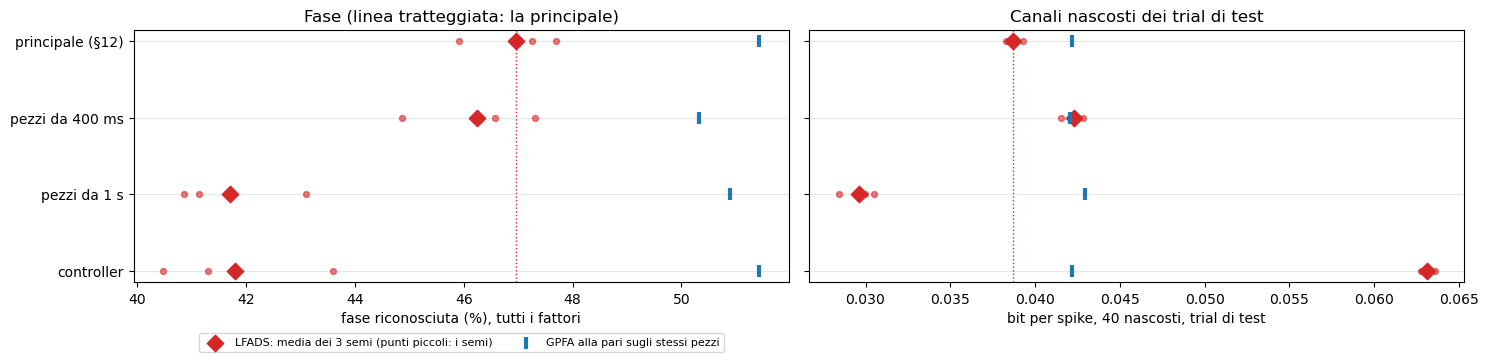

In [112]:
ROWS14B = list(GEOM14B)[::-1]                               # dall'alto in basso come nella tabella
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for a_, meas, xlab in ((ax[0], "tetto", "fase riconosciuta (%), tutti i fattori"), (ax[1], "nascosti", "bit per spike, 40 nascosti, trial di test")):
    for y, v in enumerate(ROWS14B):
        vals = np.array(M14B[v][meas])
        a_.scatter(vals, np.full(len(vals), y), color="C3", s=18, alpha=0.6, zorder=3)  # i 3 semi
        a_.scatter(vals.mean(), y, color="C3", s=70, marker="D", zorder=4, label="LFADS: media dei 3 semi (punti piccoli: i semi)" if y == 0 else None)
        a_.scatter(M14B[GP_SAME14B[v]][meas][0], y, color="C0", s=70, marker="|", linewidths=3, zorder=4,
                   label="GPFA alla pari sugli stessi pezzi" if y == 0 else None)
    a_.axvline(np.mean(P14B[meas]), color="C3", ls=":", lw=1)  # la principale, per confronto
    a_.set(xlabel=xlab, yticks=range(len(ROWS14B)), yticklabels=ROWS14B)
    a_.grid(axis="y", alpha=0.3)
ax[0].legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))  # sotto il grafico, per non coprire i punti
ax[0].set_title("Fase (linea tratteggiata: la principale)"); ax[1].set_title("Canali nascosti dei trial di test")
fig.tight_layout(); fig.savefig(FIGS / "04_lfads_variants_b.png", bbox_inches="tight"); plt.show()

**Lettura.**

- **Il controllo torna**: la principale dà gli stessi numeri del §14a.
- **Pezzi da 400 ms: in pratica come la principale.** Sulla fase −0.7 punti (in tutti e 3 i semi, da −1.1 a −0.4);
  sui nascosti +0.0036 (0.0423), alla pari con la GPFA sugli stessi pezzi (0.0420): 2 semi su 3 sopra, quindi la
  regola non è soddisfatta.
- **Pezzi da 1 s: peggio su tutte e due le misure**, −5.3 punti sulla fase e −0.0091 sui nascosti (0.0296): il
  generatore deve srotolare da solo un secondo intero, e non ci riesce. La GPFA invece non risente della lunghezza dei
  pezzi (dal 50.3 al 51.4% sulla fase, da 0.0420 a 0.0430 sui nascosti).
- **Il controller cambia le cose, in due direzioni opposte**:
  - sulla **fase** peggiora: −5.2 punti (41.8%), e 17.0% con i primi 3 fattori;
  - sui **canali nascosti** fa **0.0631** bit per spike (da 0.0628 a 0.0636 tra i semi): +0.0244 sulla principale,
    sopra la GPFA alla pari (0.0422) con tutti e 3 i semi, e sopra anche la GPFA con la regressione di Poisson
    (0.0474), il voto più alto finora. **Per la regola fissata prima di guardare, sui nascosti il verdetto del §12
    cambia.**
- **Il controller è acceso**: gli ingressi inferiti hanno un'ampiezza di 0.29 (0.27-0.31 tra i modelli) con
  un'incertezza a posteriori di 0.15, contro la deviazione 0.74 della priori. Il modello li usa tutti e 4 (ampiezze
  da 0.26 a 0.31) e sa bene quanto valgono.
- **Memorizza come la principale**: sui trial nuovi resta il 40% del voto dei trial visti (37-40% per tutte le
  varianti di LFADS, 66-67% per la GPFA).
- **In parole semplici**: senza controller il generatore deve indovinare dallo stato iniziale tutto quello che
  succede nei 600 ms del pezzo; con il controller può essere "spinto" bin per bin, seguendo quello che i canali
  visibili fanno istante per istante. Questo aiuta a prevedere i nascosti, ma rende i fattori meno utili per
  riconoscere la fase.
- **La figura**: per ogni variante i 3 semi di LFADS (punti piccoli) e la loro media (rombo), e la GPFA alla pari
  sugli stessi pezzi (trattino blu); la linea tratteggiata è la principale.
- **Che cosa non dice**: se il guadagno sui nascosti sia vero o un artefatto, e da dove venga. Lo controlliamo qui
  sotto.

#### Il controller supera la GPFA sui canali nascosti: tre controlli

Un guadagno così grande va controllato prima di crederci (regola di tutto il notebook: quando un numero è
sorprendentemente buono, si cerca prima l'errore). L'encoder degli ingressi legge solo i 120 visibili, come quello
dello stato iniziale: i nascosti non entrano mai nel modello quando calcola le previsioni. Tre controlli:

1. **I nascosti spostati nel tempo** (§13.4): gli stessi 15 allenamenti della forma 120 + 40, sui dati in cui ogni
   nascosto è spostato di un minuto o più. Se il guadagno viene dalla coordinazione tra i canali, sui trial nuovi il
   voto deve scendere sotto zero, come per gli altri modelli; se la catena (controller, ricucitura, voto) lo
   creasse da sola, resterebbe sopra zero.
2. **Da dove viene il guadagno**: il voto per fascia di frequenza dei canali (§12.4), e quanta parte della variazione
   delle frequenze previste sta tra 16 e 20 Hz, il ritmo dei conteggi che LFADS senza controller non riproduce
   (§11.3, §12.3).
3. **Lo smoothing + GLM con meno smoothing** (σ = 20 e 10 ms invece di 50): se il controller vince perché segue le
   fluttuazioni veloci comuni a visibili e nascosti, anche un riferimento che le conserva dovrebbe guadagnare.

15 allenamenti nuovi con il controller: circa 12 minuti.

In [113]:
def job14b_sh(k, sd):                                       # il controller, forma 120 + 40, sui dati con i nascosti spostati nel tempo (§13.4)
    return lf12_job(sd, train_trials(k), hp=dict(LF_HID_HP, **CO14), segs=SEGS_SH_HID, rate_cols=HID_COLS)

res14b_sh = dict(zip([(k, sd) for k in range(5) for sd in SEEDS14],
                     run_lfads_cached_co([job14b_sh(k, sd) for k in range(5) for sd in SEEDS14])))
full_sh_co = [[stitch_all(res14b_sh[(k, sd)]["rates"]) for sd in SEEDS14] for k in range(5)]  # [blocco][seme] -> nascosti spostati previsti
sn_sh_co = seen_new(full_sh_co, Y_SH)
b_sh_lf = [bits_per_spike(test_only([FULL_SH["LFADS (3 semi)"][k][i] for k in range(5)]), Y_SH) for i in range(len(SEEDS14))]
print(f"(1) Nascosti spostati, trial nuovi: controller {fmt4([bits_per_spike(test_only([full_sh_co[k][i] for k in range(5)]), Y_SH) for i in range(len(SEEDS14))])}, "
      f"senza controller (§13.4) {fmt4(b_sh_lf)}; trial visti: controller {fmt4(sn_sh_co[:, :, 0].mean(1))}, "
      f"senza controller {fmt4(SN_SH['LFADS (3 semi)'][:, :, 0].mean(1))}")

P_CO = [test_only([stitch_all(res14b[("controller", "120 + 40", k, sd)]["rates"]) for k in range(5)]) for sd in SEEDS14]  # sessione di soli trial di test
P_LF = [test_only([stitch_all(res14a[("principale (§12)", "120 + 40", k, sd)]["rates"]) for k in range(5)]) for sd in SEEDS14]

def share18_rates(P, L=50, step=25):                        # quota della variazione tra 16 e 20 Hz nelle frequenze previste (media sui canali), finestre da 1 s
    win = np.hanning(L)                                     # la stessa finestra del §11.3
    S = np.mean([np.abs(np.fft.rfft((P[a:a + L] - P[a:a + L].mean(0)) * win[:, None], axis=0)) ** 2 for a in range(0, len(P) - L, step)], axis=0)
    f_ = np.fft.rfftfreq(L, io.BIN_S)                       # da 0 a 25 Hz, ogni 1 Hz
    return float(np.mean(S[(f_ >= 16) & (f_ <= 20)].sum(0) / S[1:].sum(0)))

SMV = {sg: io.smooth_rates(s.spikes, sigma_ms=sg)[:, ACTIVE][:, HELD_IN] for sg in (20, 10)}  # i 120 visibili smussati con σ più piccola

def glm_sigma(sg, k):                                       # lo smoothing + GLM del §11a con un'altra σ, stimato sui 12 trial di training del blocco k
    fit_ = np.isin(trial, train_trials(k))
    F = StandardScaler().fit(SMV[sg][fit_]).transform(SMV[sg])
    return np.column_stack([PoissonRegressor(alpha=0.1, max_iter=500).fit(F[fit_], COUNTS[fit_, h]).predict(F) for h in HIDDEN])

P_GLM_S = {sg: test_only([glm_sigma(sg, k) for k in range(5)]) for sg in SMV}
CHK14B = {"LFADS con il controller (3 semi)": P_CO, "LFADS, principale (3 semi)": P_LF, "GPFA alla pari": [PRED_GP],
          "GPFA + regressione di Poisson": [PRED_GPGLM], "smoothing (σ = 50 ms) + GLM": [PRED_GLM],
          "smoothing (σ = 20 ms) + GLM": [P_GLM_S[20]], "smoothing (σ = 10 ms) + GLM": [P_GLM_S[10]]}
display(pd.DataFrame({name: {"tutti i 40": fmt4([bits_per_spike(p_, Y_HID) for p_ in P]),
                             **{BAND_LAB[b]: fmt4([bits_per_spike(p_[:, BAND_OF == b], Y_HID[:, BAND_OF == b]) for p_ in P]) for b in range(4)},
                             "variazione tra 16 e 20 Hz (%)": f"{np.mean([share18_rates(p_) for p_ in P]) * 100:.1f}"}
                      for name, P in CHK14B.items()}).T.rename_axis("(2, 3) bit per spike dei nascosti, trial di test, per fascia; quota della variazione delle previsioni a 16-20 Hz"))
print(f"Per confronto, nei conteggi veri dei 40 nascosti la quota tra 16 e 20 Hz è {share18_rates(Y_HID) * 100:.1f}% "
      f"(comprende il rumore di Poisson, che è uguale a tutte le frequenze)")

Allenamenti LFADS: 15 eseguiti ora, 0 riletti dal disco


(1) Nascosti spostati, trial nuovi: controller -0.0181 [-0.0186, -0.0177], senza controller (§13.4) -0.0179 [-0.0190, -0.0162]; trial visti: controller 0.0425 [0.0409, 0.0435], senza controller 0.0398 [0.0385, 0.0409]


,tutti i 40,fascia 1: 0.5-2.5 Hz,fascia 2: 3.5-7.8 Hz,fascia 3: 10.0-21.3 Hz,fascia 4: 22.6-45.3 Hz,variazione tra 16 e 20 Hz (%)
"(2, 3) bit per spike dei nascosti, trial di test, per fascia; quota della variazione delle previsioni a 16-20 Hz",,,,,,
LFADS con il controller (3 semi),"0.0631 [0.0628, 0.0636]","-0.0147 [-0.0221, -0.0099]","0.1011 [0.0995, 0.1035]","0.0948 [0.0943, 0.0955]","0.0443 [0.0437, 0.0452]",32.0
"LFADS, principale (3 semi)","0.0387 [0.0383, 0.0393]","-0.0093 [-0.0128, -0.0060]","0.0828 [0.0825, 0.0834]","0.0642 [0.0634, 0.0652]","0.0209 [0.0207, 0.0213]",0.1
GPFA alla pari,0.0422,0.0007,0.0441,0.0704,0.0299,0.1
GPFA + regressione di Poisson,0.0474,0.0153,0.0780,0.0752,0.0302,0.0
smoothing (σ = 50 ms) + GLM,0.0416,0.0158,0.0709,0.0670,0.0256,0.0
smoothing (σ = 20 ms) + GLM,0.0386,0.0146,0.0549,0.0622,0.0256,0.8
smoothing (σ = 10 ms) + GLM,0.0413,0.0146,0.0485,0.0654,0.0295,18.3


Per confronto, nei conteggi veri dei 40 nascosti la quota tra 16 e 20 Hz è 21.6% (comprende il rumore di Poisson, che è uguale a tutte le frequenze)


**Lettura.**

- **(1) Il guadagno viene dalla coordinazione vera tra i canali.** Con i nascosti spostati nel tempo il controller
  scende sotto zero sui trial nuovi (−0.0181), esattamente come LFADS senza controller (−0.0179, §13.4); sui trial
  visti arriva a 0.0425, la stessa memorizzazione di prima (0.0398). La catena controller → ricucitura → voto non
  crea voti positivi da sola.
- **(2) Il guadagno sta nei canali sopra i 3.5 Hz e passa per il ritmo a 18 Hz.** Il controller è il migliore in tre
  fasce su quattro (0.1011, 0.0948 e 0.0443 bit per spike nelle fasce 2, 3 e 4), ma va sotto zero nella più lenta
  (−0.0147), dove vincono la GPFA con la regressione e lo smoothing + GLM (circa 0.015). Le sue previsioni hanno il
  32.0% della variazione tra 16 e 20 Hz, contro lo 0.1% di LFADS senza controller e della GPFA: seguono il ritmo a
  18 Hz dei conteggi (§11.3) che gli altri modelli, tutti più lisci, cancellano.
- **(3) Seguire le fluttuazioni veloci non basta.** Lo smoothing + GLM con meno smoothing non guadagna (0.0386 con
  σ = 20 ms, 0.0413 con σ = 10 ms, contro 0.0416 con σ = 50 ms), anche se con σ = 10 ms anche le sue previsioni
  hanno il 18.3% della variazione tra 16 e 20 Hz. Il controller riesce a usare il ritmo perché lo stima dall'insieme
  dei canali, nei pochi fattori del modello; una regressione canale per canale su 120 ingressi rumorosi no.
- **Che cosa non dice**: perché il controller peggiori la fase (un'ipotesi non verificata: gli ingressi assorbono
  variazioni che i fattori senza controller usavano per distinguere le fasi); se con più dati (§14d) il quadro del
  controller cambi; e lo spostamento dei nascosti è uno solo (seme 0).

### Riepilogo del §14b

| variante | fase, tetto: differenza dalla principale | nascosti: differenza | sopra la GPFA sugli stessi pezzi? |
|---|---|---|---|
| principale (§12): pezzi da 600 ms, senza controller | 47.0% | 0.0387 | no |
| pezzi da 400 ms | −0.7 | +0.0036 | sui nascosti 2 semi su 3 (alla pari) |
| pezzi da 1 s | −5.3 | −0.0091 | no |
| controller | −5.2 | **+0.0244** | **sui nascosti sì, 3 semi su 3** (0.0631 contro 0.0422; sopra anche la GPFA con la regressione, 0.0474); sulla fase no |

**In sintesi**: la lunghezza dei pezzi non cambia il verdetto (600 o 400 ms vanno bene, 1 s è peggio). Il controller
sì, ma solo sulla misura generativa: con gli ingressi inferiti LFADS diventa il miglior modello dei canali nascosti,
perché segue il ritmo a 18 Hz comune alla popolazione. Come descrizione delle fasi del task, invece, peggiora.